#load


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# read data

In [1]:
import os
import scanpy as sc
import numpy as np
import pandas as pd
import scanpy.external as sce
from sklearn.decomposition import TruncatedSVD
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import gseapy as gp
from scipy.sparse import csr_matrix
import seaborn as sns
import anndata as ad
import pooch
# import sctour as sct
from gseapy.plot import barplot, dotplot
import harmonypy as hm
# import squidpy as sq


In [2]:
from cell2location.plt import plot_spatial
from cell2location.utils import select_slide

In [3]:
import squidpy as sq

In [4]:
from pathlib import Path


In [5]:
os.chdir('/content/drive/MyDrive/pharynx')

#def

In [7]:
dot_map = LinearSegmentedColormap.from_list(
    "dot_map",
    [ '#255eaa','#efefee',"#e34051"]
)

In [47]:
from matplotlib.colors import LinearSegmentedColormap

cmap = LinearSegmentedColormap.from_list(
    "niche_cmap",
    [
        "#1E2B60",  # 深蓝
        "#28457B",
        "#2C6E88",
        "#1B9593",  # 青绿
        "#68B186",
        "#A2CA6E",
        "#D2DF52",
        "#F0E636",  # 亮黄
        "#DEAC51",
        "#C5705E",
        "#A62A65",  # 紫红
    ],
    N=256
)

In [8]:
from scipy import sparse
#辅助注释的函数，可以deepseek一下其主要功能理解以下
def anno_agent(
    adata,
    cell_type,
    cluster_key="leiden",
    min_pct_expr=0.25,
    min_fc=1,
    max_fdr=0.05,
    top_n=10,
):
    """
    Annotate cell types using top-ranked marker genes with filtering thresholds.
    """
    # 1. 取表达矩阵和基因名
    X_use = adata.raw.X if adata.raw is not None else adata.X
    var_names = adata.raw.var_names if adata.raw is not None else adata.var_names

    clusters = sorted(
        adata.obs[cluster_key].unique(),
        key=lambda x: float(x) if str(x).replace(".", "", 1).isdigit() else str(x),
    )
    output_lines = []

    for cluster in clusters:
        # 2. 差异表达结果
        df = sc.get.rank_genes_groups_df(adata, group=cluster).set_index("names")

        # 3. 计算表达比例
        mask = (adata.obs[cluster_key] == cluster).to_numpy()  # ← 关键修复
        if sparse.issparse(X_use):
            frac = (X_use[mask] > 0).mean(axis=0).A1  # .A1 转一维
        else:
            frac = (X_use[mask] > 0).mean(axis=0)

        expr_frac_series = pd.Series(frac, index=var_names)

        # 4. 对齐并拼接
        common = df.index.intersection(expr_frac_series.index)
        df = df.loc[common]
        df["pct_expr"] = expr_frac_series.loc[common]

        # 5. 过滤阈值
        df = df[
            (df["pct_expr"] >= min_pct_expr)
            & (df["logfoldchanges"] >= np.log2(min_fc))
            & (df["pvals_adj"] <= max_fdr)
        ]

        # 6. 去除线粒体/核糖体基因
        df = df[~df.index.str.startswith(("MT-", "RPS", "RPL"))]

        # 7. 收集 top-n marker
        top_genes = df.head(top_n).index.tolist()
        output_lines.append(f"{cluster}: {','.join(top_genes)}")

    # 8. 生成提示文本
    return (
        f"Identify cell types of {cell_type} using the following markers. "
        "Identify one cell type for each row. Attention - Determine the Subtype, Characteristic Genes, Phenotype, and Predict Function for Each Cell Type."
        " Present the Results in a Tabular Format：\n"
        + "\n".join(output_lines)
    )

# sc

In [ ]:
from pathlib import Path
import pandas as pd
import anndata as ad
from scipy.io import mmread
from scipy.sparse import csr_matrix

folder = Path("/content/drive/MyDrive/pharynx/1.rawdata/")

# 转置为：细胞 × 基因
X = csr_matrix(mmread(folder / "matrix.mtx").T)

genes = pd.read_csv(
    folder / "genes.csv", dtype=str, keep_default_na=False
)["gene_id"]

cells = pd.read_csv(
    folder / "cells.csv", dtype=str, keep_default_na=False
)["cell_id"]

meta = pd.read_csv(folder / "metadata.csv")

assert X.shape == (len(cells), len(genes))
assert len(meta) == len(cells)
assert cells.is_unique, "细胞名存在重复"

meta.index = pd.Index(cells, name=None)

adata_sc = ad.AnnData(
    X=X,
    obs=meta,
    var=pd.DataFrame(index=pd.Index(genes, name=None))
)

print(adata_sc)
# print(adata_sc.obs.head())

for df in (adata_sc.obs, adata_sc.var):
    if "_index" in df.columns:
        new_name = "original_index"
        while new_name in df.columns:
            new_name += "_"
        df.rename(columns={"_index": new_name}, inplace=True)

adata_sc.write_h5ad(folder / "Final_rebuilt.h5ad")

AnnData object with n_obs × n_vars = 43173 × 17444
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', '_index', 'sample', 'sampleid', 'rawbc', 'species', 'group', 'batchid', 'percent.mito', 'percent.HB', 'sampleid_col', 'group_col', 'log10GenesPerUMI', 'is_metric_outlier', 'is_valid', 'is_doublets', 'clusters', 'RNA_snn_res.0.4', 'seurat_clusters', 'RNA.umap.res.0.4', 'raw_main_celltype', 'hpca.main.celltype', 'celltype', 'new_celltype', 'dataset_source', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ig', 'pct_counts_ig', 'n_genes', 'leiden_0.1', 'leiden_0.2', 'leiden_0.3', 'leiden_0.4', 'leiden_0.5', 'leiden_0.6', 'leiden_0.7', 'leiden_0.8', 'leiden_0.9', 'leiden_1.0', 'leiden_1.1', 'leiden_1.2', 'leiden_1.3', 'leiden_1.4', 'leiden_1.5', 'leiden_1.6', 'leiden_1.7', 'leiden_1.8', 'leiden_1.9', 'leiden_2.0', 'subtype', 'Sample', 'leiden_0.30', 'leiden_0.40', 'leiden_0.50', 'leiden_0.60', 'leiden_0.70', 'leiden_0.80', 'leiden_0.90', 'leiden_1.00

In [ ]:
adata_sc = sc.read_h5ad("./1.rawdata/adata_final_umap_counts.h5ad")

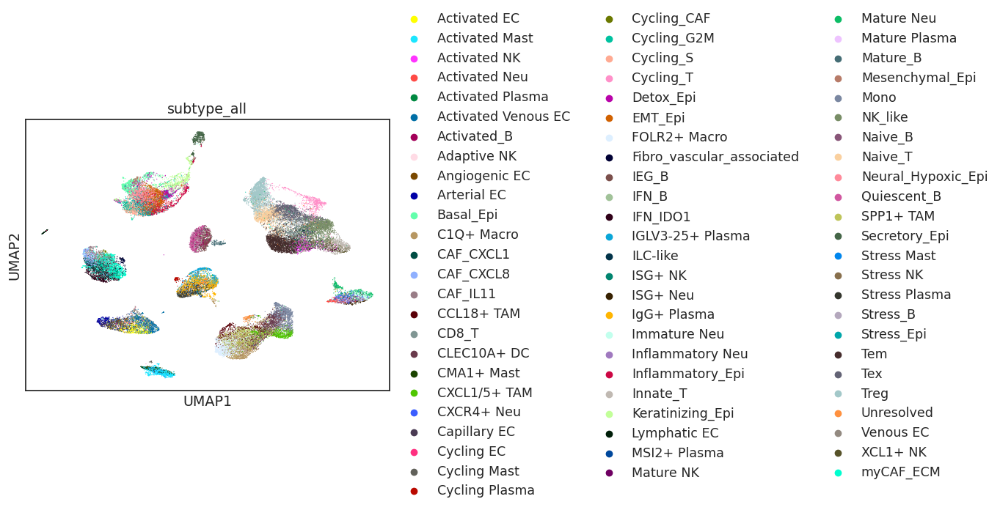

In [ ]:
sc.pl.umap(adata_sc,color="subtype_all")

In [ ]:
adata_sc

AnnData object with n_obs × n_vars = 43098 × 17444
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'original_index', 'sample', 'sampleid', 'rawbc', 'species', 'group', 'batchid', 'percent.mito', 'percent.HB', 'sampleid_col', 'group_col', 'log10GenesPerUMI', 'is_metric_outlier', 'is_valid', 'is_doublets', 'clusters', 'RNA_snn_res.0.4', 'seurat_clusters', 'RNA.umap.res.0.4', 'raw_main_celltype', 'hpca.main.celltype', 'celltype', 'new_celltype', 'dataset_source', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ig', 'pct_counts_ig', 'n_genes', 'leiden_0.1', 'leiden_0.2', 'leiden_0.3', 'leiden_0.4', 'leiden_0.5', 'leiden_0.6', 'leiden_0.7', 'leiden_0.8', 'leiden_0.9', 'leiden_1.0', 'leiden_1.1', 'leiden_1.2', 'leiden_1.3', 'leiden_1.4', 'leiden_1.5', 'leiden_1.6', 'leiden_1.7', 'leiden_1.8', 'leiden_1.9', 'leiden_2.0', 'subtype', 'Sample', 'leiden_0.30', 'leiden_0.40', 'leiden_0.50', 'leiden_0.60', 'leiden_0.70', 'leiden_0.80', 'leiden_0.90', 'lei

In [ ]:
adata_sc


AnnData object with n_obs × n_vars = 42804 × 17444
    obs: 'sample', 'sampleid', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'rawbc', 'species', 'group', 'batchid', 'percent.mito', 'percent.HB', 'sampleid_col', 'group_col', 'log10GenesPerUMI', 'is_metric_outlier', 'is_valid', 'is_doublets', 'clusters', 'RNA_snn_res.0.4', 'seurat_clusters', 'RNA.umap.res.0.4', 'raw_main_celltype', 'hpca.main.celltype', 'celltype', 'new_celltype', 'dataset_source', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ig', 'pct_counts_ig', 'n_genes', 'leiden_0.1', 'leiden_0.2', 'leiden_0.3', 'leiden_0.4', 'leiden_0.5', 'leiden_0.6', 'leiden_0.7', 'leiden_0.8', 'leiden_0.9', 'leiden_1.0', 'leiden_1.1', 'leiden_1.2', 'leiden_1.3', 'leiden_1.4', 'leiden_1.5', 'leiden_1.6', 'leiden_1.7', 'leiden_1.8', 'leiden_1.9', 'leiden_2.0', 'subtype', 'Sample', 'leiden_0.30', 'leiden_0.40', 'leiden_0.50', 'leiden_0.60', 'leiden_0.70', 'leiden_0.80', 'leiden_0.90', 'leiden_1.00', 'leiden

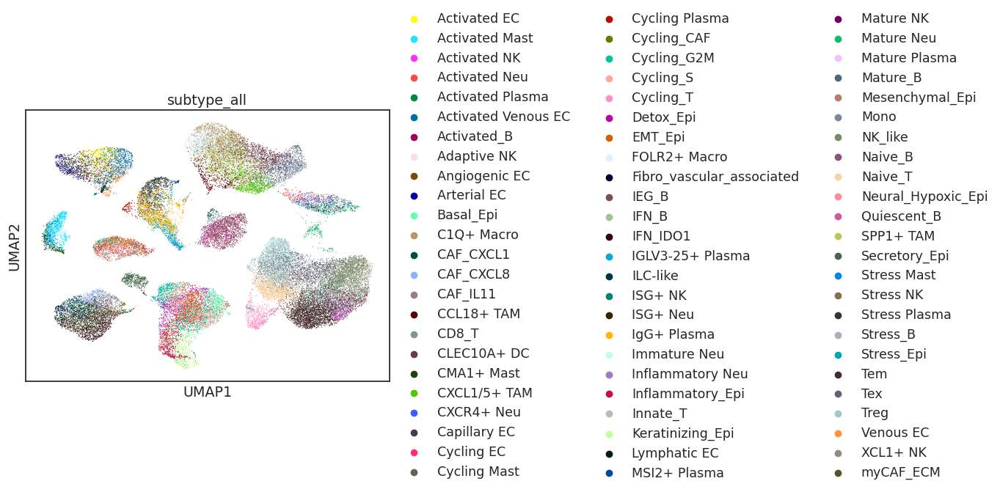

In [ ]:
sc.pl.umap(adata_sc,color="subtype_all")

AnnData object with n_obs × n_vars = 42804 × 17444
    obs: 'sample', 'sampleid', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'rawbc', 'species', 'group', 'batchid', 'percent.mito', 'percent.HB', 'sampleid_col', 'group_col', 'log10GenesPerUMI', 'is_metric_outlier', 'is_valid', 'is_doublets', 'clusters', 'RNA_snn_res.0.4', 'seurat_clusters', 'RNA.umap.res.0.4', 'raw_main_celltype', 'hpca.main.celltype', 'celltype', 'new_celltype', 'dataset_source', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ig', 'pct_counts_ig', 'n_genes', 'leiden_0.1', 'leiden_0.2', 'leiden_0.3', 'leiden_0.4', 'leiden_0.5', 'leiden_0.6', 'leiden_0.7', 'leiden_0.8', 'leiden_0.9', 'leiden_1.0', 'leiden_1.1', 'leiden_1.2', 'leiden_1.3', 'leiden_1.4', 'leiden_1.5', 'leiden_1.6', 'leiden_1.7', 'leiden_1.8', 'leiden_1.9', 'leiden_2.0', 'subtype', 'Sample', 'leiden_0.30', 'leiden_0.40', 'leiden_0.50', 'leiden_0.60', 'leiden_0.70', 'leiden_0.80', 'leiden_0.90', 'leiden_1.00', 'leiden

In [ ]:
adata_sc

AnnData object with n_obs × n_vars = 43173 × 2000
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'original_index', 'sample', 'sampleid', 'rawbc', 'species', 'group', 'batchid', 'percent.mito', 'percent.HB', 'sampleid_col', 'group_col', 'log10GenesPerUMI', 'is_metric_outlier', 'is_valid', 'is_doublets', 'clusters', 'RNA_snn_res.0.4', 'seurat_clusters', 'RNA.umap.res.0.4', 'raw_main_celltype', 'hpca.main.celltype', 'celltype', 'new_celltype', 'dataset_source', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ig', 'pct_counts_ig', 'n_genes', 'leiden_0.1', 'leiden_0.2', 'leiden_0.3', 'leiden_0.4', 'leiden_0.5', 'leiden_0.6', 'leiden_0.7', 'leiden_0.8', 'leiden_0.9', 'leiden_1.0', 'leiden_1.1', 'leiden_1.2', 'leiden_1.3', 'leiden_1.4', 'leiden_1.5', 'leiden_1.6', 'leiden_1.7', 'leiden_1.8', 'leiden_1.9', 'leiden_2.0', 'subtype', 'Sample', 'leiden_0.30', 'leiden_0.40', 'leiden_0.50', 'leiden_0.60', 'leiden_0.70', 'leiden_0.80', 'leiden_0.90', 'leid

In [ ]:
adata_sc.raw = adata_sc.copy()

sc.pp.normalize_total(adata_sc,target_sum=1e4)
sc.pp.log1p(adata_sc)
sc.pp.highly_variable_genes(
    adata_sc,
    n_top_genes=2000,
    batch_key="orig.ident",
    flavor="seurat_v3"
)
adata_sc = adata_sc[:, adata_sc.var.highly_variable]
adata_sc

/tmp/ipykernel_193524/3449404787.py:5: UserWarning: `flavor='seurat_v3'` expects raw count data, but non-integers were found.
  sc.pp.highly_variable_genes(


View of AnnData object with n_obs × n_vars = 43173 × 2000
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'original_index', 'sample', 'sampleid', 'rawbc', 'species', 'group', 'batchid', 'percent.mito', 'percent.HB', 'sampleid_col', 'group_col', 'log10GenesPerUMI', 'is_metric_outlier', 'is_valid', 'is_doublets', 'clusters', 'RNA_snn_res.0.4', 'seurat_clusters', 'RNA.umap.res.0.4', 'raw_main_celltype', 'hpca.main.celltype', 'celltype', 'new_celltype', 'dataset_source', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ig', 'pct_counts_ig', 'n_genes', 'leiden_0.1', 'leiden_0.2', 'leiden_0.3', 'leiden_0.4', 'leiden_0.5', 'leiden_0.6', 'leiden_0.7', 'leiden_0.8', 'leiden_0.9', 'leiden_1.0', 'leiden_1.1', 'leiden_1.2', 'leiden_1.3', 'leiden_1.4', 'leiden_1.5', 'leiden_1.6', 'leiden_1.7', 'leiden_1.8', 'leiden_1.9', 'leiden_2.0', 'subtype', 'Sample', 'leiden_0.30', 'leiden_0.40', 'leiden_0.50', 'leiden_0.60', 'leiden_0.70', 'leiden_0.80', 'leiden_0.90

In [ ]:
sc.pp.scale(adata_sc)
sc.tl.pca(adata_sc, svd_solver="arpack")


/usr/lib/python3.13/functools.py:934: UserWarning: Received a view of an AnnData. Making a copy.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


In [ ]:
# Get PCs from the AnnData object
pcs = adata_sc.obsm['X_pca']

# Run Harmony on the PCA embedding
harmony_out = hm.run_harmony(pcs,adata_sc.obs, ["orig.ident"],max_iter_harmony= 30)

# Store corrected PCs back in the AnnData object
adata_sc.obsm['X_pca_harmony'] = harmony_out.Z_corr

2026-09-15 15:06:36,538 - harmonypy - INFO - Running Harmony
INFO:harmonypy:Running Harmony
2026-09-15 15:06:36,540 - harmonypy - INFO -   Parameters:
INFO:harmonypy:  Parameters:
2026-09-15 15:06:36,541 - harmonypy - INFO -     max_iter_harmony: 30
INFO:harmonypy:    max_iter_harmony: 30
2026-09-15 15:06:36,543 - harmonypy - INFO -     max_iter_kmeans: 4
INFO:harmonypy:    max_iter_kmeans: 4
2026-09-15 15:06:36,544 - harmonypy - INFO -     epsilon_cluster: 0.001
INFO:harmonypy:    epsilon_cluster: 0.001
2026-09-15 15:06:36,546 - harmonypy - INFO -     epsilon_harmony: 0.01
INFO:harmonypy:    epsilon_harmony: 0.01
2026-09-15 15:06:36,548 - harmonypy - INFO -     nclust: 100
INFO:harmonypy:    nclust: 100
2026-09-15 15:06:36,550 - harmonypy - INFO -     block_size: 0.05
INFO:harmonypy:    block_size: 0.05
2026-09-15 15:06:36,551 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
INFO:harmonypy:    lamb: dynamic (alpha=0.2)
2026-09-15 15:06:36,552 - harmonypy - INFO -     theta: [2. 2. 2

In [ ]:
sc.pp.neighbors(adata_sc,n_pcs=30,use_rep="X_pca_harmony")
sc.tl.umap(adata_sc,min_dist=0.3)

In [ ]:
adata_sc

AnnData object with n_obs × n_vars = 43173 × 17444
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'original_index', 'sample', 'sampleid', 'rawbc', 'species', 'group', 'batchid', 'percent.mito', 'percent.HB', 'sampleid_col', 'group_col', 'log10GenesPerUMI', 'is_metric_outlier', 'is_valid', 'is_doublets', 'clusters', 'RNA_snn_res.0.4', 'seurat_clusters', 'RNA.umap.res.0.4', 'raw_main_celltype', 'hpca.main.celltype', 'celltype', 'new_celltype', 'dataset_source', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ig', 'pct_counts_ig', 'n_genes', 'leiden_0.1', 'leiden_0.2', 'leiden_0.3', 'leiden_0.4', 'leiden_0.5', 'leiden_0.6', 'leiden_0.7', 'leiden_0.8', 'leiden_0.9', 'leiden_1.0', 'leiden_1.1', 'leiden_1.2', 'leiden_1.3', 'leiden_1.4', 'leiden_1.5', 'leiden_1.6', 'leiden_1.7', 'leiden_1.8', 'leiden_1.9', 'leiden_2.0', 'subtype', 'Sample', 'leiden_0.30', 'leiden_0.40', 'leiden_0.50', 'leiden_0.60', 'leiden_0.70', 'leiden_0.80', 'leiden_0.90', 'lei

In [ ]:
adata_sc = adata_sc.raw.to_adata()
# t_adata.X = t_adata.X.astype(np.int64) ## make sure the matrix is int64
adata_sc.raw = adata_sc.copy()
adata_sc.layers["counts"] = adata_sc.X.copy()

In [ ]:
sc.pp.normalize_total(adata_sc,target_sum=1e4)
sc.pp.log1p(adata_sc)
adata_sc.raw = adata_sc.copy()
adata_sc.X = adata_sc.layers["counts"].copy()


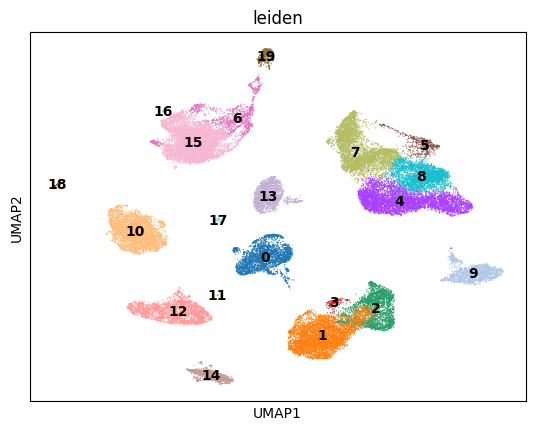

In [ ]:
sc.tl.leiden(
    adata_sc,
    resolution=0.50,
    random_state=0,
    flavor="igraph",
    n_iterations=2,
    directed=False,)
sc.pl.umap(
    adata_sc,
    color=["leiden"],
    legend_loc='on data'

)

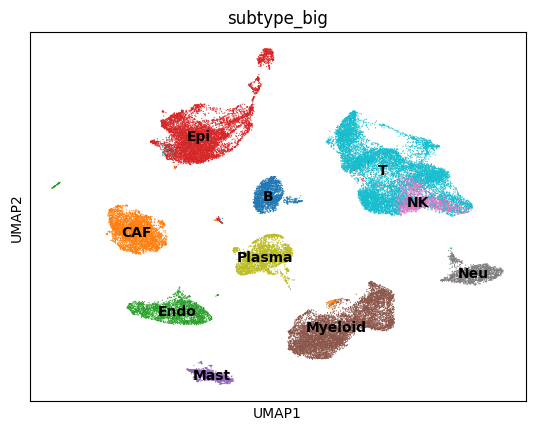

In [ ]:
sc.pl.umap(
    adata_sc,
    color=["subtype_big"],
    legend_loc='on data'

)

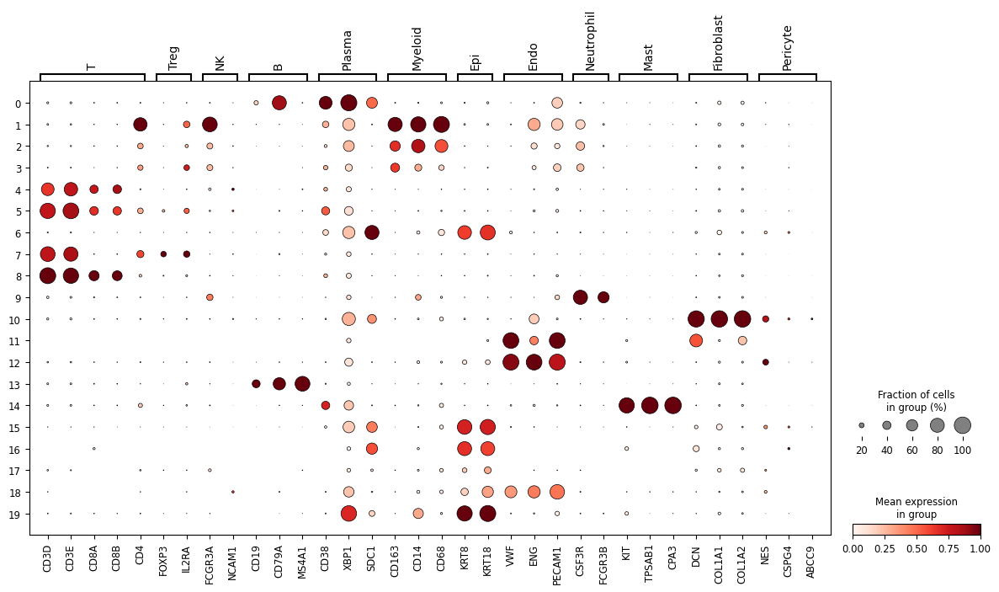

In [ ]:
marker_genes_dict = {
    "T":["CD3D","CD3E","CD8A","CD8B","CD4"],
    "Treg":["FOXP3","IL2RA"],
    "NK":["FCGR3A","NCAM1",],
    "B":["CD19","CD79A","MS4A1"],
    "Plasma":['CD38',"XBP1","SDC1"],
    "Myeloid":["CD163","CD14","CD68"],
    "Epi":["KRT8","KRT18"],
    "Endo":["VWF","ENG","PECAM1"],
    "Neutrophil":["CSF3R","FCGR3B"],
    "Mast":["KIT","TPSAB1","CPA3"],
    "Fibroblast":["DCN","COL1A1","COL1A2"],
    "Pericyte":["NES","CSPG4","ABCC9"]

}



sc.pl.dotplot(adata_sc, marker_genes_dict, 'leiden', dendrogram=False, standard_scale = "var" ,edgecolor='black',  # 点的边框颜色
    linewidth=0.5,)


In [ ]:
# 示例：每种细胞类型对应多个 Leiden 群
celltype_clusters = {
    "T/NK": ["4",'5','7','8'],
    "B": ["13"],
    "Plasma": ["0"],
    "Myeloid": ["2", "1",'3'],
    "CAF": ["10",],
    "Endo": ["11",'12','18'],
    "Neutrophil":["9"],
    "Mast":["14"],



    "Epi": ["6","15",'16',"19"
            ],
}

clusters = [str(c) for ids in celltype_clusters.values() for c in ids]


# 添加注释，未指定的群标记为 Unknown
leiden = adata_sc.obs["leiden"].astype(str)
adata_sc.obs["celltype"] = "Unknown"

for celltype, cluster_ids in celltype_clusters.items():
    mask = leiden.isin([str(c) for c in cluster_ids])
    adata_sc.obs.loc[mask, "celltype"] = celltype

adata_sc.obs["celltype"] = adata_sc.obs["celltype"].astype("category")

# 查看各细胞类型数量
print(adata_sc.obs["celltype"].value_counts())

# 查看尚未注释的群
print("未注释的群：",
      leiden[adata_sc.obs["celltype"] == "Unknown"].unique().tolist())

celltype
T/NK          13162
Epi            7953
Myeloid        7748
CAF            3816
Plasma         2955
Endo           2610
B              2032
Neutrophil     1683
Mast           1139
Unknown          75
Name: count, dtype: int64
未注释的群： ['17']


In [ ]:
adata_sc = adata_sc[adata_sc.obs["celltype"] != "Unknown"].copy()

In [ ]:
adata_sc.write_h5ad("./1.rawdata/Final_rebuilt.h5ad")

In [ ]:
adata_sc = sc.read_h5ad("./1.rawdata/Final_rebuilt.h5ad")

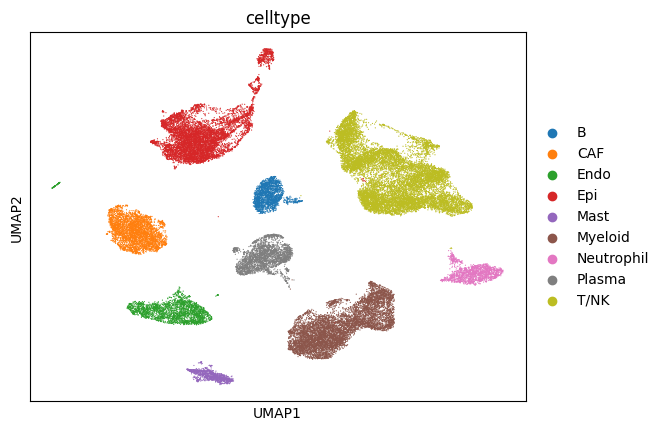

In [ ]:
sc.pl.umap(adata_sc,color="celltype")

#ST

In [ ]:
# !unzip -q "/content/drive/MyDrive/pharynx/1.rawdata/HNSCC14/HNSCC14-20260912T051932Z-1-001.zip" \
# -d "/content/drive/MyDrive/pharynx/1.rawdata/HNSCC14/"

# !unzip -q "/content/drive/MyDrive/pharynx/1.rawdata/HNSCC59/HNSCC59-20260912T051932Z-1-001.zip" \
# -d "/content/drive/MyDrive/pharynx/1.rawdata/HNSCC59/"

In [ ]:
adata_1 = sc.read_visium(
    path="/content/drive/MyDrive/pharynx/1.rawdata/HNSCC14/",
    count_file="filtered_feature_bc_matrix.h5",  # 或者不写默认也行
    load_images=True
)
print(adata_1)

/tmp/ipykernel_11575/2358186901.py:1: FutureWarning: The function read_visium is deprecated and will be removed in the future. Use :func:`squidpy.read.visium` instead.
  adata_1 = sc.read_visium(
/usr/local/lib/python3.13/dist-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


AnnData object with n_obs × n_vars = 2222 × 17943
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'
    layers: None (.X)


In [ ]:
adata_2 = sc.read_visium(
    path="/content/drive/MyDrive/pharynx/1.rawdata/HNSCC59/",
    count_file="filtered_feature_bc_matrix.h5",  # 或者不写默认也行
    load_images=True
)
print(adata_2)

/tmp/ipykernel_11575/918685147.py:1: FutureWarning: The function read_visium is deprecated and will be removed in the future. Use :func:`squidpy.read.visium` instead.
  adata_2 = sc.read_visium(
/usr/local/lib/python3.13/dist-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


AnnData object with n_obs × n_vars = 2427 × 17943
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'
    layers: None (.X)


In [ ]:
adata_1.obs["sample"] = "HNSCC14"
adata_2.obs["sample"] = "HNSCC59"

In [ ]:
print(adata_1)
print(adata_2)

AnnData object with n_obs × n_vars = 2222 × 17943
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'
    layers: None (.X)
AnnData object with n_obs × n_vars = 2427 × 17943
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'
    layers: None (.X)


In [ ]:
adata_1.obs_names = [
    "HNSCC14_" + x
    for x in adata_1.obs_names
]

adata_2.obs_names = [
    "HNSCC59_" + x
    for x in adata_2.obs_names
]

In [ ]:
adata_1.var_names_make_unique()
adata_2.var_names_make_unique()

In [ ]:
adata_1.uns["spatial"] = {
    "HNSCC14": adata_1.uns["spatial"][
        list(adata_1.uns["spatial"].keys())[0]
    ]
}
adata_2.uns["spatial"] = {
    "HNSCC59": adata_2.uns["spatial"][
        list(adata_2.uns["spatial"].keys())[0]
    ]
}

spatial_1 = adata_1.uns["spatial"]
spatial_2 = adata_2.uns["spatial"]

In [ ]:
adata

AnnData object with n_obs × n_vars = 4649 × 17943
    obs: 'in_tissue', 'array_row', 'array_col', 'sample'
    var: 'gene_ids', 'feature_types', 'genome'
    obsm: 'spatial'
    layers: None (.X)

In [ ]:
import scanpy as sc

# 改成你的实际样本名
adatas = {
    "HNSCC14": adata_1.copy(),
    "HNSCC59": adata_2.copy()
}

# 1. 给每张切片的空间信息设置独立名称
for sample_name, adata in adatas.items():

    # 检查坐标和图像信息
    assert "spatial" in adata.obsm, f"{sample_name} 缺少空间坐标"
    assert "spatial" in adata.uns, f"{sample_name} 缺少空间图像信息"
    assert len(adata.uns["spatial"]) == 1, (
        f"{sample_name} 包含多张切片，需分别处理"
    )

    old_key = next(iter(adata.uns["spatial"]))

    # 直接重建字典，避免同名赋值后误删
    adata.uns["spatial"] = {
        sample_name: adata.uns["spatial"][old_key]
    }

    adata.var_names_make_unique()

# 2. 合并
import anndata as ad

adata = ad.concat(
    [adata_1, adata_2],
    join="inner",
    merge="same",
    label="sample",
    keys=["HNSCC14", "HNSCC59"]
)

adata.obs["sample"] = adata.obs["sample"].astype("category")

print(adata)
adata.obs_names_make_unique()

# 3. 检查空间信息是否保留
print(adata)
print(adata.obs["sample"].value_counts())
# print("图像所属样本：", list(adata.uns["spatial"].keys()))
print("空间坐标维度：", adata.obsm["spatial"].shape)

In [ ]:
adata.uns["spatial"] = {
    **adata_1.uns["spatial"],
    **adata_2.uns["spatial"]
}

In [ ]:
print(adata)

AnnData object with n_obs × n_vars = 4640 × 17943
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'log1p_total_counts_mt'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial', 'log1p', 'hvg', 'pca', 'neighbors', 'umap'
    obsm: 'spatial', 'X_pca', 'X_pca_harmony', 'X_umap'
    obsp: 'distances', 'connectivities'
    layers: None (.X), 'counts'


In [ ]:
adata.write("./visum//st.h5ad")

In [ ]:
adata.layers["counts"] = adata.X.copy()

In [ ]:
adata.raw = adata.copy()

In [ ]:
# annotate the group of mitochondrial genes as "mt"
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)

In [ ]:
adata

AnnData object with n_obs × n_vars = 4649 × 17943
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'spatial'
    obsm: 'spatial'
    layers: None (.X), 'counts'

In [ ]:
  # 仅保留组织区域  ── 10x/scanpy 推荐

import numpy as np
import pandas as pd
import scanpy as sc

# 1) 计算QC指标（线粒体等）
adata.var['mt'] = adata.var_names.str.upper().str.startswith('MT-')
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], inplace=True)

# 2) MAD函数（更稳健，避免极端值）
def mad(x):
    med = np.median(x)
    return np.median(np.abs(x - med)) or 1e-9  # 防止全零

k = 4  # 可在3~5间微调；低深度可偏宽松些

# 3) 可选：按样本分组做阈值（推荐）
group_key = 'sample'  # 改成你的样本/切片列名；若无就设为 None
groups = [('', adata)] if group_key is None else adata.obs.groupby(group_key, observed=True)

keep = pd.Series(False, index=adata.obs_names)
for name, sub_idx in ([(g, idx.index) for g, idx in groups] if group_key else [('', adata.obs_names)]):
    obs = adata.obs.loc[sub_idx]

    # 仅示例三项：基因数/总UMI 用下界；线粒体百分比用上界
    ng = obs['n_genes_by_counts'];  tc = obs['total_counts'];  mt = obs['pct_counts_mt']

    ng_low = np.median(ng) - k*mad(ng)
    tc_low = np.median(tc) - k*mad(tc)
    mt_high = np.median(mt) + k*mad(mt)

    keep.loc[sub_idx] = (ng >= ng_low) & (tc >= tc_low) & (mt <= mt_high)

# 4) 过滤
adata = adata[keep].copy()
print(f'Kept {adata.n_obs}/{adata.n_obs} spots/cells')


Kept 4640/4640 spots/cells


In [ ]:
sc.pp.filter_genes(adata, min_cells=3)


In [ ]:
sc.pp.normalize_total(
    adata,
    target_sum=1e4
)

sc.pp.log1p(adata)

sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    flavor="seurat_v3",
    layer = "counts",batch_key="sample"
)

# adata = adata[:, adata.var.highly_variable].copy()

In [ ]:
sc.pp.regress_out(adata, ['total_counts',"pct_counts_in_top_50_genes"])

sc.pp.scale(adata)
sc.tl.pca(adata, svd_solver="arpack")


In [ ]:
# Get PCs from the AnnData object
pcs = adata.obsm['X_pca']

# Run Harmony on the PCA embedding
harmony_out = hm.run_harmony(pcs,adata.obs, ["sample"],max_iter_harmony= 30)

# Store corrected PCs back in the AnnData object
adata.obsm['X_pca_harmony'] = harmony_out.Z_corr

2026-09-16 07:32:13,412 - harmonypy - INFO - Running Harmony
INFO:harmonypy:Running Harmony
2026-09-16 07:32:13,413 - harmonypy - INFO -   Parameters:
INFO:harmonypy:  Parameters:
2026-09-16 07:32:13,414 - harmonypy - INFO -     max_iter_harmony: 30
INFO:harmonypy:    max_iter_harmony: 30
2026-09-16 07:32:13,415 - harmonypy - INFO -     max_iter_kmeans: 4
INFO:harmonypy:    max_iter_kmeans: 4
2026-09-16 07:32:13,416 - harmonypy - INFO -     epsilon_cluster: 0.001
INFO:harmonypy:    epsilon_cluster: 0.001
2026-09-16 07:32:13,418 - harmonypy - INFO -     epsilon_harmony: 0.01
INFO:harmonypy:    epsilon_harmony: 0.01
2026-09-16 07:32:13,419 - harmonypy - INFO -     nclust: 100
INFO:harmonypy:    nclust: 100
2026-09-16 07:32:13,420 - harmonypy - INFO -     block_size: 0.05
INFO:harmonypy:    block_size: 0.05
2026-09-16 07:32:13,421 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
INFO:harmonypy:    lamb: dynamic (alpha=0.2)
2026-09-16 07:32:13,422 - harmonypy - INFO -     theta: [2. 2.]


In [ ]:
sc.pp.neighbors(adata,n_pcs=30,use_rep="X_pca_harmony")
sc.tl.umap(adata,min_dist=0.3)

In [ ]:
adata = adata.raw.to_adata()
# t_adata.X = t_adata.X.astype(np.int64) ## make sure the matrix is int64
adata.raw = adata.copy()
adata.layers["counts"] = adata.X.copy()

In [ ]:
adata

AnnData object with n_obs × n_vars = 4640 × 17943
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'log1p_total_counts_mt'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial', 'log1p', 'hvg', 'pca', 'neighbors', 'umap'
    obsm: 'spatial', 'X_pca', 'X_pca_harmony', 'X_umap'
    obsp: 'distances', 'connectivities'
    layers: None (.X), 'counts'

In [ ]:
sc.pp.normalize_total(adata,target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata.copy()
adata.X = adata.layers["counts"].copy()


In [ ]:
adata_1.write("./visum//HNSCC14.h5ad")
adata_2.write("./visum//HNSCC59.h5ad")

In [ ]:
adata.write("./visum/st.h5ad")

In [ ]:
adata

AnnData object with n_obs × n_vars = 4649 × 17943
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial', 'log1p', 'hvg', 'pca', 'neighbors', 'umap'
    obsm: 'spatial', 'X_pca', 'X_pca_harmony', 'X_umap'
    obsp: 'distances', 'connectivities'
    layers: None (.X), 'counts'

In [ ]:
import squidpy as sq


for adata_sample in [adata_1, adata_2]:

    sq.gr.spatial_neighbors(
        adata_sample,
        coord_type="grid"
    )

INFO     Creating graph using `None` transform and `1` libraries.                                                  
INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_11575/2249052634.py:6: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(
/tmp/ipykernel_11575/2249052634.py:6: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(


In [ ]:
sc.tl.leiden(adata, flavor="igraph", directed=False, n_iterations=2,resolution=0.5)

##分子 niche

In [ ]:
adata=sc.read_h5ad("./visum/st.h5ad")

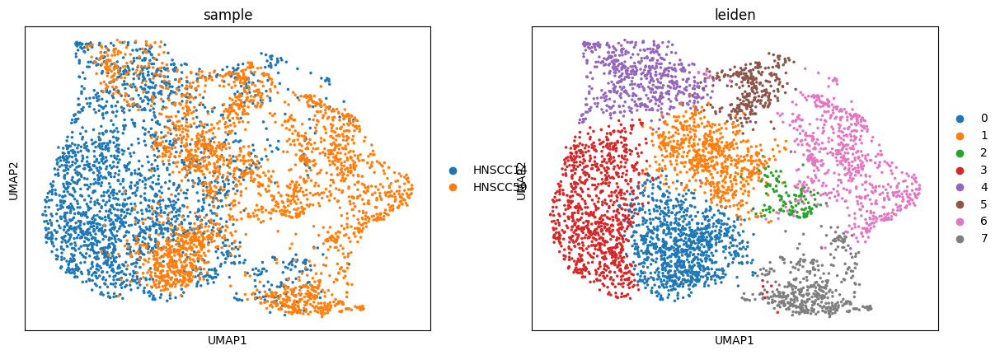

In [ ]:
sc.pl.umap(
    adata,
    color=["sample","leiden"]
)

/tmp/ipykernel_11575/1176608650.py:2: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


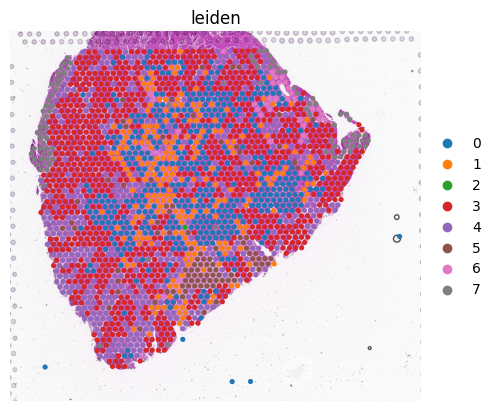

In [ ]:
slide = select_slide(adata, 'HNSCC14')
sc.pl.spatial(
        slide,
        cmap='RdBu_r',
        color=["leiden"],
        ncols=1, size=1.3,
        img_key='hires',
        vmin=0, vmax='p99.2',
        colorbar_loc=None,
        frameon=False,
    )

/tmp/ipykernel_11575/1026665905.py:2: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


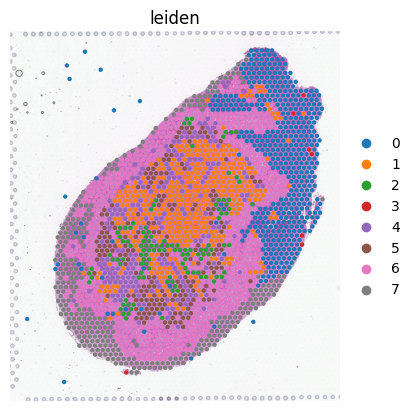

In [ ]:
slide = select_slide(adata, 'HNSCC59')
sc.pl.spatial(
        slide,
        cmap='RdBu_r',
        color=["leiden"],
        ncols=1, size=1.3,
        img_key='hires',
        vmin=0, vmax='p99.2',
        colorbar_loc=None,
        frameon=False,
    )

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_11575/893101937.py:31: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(


  0%|          | 0/1000 [00:00<?, ?/s]

/usr/local/lib/python3.13/dist-packages/squidpy/gr/_nhood.py:220: RuntimeWarning: invalid value encountered in divide
  zscore = (count - perms.mean(axis=0)) / perms.std(axis=0)


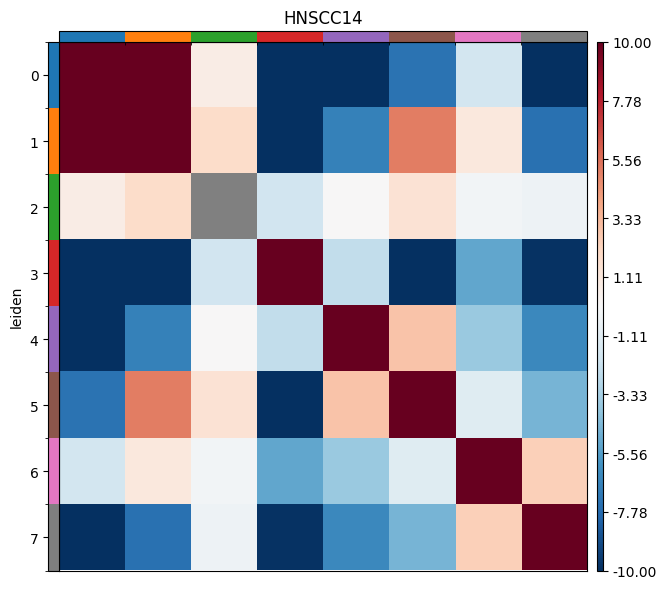

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_11575/893101937.py:31: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(


  0%|          | 0/1000 [00:00<?, ?/s]

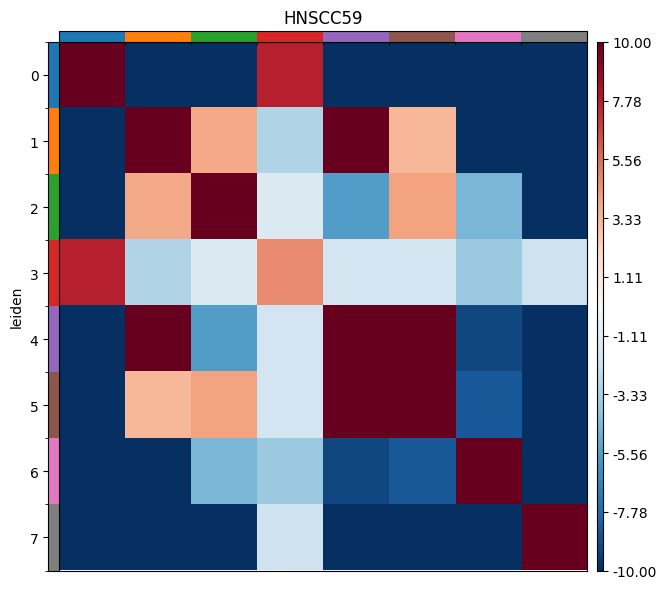

In [ ]:
import squidpy as sq
import pandas as pd
import matplotlib.pyplot as plt

sample_key = "sample"
cluster_key = "leiden"   # 如果你的列名是 clusters，这里改成 "clusters"

# 保存各样本的富集结果
nhood_results = {}

for sample in adata.obs[sample_key].dropna().unique():

    sub = adata[adata.obs[sample_key] == sample].copy()

    # 去掉没有聚类标签的 spot，并清除未使用类别
    sub = sub[sub.obs[cluster_key].notna()].copy()
    sub.obs[cluster_key] = (
        sub.obs[cluster_key]
        .astype("category")
        .cat.remove_unused_categories()
    )

    if "spatial" not in sub.obsm:
        raise ValueError(f"{sample} 缺少 obsm['spatial'] 空间坐标")

    if sub.obs[cluster_key].nunique() < 2:
        print(f"跳过 {sample}：有效 cluster 少于 2 个")
        continue

    # 1. 在当前切片内重新建立空间邻居图
    sq.gr.spatial_neighbors(
        sub,
        spatial_key="spatial",
        coord_type="grid",
        n_neighs=6,
        n_rings=1
    )

    # 2. 当前切片内进行置换检验
    sq.gr.nhood_enrichment(
        sub,
        cluster_key=cluster_key,
        n_perms=1000,
        seed=42,
        n_jobs=1
    )

    # 3. 保存带有 cluster 名称的结果矩阵
    labels = sub.obs[cluster_key].cat.categories
    result = sub.uns[f"{cluster_key}_nhood_enrichment"]

    nhood_results[str(sample)] = {
        "zscore": pd.DataFrame(
            result["zscore"], index=labels, columns=labels
        ),
        "count": pd.DataFrame(
            result["count"], index=labels, columns=labels
        )
    }

    # 4. 单独绘图，统一色阶便于查看
    fig, ax = plt.subplots(figsize=(7, 6))

    sq.pl.nhood_enrichment(
        sub,
        cluster_key=cluster_key,
        mode="zscore",
        cmap="RdBu_r",
        vmin=-10,
        vmax=10,
        title=str(sample),
        ax=ax
    )

    plt.tight_layout()
    plt.show()

In [ ]:
adata.uns.pop("leiden_nhood_enrichment", None)
adata.uns.pop("leiden_colors", None)
# 按样本建立空间邻居图，避免跨切片连边
sq.gr.spatial_neighbors(
    adata,
    spatial_key="spatial",
    library_key="sample",
    coord_type="grid",
    n_neighs=6,
    n_rings=1
)

# 根据新的 Leiden 标签重新计算
sq.gr.nhood_enrichment(
    adata,
    cluster_key="leiden",
    library_key="sample",
    n_perms=1000,
    seed=42,
    n_jobs=1
)

INFO     Creating graph using `None` transform and `2` libraries.                                                  


/tmp/ipykernel_11575/70002397.py:4: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(


  0%|          | 0/1000 [00:00<?, ?/s]

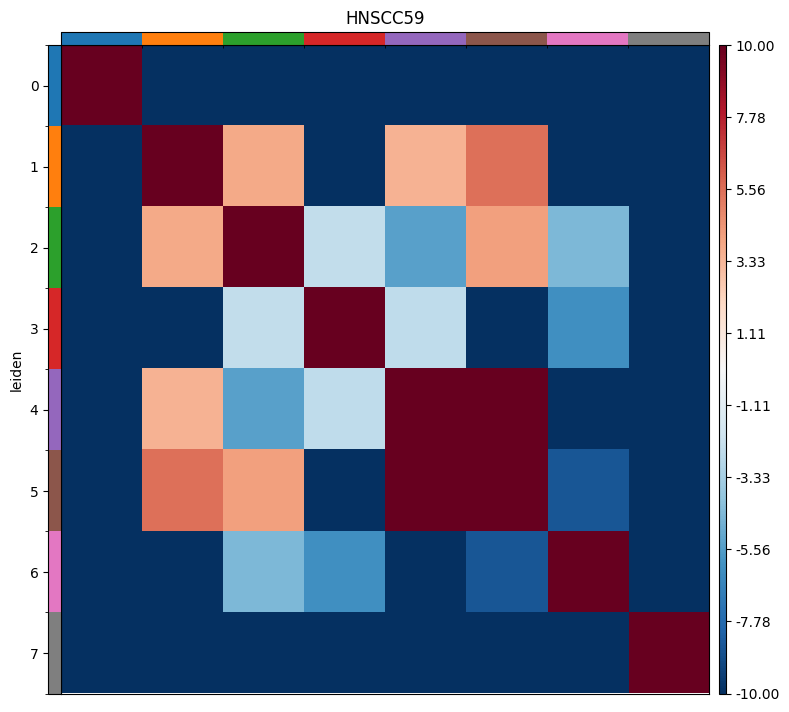

In [ ]:
    fig, ax = plt.subplots(figsize=(8,8))

    sq.pl.nhood_enrichment(
        adata,
        cluster_key="leiden",
        mode="zscore",
        cmap="RdBu_r",
        vmin=-10,
        vmax=10,
        title=str(sample),
        ax=ax
    )

    plt.tight_layout()
    plt.show()

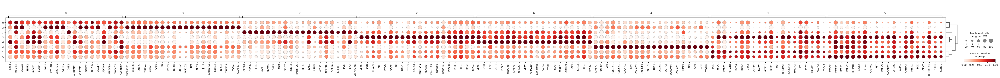

In [ ]:
grouplabel = "clusters"
sc.tl.rank_genes_groups(adata, groupby=grouplabel, method="wilcoxon",use_raw=True)
sc.tl.dendrogram(adata, groupby=grouplabel)
sc.pl.rank_genes_groups_dotplot(adata, groupby=grouplabel, standard_scale="var", n_genes=20)

In [ ]:
anno_agent(adata, cell_type = "niche in tumor", cluster_key="leiden")


'Identify cell types of niche in tumor using the following markers. Identify one cell type for each row. Attention - Determine the Subtype, Characteristic Genes, Phenotype, and Predict Function for Each Cell Type. Present the Results in a Tabular Format：\n0: ARF3,RNF213,COX8A,SERF2,LPCAT1,BANF1,TARS,YWHAQ,CHCHD1,GSTP1\n1: BOC,BEX3,PEBP1,SLC4A8,TRPA1,NONO,USF2,LAMB4,BMP7,ACSS1\n2: NPPB,CKB,HLA-G,MIF,PNCK,PDIA6,LEP,NRN1,FSTL3,GATA3\n3: SLC9A3R1,COX6C,FABP5,PABPC1,AP2M1,CCT5,TXN,DSC3,DCXR,DHRS2\n4: IGFBP7,SPARC,VIM,COL1A1,COL5A1,COL4A1,BGN,COL6A2,COL6A3,POSTN\n5: MFAP5,MMP14,HTRA1,FBLN2,FKBP10,VGLL3,FSTL1,PDGFRL,FST,FBLN5\n6: KRT8,CLU,IL32,OLR1,TAPBP,FNDC3B,IGFBP3,PLAAT4,KRT7,SEMA4C\n7: CXCL8,ZFP36,IL1B,NAMPT,PLAUR,G0S2,ADM,SOD2,SOCS3,PPP1R15A'

In [ ]:
Identify cell types of niche in tumor using the following markers. Identify one cell type for each row. Attention - Determine the Subtype, Characteristic Genes, Phenotype, and Predict Function for Each Cell Type. Present the Results in a Tabular Format：
0: ARF3,RNF213,COX8A,SERF2,LPCAT1,BANF1,TARS,YWHAQ,CHCHD1,GSTP1
1: BOC,BEX3,PEBP1,SLC4A8,TRPA1,NONO,USF2,LAMB4,BMP7,ACSS1
2: NPPB,CKB,HLA-G,MIF,PNCK,PDIA6,LEP,NRN1,FSTL3,GATA3
3: SLC9A3R1,COX6C,FABP5,PABPC1,AP2M1,CCT5,TXN,DSC3,DCXR,DHRS2
4: IGFBP7,SPARC,VIM,COL1A1,COL5A1,COL4A1,BGN,COL6A2,COL6A3,POSTN
5: MFAP5,MMP14,HTRA1,FBLN2,FKBP10,VGLL3,FSTL1,PDGFRL,FST,FBLN5
6: KRT8,CLU,IL32,OLR1,TAPBP,FNDC3B,IGFBP3,PLAAT4,KRT7,SEMA4C
7: CXCL8,ZFP36,IL1B,NAMPT,PLAUR,G0S2,ADM,SOD2,SOCS3,PPP1R15A

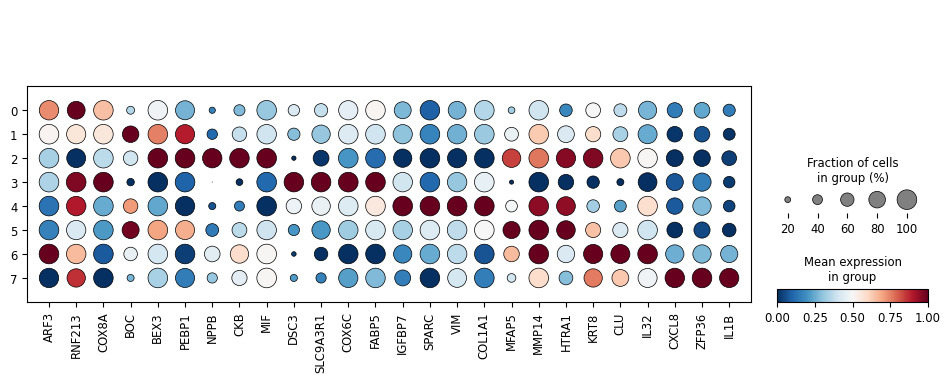

In [ ]:
marker_genes_dict = [
    'ARF3','RNF213','COX8A',
    'BOC','BEX3','PEBP1',
    'NPPB','CKB','MIF',
    "DSC3",'SLC9A3R1','COX6C','FABP5',
    'IGFBP7','SPARC','VIM','COL1A1',
    'MFAP5','MMP14','HTRA1',
    'KRT8','CLU','IL32',
    'CXCL8','ZFP36','IL1B',



]



sc.pl.dotplot(adata, marker_genes_dict, 'leiden', dendrogram=False, standard_scale = "var" ,edgecolor='black',cmap="RdBu_r",  # 点的边框颜色
    linewidth=0.5,)

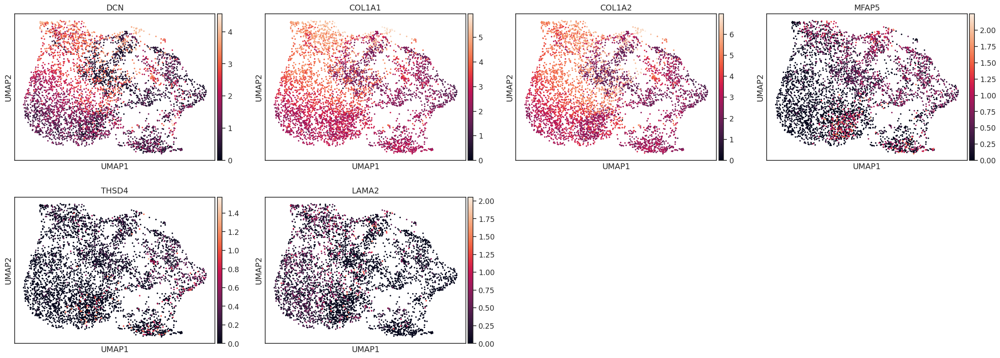

In [ ]:
sc.pl.umap(adata,color=["DCN","COL1A1","COL1A2","MFAP5","THSD4","LAMA2"])

In [ ]:
adata

AnnData object with n_obs × n_vars = 4640 × 12179
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'log1p_total_counts_mt', 'clusters', 'leiden', 'gene_niche', 'subtype', '_indices', '_scvi_batch', '_scvi_labels', 'Arterial_EC', 'B', 'Basal_Epi', 'CAF_COL14A1', 'CD4T_CXCL13', 'CD4T_GZMB', 'CD4T_PTPRC', 'CD4T_naive', 'CD8T_CXCL13', 'CD8T_GZMA', 'CD8T_GZMK', 'CD8T_naive', 'CD8T_str', 'Capillary_EC', 'Cycling_CAF', 'Cycling_EC', 'Cycling_T', 'Diff_Epi', 'EC_ACKR1', 'EC_PGF', 'EMT_like_Epi', 'Hypoxia_Epi', 'Mac_CXCL5', 'Mac_FOLR2', 'Mac_SPP1', 'Mast', 'Mono_FCN1', 'NK', 'Neutrophil', 'Normal_Epi', 'Plasma', 'Prolif_Epi', 'Stem_like_Epi', 'Str_Epi', 'Treg', 'Unknown', 'apCAF', 'iCAF_CXCL1', 'iCAF_CXCL8', 'mregDC', 'myCAF_CTHRC1', 'qCAF', 'qE

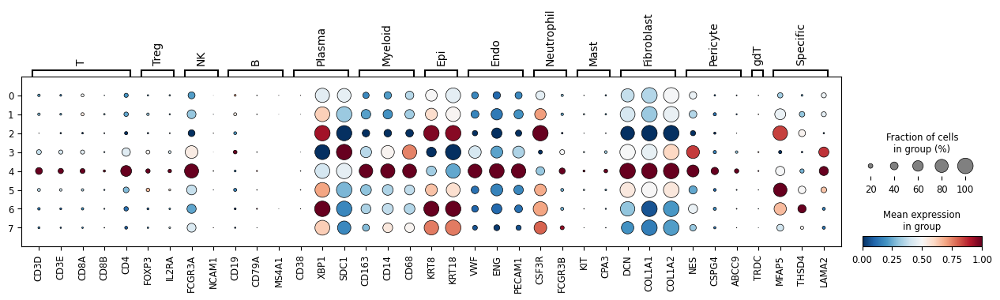

In [ ]:
marker_genes_dict = {
    "T":["CD3D","CD3E","CD8A","CD8B","CD4"],
    "Treg":["FOXP3","IL2RA"],
    "NK":["FCGR3A","NCAM1",],
    "B":["CD19","CD79A","MS4A1"],
    "Plasma":['CD38',"XBP1","SDC1"],
    "Myeloid":["CD163","CD14","CD68"],
    "Epi":["KRT8","KRT18"],
    "Endo":["VWF","ENG","PECAM1"],
    "Neutrophil":["CSF3R","FCGR3B"],
    "Mast":["KIT","CPA3"],
    "Fibroblast":["DCN","COL1A1","COL1A2"],
    "Pericyte":["NES","CSPG4","ABCC9"],
    "gdT":["TRDC"],
    "Specific":["MFAP5","THSD4","LAMA2"]

}



sc.pl.dotplot(adata, marker_genes_dict, 'leiden', dendrogram=False, standard_scale = "var" ,edgecolor='black',cmap="RdBu_r",  # 点的边框颜色
    linewidth=0.5,)

In [ ]:
adata.obs["gene_niche"] = (
     adata.obs["leiden"].astype(str)
).astype("category")

In [ ]:
# 示例：每种细胞类型对应多个 Leiden 群
celltype_clusters = {
    "Niche_OXPHOS": ["0"],
    "Niche_ECM": ["1"],#epi
    # "Nich_ER_stress":["2"],
    'Niche_Squamous_epithelial':['3'],
    "Niche_CAF_rich":["4","5"],
    # "Nich_6":["5"],
    "Niche_Migration":["2","6"],
    "Niche_Inflammatory":["7"],



}
clusters = [str(c) for ids in celltype_clusters.values() for c in ids]


# 添加注释，未指定的群标记为 Unknown
leiden = adata.obs["leiden"].astype(str)
adata.obs["gene_niche"] = "Unknown"

for celltype, cluster_ids in celltype_clusters.items():
    mask = leiden.isin([str(c) for c in cluster_ids])
    adata.obs.loc[mask, "gene_niche"] = celltype

adata.obs["gene_niche"] = adata.obs["gene_niche"].astype("category")

# 查看各细胞类型数量
print(adata.obs["gene_niche"].value_counts())

# 查看尚未注释的群
print("未注释的群：",
      leiden[adata.obs["gene_niche"] == "Unknown"].unique().tolist())

gene_niche
Niche_OXPHOS                 976
Niche_Squamous_epithelial    933
Niche_CAF_rich               856
Niche_Migration              787
Niche_ECM                    662
Niche_Inflammatory           426
Name: count, dtype: int64
未注释的群： []


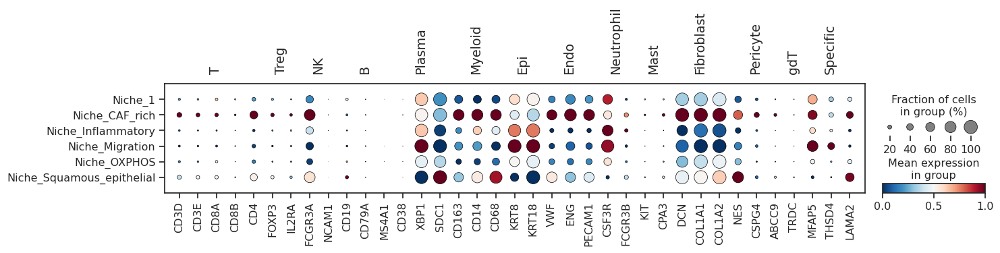

In [ ]:
marker_genes_dict = {
    "T":["CD3D","CD3E","CD8A","CD8B","CD4"],
    "Treg":["FOXP3","IL2RA"],
    "NK":["FCGR3A","NCAM1",],
    "B":["CD19","CD79A","MS4A1"],
    "Plasma":['CD38',"XBP1","SDC1"],
    "Myeloid":["CD163","CD14","CD68"],
    "Epi":["KRT8","KRT18"],
    "Endo":["VWF","ENG","PECAM1"],
    "Neutrophil":["CSF3R","FCGR3B"],
    "Mast":["KIT","CPA3"],
    "Fibroblast":["DCN","COL1A1","COL1A2"],
    "Pericyte":["NES","CSPG4","ABCC9"],
    "gdT":["TRDC"],
    "Specific":["MFAP5","THSD4","LAMA2"]

}



sc.pl.dotplot(adata, marker_genes_dict, 'gene_niche', dendrogram=False, standard_scale = "var" ,edgecolor='black',cmap="RdBu_r",  # 点的边框颜色
    linewidth=0.5,)

In [ ]:
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt

# 统一类别
adata.obs["gene_niche"] = adata.obs["gene_niche"].astype("category")

# 获取全部 niche
niches = list(adata.obs["gene_niche"].cat.categories)

# 生成固定的颜色映射
colors = (
    sc.pl.palettes.default_20
    if len(niches) <= 20
    else sc.pl.palettes.default_102
)

niche_colors = dict(zip(niches, colors[:len(niches)]))

# 保存到完整 adata
adata.uns["gene_niche_colors"] = [
    niche_colors[n] for n in niches
]

print(niche_colors)

{'Niche_1': '#1f77b4', 'Niche_CAF_rich': '#ff7f0e', 'Niche_Inflammatory': '#279e68', 'Niche_Migration': '#d62728', 'Niche_OXPHOS': '#aa40fc', 'Niche_Squamous_epithelial': '#8c564b'}


/tmp/ipykernel_15450/2551174717.py:2: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


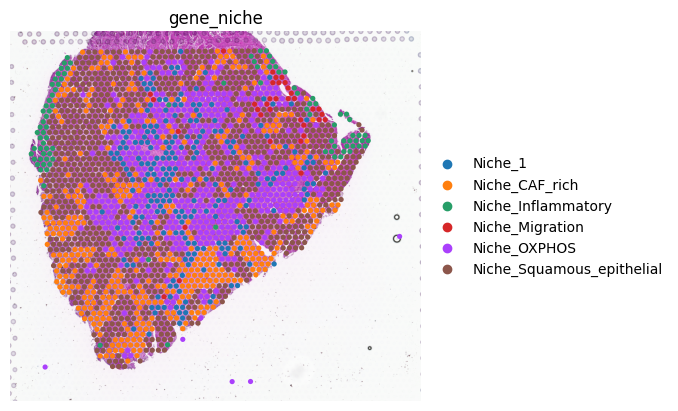

In [ ]:
slide = select_slide(adata, 'HNSCC14')
sc.pl.spatial(
        slide,
        cmap='RdBu_r',
        color=["gene_niche"],
        ncols=1, size=1.3,
        img_key='hires',
        vmin=0, vmax='p99.2',
        colorbar_loc=None,
        frameon=False,
    )

/tmp/ipykernel_15450/2158552193.py:2: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


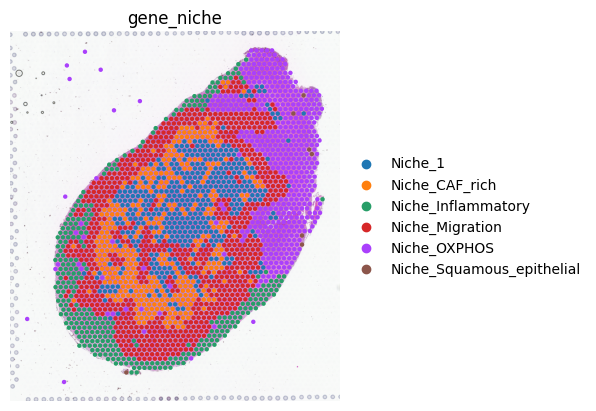

In [ ]:
slide = select_slide(adata, 'HNSCC59')
sc.pl.spatial(
        slide,
        cmap='RdBu_r',
        color=["gene_niche"],
        ncols=1, size=1.3,
        img_key='hires',
        vmin=0, vmax='p99.2',
        colorbar_loc=None,
        frameon=False,
    )

## niche enrich

In [ ]:
sc.tl.rank_genes_groups(adata, groupby='gene_niche', method="wilcoxon",use_raw=True)
sc.tl.dendrogram(adata, groupby='gene_niche')
result = adata.uns['rank_genes_groups']
groups = result['names'].dtype.names
degs = pd.DataFrame(
    {group + '_' + key: result[key][group]
    for group in groups for key in ['names','scores', 'pvals','pvals_adj','logfoldchanges']})

In [ ]:
result = adata.uns['rank_genes_groups']
groups = result['names'].dtype.names  # 获取所有 cluster 名称

# 整理成一个 DataFrame
dfs = []
for group in groups:
    df = pd.DataFrame({
        'cluster': group,
        'gene': result['names'][group],
        'log2FC': result['logfoldchanges'][group],
        'pval': result['pvals'][group],
        'pval_adj': result['pvals_adj'][group],
        'scores': result['scores'][group]
    })
    dfs.append(df)

# 合并所有 cluster
markers = pd.concat(dfs, axis=0)

# 保存为 CSV 文件
# markers.to_csv('./fibro_degene_new.csv', index=False)

In [ ]:
markers.to_csv('./visum/niche_degene_new.csv', index=False)

In [ ]:
top200_per_cluster = markers.groupby('cluster', group_keys=False).apply(
    lambda x: x.sort_values('scores', ascending=False).head(200)
)

/tmp/ipykernel_3650/1716845722.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  top200_per_cluster = markers.groupby('cluster', group_keys=False).apply(


###go

In [ ]:


res_all = []

for clu in top200_per_cluster['cluster'].unique():
    print(f'Running enrichment for {clu} ...')

    gene_list = (
        top200_per_cluster
        .loc[top200_per_cluster['cluster'] == clu, 'gene']
        .dropna()
        .unique()
        .tolist()
    )

    # #
    # if len(gene_list) < 5:
    #     print(f'Skip {clu}, too few genes')
    #     continue

    # enr = gp.enrichr(
    #     gene_list=gene_list,
    #     gene_sets='KEGG_2021_Human',
    #     organism='Human',
    #     outdir='./',
    #     cutoff=0.05
    # )
    import time


    time.sleep(3)

    enr = gp.enrichr(
        gene_list=gene_list,
        gene_sets='GO_Biological_Process_2025',
        organism='human',
        # outdir='./',
        cutoff=1
    )
    # msig = gp.Msigdb()
    # gmt = msig.get_gmt(category='h.all', dbver="2025.1.Hs")
    # enr = gp.enrichr(
    # gene_list=gene_list,
    # gene_sets=gmt,
    # organism='Human',
    # outdir='./',
    # cutoff=0.05
    # )

    if enr.results is not None and enr.results.shape[0] > 0:
        df = enr.results.copy()
        df['cluster'] = clu
        res_all.append(df)

# 5. concat
enr_all = pd.concat(res_all, axis=0, ignore_index=True)


Running enrichment for Niche_1 ...
Running enrichment for Niche_CAF_rich  ...
Running enrichment for Niche_Inflammatory ...
Running enrichment for Niche_Migration ...
Running enrichment for Niche_OXPHOS ...
Running enrichment for Niche_Squamous_epithelial ...


In [ ]:
plot_df = (
    enr_all
    .groupby('cluster', group_keys=False)
    .apply(lambda x: x.sort_values('P-value').head(30))#Adjusted
)


/tmp/ipykernel_3650/1202900258.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sort_values('P-value').head(30))#Adjusted


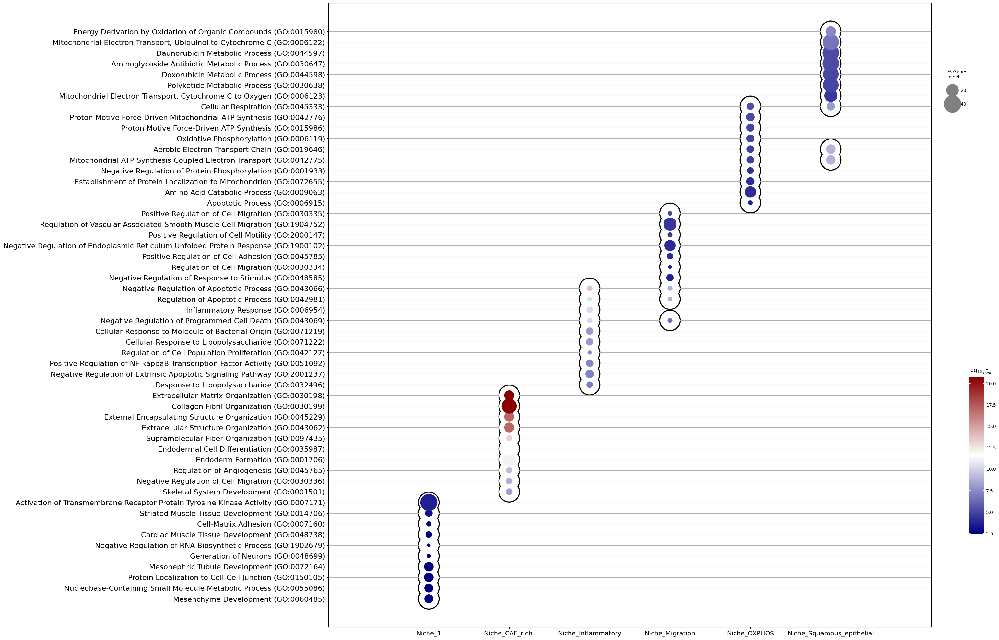

In [ ]:
from gseapy.scipalette import SciPalette
sci = SciPalette()
NbDr = sci.create_colormap()
# NbDr
ax = gp.dotplot(plot_df,figsize=(30,25),column="P-value",
                x='cluster',
                # x_order = ["UP","DOWN"],
                # title="GO_BP",
                cmap = NbDr,
                size=10,
                show_ring=True,
                )
ax.set_xlabel("")

fig = ax.figure
# fig.savefig("./fibro_gobp_pathway_dotplot.png", dpi=300, bbox_inches="tight")
plt.show()

###hm

In [ ]:


res_all = []

for clu in top200_per_cluster['cluster'].unique():
    print(f'Running enrichment for {clu} ...')

    gene_list = (
        top200_per_cluster
        .loc[top200_per_cluster['cluster'] == clu, 'gene']
        .dropna()
        .unique()
        .tolist()
    )

    # #
    # if len(gene_list) < 5:
    #     print(f'Skip {clu}, too few genes')
    #     continue

    # enr = gp.enrichr(
    #     gene_list=gene_list,
    #     gene_sets='KEGG_2021_Human',
    #     organism='Human',
    #     outdir='./',
    #     cutoff=0.05
    # )
    import time


    time.sleep(3)

    # enr = gp.enrichr(
    #     gene_list=gene_list,
    #     gene_sets='GO_Biological_Process_2025',
    #     organism='human',
    #     # outdir='./',
    #     cutoff=0.05
    # )
    msig = gp.Msigdb()
    gmt = msig.get_gmt(category='h.all', dbver="2025.1.Hs")
    enr = gp.enrichr(
    gene_list=gene_list,
    gene_sets=gmt,
    organism='hs',
    outdir='./',
    cutoff=0.05
    )

    if enr.results is not None and enr.results.shape[0] > 0:
        df = enr.results.copy()
        df['cluster'] = clu
        res_all.append(df)

# 5. concat
enr_all = pd.concat(res_all, axis=0, ignore_index=True)


Running enrichment for Niche_1 ...
Running enrichment for Niche_CAF_rich  ...
Running enrichment for Niche_Inflammatory ...
Running enrichment for Niche_Migration ...
Running enrichment for Niche_OXPHOS ...
Running enrichment for Niche_Squamous_epithelial ...


In [ ]:
plot_df = (
    enr_all
    .groupby('cluster', group_keys=False)
    .apply(lambda x: x.sort_values('P-value').head(30))#Adjusted
)


/tmp/ipykernel_3650/1202900258.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sort_values('P-value').head(30))#Adjusted


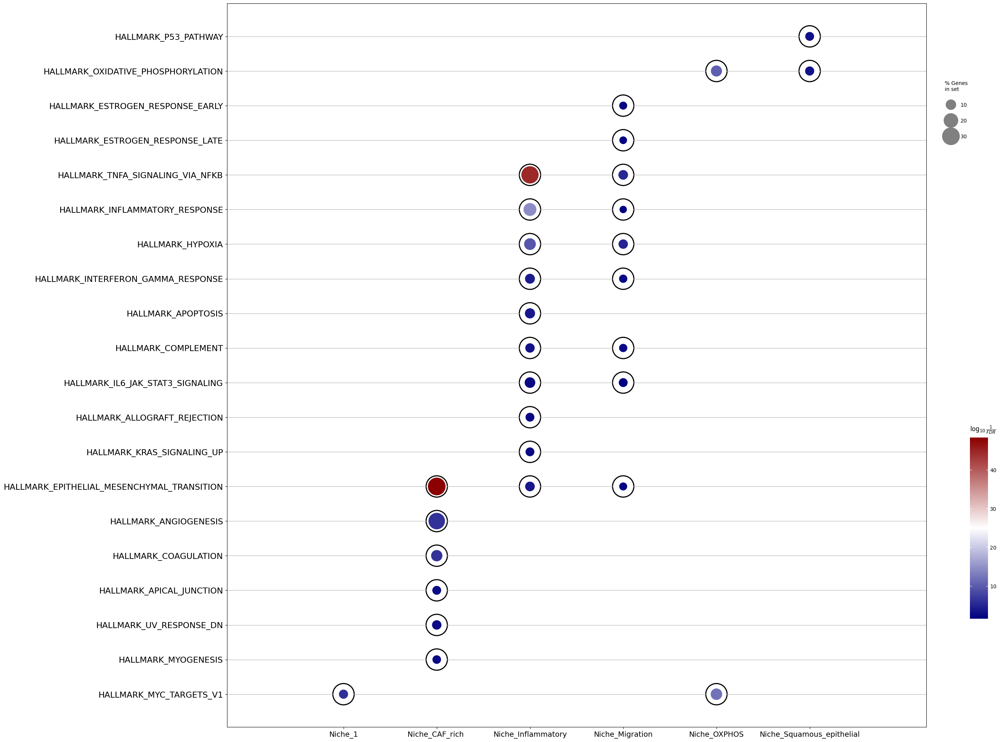

In [ ]:
from gseapy.scipalette import SciPalette
sci = SciPalette()
NbDr = sci.create_colormap()
# NbDr
ax = gp.dotplot(plot_df,figsize=(30,25),
                x='cluster',
                # x_order = ["UP","DOWN"],
                # title="GO_BP",
                cmap = NbDr,
                size=10,
                show_ring=True,
                )
ax.set_xlabel("")

fig = ax.figure
# fig.savefig("./fibro_gobp_pathway_dotplot.png", dpi=300, bbox_inches="tight")
plt.show()

###kegg

In [ ]:


res_all = []

for clu in top200_per_cluster['cluster'].unique():
    print(f'Running enrichment for {clu} ...')

    gene_list = (
        top200_per_cluster
        .loc[top200_per_cluster['cluster'] == clu, 'gene']
        .dropna()
        .unique()
        .tolist()
    )

    # #
    # if len(gene_list) < 5:
    #     print(f'Skip {clu}, too few genes')
    #     continue
    import time


    time.sleep(3)
    enr = gp.enrichr(
        gene_list=gene_list,
        gene_sets='KEGG_2021_Human',
        organism='hs',
        outdir='./',
        cutoff=1
    )




    if enr.results is not None and enr.results.shape[0] > 0:
        df = enr.results.copy()
        df['cluster'] = clu
        res_all.append(df)

# 5. concat
enr_all = pd.concat(res_all, axis=0, ignore_index=True)


Running enrichment for Niche_1 ...
Running enrichment for Niche_CAF_rich  ...
Running enrichment for Niche_Inflammatory ...
Running enrichment for Niche_Migration ...
Running enrichment for Niche_OXPHOS ...
Running enrichment for Niche_Squamous_epithelial ...


In [ ]:
plot_df = (
    enr_all
    .groupby('cluster', group_keys=False)
    .apply(lambda x: x.sort_values('P-value').head(30))#Adjusted
)


/tmp/ipykernel_3650/1202900258.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sort_values('P-value').head(30))#Adjusted


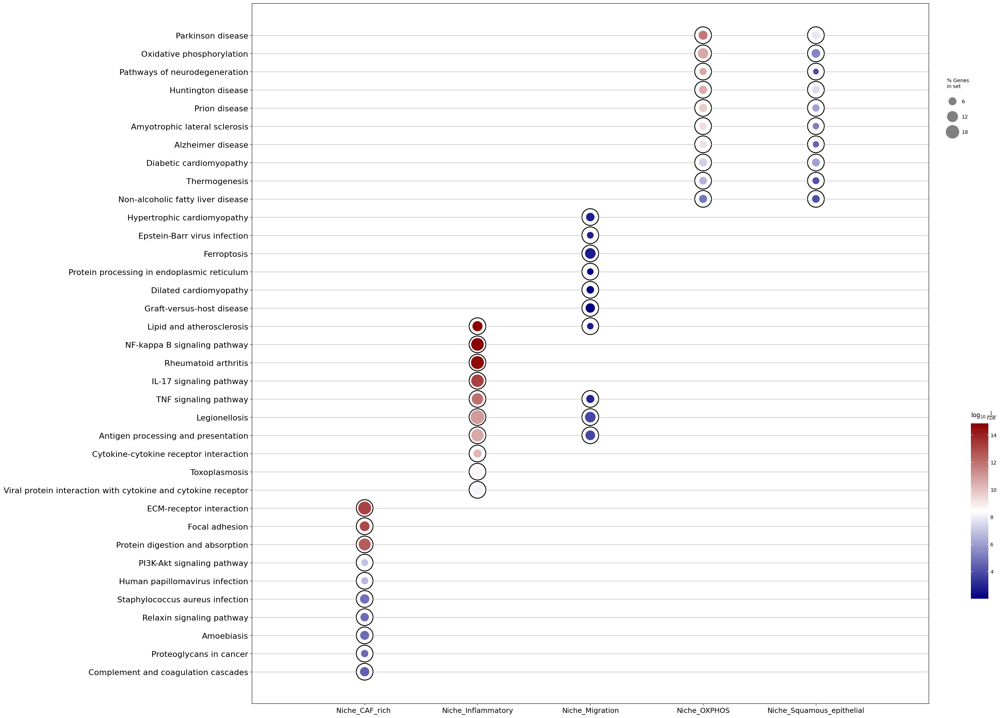

In [ ]:
from gseapy.scipalette import SciPalette
sci = SciPalette()
NbDr = sci.create_colormap()
# NbDr
ax = gp.dotplot(plot_df,figsize=(30,25),
                x='cluster',
                # x_order = ["UP","DOWN"],
                # title="GO_BP",
                cmap = NbDr,
                size=10,
                show_ring=True,
                )
ax.set_xlabel("")

fig = ax.figure
# fig.savefig("./fibro_gobp_pathway_dotplot.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
plot_df.to_csv("./visum/enrich.csv")

In [ ]:
adata.obs['clusters'].to_csv("./visum/adata_clusters.csv")

In [ ]:
adata.write_h5ad("./visum/st.h5ad")

##cnmf

In [ ]:
!pip install cnmf -i https://mirrors.aliyun.com/pypi/simple


Looking in indexes: https://mirrors.aliyun.com/pypi/simple
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 47.1 kB/s eta 0:00:00


In [ ]:
import skmisc
from skmisc.loess import loess
from cnmf import cNMF, Preprocess


>>> Processing sample: HNSCC14
INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_188139/1948118413.py:31: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata)
/usr/lib/python3.13/functools.py:934: UserWarning: 587 variables were constant, will return nan for these.
  return dispatch(args[0].__class__)(*args, **kw)



>>> Processing sample: HNSCC59
INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_188139/1948118413.py:31: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata)
/usr/lib/python3.13/functools.py:934: UserWarning: 185 variables were constant, will return nan for these.
  return dispatch(args[0].__class__)(*args, **kw)


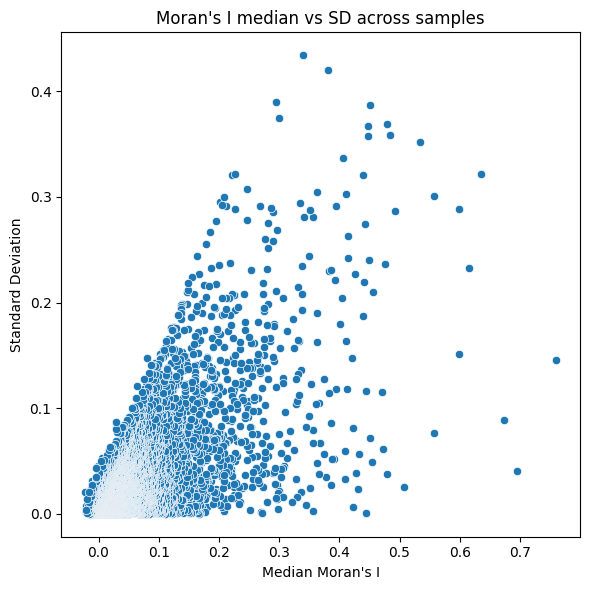

HNSCC14 contains 1500 / 1500 top genes.
HNSCC59 contains 1500 / 1500 top genes.


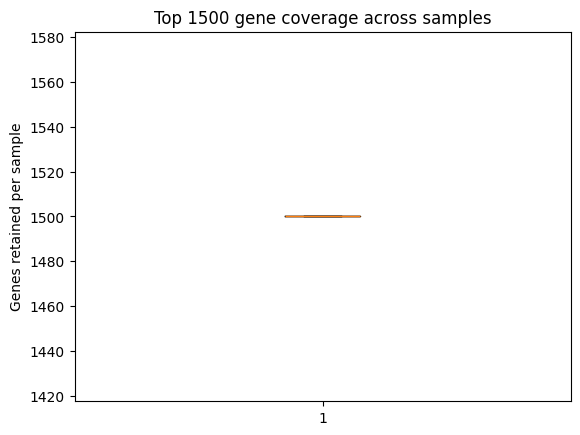


✅ Top 1500 spatially variable genes saved to:
/content/drive/MyDrive/pharynx/visum//cnmf_top1500_genes.csv


In [ ]:
import os
import scanpy as sc
import squidpy as sq
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

outdir = "/content/drive/MyDrive/pharynx/visum/"
samples = {
 'HNSCC14': "./visum/HNSCC14.h5ad",
 'HNSCC59': "./visum/HNSCC59.h5ad",


           }

ngenes = 1500
all_Is = []

for sample_id, path in samples.items():
    print(f"\n>>> Processing sample: {sample_id}")
    adata = sc.read_h5ad(path)
    adata.layers['counts'] =  adata.X.copy()
    adata.var_names_make_unique()
    adata.uns['spatial'][sample_id] = adata.uns['spatial'][list(adata.uns['spatial'].keys())[0]]
    del adata.uns['spatial'][list(adata.uns['spatial'].keys())[0]]
    adata.X = adata.layers['counts'].copy()

    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)
    sq.gr.spatial_neighbors(adata)
    sq.gr.spatial_autocorr(adata, mode='moran')
    moran_series = pd.Series(adata.uns['moranI']['I'], name=sample_id)
    all_Is.append(moran_series)

I_df = pd.concat(all_Is, axis=1, join='outer')

I_stats = pd.DataFrame({
    'median': I_df.median(axis=1),
    'sd': I_df.std(axis=1)
})

plt.figure(figsize=(6, 6))
sns.scatterplot(data=I_stats, x='median', y='sd')
plt.title("Moran's I median vs SD across samples")
plt.xlabel("Median Moran's I")
plt.ylabel("Standard Deviation")
plt.tight_layout()
plt.savefig(f"{outdir}/moranI_median_vs_sd.png", dpi=300)
plt.show()

top_spatial_genes = I_stats.sort_values(by='median', ascending=False).head(ngenes).index.tolist()

gene_coverage = []
for sample_id, path in samples.items():
    adata = sc.read_h5ad(path)
    adata.var_names_make_unique()
    overlap = len(set(adata.var_names).intersection(top_spatial_genes))
    gene_coverage.append(overlap)
    print(f"{sample_id} contains {overlap} / {ngenes} top genes.")

plt.figure()
plt.boxplot(gene_coverage)
plt.title("Top 1500 gene coverage across samples")
plt.ylabel("Genes retained per sample")
plt.savefig(f"{outdir}/top_genes_coverage_boxplot.png", dpi=300)
plt.show()

gene_file = f"{outdir}/cnmf_top1500_genes.csv"
pd.DataFrame(top_spatial_genes).to_csv(gene_file, index=False, header=False)
print(f"\n✅ Top 1500 spatially variable genes saved to:\n{gene_file}")

In [ ]:
gene_file = "/content/drive/MyDrive/pharynx/visum/cnmf_top1500_genes.csv"
top_genes = pd.read_csv(gene_file, header=None)[0].tolist()

samples = {
 'HNSCC14': "./visum/HNSCC14.h5ad",
 'HNSCC59': "./visum/HNSCC59.h5ad",
}

adatas = []
spatial_dict = {}

for sample_id, path in samples.items():
    print(f"Loading and subsetting sample: {sample_id}")

    adata = sc.read_h5ad(path)
    adata.var_names_make_unique()

    spatial_keys = list(adata.uns['spatial'].keys())
    if sample_id not in spatial_keys:
        adata.uns['spatial'][sample_id] = adata.uns['spatial'][spatial_keys[0]]
        del adata.uns['spatial'][spatial_keys[0]]

    spatial_dict[sample_id] = adata.uns['spatial'][sample_id]

    adata.obs['sample'] = sample_id

    use_genes = adata.var_names.intersection(top_genes)
    adata = adata[:, use_genes]

    adatas.append(adata)

adata_concat = adatas[0]
if len(adatas) > 1:
    # adata_concat = adata_concat.concatenate(
    #     adatas[1:],
    #     batch_key='batch',
    #     batch_categories=list(samples.keys()),
    #     fill_value=0,
    #     uns_merge='unique'
    # )
    adata_concat = ad.concat(
    adatas,
    axis=0,
    join="inner",        # 保留所有基因
    merge="same",
    label="batch",
    keys=["HNSCC14", "HNSCC59"]
)

adata_concat.uns['spatial'] = spatial_dict
vcol = adata_concat.var.columns
cols_to_fix = ['gene_ids', 'genome', 'mt', 'feature_types']
for newcol in cols_to_fix:
    matched = [c for c in vcol if newcol in c]
    if matched:
        adata_concat.var[newcol] = adata_concat.var[matched].fillna(method='bfill', axis=1).iloc[:, 0]
        adata_concat.var.drop(matched, axis=1, inplace=True)

hv_cols = [c for c in adata_concat.var.columns if 'highly_variable' in c]
if hv_cols:
    adata_concat.var[hv_cols] = adata_concat.var[hv_cols].fillna(False)

output_path = os.path.join(os.path.dirname(gene_file), "_cnmf_input.h5ad")

Loading and subsetting sample: HNSCC14
Loading and subsetting sample: HNSCC59


/tmp/ipykernel_188139/2025426670.py:56: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  adata_concat.var[newcol] = adata_concat.var[matched].fillna(method='bfill', axis=1).iloc[:, 0]
/tmp/ipykernel_188139/2025426670.py:56: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  adata_concat.var[newcol] = adata_concat.var[matched].fillna(method='bfill', axis=1).iloc[:, 0]
/tmp/ipykernel_188139/2025426670.py:56: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  adata_concat.var[newcol] = adata_concat.var[matched].fillna(method='bfill', axis=1).iloc[:, 0]


In [ ]:
X_df = pd.DataFrame(
    adata.X.toarray() if hasattr(adata.X, "toarray") else adata.X,
    index=adata.obs_names,
    columns=adata.var_names
)

X_df.to_csv("./visum/adata_X.csv")

In [ ]:
# !pip install harmonypy==0.0.9

  Attempting uninstall: harmonypy
    Found existing installation: harmonypy 2.0.0
    Uninstalling harmonypy-2.0.0:
      Successfully uninstalled harmonypy-2.0.0


/usr/lib/python3.13/functools.py:934: UserWarning: Received a view of an AnnData. Making a copy.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.13/functools.py:934: UserWarning: Received a view of an AnnData. Making a copy.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/local/lib/python3.13/dist-packages/cnmf/preprocess.py:330: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  sc.pp.pca(anorm, use_highly_variable=True, zero_center=True)


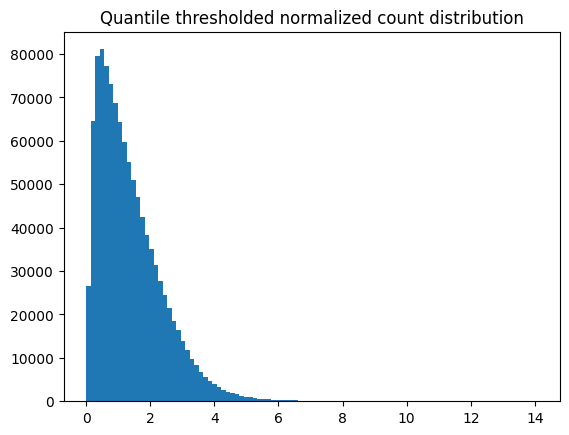

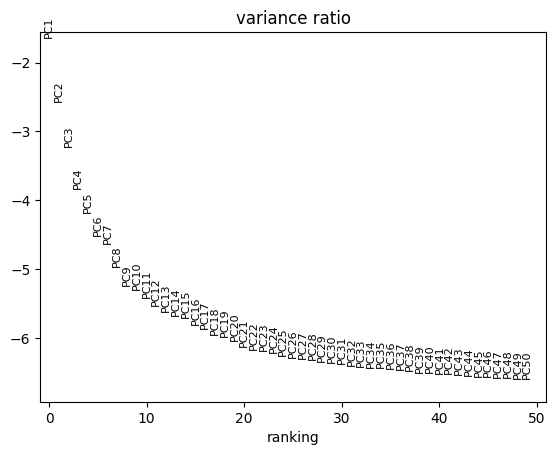

2026-09-15 02:20:49,446 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
INFO:harmonypy:Computing initial centroids with sklearn.KMeans...
2026-09-15 02:20:50,967 - harmonypy - INFO - sklearn.KMeans initialization complete.
INFO:harmonypy:sklearn.KMeans initialization complete.
2026-09-15 02:20:51,008 - harmonypy - INFO - Iteration 1 of 20
INFO:harmonypy:Iteration 1 of 20
2026-09-15 02:20:52,490 - harmonypy - INFO - Iteration 2 of 20
INFO:harmonypy:Iteration 2 of 20
2026-09-15 02:20:53,959 - harmonypy - INFO - Converged after 2 iterations
INFO:harmonypy:Converged after 2 iterations


In [ ]:
p = Preprocess(random_seed=550)
(adata_c, adata_tp10k, hvgs) = p.preprocess_for_cnmf(adata_concat, harmony_vars='sample', n_top_rna_genes = 1500,
                                                     max_scaled_thresh = None, quantile_thresh = .9999, makeplots=True,
                                                    save_output_base='/content/drive/MyDrive/pharynx/visum/cNMFres/batchcorrect_example')

In [ ]:
cnmf_obj_corrected = cNMF(output_dir='/content/drive/MyDrive/pharynx/visum/cNMFres', name='BatchCorrected')
cnmf_obj_corrected.prepare(counts_fn='/content/drive/MyDrive/pharynx/visum/cNMFres/batchcorrect_example.Corrected.HVG.Varnorm.h5ad',
                           tpm_fn='/content/drive/MyDrive/pharynx/visum/cNMFres/batchcorrect_example.TP10K.h5ad',
                           genes_file='/content/drive/MyDrive/pharynx/visum/cNMFres/batchcorrect_example.Corrected.HVGs.txt',
                           components=np.arange(2,15), n_iter=500, seed=550, num_highvar_genes=1500)

/usr/local/lib/python3.13/dist-packages/cnmf/cnmf.py:616: UserWarning: 6500 runs already appear completed. If this is unexpected, consider
            re-initializing the cnmf object with a different run name or output directory
  warnings.warn(message, UserWarning)


In [ ]:
!cnmf factorize --output-dir /content/drive/MyDrive/pharynx/visum/cNMFres/ --name BatchCorrected --worker-index 0 --total-workers 3 & \
cnmf factorize --output-dir /content/drive/MyDrive/pharynx/visum/cNMFres/ --name BatchCorrected --worker-index 1 --total-workers 3 & \
cnmf factorize --output-dir /content/drive/MyDrive/pharynx/visum/cNMFres/ --name BatchCorrected --worker-index 2 --total-workers 3 & \
# cnmf factorize --output-dir /content/drive/MyDrive/smoke/res/ --name BatchCorrected_JA --worker-index 3 --total-workers 4 & \


In [ ]:
cnmf_obj_corrected.combine()

Combining factorizations for k=2.
Combining factorizations for k=3.
Combining factorizations for k=4.
Combining factorizations for k=5.
Combining factorizations for k=6.
Combining factorizations for k=7.
Combining factorizations for k=8.
Combining factorizations for k=9.
Combining factorizations for k=10.
Combining factorizations for k=11.
Combining factorizations for k=12.
Combining factorizations for k=13.
Combining factorizations for k=14.


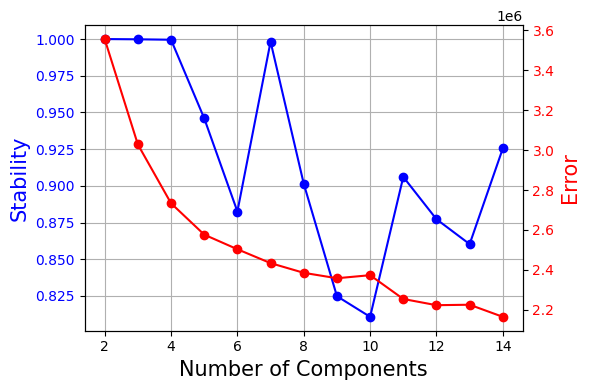

In [ ]:
cnmf_obj_corrected.k_selection_plot(close_fig=False)

In [ ]:
selected_K = 4
density_threshold=0.1

In [ ]:
cnmf_obj_corrected = cNMF(output_dir='/content/drive/MyDrive/pharynx/visum/cNMFres/', name='BatchCorrected')


/usr/lib/python3.13/functools.py:934: UserWarning: Received a view of an AnnData. Making a copy.
  return dispatch(args[0].__class__)(*args, **kw)


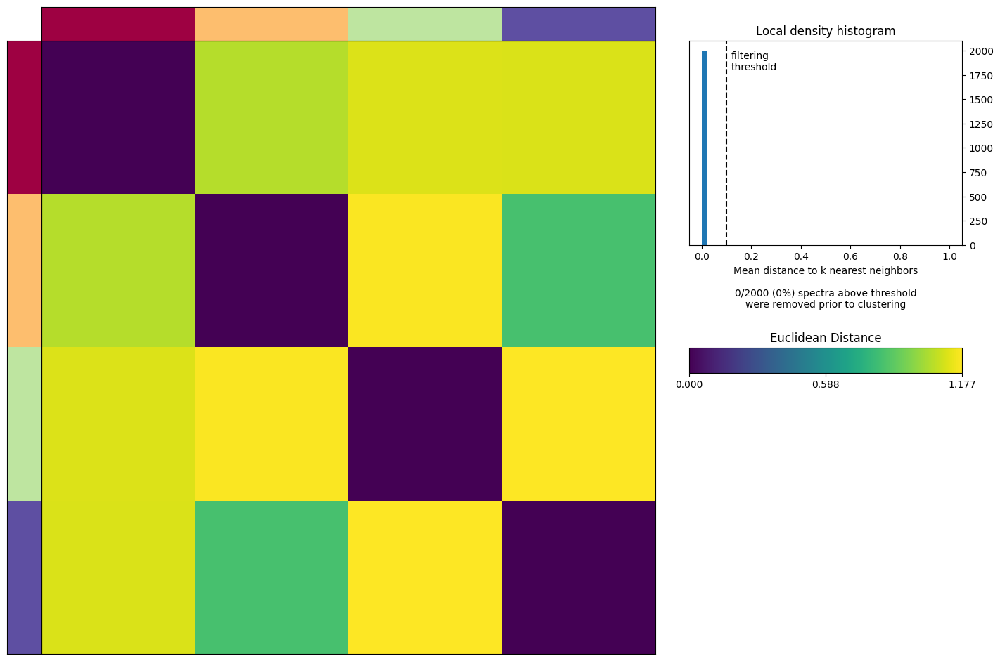

In [ ]:
cnmf_obj_corrected.consensus(k=selected_K, density_threshold=density_threshold, show_clustering=True, close_clustergram_fig=False)

In [ ]:
usage_norm, gep_scores, gep_tpm, topgenes = cnmf_obj_corrected.load_results(K=selected_K, density_threshold=density_threshold,n_top_genes=50)
usage_norm.columns = ['Usage_%d' % i for i in usage_norm.columns]

In [ ]:
top_genes = []
ngenes = 100
for gep in gep_scores.columns:
    top_genes.append(list(gep_scores.sort_values(by=gep, ascending=False).index[:ngenes]))

top_genes = pd.DataFrame(top_genes, index=gep_scores.columns).T
top_genes

            1       2         3         4
0    HIST1H4C   FABP5     SPARC  C15orf48
1    HIST1H4E    DSC3    COL1A1    S100A9
2    HIST1H1B    KRT5    COL6A2       CLU
3   HIST1H2AG    LY6D    COL6A1    IGFBP3
4        BEX3  PABPC1    COL6A3    GPRC5A
..        ...     ...       ...       ...
95      PARK7    GJB2  HLA-DRB5       EZR
96     COX6B1  PCYT1A     MMP13       ADM
97    LAMTOR4    CSTA    OLFML3     CASP4
98      FGFR1    PERP  SERPING1      SOD3
99    ATP5MC3    TLE5      CD93   GADD45A

[100 rows x 4 columns]

In [ ]:
topgenes.columns = ['program_' + str(col) for col in topgenes.columns]
topgenes.head()

   program_1 program_2 program_3 program_4
0   HIST1H4C     FABP5     SPARC  C15orf48
1   HIST1H4E      DSC3    COL1A1    S100A9
2   HIST1H1B      KRT5    COL6A2       CLU
3  HIST1H2AG      LY6D    COL6A1    IGFBP3
4       BEX3    PABPC1    COL6A3    GPRC5A

In [ ]:
topgenes.to_csv("./visum/nmf_topgenes.csv")

In [ ]:
usage_file = cnmf_obj_corrected.paths['consensus_usages__txt'] % (selected_K, '0_1')
gene_scores_file = cnmf_obj_corrected.paths['gene_spectra_score__txt'] % (selected_K, '0_1')
gene_tpm_file = cnmf_obj_corrected.paths['gene_spectra_tpm__txt'] % (selected_K, '0_1')

In [ ]:
usage_norm.rename(columns=lambda x: x.replace("Usage_", "Program_"), inplace=True)
print(usage_norm.head())

                            Program_1  Program_2  Program_3  Program_4
HNSCC14_AAACAATCTACTAGCA-1   0.027399   0.758178   0.156597   0.057826
HNSCC14_AAACAGAGCGACTCCT-1   0.092485   0.888246   0.019269   0.000000
HNSCC14_AAACCGGGTAGGTACC-1   0.101396   0.739251   0.159352   0.000000
HNSCC14_AAACCGTTCGTCCAGG-1   0.025961   0.269683   0.608437   0.095920
HNSCC14_AAACCTCATGAAGTTG-1   0.066376   0.548091   0.343942   0.041591


In [ ]:
usage_norm_normalized = usage_norm.div(usage_norm.sum(axis=1), axis=0)
print(usage_norm_normalized.head())

                            Program_1  Program_2  Program_3  Program_4
HNSCC14_AAACAATCTACTAGCA-1   0.027399   0.758178   0.156597   0.057826
HNSCC14_AAACAGAGCGACTCCT-1   0.092485   0.888246   0.019269   0.000000
HNSCC14_AAACCGGGTAGGTACC-1   0.101396   0.739251   0.159352   0.000000
HNSCC14_AAACCGTTCGTCCAGG-1   0.025961   0.269683   0.608437   0.095920
HNSCC14_AAACCTCATGAAGTTG-1   0.066376   0.548091   0.343942   0.041591


In [ ]:
adata

AnnData object with n_obs × n_vars = 4640 × 12179
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'log1p_total_counts_mt', 'clusters', 'leiden', 'gene_niche', 'subtype', '_indices', '_scvi_batch', '_scvi_labels', 'Arterial_EC', 'B', 'Basal_Epi', 'CAF_COL14A1', 'CD4T_CXCL13', 'CD4T_GZMB', 'CD4T_PTPRC', 'CD4T_naive', 'CD8T_CXCL13', 'CD8T_GZMA', 'CD8T_GZMK', 'CD8T_naive', 'CD8T_str', 'Capillary_EC', 'Cycling_CAF', 'Cycling_EC', 'Cycling_T', 'Diff_Epi', 'EC_ACKR1', 'EC_PGF', 'EMT_like_Epi', 'Hypoxia_Epi', 'Mac_CXCL5', 'Mac_FOLR2', 'Mac_SPP1', 'Mast', 'Mono_FCN1', 'NK', 'Neutrophil', 'Normal_Epi', 'Plasma', 'Prolif_Epi', 'Stem_like_Epi', 'Str_Epi', 'Treg', 'Unknown', 'apCAF', 'iCAF_CXCL1', 'iCAF_CXCL8', 'mregDC', 'myCAF_CTHRC1', 'qCAF', 'qE

In [ ]:
adata_concat.obs = pd.merge(left=adata_concat.obs, right=usage_norm_normalized, how='left', left_index=True, right_index=True)

In [ ]:
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.pyplot as plt
import matplotlib as mpl

/tmp/ipykernel_188139/3340895331.py:2: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


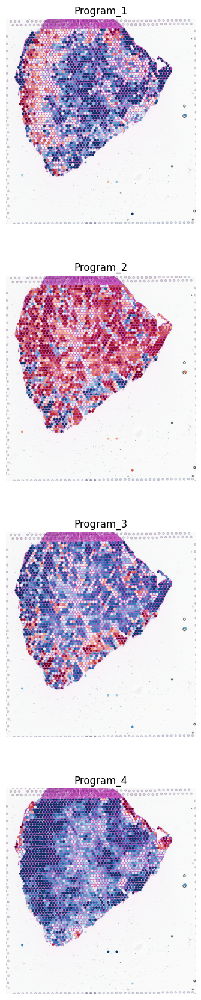

In [ ]:
slide = select_slide(adata_concat, 'HNSCC14')
sc.pl.spatial(
        slide,
        cmap='RdBu_r',
        color=["Program_1","Program_2","Program_3","Program_4"],#,'Program_5',"Program_6","Program_7",
        ncols=1, size=1.3,
        img_key='hires',
        vmin=0, vmax='p99.2',
        colorbar_loc=None,
        frameon=False,
    )

/tmp/ipykernel_3650/1851251780.py:2: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


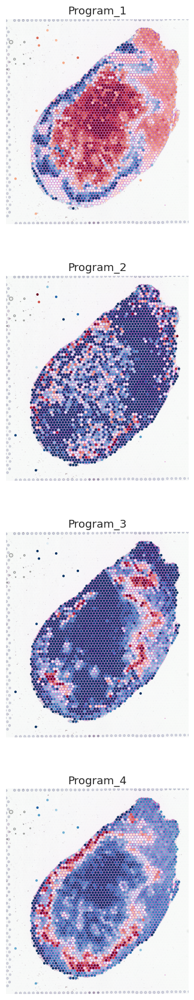

In [ ]:
slide = select_slide(adata_concat, 'HNSCC59')
sc.pl.spatial(
        slide,
        cmap='RdBu_r',
        color=["Program_1","Program_2","Program_3","Program_4"],#,'Program_5',"Program_6","Program_7",
        ncols=1, size=1.3,
        img_key='hires',
        vmin=0, vmax='p99.2',
        colorbar_loc=None,
        frameon=False,
    )

In [ ]:
adata_concat.write("./visum//st_cnmf.h5ad")

In [ ]:
adata_concat=sc.read_h5ad("./visum//st_cnmf.h5ad")

In [ ]:
adata_concat

AnnData object with n_obs × n_vars = 4649 × 1500
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'batch', 'Program_1', 'Program_2', 'Program_3', 'Program_4', 'Program_5', 'Program_6', 'Program_7'
    var: 'features_renamed', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'spatial'
    obsm: 'spatial'
    layers: None (.X)

In [ ]:
adata.obs_names = (
    adata.obs_names
    .str.replace(
        "HNSCC59_HNSCC59_",
        "HNSCC59_"
    )
)

In [ ]:
# 要匹配的列
cols = [
    c for c in adata_concat.obs.columns
    if c.startswith("Program_")
]

# 按spot名称匹配
adata.obs[cols] = adata_concat.obs[cols].reindex(
    adata_concat.obs_names
)
matched = adata.obs[cols].notna().any(axis=1)

print(
    "匹配spot:",
    matched.sum(),
    "/",
    adata.n_obs
)

匹配spot: 4640 / 4640


In [ ]:
program_cols = [
    c for c in adata_concat.obs.columns
    if c.startswith("Program_")
]

adata.obs[program_cols] = (
    adata_concat.obs[program_cols]
    .reindex(adata.obs_names)
)

In [ ]:
adata.write_h5ad("./visum//st.h5ad")

In [ ]:
adata=sc.read_h5ad("./visum//st.h5ad")

In [ ]:
# adata.obs.drop(
#     columns=["5", "6", "7"],
#     inplace=True,
#     errors="ignore"
# )

In [ ]:
adata

AnnData object with n_obs × n_vars = 4640 × 12179
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'log1p_total_counts_mt', 'clusters', 'leiden', 'gene_niche', 'subtype', '_indices', '_scvi_batch', '_scvi_labels', 'Arterial_EC', 'B', 'Basal_Epi', 'CAF_COL14A1', 'CD4T_CXCL13', 'CD4T_GZMB', 'CD4T_PTPRC', 'CD4T_naive', 'CD8T_CXCL13', 'CD8T_GZMA', 'CD8T_GZMK', 'CD8T_naive', 'CD8T_str', 'Capillary_EC', 'Cycling_CAF', 'Cycling_EC', 'Cycling_T', 'Diff_Epi', 'EC_ACKR1', 'EC_PGF', 'EMT_like_Epi', 'Hypoxia_Epi', 'Mac_CXCL5', 'Mac_FOLR2', 'Mac_SPP1', 'Mast', 'Mono_FCN1', 'NK', 'Neutrophil', 'Normal_Epi', 'Plasma', 'Prolif_Epi', 'Stem_like_Epi', 'Str_Epi', 'Treg', 'Unknown', 'apCAF', 'iCAF_CXCL1', 'iCAF_CXCL8', 'mregDC', 'myCAF_CTHRC1', 'qCAF', 'qE

In [ ]:
import pandas as pd

# 按 Program 编号排序
program_cols = sorted(
    [
        c for c in adata.obs.columns
        if c.startswith("Program_") and c.removeprefix("Program_").isdigit()
    ],
    key=lambda c: int(c.removeprefix("Program_"))
)

if not program_cols:
    raise ValueError("adata.obs 中没有找到 Program_数字 列")

# 保留 spot 索引和 Program 列名
adata.obsm["program_usage"] = (
    adata.obs[program_cols]
    .apply(pd.to_numeric, errors="raise")
    .copy()
)

print(adata.obsm["program_usage"].shape)
print(adata.obsm["program_usage"].head())

(4640, 4)
                            Program_1  Program_2  Program_3  Program_4
HNSCC14_AAACAATCTACTAGCA-1   0.027399   0.758178   0.156597   0.057826
HNSCC14_AAACAGAGCGACTCCT-1   0.092485   0.888246   0.019269   0.000000
HNSCC14_AAACCGGGTAGGTACC-1   0.101396   0.739251   0.159352   0.000000
HNSCC14_AAACCGTTCGTCCAGG-1   0.025961   0.269683   0.608437   0.095920
HNSCC14_AAACCTCATGAAGTTG-1   0.066376   0.548091   0.343942   0.041591


/tmp/ipykernel_1591/3040095683.py:2: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


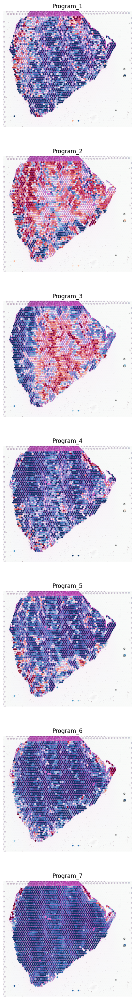

In [ ]:
slide = select_slide(adata, 'HNSCC14')
sc.pl.spatial(
        slide,
        cmap='RdBu_r',
        color=["Program_1","Program_2","Program_3","Program_4",'Program_5',"Program_6","Program_7",],#,'Program_5',"Program_6","Program_7",
        ncols=1, size=1.3,
        img_key='hires',
        vmin=0, vmax='p99.2',
        colorbar_loc=None,
        frameon=False,
    )

/tmp/ipykernel_1591/1851251780.py:2: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


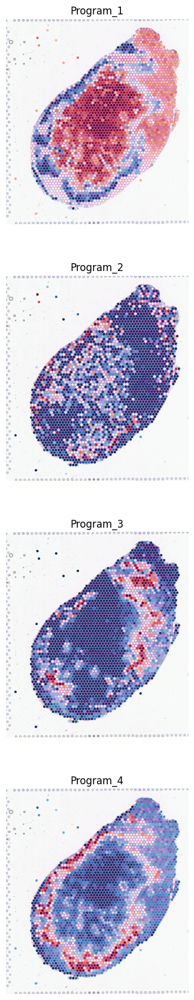

In [ ]:
slide = select_slide(adata, 'HNSCC59')
sc.pl.spatial(
        slide,
        cmap='RdBu_r',
        color=["Program_1","Program_2","Program_3","Program_4"],#,'Program_5',"Program_6","Program_7",
        ncols=1, size=1.3,
        img_key='hires',
        vmin=0, vmax='p99.2',
        colorbar_loc=None,
        frameon=False,
    )

In [ ]:
res = plot_gene_caf(adata, gene="MFAP5", niche="Niche_CAF_rich")


In [ ]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr


def plot_gene_nmf(
    adata,
    gene="LAMA2",
    program="Program_1",
    key="program_usage",
    layer=None,
    samples=("HNSCC14", "HNSCC59"),
    normalize=True,
):
    """各样本全部组织内 spot：基因表达与指定 NMF Program 的关系。"""
    samples = [str(s).strip() for s in samples]

    if not samples or len(samples) != len(set(samples)):
        raise ValueError("samples 不能为空或包含重复样本。")
    if not adata.var_names.is_unique or gene not in adata.var_names:
        raise ValueError("请检查基因是否存在，以及基因名是否唯一。")
    if key not in adata.obsm:
        raise KeyError(f"adata.obsm 中没有 {key!r}。")

    # 1. 读取 Program usage
    usage = adata.obsm[key]

    if not isinstance(usage, pd.DataFrame):
        raise ValueError("program_usage 需要是带 spot 索引及 Program 列名的 DataFrame。")
    if not usage.index.is_unique or not usage.columns.is_unique:
        raise ValueError("Program usage 的索引或列名重复。")

    usage = usage.reindex(adata.obs_names).astype(float)

    if program not in usage.columns:
        raise ValueError(f"未找到 {program}，可选：{list(usage.columns)}")

    values = usage.to_numpy()
    if not np.isfinite(values).all() or (values < 0).any():
        raise ValueError("Program usage 包含缺失、无穷值或负值。")

    if normalize:
        program_value = (
            usage[program] / usage.sum(axis=1).replace(0, np.nan)
        )
        x_label = f"{program}: relative usage"
    else:
        program_value = usage[program]
        x_label = f"{program}: usage"

    # 2. 只按样本及组织区域筛选，不限制 niche
    sample = adata.obs["sample"].astype("string").str.strip()
    keep = sample.isin(samples)

    if "in_tissue" in adata.obs:
        keep &= pd.to_numeric(
            adata.obs["in_tissue"], errors="coerce"
        ).eq(1)

    idx = np.flatnonzero(keep.to_numpy(dtype=bool))

    matrix = adata.X if layer is None else adata.layers[layer]
    gene_idx = adata.var_names.get_loc(gene)
    x = matrix[:, [gene_idx]][idx, :]
    x = x.toarray().ravel() if sp.issparse(x) else np.asarray(x).ravel()

    if not np.isfinite(x).all() or (x < 0).any():
        raise ValueError("请使用非负、无缺失的表达矩阵，不要使用 scale 后的矩阵。")

    df = pd.DataFrame(
        {
            "sample": sample.iloc[idx].to_numpy(),
            "expression": x,
            "program_usage": program_value.iloc[idx].to_numpy(),
        },
        index=adata.obs_names[idx],
    ).dropna()

    # 3. 分样本计算相关性
    rows = []

    for s in samples:
        d = df.loc[df["sample"] == s]

        if len(d) < 3:
            raise ValueError(f"{s} 不足 3 个有效 spot。")

        rho, p = np.nan, np.nan
        if (
            d["expression"].nunique() > 1
            and d["program_usage"].nunique() > 1
        ):
            rho, p = spearmanr(
                d["program_usage"], d["expression"]
            )

        rows.append({
            "sample": s,
            "n_spots": len(d),
            "usage_mean": d["program_usage"].mean(),
            "usage_median": d["program_usage"].median(),
            "gene_mean": d["expression"].mean(),
            "gene_median": d["expression"].median(),
            "rho": rho,
            "p_value": p,
        })

    summary = pd.DataFrame(rows).set_index("sample")
    print(summary.to_string(float_format=lambda v: f"{v:.4g}"))

    # 4. ECDF + 每个样本的散点图
    colors = (
        ["#E68A65", "#619BC3"]
        if len(samples) <= 2
        else sns.color_palette("tab10", n_colors=len(samples))
    )
    palette = dict(zip(samples, colors))

    fig, axes = plt.subplots(
        1,
        len(samples) + 1,
        figsize=(5 * (len(samples) + 1), 4.5),
        squeeze=False,
    )
    axes = axes.ravel()

    sns.ecdfplot(
        data=df,
        x="program_usage",
        hue="sample",
        hue_order=samples,
        palette=palette,
        ax=axes[0],
    )
    axes[0].set(
        title=f"{program} | All tissue spots",
        xlabel=x_label,
        ylabel="Cumulative fraction of spots",
    )

    xmax = max(df["program_usage"].max() * 1.05, 0.01)
    ymax = max(df["expression"].max() * 1.05, 0.1)

    for ax, s in zip(axes[1:], samples):
        d = df.loc[df["sample"] == s]

        ax.scatter(
            d["program_usage"],
            d["expression"],
            color=palette[s],
            s=18,
            alpha=0.5,
            linewidths=0,
        )
        ax.set(
            title=(
                f"{s}: rho={summary.loc[s, 'rho']:.2f}, "
                f"P={summary.loc[s, 'p_value']:.2g}"
            ),
            xlabel=x_label,
            ylabel=f"{gene} expression",
            xlim=(0, xmax),
            ylim=(0, ymax),
        )

    axes[0].set_xlim(0, xmax)
    sns.despine(fig=fig)
    fig.tight_layout()
    plt.show()

    return {
        "data": df,
        "summary": summary,
        "figure": fig,
    }

         n_spots  usage_mean  usage_median  gene_mean  gene_median     rho   p_value
sample                                                                              
HNSCC14     2213      0.2867         0.217     0.2548       0.1367 0.08764  3.65e-05
HNSCC59     2427     0.06959       0.04862    0.03622            0  0.1458 5.386e-13


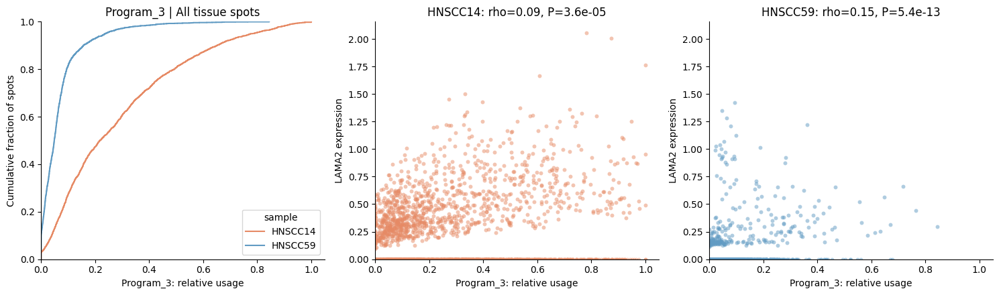

In [ ]:
result = plot_gene_nmf(
    adata,
    gene="LAMA2",
    program="Program_3",
    samples=("HNSCC14", "HNSCC59"),
    normalize=True,
)

# 只分析 HNSCC14 时：
# samples=("HNSCC14",)

# # 保存图片
# result["figure"].savefig(
#     "MFAP5_Program3_CAF_rich.tiff",
#     dpi=600,
#     bbox_inches="tight",
#     pil_kwargs={"compression": "tiff_lzw"},
# )

         n_spots  usage_mean  usage_median  gene_mean  gene_median      rho   p_value
sample                                                                               
HNSCC14     2213      0.2867         0.217    0.08481            0   0.2256 6.241e-27
HNSCC59     2427     0.06959       0.04862     0.4816       0.4918 -0.06417  0.001563


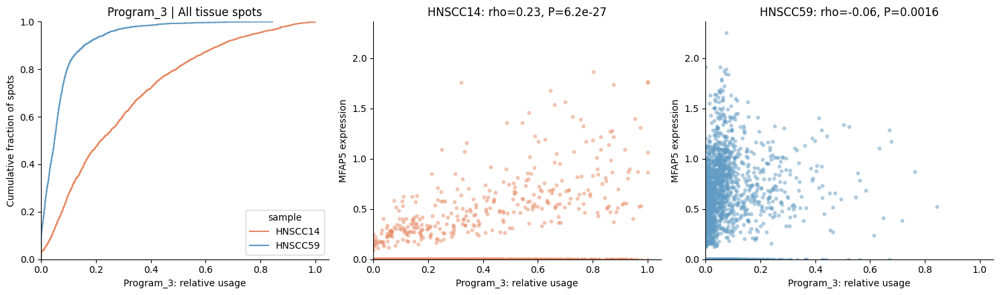

In [ ]:
result = plot_gene_nmf(
    adata,
    gene="MFAP5",
    program="Program_3",
    samples=("HNSCC14", "HNSCC59"),
    normalize=True,
)

# 只分析 HNSCC14 时：
# samples=("HNSCC14",)

# # 保存图片
# result["figure"].savefig(
#     "MFAP5_Program3_CAF_rich.tiff",
#     dpi=600,
#     bbox_inches="tight",
#     pil_kwargs={"compression": "tiff_lzw"},
# )

##banksy

In [ ]:
!pip install -U pybanksy leidenalg

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 83.3/83.3 kB 2.8 MB/s eta 0:00:00


In [ ]:
adata =sc.read_h5ad("./visum//st.h5ad")

In [ ]:
adata

AnnData object with n_obs × n_vars = 4640 × 17943
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'log1p_total_counts_mt', 'clusters', 'leiden', 'gene_niche', 'subtype'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'clusters', 'clusters_colors', 'clusters_nhood_enrichment', 'dendrogram_clusters', 'dendrogram_gene_niche', 'dendrogram_leiden', 'hvg', 'leiden', 'leiden_nhood_enrichment', 'log1p', 'neighbors', 'pca', 'rank_genes_groups', 'sample_colors', 'spatial', 'spatial_neighbors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'spatial'
    obsp: 'connectivities', 'distances', 'spatial_connectivities', 'spatial_distances'
    layers: 'counts', None (.X)

In [ ]:
sc.pp.normalize_total(
    adata,
    target_sum=1e4
)

sc.pp.log1p(adata)

sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    flavor="seurat_v3",
    layer = "counts",batch_key="sample"
)

adata = adata[:, adata.var.highly_variable].copy()

In [ ]:
adata.X = adata.layers['counts'].copy()

In [ ]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

from banksy.main import median_dist_to_nearest_neighbour
from banksy.initialize_banksy import initialize_banksy
from banksy.embed_banksy import generate_banksy_matrix

from banksy_utils.umap_pca import pca_umap
from banksy.cluster_methods import run_Leiden_partition
from banksy.plot_banksy import plot_results

In [ ]:
coord_keys = (
    "x",
    "y",
    "spatial"
)

In [ ]:
adata.obs["x"] = adata.obsm["spatial"][:,0]
adata.obs["y"] = adata.obsm["spatial"][:,1]


adata.obsm["spatial"] = np.vstack(
    [
        adata.obs["x"],
        adata.obs["y"]
    ]
).T

In [ ]:
adata.obsm["spatial_raw"] = (
    adata.obsm["spatial"].copy()
)

In [ ]:
adata.obs["x_bk"] = adata.obs["x"].astype(float)
adata.obs["y_bk"] = adata.obs["y"].astype(float)


gap = (
    adata.obs["x_bk"].max()
    +
    adata.obs["x_bk"].max()*0.1
)


for i, sample in enumerate(
    adata.obs["sample"].unique()
):

    idx = (
        adata.obs["sample"]==sample
    )

    adata.obs.loc[idx,"x_bk"] += (
        i*gap
    )


adata.obsm["spatial_bk"] = np.vstack(
    [
        adata.obs["x_bk"],
        adata.obs["y_bk"]
    ]
).T

(np.float64(316.6049999999999),
 np.float64(18101.295000000002),
 np.float64(456.95),
 np.float64(9324.05))

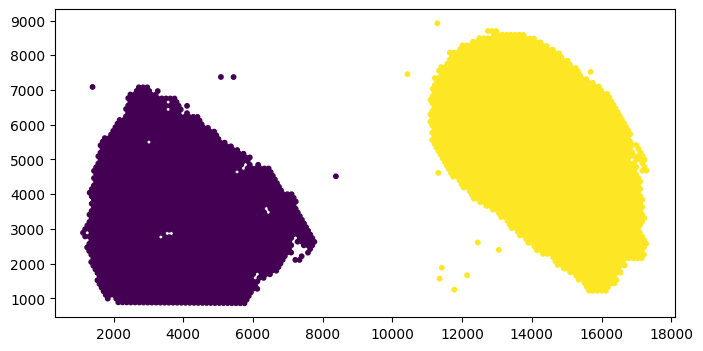

In [ ]:
plt.figure(figsize=(8,4))

plt.scatter(
    adata.obsm["spatial_bk"][:,0],
    adata.obsm["spatial_bk"][:,1],
    c=pd.factorize(
        adata.obs["sample"]
    )[0],
    s=10
)

plt.axis("equal")

In [ ]:
coord_keys = (
    "x_bk",
    "y_bk",
    "spatial_bk"
)

In [ ]:
k_geom = 15

max_m = 1

nbr_weight_decay = "scaled_gaussian"

lambda_list = [0.2]

pca_dims = [20]

resolutions = [0.5]

In [ ]:
banksy_dict = initialize_banksy(
    adata,
    coord_keys,
    k_geom,
    nbr_weight_decay=nbr_weight_decay,
    max_m=max_m,
    plt_edge_hist=False,
    plt_nbr_weights=False,
    plt_agf_angles=False,
    plt_theta=False
)


Median distance to closest cell = 120.00416659433121

---- Ran median_dist_to_nearest_neighbour in 0.01 s ----

---- Ran generate_spatial_distance_graph in 0.03 s ----

---- Ran row_normalize in 0.01 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.13 s ----

---- Ran generate_spatial_distance_graph in 0.04 s ----

---- Ran theta_from_spatial_graph in 0.04 s ----

---- Ran row_normalize in 0.01 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.20 s ----



In [ ]:
banksy_dict, banksy_matrix = generate_banksy_matrix(
    adata,
    banksy_dict,
    lambda_list,
    max_m
)

Runtime Sep-16-2026-11-09

2000 genes to be analysed:
Gene List:
Index(['NOC2L', 'ISG15', 'TNFRSF4', 'PUSL1', 'SSU72', 'RER1', 'HES5',
       'ARHGEF16', 'HES2', 'VAMP3',
       ...
       'CSAG3', 'ZNF185', 'MAGEA1', 'BGN', 'DUSP9', 'PNCK', 'L1CAM', 'G6PD',
       'MPP1', 'VBP1'],
      dtype='object', length=2000)

Check if X contains only finite (non-NAN) values
Decay Type: scaled_gaussian
Weights Object: {'weights': {0: <Compressed Sparse Row sparse matrix of dtype 'float64'
	with 69600 stored elements and shape (4640, 4640)>, 1: <Compressed Sparse Row sparse matrix of dtype 'complex128'
	with 139200 stored elements and shape (4640, 4640)>}}

Nbr matrix | Mean: 3.31 | Std: 17.96
Size of Nbr | Shape: (4640, 2000)
Top 3 entries of Nbr Mat:

[[ 4.66253924 18.81959146  0.18530026]
 [ 5.36498732  8.40404099  0.1483288 ]
 [ 4.31223984 11.97792589  0.1962762 ]]

AGF matrix | Mean: 0.79 | Std: 5.61
Size of AGF mat (m = 1) | Shape: (4640, 2000)
Top entries of AGF:
[[0.62919356 5.33068839 0.

In [ ]:
# pca_umap(
#     banksy_dict,
#     pca_dims=pca_dims,
#     add_umap=True
# )

Current decay types: ['scaled_gaussian']

Reducing dims of dataset in (Index = scaled_gaussian, lambda = 0.2)

Setting the total number of PC = 20


In [ ]:
banksy_adata = (
    banksy_dict[
        "scaled_gaussian"
    ][0.2]["adata"]
)

In [ ]:
banksy_adata

AnnData object with n_obs × n_vars = 4640 × 6000
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'log1p_total_counts_mt', 'clusters', 'leiden', 'gene_niche', 'subtype', 'x', 'y', 'x_bk', 'y_bk'
    var: 'gene_ids', 'feature_types', 'genome', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'is_nbr', 'k'
    uns: 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: None (.X)

In [ ]:
sc.tl.pca(banksy_adata, svd_solver="arpack")

In [ ]:
pcs = banksy_adata.obsm['X_pca']

# Run Harmony on the PCA embedding
harmony_out = hm.run_harmony(pcs,banksy_adata.obs, ["sample"],max_iter_harmony= 30)

# Store corrected PCs back in the AnnData object
banksy_adata.obsm['X_pca_harmony'] = harmony_out.Z_corr

2026-09-16 11:11:40,896 - harmonypy - INFO - Running Harmony
INFO:harmonypy:Running Harmony
2026-09-16 11:11:40,898 - harmonypy - INFO -   Parameters:
INFO:harmonypy:  Parameters:
2026-09-16 11:11:40,900 - harmonypy - INFO -     max_iter_harmony: 30
INFO:harmonypy:    max_iter_harmony: 30
2026-09-16 11:11:40,901 - harmonypy - INFO -     max_iter_kmeans: 4
INFO:harmonypy:    max_iter_kmeans: 4
2026-09-16 11:11:40,902 - harmonypy - INFO -     epsilon_cluster: 0.001
INFO:harmonypy:    epsilon_cluster: 0.001
2026-09-16 11:11:40,903 - harmonypy - INFO -     epsilon_harmony: 0.01
INFO:harmonypy:    epsilon_harmony: 0.01
2026-09-16 11:11:40,904 - harmonypy - INFO -     nclust: 100
INFO:harmonypy:    nclust: 100
2026-09-16 11:11:40,905 - harmonypy - INFO -     block_size: 0.05
INFO:harmonypy:    block_size: 0.05
2026-09-16 11:11:40,906 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
INFO:harmonypy:    lamb: dynamic (alpha=0.2)
2026-09-16 11:11:40,908 - harmonypy - INFO -     theta: [2. 2.]


In [ ]:
sc.pp.neighbors(
    banksy_adata,
    use_rep="X_pca_harmony",
    n_neighbors=50
)

In [ ]:
sc.tl.umap(banksy_adata)

In [ ]:
sc.tl.leiden(
    banksy_adata,
    resolution=0.5,
    key_added="BANKSY_domain"
)

/tmp/ipykernel_1770/3398550094.py:1: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(


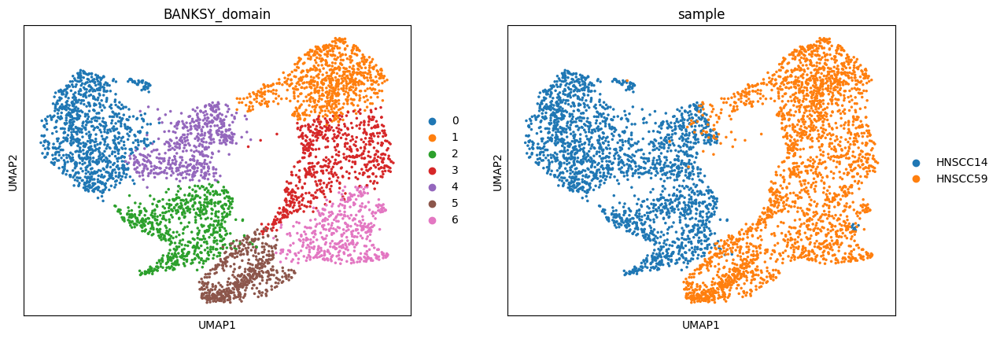

In [ ]:
sc.pl.umap(banksy_adata,
           color=["BANKSY_domain","sample"])

In [ ]:
banksy_adata.uns["spatial"] = {
    **adata.uns["spatial"]
    # **adata_2.uns["spatial"]
}

banksy_adata.obsm["spatial"] = adata.obsm["spatial"]

In [ ]:
banksy_adata

AnnData object with n_obs × n_vars = 4640 × 6000
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'log1p_total_counts_mt', 'clusters', 'leiden', 'gene_niche', 'subtype', 'x', 'y', 'x_bk', 'y_bk', 'BANKSY_domain'
    var: 'gene_ids', 'feature_types', 'genome', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'is_nbr', 'k'
    uns: 'pca', 'neighbors', 'umap', 'BANKSY_domain', 'BANKSY_domain_colors', 'sample_colors', 'spatial'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'spatial'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
    layers: None (.X)

/tmp/ipykernel_1770/1059227046.py:5: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


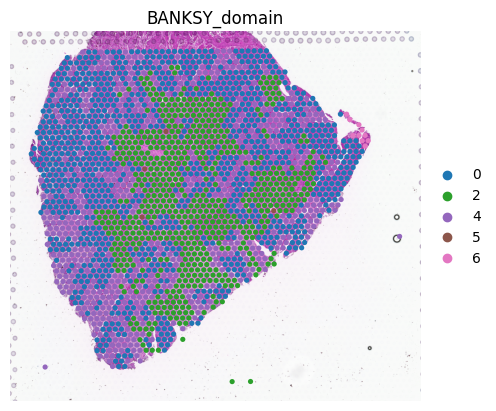

In [ ]:
slide = select_slide(banksy_adata, 'HNSCC14')
# slide.obsm["spatial"] = (
#     adata_1.obsm["spatial"].copy()
# )
sc.pl.spatial(
        slide,
        cmap='RdBu_r',
        color=["BANKSY_domain"],
        ncols=1, size=1.3,
        img_key='hires',
        vmin=0, vmax='p99.2',
        colorbar_loc=None,
        frameon=False,
    )

/tmp/ipykernel_1770/3693350063.py:5: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


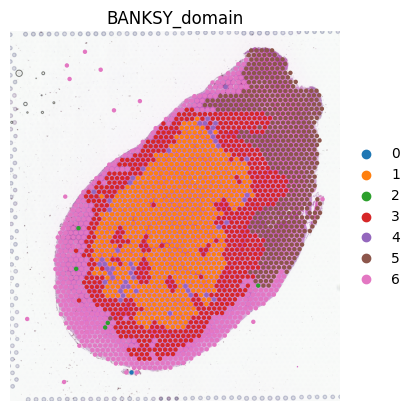

In [ ]:
slide = select_slide(banksy_adata, 'HNSCC59')
# slide.obsm["spatial"] = (
#     adata_2.obsm["spatial"].copy()
# )
sc.pl.spatial(
        slide,
        cmap='RdBu_r',
        color=["BANKSY_domain"],
        ncols=1, size=1.3,
        img_key='hires',
        vmin=0, vmax='p99.2',
        colorbar_loc=None,
        frameon=False,
    )

In [ ]:
adata.obs["BANKSY_domain"] = banksy_adata.obs["BANKSY_domain"]

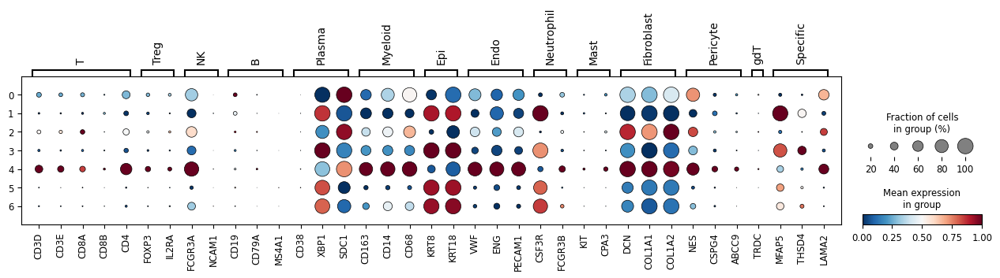

In [ ]:
marker_genes_dict = {
    "T":["CD3D","CD3E","CD8A","CD8B","CD4"],
    "Treg":["FOXP3","IL2RA"],
    "NK":["FCGR3A","NCAM1",],
    "B":["CD19","CD79A","MS4A1"],
    "Plasma":['CD38',"XBP1","SDC1"],
    "Myeloid":["CD163","CD14","CD68"],
    "Epi":["KRT8","KRT18"],
    "Endo":["VWF","ENG","PECAM1"],
    "Neutrophil":["CSF3R","FCGR3B"],
    "Mast":["KIT","CPA3"],
    "Fibroblast":["DCN","COL1A1","COL1A2"],
    "Pericyte":["NES","CSPG4","ABCC9"],
    "gdT":["TRDC"],
    "Specific":["MFAP5","THSD4","LAMA2"]

}



sc.pl.dotplot(adata, marker_genes_dict, 'BANKSY_domain', dendrogram=False, standard_scale = "var" ,edgecolor='black',cmap="RdBu_r",  # 点的边框颜色
    linewidth=0.5,)

In [ ]:
banksy_adata.write_h5ad("./visum/banksy.h5ad")

##c2l

In [ ]:
adata_ref = sc.read_h5ad("./1.rawdata/Final_rebuilt_subtype.h5ad")
adata_ref.X = adata_ref.layers['counts'].copy()

In [ ]:
mask = adata_ref.obs["celltype"].isin(["B", "Neutrophil", "Plasma"])

# 转为 object，避免 categorical 新类别赋值报错
adata_ref.obs["subtype"] = adata_ref.obs["subtype"].astype(object)
adata_ref.obs.loc[mask, "subtype"] = adata_ref.obs.loc[mask, "celltype"].astype(object)

adata_ref.obs["subtype"] = adata_ref.obs["subtype"].astype("category")

In [ ]:
# adata_ref.obs.drop(columns=["subtype_split"], inplace=True, errors="ignore")

In [ ]:
# def clean_dataframe_columns(df):
#     df = df.copy()
#     df.columns = [str(c).replace("/", "_") for c in df.columns]
#     return df

# # 清理 obsm 中所有 DataFrame 的列名
# for k in list(adata_ref.obsm.keys()):
#     obj = adata_ref.obsm[k]
#     if hasattr(obj, "columns"):
#         bad_cols = [c for c in obj.columns if "/" in str(c)]
#         if bad_cols:
#             print(f"clean obsm[{k}]")
#             print("bad cols:", bad_cols[:10])
#             adata_ref.obsm[k] = clean_dataframe_columns(obj)

# # 如果 varm 里也有 DataFrame，也一起清理
# for k in list(adata_ref.varm.keys()):
#     obj = adata_ref.varm[k]
#     if hasattr(obj, "columns"):
#         bad_cols = [c for c in obj.columns if "/" in str(c)]
#         if bad_cols:
#             print(f"clean varm[{k}]")
#             print("bad cols:", bad_cols[:10])
#             adata_ref.varm[k] = clean_dataframe_columns(obj)

clean varm[means_per_cluster_mu_fg]
bad cols: ['means_per_cluster_mu_fg_CXCL1/5+ TAM']
clean varm[stds_per_cluster_mu_fg]
bad cols: ['stds_per_cluster_mu_fg_CXCL1/5+ TAM']


In [ ]:
adata_ref.write_h5ad("./1.rawdata/Final_rebuilt_subtype.h5ad")

In [ ]:
import cell2location
from cell2location.models import RegressionModel

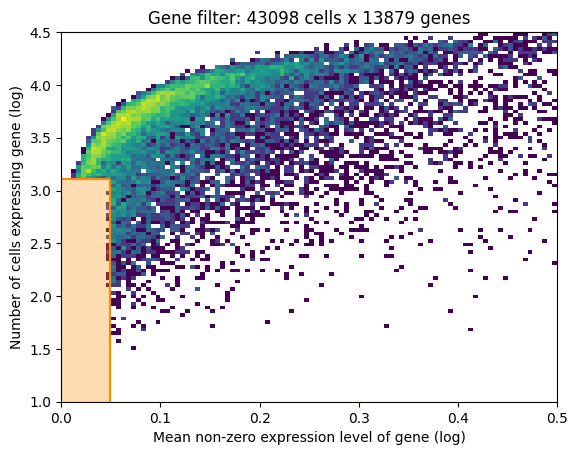

In [ ]:
from cell2location.utils.filtering import filter_genes
selected = filter_genes(adata_ref, cell_count_cutoff=5, cell_percentage_cutoff2=0.03, nonz_mean_cutoff=1.12)

# # filter the object
adata_ref = adata_ref[:, selected].copy()

In [ ]:
cell2location.models.RegressionModel.setup_anndata(adata=adata_ref,#参考数据集
      batch_key='orig.ident',#adata.obs中批次/sample列。
      labels_key='subtype',# celltype注释列
      categorical_covariate_keys=None#矫正技术因素（例如platform, 3' vs 5', donor effect）
      )

In [ ]:
from cell2location.models import RegressionModel
mod = RegressionModel(adata_ref)

In [ ]:
# view anndata_setup as a sanity check
mod.view_anndata_setup()

Anndata setup with scvi-tools version 1.5.1.

Setup via `RegressionModel.setup_anndata` with arguments:

{
│   'layer': None,
│   'batch_key': 'orig.ident',
│   'labels_key': 'subtype',
│   'categorical_covariate_keys': None,
│   'continuous_covariate_keys': None
}

         Summary Statistics         
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃     Summary Stat Key     ┃ Value ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│         n_batch          │   6   │
│         n_cells          │ 43098 │
│ n_extra_categorical_covs │   0   │
│ n_extra_continuous_covs  │   0   │
│         n_labels         │  43   │
│          n_vars          │ 13879 │
└──────────────────────────┴───────┘

               Data Registry                
┏━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Registry Key ┃    scvi-tools Location    ┃
┡━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│      X       │          adata.X          │
│    batch     │ adata.obs['_scvi_batch']  │
│    ind_x     │   adata.obs['_indices']   │
│    labels    │ adata.obs['_scvi_labels'] │
└──────────────┴───────────────────────────┘

                     batch State Registry                     
┏━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃     Source Location     ┃ Categories ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['orig.ident'] │    NO_1    │          0          │
│                         │    NO_2    │          1          │
│                         │    NO_3    │          2          │
│                         │  Smoke_1   │          3          │
│                         │  Smoke_2   │          4          │
│                         │  Smoke_3   │          5          │
└─────────────────────────┴────────────┴─────────────────────┘

                    labels State Registry                     
┏━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃   Source Location    ┃  Categories   ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['subtype'] │  Arterial_EC  │          0          │
│                      │       B       │          1          │
│                      │   Basal_Epi   │          2          │
│                      │  CAF_COL14A1  │          3          │
│                      │  CD4T_CXCL13  │          4          │
│                      │   CD4T_GZMB   │          5          │
│                      │  CD4T_PTPRC   │          6          │
│                      │  CD4T_naive   │          7          │
│                      │  CD8T_CXCL13  │          8          │
│                      │   CD8T_GZMA   │          9          │
│                      │   CD8T_GZMK   │         10          │
│                      │  CD8T_naive   │         11          │
│                      │   CD8T_str    │         12          │
│                      │ Capillary_EC  │         13          │
│                      │  Cycling_CAF  │         14          │
│                      │  Cycling_EC   │         15          │
│                      │   Cycling_T   │         16          │
│                      │   Diff_Epi    │         17          │
│                      │   EC_ACKR1    │         18          │
│                      │    EC_PGF     │         19          │
│                      │ EMT_like_Epi  │         20          │
│                      │  Hypoxia_Epi  │         21          │
│                      │   Mac_CXCL5   │         22          │
│                      │   Mac_FOLR2   │         23          │
│                      │   Mac_SPP1    │         24          │
│                      │     Mast      │         25          │
│                      │   Mono_FCN1   │         26          │
│                      │      NK       │         27          │
│                      │  Neutrophil   │         28          │
│                      │  Normal_Epi   │         29          │
│                      │    Plasma     │         30          │
│                      │  Prolif_Epi   │         31          │
│                      │ Stem_like_Epi │         32          │
│                      │    Str_Epi    │         33          │
│                      │     Treg      │         34          │
│                      │    Unknown    │         35          │
│                      │     apCAF     │         36          │
│                      │  iCAF_CXCL1   │         37          │
│                      │  iCAF_CXCL8   │         38          │
│                      │    mregDC     │         39          │
│                      │ myCAF_CTHRC1  │         40          │
│                      │     qCAF      │         41          │
│                      │      qEC      │         42          │
└──────────────────────┴───────────────┴─────────────────────┘

In [ ]:
mod.train(max_epochs=1000,accelerator="cuda")

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/configuration_validator.py:68: You passed in a `val_dataloader` but have no `validation_step`. Skipping val loop.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:

Training:   0%|          | 0/1000 [00:00<?, ?it/s]

INFO: `Trainer.fit` stopped: `max_epochs=1000` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=1000` reached.


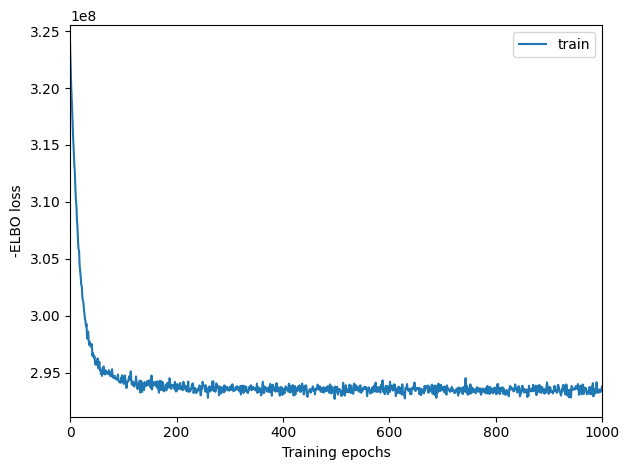

In [ ]:
mod.plot_history()

In [ ]:
# In this section, we export the estimated cell abundance (summary of the posterior distribution).
adata_ref = mod.export_posterior(
    adata_ref, sample_kwargs={'num_samples': 1000, 'batch_size': 2500, 'accelerator': 'cuda'}
)
adata_ref = mod.export_posterior(
    adata_ref, use_quantiles=True,
    # choose quantiles
    add_to_varm=["q05","q50", "q95", "q0001"],
    sample_kwargs={'batch_size': 2500, 'accelerator': 'cuda'}
)
# Save model
mod.save("./visum/reference_signatures/mob_train", overwrite=True)

# Save anndata object with results
adata_ref.write("./visum/sc_cell2location_new.h5ad")

Sampling local variables, batch:   0%|          | 0/18 [00:00<?, ?it/s]

Sampling global variables, sample:   0%|          | 0/999 [00:00<?, ?it/s]

In [ ]:
#模型和输出的h5ad，可以像这样加载:
adata_ref = sc.read_h5ad("./visum/sc_cell2location.h5ad")
mod = cell2location.models.RegressionModel.load("./visum/reference_signatures/mob_train", adata_ref)

In [ ]:
# export estimated expression in each cluster
if 'means_per_cluster_mu_fg' in adata_ref.varm.keys():
    inf_aver = adata_ref.varm['means_per_cluster_mu_fg'][[f'means_per_cluster_mu_fg_{i}'
                                    for i in adata_ref.uns['mod']['factor_names']]].copy()
else:
    inf_aver = adata_ref.var[[f'means_per_cluster_mu_fg_{i}'
                                    for i in adata_ref.uns['mod']['factor_names']]].copy()
inf_aver.columns = adata_ref.uns['mod']['factor_names']
inf_aver.iloc[0:5, 0:15]

          Arterial_EC         B  Basal_Epi  CAF_COL14A1  CD4T_CXCL13  \
gene_id                                                                
A1BG-AS1     0.017364  0.023711   0.022570     0.097801     0.027562   
A2M         26.088017  0.010365   0.016559     0.246050     0.010282   
A2ML1        0.006808  0.002859   0.173050     0.008345     0.005050   
A4GALT       1.269571  0.005247   1.062093     0.314639     0.003898   
AAAS         0.147089  0.033242   0.395588     0.238288     0.035930   

          CD4T_GZMB  CD4T_PTPRC  CD4T_naive  CD8T_CXCL13  CD8T_GZMA  \
gene_id                                                               
A1BG-AS1   0.038703    0.033619    0.017437     0.041079   0.019227   
A2M        0.005223    0.039902    0.016322     0.004139   0.170173   
A2ML1      0.003306    0.005917    0.002189     0.000977   0.001078   
A4GALT     0.001315    0.002898    0.001182     0.002775   0.002775   
AAAS       0.060094    0.099452    0.039993     0.050738   0.044345  

In [ ]:
adata=sc.read_h5ad("./visum/st.h5ad")

In [ ]:
# find shared genes and subset both anndata and reference signatures
intersect = np.intersect1d(adata.var_names, inf_aver.index)
adata = adata[:, intersect].copy()
inf_aver = inf_aver.loc[intersect, :].copy()

# prepare anndata for cell2location model
cell2location.models.Cell2location.setup_anndata(adata=adata,layer="counts",batch_key="sample" )

In [ ]:
# create and train the model
mod = cell2location.models.Cell2location(
    adata, cell_state_df=inf_aver,
    # the expected average cell abundance: tissue-dependent
    # hyper-prior which can be estimated from paired histology:
    N_cells_per_location=30,
    # hyperparameter controlling normalisation of
    # within-experiment variation in RNA detection:
    detection_alpha=20
)
mod.view_anndata_setup()

Anndata setup with scvi-tools version 1.5.1.

Setup via `Cell2location.setup_anndata` with arguments:

{
│   'layer': 'counts',
│   'batch_key': 'sample',
│   'labels_key': None,
│   'categorical_covariate_keys': None,
│   'continuous_covariate_keys': None
}

         Summary Statistics         
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃     Summary Stat Key     ┃ Value ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│         n_batch          │   2   │
│         n_cells          │ 4640  │
│ n_extra_categorical_covs │   0   │
│ n_extra_continuous_covs  │   0   │
│         n_labels         │   1   │
│          n_vars          │ 12179 │
└──────────────────────────┴───────┘

               Data Registry                
┏━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Registry Key ┃    scvi-tools Location    ┃
┡━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│      X       │  adata.layers['counts']   │
│    batch     │ adata.obs['_scvi_batch']  │
│    ind_x     │   adata.obs['_indices']   │
│    labels    │ adata.obs['_scvi_labels'] │
└──────────────┴───────────────────────────┘

                   batch State Registry                   
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃   Source Location   ┃ Categories ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['sample'] │  HNSCC14   │          0          │
│                     │  HNSCC59   │          1          │
└─────────────────────┴────────────┴─────────────────────┘

                     labels State Registry                      
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃      Source Location      ┃ Categories ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['_scvi_labels'] │     0      │          0          │
└───────────────────────────┴────────────┴─────────────────────┘

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/configuration_validator.py:68: You passed in a `val_dataloader` but have no `validation_step`. Skipping val loop.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:

Training:   0%|          | 0/30000 [00:00<?, ?it/s]

INFO: `Trainer.fit` stopped: `max_epochs=30000` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=30000` reached.


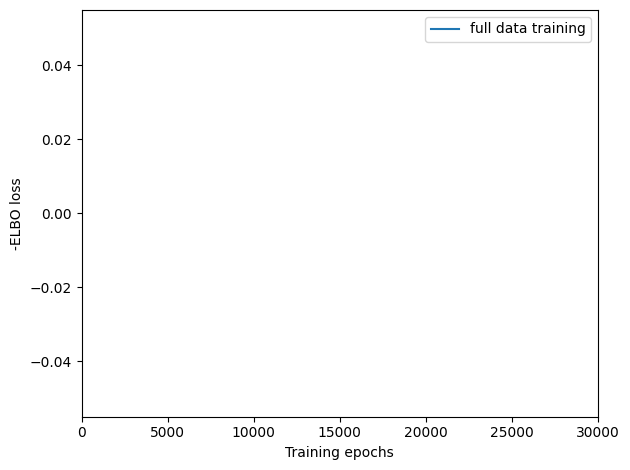

In [ ]:
mod.train(max_epochs=30000,
          # train using full data (batch_size=None)
          batch_size=None,
          # use all data points in training because
          # we need to estimate cell abundance at all locations
          train_size=1,
          accelerator="cuda"         )

# plot ELBO loss history during training, removing first 100 epochs from the plot
mod.plot_history(30000)
plt.legend(labels=['full data training']);

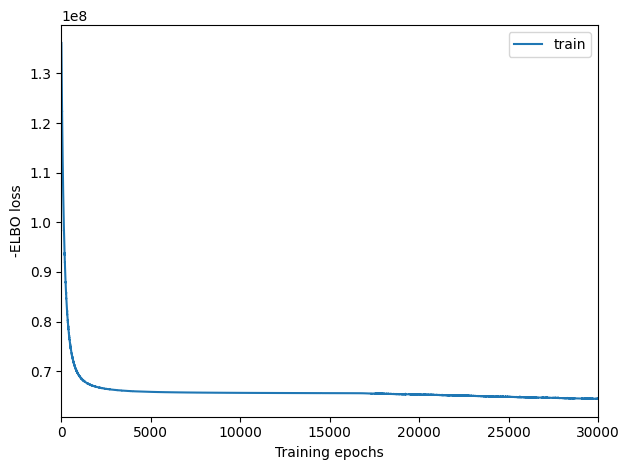

In [ ]:
mod.plot_history()

###导出

In [ ]:
# In this section, we export the estimated cell abundance (summary of the posterior distribution).
adata = mod.export_posterior(
    adata, sample_kwargs={'num_samples': 1000, 'batch_size': mod.adata.n_obs, 'accelerator': 'cuda'}
)

# Save model
mod.save("./visum/reference_signatures/mod_pred_new", overwrite=True)

# Save anndata object with results
adata.write("./visum/st.h5ad")

Sampling local variables, batch:   0%|          | 0/1 [00:00<?, ?it/s]

Sampling global variables, sample:   0%|          | 0/999 [00:00<?, ?it/s]

In [ ]:
adata = mod.export_posterior(
    adata, sample_kwargs={'num_samples': 1000, 'batch_size': mod.adata.n_obs, 'accelerator': 'cuda'}
)

Sampling local variables, batch:   0%|          | 0/1 [00:00<?, ?it/s]

Sampling global variables, sample:   0%|          | 0/999 [00:00<?, ?it/s]

In [ ]:
def clean_dataframe_columns(df):
    df = df.copy()
    df.columns = [str(c).replace("/", "_") for c in df.columns]
    return df

# 清理 obsm 中所有 DataFrame 的列名
for k in list(adata.obsm.keys()):
    obj = adata.obsm[k]
    if hasattr(obj, "columns"):
        bad_cols = [c for c in obj.columns if "/" in str(c)]
        if bad_cols:
            print(f"clean obsm[{k}]")
            print("bad cols:", bad_cols[:10])
            adata.obsm[k] = clean_dataframe_columns(obj)

# 如果 varm 里也有 DataFrame，也一起清理
for k in list(adata.varm.keys()):
    obj = adata.varm[k]
    if hasattr(obj, "columns"):
        bad_cols = [c for c in obj.columns if "/" in str(c)]
        if bad_cols:
            print(f"clean varm[{k}]")
            print("bad cols:", bad_cols[:10])
            adata.varm[k] = clean_dataframe_columns(obj)

# 再保存
adata.write_h5ad("./visum//st.h5ad")

clean obsm[q05_cell_abundance_w_sf]
bad cols: ['CXCL1/5+ TAM']


ValueError: Forward slashes are not allowed in keys in <class 'h5py._hl.group.Group'>

In [ ]:
# adata.obs["CXCL1_5+ TAM"] = adata.obs["CXCL1/5+ TAM"]
# adata.obs.drop(columns=["CXCL1/5+ TAM"], inplace=True)

In [ ]:
adata.write_h5ad("./visum//st.h5ad")

In [ ]:
adata_st = sc.read_h5ad("./visum//st.h5ad")
mod = cell2location.models.Cell2location.load("./visum/reference_signatures/mod_pred", adata_st)

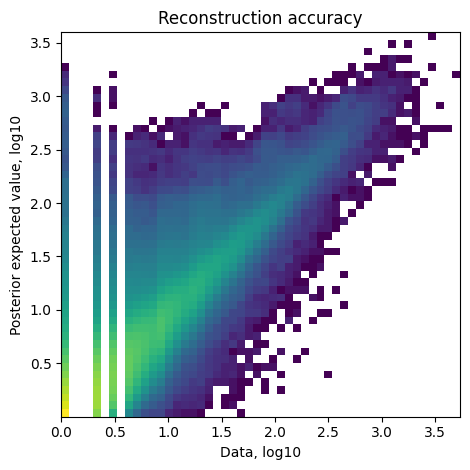

In [ ]:
mod.plot_QC()

In [ ]:
pd.DataFrame(adata.obsm['q05_cell_abundance_w_sf']).to_csv("./visum/st_cell2location_res_new.csv")

In [ ]:
pd.DataFrame(adata.obsm['q05_cell_abundance_w_sf'])

                                    Arterial_EC         B  Basal_Epi  \
HNSCC14_HNSCC14_AAACAATCTACTAGCA-1     0.008079  0.030580   2.477014   
HNSCC14_HNSCC14_AAACAGAGCGACTCCT-1     0.000478  0.011913   2.256019   
HNSCC14_HNSCC14_AAACCGGGTAGGTACC-1     0.116977  0.019368   2.644791   
HNSCC14_HNSCC14_AAACCGTTCGTCCAGG-1     0.066176  0.279103   0.124850   
HNSCC14_HNSCC14_AAACCTCATGAAGTTG-1     0.049649  0.117733   0.804105   
...                                         ...       ...        ...   
HNSCC59_HNSCC59_TTGTTGTGTGTCAAGA-1     0.023494  0.225296   7.019543   
HNSCC59_HNSCC59_TTGTTTCACATCCAGG-1     0.026259  0.149612   4.538115   
HNSCC59_HNSCC59_TTGTTTCATTAGTCTA-1     0.007824  0.009433   0.007851   
HNSCC59_HNSCC59_TTGTTTCCATACAACT-1     0.040483  0.246646   8.550743   
HNSCC59_HNSCC59_TTGTTTGTATTACACG-1     0.000014  0.000160   0.000072   

                                    CAF_COL14A1  CD4T_CXCL13  CD4T_GZMB  \
HNSCC14_HNSCC14_AAACAATCTACTAGCA-1     0.092287     0.059782

In [ ]:
# 找到起止列
cols = adata.obs.columns.tolist()

start = cols.index("Activated EC")
end = cols.index("CXCL1_5+ TAM")

# 包含两端
delete_cols = cols[start:end+1]

# 删除
adata.obs.drop(columns=delete_cols, inplace=True)

print(f"删除 {len(delete_cols)} 个c2l subtype列")
print(delete_cols)

ValueError: 'Activated EC' is not in list

In [ ]:
adata = sc.read_h5ad("./visum//st.h5ad")
print(adata)

AnnData object with n_obs × n_vars = 4640 × 12120
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'log1p_total_counts_mt', 'clusters', 'leiden', 'gene_niche', 'subtype', '_indices', '_scvi_batch', '_scvi_labels', 'Program_1', 'Program_2', 'Program_3', 'Program_4', 'Program_5', 'Program_6', 'Program_7', 'LAMA2_positive', 'LAMA2_expr', 'Arterial_EC', 'B', 'Basal_Epi', 'CAF_COL14A1', 'CD4T_CXCL13', 'CD4T_GZMB', 'CD4T_PTPRC', 'CD4T_naive', 'CD8T_CXCL13', 'CD8T_GZMA', 'CD8T_GZMK', 'CD8T_naive', 'CD8T_str', 'Capillary_EC', 'Cycling_CAF', 'Cycling_EC', 'Cycling_T', 'Diff_Epi', 'EC_ACKR1', 'EC_PGF', 'EMT_like_Epi', 'Hypoxia_Epi', 'Mac_CXCL5', 'Mac_FOLR2', 'Mac_SPP1', 'Mast', 'Mono_FCN1', 'NK', 'Neutrophil', 'Normal_Epi', 'Plasma', 'Prolif_Epi'

In [ ]:
c2l = pd.read_csv(
    "./visum/st_cell2location_res_subtype_intecaf.csv",   # 修改为实际路径
    index_col=0,
)

In [62]:
import pandas as pd
import numpy as np

# 1. 读取之前保存的 cell2location 结果
c2l = pd.read_csv(
    "./visum/st_cell2location_res_subtype_intecaf.csv",   # 修改为实际路径
    index_col=0,
)

c2l.index = c2l.index.astype(str)

# 去掉细胞类型列名前的 c2l 前缀
# 例如 q05cell_abundance_w_sf_CAF_IL11 → CAF_IL11
c2l.columns = c2l.columns.str.replace(
    r"^q05_?cell_abundance_w_sf_",
    "",
    regex=True,
)

import re
import numpy as np
import pandas as pd

# 1. 清理连续重复的样本前缀，保留一份
def clean_spot_name(name):
    return re.sub(r"^([^_]+_)(?:\1)+", r"\1", str(name).strip())

adata_match = pd.Index([clean_spot_name(x) for x in adata.obs_names])

c2l_match = c2l.copy()
c2l_match.index = pd.Index([
    clean_spot_name(x) for x in c2l_match.index
])

# 2. 防止清理后出现重复名称，造成错误匹配
if not adata_match.is_unique:
    raise ValueError("adata 的匹配名称清理后有重复，请检查。")

if not c2l_match.index.is_unique:
    raise ValueError("CSV 的匹配名称清理后有重复，请检查。")

missing = adata_match.difference(c2l_match.index)

print(f"匹配成功：{len(adata_match) - len(missing)} / {adata.n_obs}")

if len(missing) > 0:
    print("adata 未匹配示例：", missing[:5].tolist())
    print("CSV 名称示例：", c2l_match.index[:5].tolist())
    raise ValueError("仍有未匹配 spot，请检查以上名称。")

# 3. 按 adata 的顺序提取旧结果
c2l_new = c2l_match.loc[adata_match].copy()

# 恢复为 adata 的原始名称，确保 obsm/obs 索引一致
c2l_new.index = adata.obs_names.copy()
c2l_new = c2l_new.apply(pd.to_numeric, errors="raise")
unknown_cols = [
    c for c in c2l_new.columns
    if "unknown" in str(c).lower()
]

print("删除Unknown列:", unknown_cols)

c2l_new = c2l_new.drop(
    columns=unknown_cols,
    errors="ignore"
)
if (
    not np.isfinite(c2l_new.to_numpy()).all()
    or (c2l_new.to_numpy() < 0).any()
):
    raise ValueError("c2l 结果存在缺失值、无穷值或负值。")

# 4. 写入
adata.obsm["q05_cell_abundance_w_sf"] = c2l_new.copy()
adata.obs[c2l_new.columns] = c2l_new

print("写入完成：", c2l_new.shape)

匹配成功：4640 / 4640
删除Unknown列: []
写入完成： (4640, 41)


In [ ]:
adata.write_h5ad("./visum//st.h5ad")

In [ ]:
adata.write_h5ad("./visum/st.h5ad")

In [63]:
import numpy as np
import pandas as pd
from scipy import sparse

x = adata.obsm["q05_cell_abundance_w_sf"]

if isinstance(x, pd.DataFrame):
    # 总丰度为 0 的 spot 保留为全 0
    prop = x.div(x.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)
elif sparse.issparse(x):
    totals = np.asarray(x.sum(axis=1)).ravel()
    inv = np.divide(
        1.0, totals,
        out=np.zeros_like(totals, dtype=float),
        where=totals != 0
    )
    prop = sparse.diags(inv).dot(x).tocsr()
else:
    x = np.asarray(x)
    totals = x.sum(axis=1, keepdims=True)
    prop = np.divide(
        x, totals,
        out=np.zeros_like(x, dtype=float),
        where=totals != 0
    )

adata.obsm["q05_cell_abundance_w_sf_norm"] = prop

# 检查：非零 spot 的行总和应约为 1
print(np.asarray(prop.sum(axis=1)).ravel()[:10])

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [64]:
# adata.obs[adata.uns['mod']['factor_names']] = adata.obsm['q05_cell_abundance_w_sf']
# adata.obs[adata.uns['mod']['factor_names']] = adata.obsm['q05_cell_abundance_w_sf_norm']
import pandas as pd

norm = adata.obsm["q05_cell_abundance_w_sf_norm"]

# 前面导入的原始 c2l 矩阵已包含细胞类型列名
celltypes = adata.obsm["q05_cell_abundance_w_sf_norm"].columns.tolist()

if isinstance(norm, pd.DataFrame):
    # 按 spot 和细胞类型名称对齐
    norm_df = norm.loc[adata.obs_names, celltypes].copy()
else:
    # 数组的列顺序应与原始 c2l 矩阵一致
    norm_df = pd.DataFrame(
        norm,
        index=adata.obs_names,
        columns=celltypes,
    )

# 写入 obs；同名列会更新为归一化后的值
adata.obs[celltypes] = norm_df

print(adata.obs[celltypes].head())

                            Arterial_EC         B  Basal_Epi  CD4T_CXCL13  \
HNSCC14_AAACAATCTACTAGCA-1     0.000801  0.003781   0.293699     0.006710   
HNSCC14_AAACAGAGCGACTCCT-1     0.000060  0.001894   0.268427     0.003643   
HNSCC14_AAACCGGGTAGGTACC-1     0.015821  0.002476   0.299813     0.015370   
HNSCC14_AAACCGTTCGTCCAGG-1     0.003937  0.018025   0.009319     0.002829   
HNSCC14_AAACCTCATGAAGTTG-1     0.006792  0.014905   0.068544     0.003278   

                            CD4T_GZMB  CD4T_PTPRC  CD4T_naive  CD8T_CXCL13  \
HNSCC14_AAACAATCTACTAGCA-1   0.006107    0.005857    0.006837     0.009247   
HNSCC14_AAACAGAGCGACTCCT-1   0.001836    0.018106    0.002727     0.001275   
HNSCC14_AAACCGGGTAGGTACC-1   0.006358    0.007468    0.007183     0.007109   
HNSCC14_AAACCGTTCGTCCAGG-1   0.017659    0.002315    0.020439     0.058017   
HNSCC14_AAACCTCATGAAGTTG-1   0.005227    0.001453    0.008285     0.012809   

                            CD8T_GZMA  CD8T_GZMK  ...  Stem_like_Epi

In [ ]:
# adata.uns["spatial"] = {
#     **adata_1.uns["spatial"],
#     **adata_2.uns["spatial"]
# }

In [ ]:
adata.X =adata.layers["counts"].copy()

In [ ]:
sc.pp.normalize_total(
    adata,
    target_sum=1e4
)

sc.pp.log1p(adata)

### plot

In [57]:
adata=sc.read_h5ad("./visum/st.h5ad")

In [ ]:
print(adata.X)

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 26109550 stored elements and shape (4640, 12179)>
  Coords	Values
  (0, 6830)	1.4066987037658691
  (0, 7691)	0.414585143327713
  (0, 4530)	1.1167699098587036
  (0, 5078)	1.1167699098587036
  (0, 312)	1.272205114364624
  (0, 10752)	0.414585143327713
  (0, 9034)	1.7269868850708008
  (0, 945)	0.7067962288856506
  (0, 11221)	1.4066987037658691
  (0, 104)	0.9326474070549011
  (0, 5010)	1.5252294540405273
  (0, 2349)	0.414585143327713
  (0, 3030)	0.7067962288856506
  (0, 6455)	0.7067962288856506
  (0, 927)	2.7662270069122314
  (0, 1639)	1.4066987037658691
  (0, 11513)	0.7067962288856506
  (0, 9929)	1.5252294540405273
  (0, 6163)	1.4066987037658691
  (0, 9456)	0.7067962288856506
  (0, 6530)	0.414585143327713
  (0, 4192)	1.8947925567626953
  (0, 8011)	0.414585143327713
  (0, 3488)	0.9326474070549011
  (0, 9309)	0.7067962288856506
  :	:
  (4639, 6407)	0.32953399419784546
  (4639, 1922)	0.32953399419784546
  (4639, 11883)	1.9249492883

In [ ]:
adata.raw=adata.copy()

In [ ]:
adata.X =adata.layers["counts"].copy()

/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()


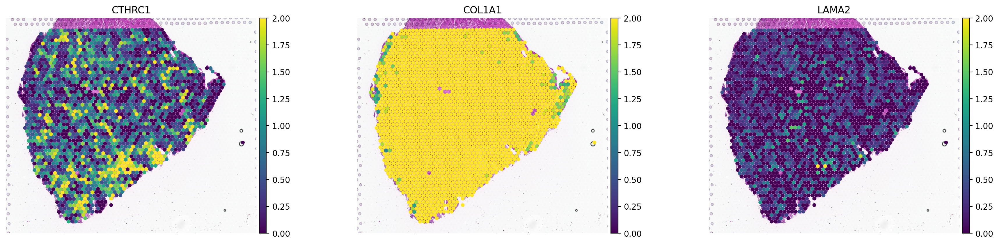

In [40]:
sc.pl.spatial(
    adata[adata.obs["sample"]=="HNSCC14"],
    color=["CTHRC1","COL1A1","LAMA2"],
    library_id="HNSCC14",
    # cmap="magma",
    img_key="hires",
    spot_size =120,
    vmin=0, vmax='2'

)

/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()


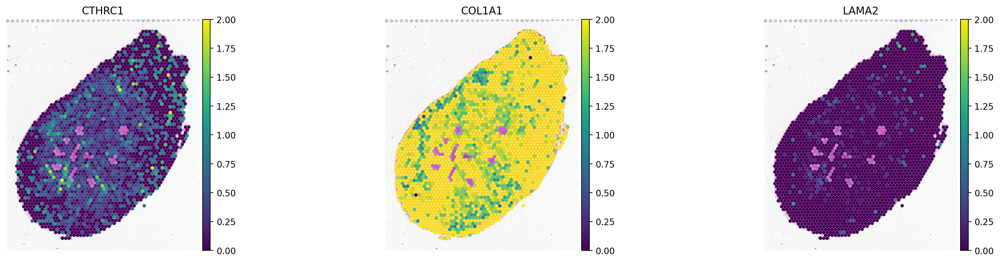

In [41]:
sc.pl.spatial(
    adata[adata.obs["sample"]=="HNSCC59"],
    color=["CTHRC1","COL1A1","LAMA2"],
    library_id="HNSCC59",
    # cmap="magma",#RdBu_r
    img_key="hires",
    spot_size =120,
    vmin=0, vmax='2'
)

LAMA2 颜色范围：0–1.2516


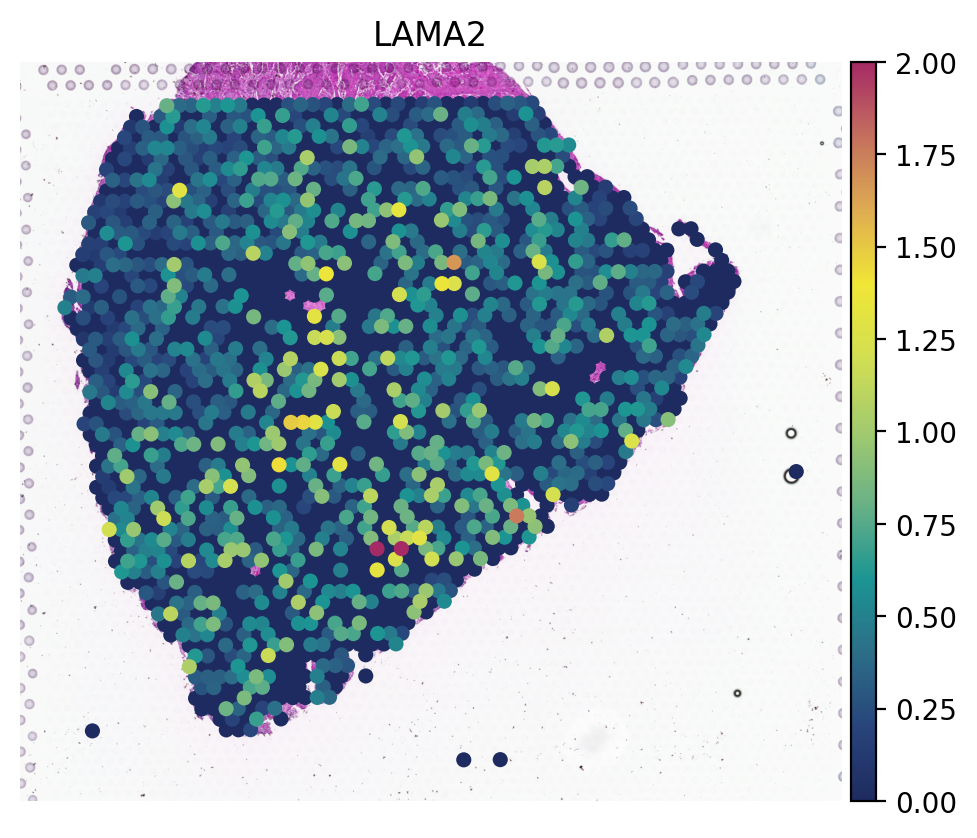

保存完成：
visum/figure/st_situ_figure/HNSCC14_LAMA2_spatial.tiff
visum/figure/st_situ_figure/HNSCC14_LAMA2_spatial.png


In [67]:
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# =========================
# 1. 参数
# =========================
SAMPLE = "HNSCC14"
GENE = "LAMA2"

# 输出目录
outdir = Path("./visum/figure/st_situ_figure")
outdir.mkdir(parents=True, exist_ok=True)

# 当前切片
adata_HNSCC14 = adata[adata.obs["sample"] == SAMPLE].copy()

# =========================
# 2. 检查基因是否存在
# =========================
if adata_HNSCC14.raw is not None and GENE in adata_HNSCC14.raw.var_names:
    use_raw = True
    expr = adata_HNSCC14.raw[:, GENE].X
else:
    use_raw = False
    if GENE not in adata_HNSCC14.var_names:
        raise ValueError(f"{GENE} 不在 adata.var_names 或 adata.raw.var_names 中")
    expr = adata_HNSCC14[:, GENE].X

# 转成一维数组
if hasattr(expr, "toarray"):
    expr = expr.toarray().ravel()
else:
    expr = np.asarray(expr).ravel()

expr = expr[np.isfinite(expr)]

if expr.size == 0:
    raise ValueError(f"{GENE} 没有有效表达值")

# =========================
# 3. 统一颜色范围
# =========================
common_vmax = np.percentile(expr, 99.2)
if common_vmax <= 0:
    common_vmax = expr.max() if expr.max() > 0 else 1.0

print(f"{GENE} 颜色范围：0–{common_vmax:.4f}")

# =========================
# 4. 绘图
# =========================
fig = sc.pl.spatial(
    adata_HNSCC14,
    library_id=SAMPLE,
    color=[GENE],
    spot_size=150,
    img_key="hires",
    vmin=0,
    vmax="2",   # 若你想固定也可直接改成具体数值，例如 0.4
    cmap=cmap,          # 这里沿用你前面定义好的 cmap
    frameon=False,
    use_raw=use_raw,
    return_fig=True
)

# 可选：标题改得更简洁
ax = fig.axes[0]
ax.set_title(GENE, fontsize=16)

# =========================
# 5. 保存
# =========================
tiff_path = outdir / f"{SAMPLE}_{GENE}_spatial.tiff"
png_path = outdir / f"{SAMPLE}_{GENE}_spatial.png"

fig.savefig(
    tiff_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
    pil_kwargs={"compression": "tiff_lzw"}
)

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

print("保存完成：")
print(tiff_path)
print(png_path)

plt.show()

LAMA2 颜色范围：0–0.9097


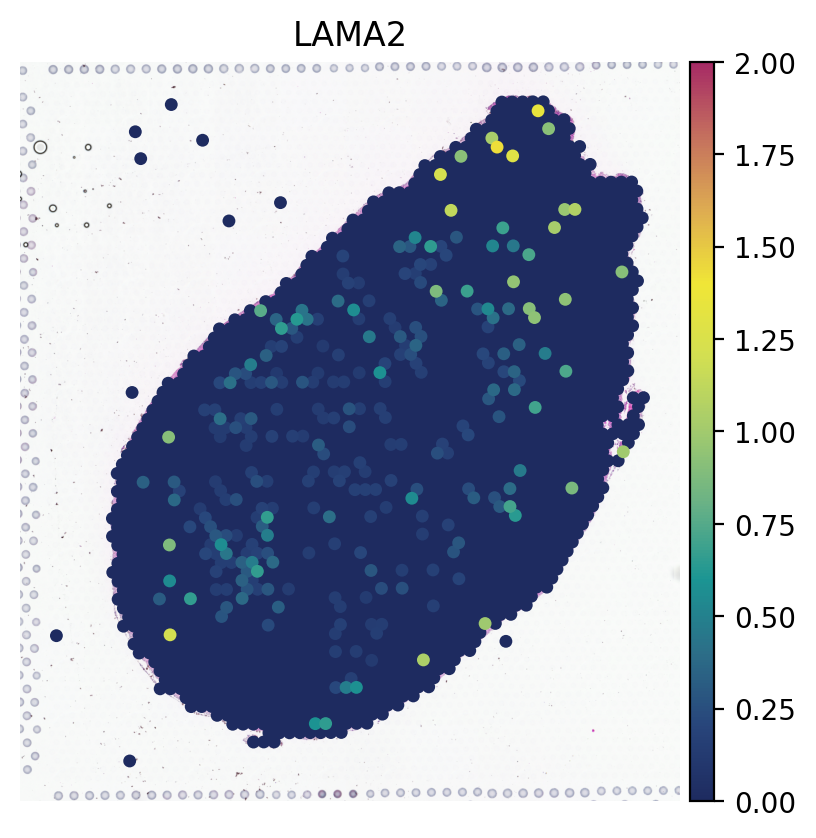

保存完成：
visum/figure/st_situ_figure/HNSCC59_LAMA2_spatial.tiff
visum/figure/st_situ_figure/HNSCC59_LAMA2_spatial.png


In [68]:
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# =========================
# 1. 参数
# =========================
SAMPLE = "HNSCC59"
GENE = "LAMA2"

# 输出目录
outdir = Path("./visum/figure/st_situ_figure")
outdir.mkdir(parents=True, exist_ok=True)

# 当前切片
adata_HNSCC14 = adata[adata.obs["sample"] == SAMPLE].copy()

# =========================
# 2. 检查基因是否存在
# =========================
if adata_HNSCC14.raw is not None and GENE in adata_HNSCC14.raw.var_names:
    use_raw = True
    expr = adata_HNSCC14.raw[:, GENE].X
else:
    use_raw = False
    if GENE not in adata_HNSCC14.var_names:
        raise ValueError(f"{GENE} 不在 adata.var_names 或 adata.raw.var_names 中")
    expr = adata_HNSCC14[:, GENE].X

# 转成一维数组
if hasattr(expr, "toarray"):
    expr = expr.toarray().ravel()
else:
    expr = np.asarray(expr).ravel()

expr = expr[np.isfinite(expr)]

if expr.size == 0:
    raise ValueError(f"{GENE} 没有有效表达值")

# =========================
# 3. 统一颜色范围
# =========================
common_vmax = np.percentile(expr, 99.2)
if common_vmax <= 0:
    common_vmax = expr.max() if expr.max() > 0 else 1.0

print(f"{GENE} 颜色范围：0–{common_vmax:.4f}")

# =========================
# 4. 绘图
# =========================
fig = sc.pl.spatial(
    adata_HNSCC14,
    library_id=SAMPLE,
    color=[GENE],
    spot_size=150,
    img_key="hires",
    vmin=0,
    vmax="2",   # 若你想固定也可直接改成具体数值，例如 0.4
    cmap=cmap,          # 这里沿用你前面定义好的 cmap
    frameon=False,
    use_raw=use_raw,
    return_fig=True
)

# 可选：标题改得更简洁
ax = fig.axes[0]
ax.set_title(GENE, fontsize=16)

# =========================
# 5. 保存
# =========================
tiff_path = outdir / f"{SAMPLE}_{GENE}_spatial.tiff"
png_path = outdir / f"{SAMPLE}_{GENE}_spatial.png"

fig.savefig(
    tiff_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
    pil_kwargs={"compression": "tiff_lzw"}
)

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

print("保存完成：")
print(tiff_path)
print(png_path)

plt.show()

In [65]:
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
from pathlib import Path

caf_types = [
    "myCAF_COL14A1",
    "Cycling_CAF",
    "iCAF_CXCL1",
    "iCAF_CXCL8",
    "myCAF_CTHRC1",
    "apCAF",
    "CAF"
]

sample = "HNSCC14"
slide = adata[adata.obs["sample"] == sample].copy()

outdir = Path("./visum/st_situ_figure") / sample
outdir.mkdir(parents=True, exist_ok=True)

# 保留存在的亚型
caf_types = [x for x in caf_types if x in slide.obs.columns]
if not caf_types:
    raise ValueError("obs 中未找到指定的 CAF 亚型")

print("绘制:", caf_types)

# 所有亚型共同计算颜色上限
values = slide.obs[caf_types].to_numpy(dtype=float)
values = values[np.isfinite(values)]

if values.size == 0:
    raise ValueError("没有可用于绘图的有效丰度值")

common_vmax = np.percentile(values, 99.2)
if common_vmax <= 0:
    common_vmax = values.max() if values.max() > 0 else 1.0

print(f"统一颜色范围：0–{common_vmax:.4f}")

# 每个亚型单独绘制、保存
for celltype in caf_types:
    fig, ax = plt.subplots(figsize=(6, 6))

    sc.pl.spatial(
        slide,
        library_id=sample,
        color=celltype,
        spot_size=150,
        img_key="hires",
        vmin=0,
        vmax="0.4",
        cmap=cmap,
        frameon=False,
        title=celltype,
        ax=ax,
        show=False,
    )

    fig.savefig(
        outdir / f"{sample}_{celltype}.tiff",
        dpi=600,
        bbox_inches="tight",
        facecolor="white",
        pil_kwargs={"compression": "tiff_lzw"},
    )

    plt.show()
    plt.close(fig)

Output hidden; open in https://colab.research.google.com to view.

In [66]:
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
from pathlib import Path

caf_types = [
    "myCAF_COL14A1",
    "Cycling_CAF",
    "iCAF_CXCL1",
    "iCAF_CXCL8",
    "myCAF_CTHRC1",
    "apCAF",
    "CAF"
]

sample = "HNSCC59"
slide = adata[adata.obs["sample"] == sample].copy()

outdir = Path("./visum/st_situ_figure") / sample
outdir.mkdir(parents=True, exist_ok=True)

# 保留存在的亚型
caf_types = [x for x in caf_types if x in slide.obs.columns]
if not caf_types:
    raise ValueError("obs 中未找到指定的 CAF 亚型")

print("绘制:", caf_types)

# 所有亚型共同计算颜色上限
values = slide.obs[caf_types].to_numpy(dtype=float)
values = values[np.isfinite(values)]

if values.size == 0:
    raise ValueError("没有可用于绘图的有效丰度值")

common_vmax = np.percentile(values, 99.2)
if common_vmax <= 0:
    common_vmax = values.max() if values.max() > 0 else 1.0

print(f"统一颜色范围：0–{common_vmax:.4f}")

# 每个亚型单独绘制、保存
for celltype in caf_types:
    fig, ax = plt.subplots(figsize=(6, 6))

    sc.pl.spatial(
        slide,
        library_id=sample,
        color=celltype,
        spot_size=150,
        img_key="hires",
        vmin=0,
        vmax="0.4",
        cmap=cmap,
        frameon=False,
        title=celltype,
        ax=ax,
        show=False,
    )

    fig.savefig(
        outdir / f"{sample}_{celltype}.tiff",
        dpi=600,
        bbox_inches="tight",
        facecolor="white",
        pil_kwargs={"compression": "tiff_lzw"},
    )

    plt.show()
    plt.close(fig)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
adata

AnnData object with n_obs × n_vars = 4640 × 12179
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'log1p_total_counts_mt', 'clusters', 'leiden', 'gene_niche', 'subtype', '_indices', '_scvi_batch', '_scvi_labels', 'Arterial_EC', 'B', 'Basal_Epi', 'CAF_COL14A1', 'CD4T_CXCL13', 'CD4T_GZMB', 'CD4T_PTPRC', 'CD4T_naive', 'CD8T_CXCL13', 'CD8T_GZMA', 'CD8T_GZMK', 'CD8T_naive', 'CD8T_str', 'Capillary_EC', 'Cycling_CAF', 'Cycling_EC', 'Cycling_T', 'Diff_Epi', 'EC_ACKR1', 'EC_PGF', 'EMT_like_Epi', 'Hypoxia_Epi', 'Mac_CXCL5', 'Mac_FOLR2', 'Mac_SPP1', 'Mast', 'Mono_FCN1', 'NK', 'Neutrophil', 'Normal_Epi', 'Plasma', 'Prolif_Epi', 'Stem_like_Epi', 'Str_Epi', 'Treg', 'Unknown', 'apCAF', 'iCAF_CXCL1', 'iCAF_CXCL8', 'mregDC', 'myCAF_CTHRC1', 'qCAF', 'qE

In [46]:
adata

AnnData object with n_obs × n_vars = 4574 × 12120
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'log1p_total_counts_mt', 'clusters', 'leiden', 'gene_niche', 'subtype', '_indices', '_scvi_batch', '_scvi_labels', 'Program_1', 'Program_2', 'Program_3', 'Program_4', 'Program_5', 'Program_6', 'Program_7', 'LAMA2_positive', 'LAMA2_expr', 'Arterial_EC', 'B', 'Basal_Epi', 'CAF_COL14A1', 'CD4T_CXCL13', 'CD4T_GZMB', 'CD4T_PTPRC', 'CD4T_naive', 'CD8T_CXCL13', 'CD8T_GZMA', 'CD8T_GZMK', 'CD8T_naive', 'CD8T_str', 'Capillary_EC', 'Cycling_CAF', 'Cycling_EC', 'Cycling_T', 'Diff_Epi', 'EC_ACKR1', 'EC_PGF', 'EMT_like_Epi', 'Hypoxia_Epi', 'Mac_CXCL5', 'Mac_FOLR2', 'Mac_SPP1', 'Mast', 'Mono_FCN1', 'NK', 'Neutrophil', 'Normal_Epi', 'Plasma', 'Prolif_Epi'

绘制: ['myCAF_COL14A1', 'Cycling_CAF', 'iCAF_CXCL1', 'iCAF_CXCL8', 'myCAF_CTHRC1', 'apCAF']
绘制: ['myCAF_COL14A1', 'Cycling_CAF', 'iCAF_CXCL1', 'iCAF_CXCL8', 'myCAF_CTHRC1', 'apCAF']
统一颜色范围：0–0.2210


/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()


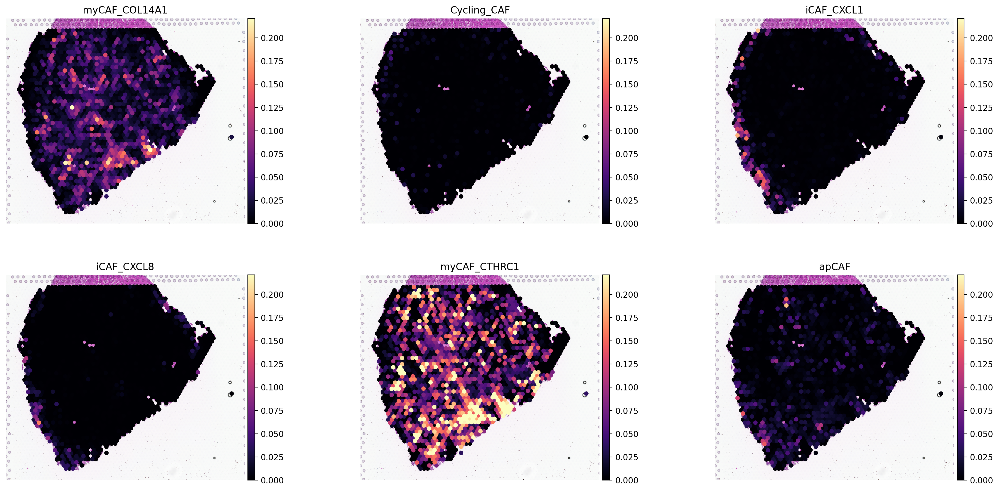

In [ ]:
import scanpy as sc
import matplotlib.pyplot as plt


# 上皮亚型
epi_types = [
    "myCAF_COL14A1",
    "Cycling_CAF",
    "iCAF_CXCL1",
    "iCAF_CXCL8",
    "myCAF_CTHRC1",
    "apCAF",
    "CAF"

]


# 当前slice
adata_HNSCC14 = adata[adata.obs["sample"]=="HNSCC14"]


# 检查存在的亚型
epi_types = [
    x for x in epi_types
    if x in adata_HNSCC14.obs.columns
]

print("绘制:", epi_types)


# 检查存在的亚型
epi_types = [
    x for x in epi_types
    if x in adata_HNSCC14.obs.columns
]

print("绘制:", epi_types)


# 所有上皮亚型共同计算颜色上限
values = adata_HNSCC14.obs[epi_types].to_numpy(dtype=float)
values = values[np.isfinite(values)]

if values.size == 0:
    raise ValueError("没有可用于绘图的有效丰度值")

common_vmax = np.percentile(values, 99.2)
if common_vmax <= 0:
    common_vmax = values.max() if values.max() > 0 else 1.0

print(f"统一颜色范围：0–{common_vmax:.4f}")

sc.pl.spatial(
    adata_HNSCC14,
    library_id="HNSCC14",
    color=epi_types,
    ncols=3,
    spot_size=150,
    img_key="hires",
    vmin=0,
    vmax=common_vmax,      # 所有面板共用相同数值
    cmap="magma"
)

绘制: ['myCAF_COL14A1', 'Cycling_CAF', 'iCAF_CXCL1', 'iCAF_CXCL8', 'myCAF_CTHRC1', 'apCAF']
绘制: ['myCAF_COL14A1', 'Cycling_CAF', 'iCAF_CXCL1', 'iCAF_CXCL8', 'myCAF_CTHRC1', 'apCAF']
统一颜色范围：0–0.0316


/tmp/ipykernel_1311/3027202076.py:52: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


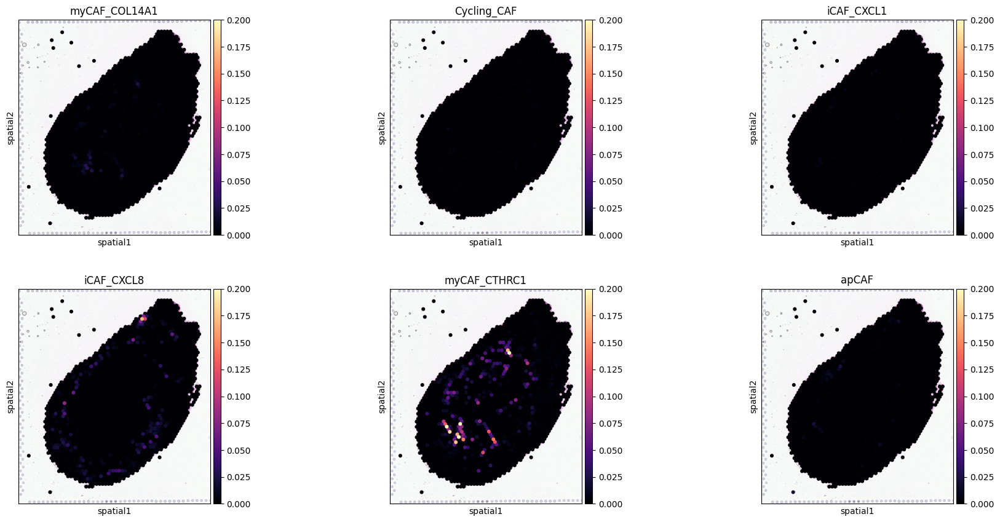

In [ ]:
import scanpy as sc
import matplotlib.pyplot as plt


# 上皮亚型
epi_types = [
    "myCAF_COL14A1",
    "Cycling_CAF",
    "iCAF_CXCL1",
    "iCAF_CXCL8",
    "myCAF_CTHRC1",
    "apCAF",

]


# 当前slice
adata_HNSCC59 = adata[adata.obs["sample"]=="HNSCC59"]


# 检查存在的亚型
epi_types = [
    x for x in epi_types
    if x in adata_HNSCC59.obs.columns
]

print("绘制:", epi_types)


# 检查存在的亚型
epi_types = [
    x for x in epi_types
    if x in adata_HNSCC59.obs.columns
]

print("绘制:", epi_types)


# 所有上皮亚型共同计算颜色上限
values = adata_HNSCC59.obs[epi_types].to_numpy(dtype=float)
values = values[np.isfinite(values)]

if values.size == 0:
    raise ValueError("没有可用于绘图的有效丰度值")

common_vmax = np.percentile(values, 99.2)
if common_vmax <= 0:
    common_vmax = values.max() if values.max() > 0 else 1.0

print(f"统一颜色范围：0–{common_vmax:.4f}")

sc.pl.spatial(
    adata_HNSCC59,
    library_id="HNSCC59",
    color=epi_types,
    ncols=3,
    spot_size=150,
    img_key="hires",
    vmin=0,
    vmax="0.2",      # 所有面板共用相同数值
    cmap="magma"
)

In [ ]:
adata

AnnData object with n_obs × n_vars = 4640 × 12179
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'log1p_total_counts_mt', 'clusters', 'leiden', 'gene_niche', 'subtype', '_indices', '_scvi_batch', '_scvi_labels', 'Arterial_EC', 'B', 'Basal_Epi', 'CAF_COL14A1', 'CD4T_CXCL13', 'CD4T_GZMB', 'CD4T_PTPRC', 'CD4T_naive', 'CD8T_CXCL13', 'CD8T_GZMA', 'CD8T_GZMK', 'CD8T_naive', 'CD8T_str', 'Capillary_EC', 'Cycling_CAF', 'Cycling_EC', 'Cycling_T', 'Diff_Epi', 'EC_ACKR1', 'EC_PGF', 'EMT_like_Epi', 'Hypoxia_Epi', 'Mac_CXCL5', 'Mac_FOLR2', 'Mac_SPP1', 'Mast', 'Mono_FCN1', 'NK', 'Neutrophil', 'Normal_Epi', 'Plasma', 'Prolif_Epi', 'Stem_like_Epi', 'Str_Epi', 'Treg', 'Unknown', 'apCAF', 'iCAF_CXCL1', 'iCAF_CXCL8', 'mregDC', 'myCAF_CTHRC1', 'qCAF', 'qE

In [ ]:
caf_genes = [
    "DCN",
    "COL1A1",
    "COL1A2",
    "COL3A1",
    "COL5A1",
    "COL5A2",
    "LUM",
    # "MFAP5",
    # "THSD4",
    # "LAMA2"
]
import scanpy as sc
# caf_genes = [
#     "ACTA2", "TAGLN", "MYL9", "TPM2", "CNN1",
#     "CTHRC1", "POSTN", "COL1A1", "COL1A2", "COL3A1",
# ]

samples = adata.obs["sample"].unique()

for sample in samples:

    idx = adata.obs["sample"] == sample

    sc.tl.score_genes(
        adata[idx],
        gene_list=caf_genes,
        score_name="CAF_score",
        random_state=42
    )

/usr/local/lib/python3.13/dist-packages/scanpy/tools/_score_genes.py:204: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[score_name] = pd.Series(
/usr/local/lib/python3.13/dist-packages/scanpy/tools/_score_genes.py:204: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[score_name] = pd.Series(


In [ ]:
adata.obs["CAF_score"] = 0.0


for sample in adata.obs["sample"].unique():

    sub = adata[adata.obs["sample"]==sample].copy()

    sc.tl.score_genes(
        sub,
        gene_list=caf_genes,
        score_name="CAF_score",
        random_state=42
    )

    adata.obs.loc[
        sub.obs_names,
        "CAF_score"
    ] = sub.obs["CAF_score"]

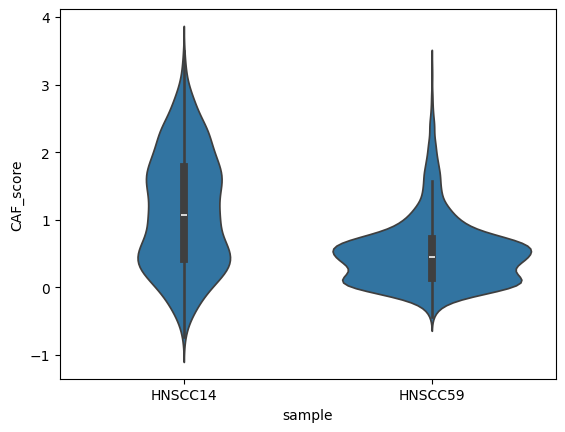

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt


sns.violinplot(
    data=adata.obs,
    x="sample",
    y="CAF_score"
)

plt.show()

In [ ]:
caf_range = adata.obs["CAF_score"].quantile([0.01,0.99])

vmin = caf_range.loc[0.01]
vmax = caf_range.loc[0.99]

print(vmin, vmax)

-0.3597077522497802 2.833817853717575


/tmp/ipykernel_15450/1671641339.py:1: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()


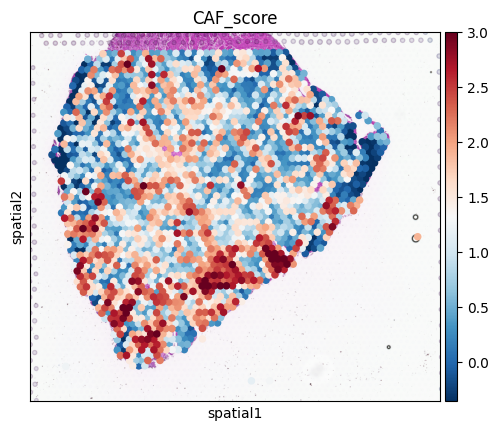

In [ ]:
sc.pl.spatial(
    adata[adata.obs["sample"]=="HNSCC14"],
    color="CAF_score",
    library_id="HNSCC14",
    img_key="hires",
    spot_size=150,
    cmap="RdBu_r",
    vmin=vmin,
    vmax="3"
)

/tmp/ipykernel_15450/4133690576.py:1: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


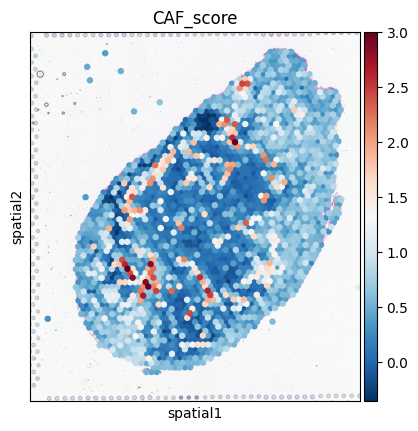

In [ ]:
sc.pl.spatial(
    adata[adata.obs["sample"]=="HNSCC59"],
    color="CAF_score",
    library_id="HNSCC59",
    img_key="hires",
    spot_size=150,
    cmap="RdBu_r",
    vmin=vmin,
    vmax="3"
)

In [ ]:
adata.X = adata.layers["counts"].copy()
sc.pp.normalize_total(
    adata,
    target_sum=1e4
)

sc.pp.log1p(adata)

In [ ]:
adata

AnnData object with n_obs × n_vars = 4640 × 12179
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'log1p_total_counts_mt', 'clusters', 'leiden', 'gene_niche', 'subtype', '_indices', '_scvi_batch', '_scvi_labels', 'Arterial_EC', 'B', 'Basal_Epi', 'CAF_COL14A1', 'CD4T_CXCL13', 'CD4T_GZMB', 'CD4T_PTPRC', 'CD4T_naive', 'CD8T_CXCL13', 'CD8T_GZMA', 'CD8T_GZMK', 'CD8T_naive', 'CD8T_str', 'Capillary_EC', 'Cycling_CAF', 'Cycling_EC', 'Cycling_T', 'Diff_Epi', 'EC_ACKR1', 'EC_PGF', 'EMT_like_Epi', 'Hypoxia_Epi', 'Mac_CXCL5', 'Mac_FOLR2', 'Mac_SPP1', 'Mast', 'Mono_FCN1', 'NK', 'Neutrophil', 'Normal_Epi', 'Plasma', 'Prolif_Epi', 'Stem_like_Epi', 'Str_Epi', 'Treg', 'Unknown', 'apCAF', 'iCAF_CXCL1', 'iCAF_CXCL8', 'mregDC', 'myCAF_CTHRC1', 'qCAF', 'qE

实际评分基因： ['ACTA2', 'TAGLN', 'MYL9', 'TPM2', 'CNN1', 'CTHRC1', 'POSTN', 'COL1A1', 'COL1A2', 'COL3A1']
数据中缺失的 marker： []
从评分集排除的目标基因： []

用于相关性分析的 spot 数：
sample
HNSCC14    2213
HNSCC59    2427
dtype: int64

基因与 myCAFscore 的相关性：
 gene  sample  n_spots     rho   p_value     p_adj
LAMA2 HNSCC14     2213 0.09099 1.811e-05 1.811e-05
LAMA2 HNSCC59     2427  0.1524 4.337e-14 8.674e-14


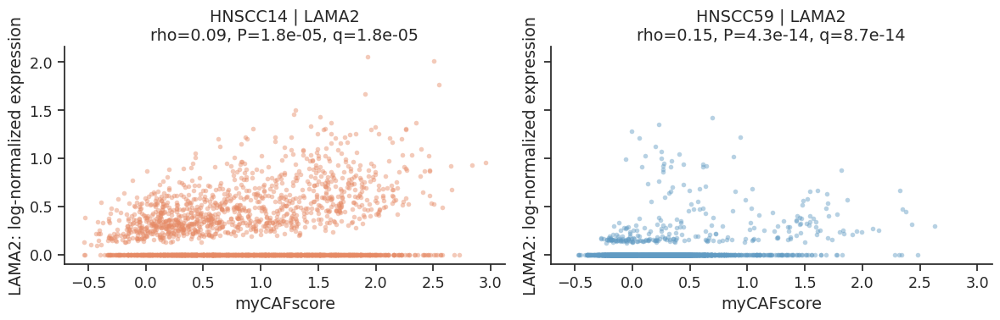

In [ ]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import scanpy as sc
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

# =====================================================
# 1. 参数：修改这里即可
# =====================================================
GENES = ["LAMA2"]  # 可改为 ["LAMA2", "THSD4", "MFAP5", "COL2A1"]

MYCAF_GENES = [
    "ACTA2", "TAGLN", "MYL9", "TPM2", "CNN1",
    "CTHRC1", "POSTN", "COL1A1", "COL1A2", "COL3A1",
]

SAMPLES = ["HNSCC14", "HNSCC59"]
LAYER = None           # None 使用 X；也可指定归一化表达 layer
SCORE_COL = "myCAFscore"

PALETTE = {
    "HNSCC14": "#E68A65",
    "HNSCC59": "#619BC3",
}

if not adata.var_names.is_unique:
    raise ValueError("基因名不唯一，请先检查。")

GENES = list(dict.fromkeys(GENES))
missing = [g for g in GENES if g not in adata.var_names]
if missing:
    raise KeyError(f"待检验基因不存在：{missing}")

# =====================================================
# 2. 计算所有 spot 的 myCAFscore
#    待检验基因同时从评分集、对照基因池排除
# =====================================================
score_genes = [
    g for g in dict.fromkeys(MYCAF_GENES)
    if g in adata.var_names and g not in GENES
]
gene_pool = [g for g in adata.var_names if g not in GENES]

print("实际评分基因：", score_genes)
print("数据中缺失的 marker：",
      [g for g in MYCAF_GENES if g not in adata.var_names])
print("从评分集排除的目标基因：",
      [g for g in GENES if g in MYCAF_GENES])

if len(score_genes) < 3:
    raise ValueError("可用评分基因不足 3 个，请检查基因集。")

# 在合并对象上统一评分，使两个样本使用同一套评分设置
sc.tl.score_genes(
    adata,
    gene_list=score_genes,
    gene_pool=gene_pool,
    score_name=SCORE_COL,
    ctrl_size=50,
    ctrl_as_ref=False,
    random_state=42,
    use_raw=False,
    layer=LAYER,
)

# =====================================================
# 3. 提取组织内 spot，不筛选 niche
# =====================================================
sample = adata.obs["sample"].astype("string").str.strip()
keep = sample.isin(SAMPLES)

if "in_tissue" in adata.obs:
    keep &= pd.to_numeric(
        adata.obs["in_tissue"], errors="coerce"
    ).eq(1)

idx = np.flatnonzero(keep.to_numpy(dtype=bool))

matrix = adata.X if LAYER is None else adata.layers[LAYER]
gene_idx = adata.var_names.get_indexer(GENES)
x = matrix[:, gene_idx][idx, :]
x = x.toarray() if sp.issparse(x) else np.asarray(x)

if not np.isfinite(x).all() or (x < 0).any():
    raise ValueError("目标基因表达应为非负、无缺失的 log-normalized 数据。")

df = pd.DataFrame({
    "sample": sample.iloc[idx].to_numpy(),
    "score": adata.obs[SCORE_COL].iloc[idx].to_numpy(),
}, index=adata.obs_names[idx])

for i, gene in enumerate(GENES):
    df[gene] = x[:, i]

df = df.replace([np.inf, -np.inf], np.nan).dropna()
print("\n用于相关性分析的 spot 数：")
print(df.groupby("sample").size().reindex(SAMPLES, fill_value=0))

# =====================================================
# 4. 分样本计算相关性，保留零表达 spot
# =====================================================
rows = []

for gene in GENES:
    for s in SAMPLES:
        sub = df.loc[df["sample"] == s]
        rho, p = np.nan, np.nan

        if (
            len(sub) >= 3
            and sub["score"].nunique() > 1
            and sub[gene].nunique() > 1
        ):
            rho, p = spearmanr(sub["score"], sub[gene])

        rows.append({
            "gene": gene,
            "sample": s,
            "n_spots": len(sub),
            "rho": rho,
            "p_value": p,
        })

result = pd.DataFrame(rows)
result["p_adj"] = np.nan

valid = result["p_value"].notna()
if valid.any():
    result.loc[valid, "p_adj"] = multipletests(
        result.loc[valid, "p_value"],
        method="fdr_bh",
    )[1]

print("\n基因与 myCAFscore 的相关性：")
print(result.to_string(index=False, float_format=lambda v: f"{v:.4g}"))

# =====================================================
# 5. 散点图：每行一个基因，每列一个样本
# =====================================================
sns.set_theme(style="ticks", font_scale=1.15)

fig, axes = plt.subplots(
    len(GENES), len(SAMPLES),
    figsize=(6 * len(SAMPLES), 4 * len(GENES)),
    squeeze=False,
    sharex=True,
    sharey="row",
)

for i, gene in enumerate(GENES):
    for j, s in enumerate(SAMPLES):
        ax = axes[i, j]
        sub = df.loc[df["sample"] == s]
        r = result.loc[
            result["gene"].eq(gene) & result["sample"].eq(s)
        ].iloc[0]

        ax.scatter(
            sub["score"], sub[gene],
            color=PALETTE[s],
            s=16, alpha=0.45, linewidths=0,
        )
        ax.set(
            title=f'{s} | {gene}\n'
                  f'rho={r["rho"]:.2f}, P={r["p_value"]:.2g}, '
                  f'q={r["p_adj"]:.2g}',
            xlabel=SCORE_COL,
            ylabel=f"{gene}: log-normalized expression",
        )

sns.despine()
fig.tight_layout()
plt.show()

In [ ]:
    "Basal_Epi",
    "Diff_Epi",
    "EMT_like_Epi",
    "Hypoxia_Epi",
    "Normal_Epi",
    "Prolif_Epi",
    "Str_Epi",
    "CD8T_CXCL13",

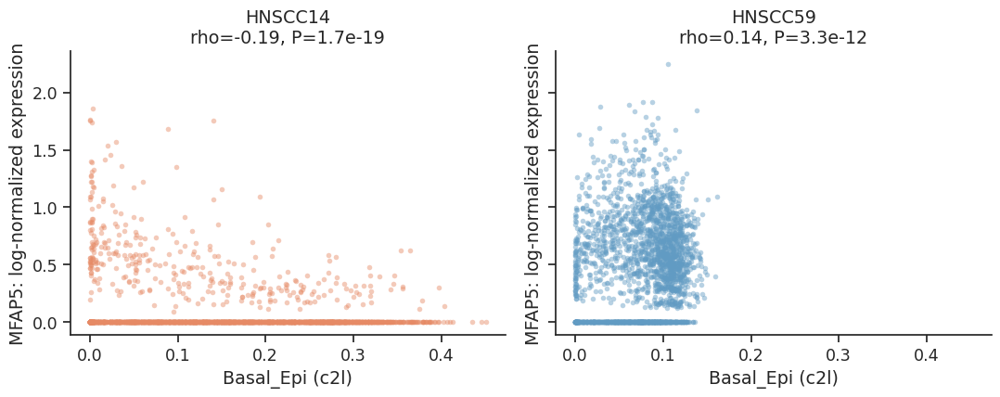

 sample  n_spots     rho   p_value
HNSCC14     2213 -0.1903 1.684e-19
HNSCC59     2427  0.1407  3.33e-12


In [ ]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

# 参数
GENE = "MFAP5"
SUBTYPE = "Basal_Epi"
KEY = "q05_cell_abundance_w_sf"
LAYER = None   # 使用已经 normalize_total + log1p 的 X，或指定 layer

SAMPLES = ["HNSCC14", "HNSCC59"]
COLORS = ["#E68A65", "#619BC3"]

# 1. 提取 c2l 亚型数值
ab = adata.obsm[KEY]

if isinstance(ab, pd.DataFrame):
    abundance = ab[SUBTYPE].reindex(adata.obs_names).to_numpy()
else:
    names = adata.uns.get("mod", {}).get("factor_names")
    if names is None:
        raise ValueError("c2l 矩阵没有列名，请提供对应的亚型名称及顺序。")
    column = list(names).index(SUBTYPE)
    values = ab[:, column]
    abundance = (
        values.toarray().ravel()
        if sp.issparse(values)
        else np.asarray(values).ravel()
    )

# 2. 提取 MFAP5 的归一化表达
if not adata.var_names.is_unique:
    raise ValueError("基因名不唯一，请先检查。")
if GENE not in adata.var_names:
    raise KeyError(f"未找到 {GENE}")

matrix = adata.X if LAYER is None else adata.layers[LAYER]
values = matrix[:, [adata.var_names.get_loc(GENE)]]
expression = (
    values.toarray().ravel()
    if sp.issparse(values)
    else np.asarray(values).ravel()
)

df = pd.DataFrame({
    "sample": adata.obs["sample"].astype("string").str.strip(),
    "c2l_value": abundance,
    "expression": expression,
}, index=adata.obs_names)

# 所有组织内 spot，不筛选 niche
keep = df["sample"].isin(SAMPLES)
if "in_tissue" in adata.obs:
    keep &= pd.to_numeric(
        adata.obs["in_tissue"], errors="coerce"
    ).eq(1)

df = (
    df.loc[keep]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

# 3. 分样本计算并绘图，保留基因零表达 spot
sns.set_theme(style="ticks", font_scale=1.15)
fig, axes = plt.subplots(
    1, 2, figsize=(11, 4.5), sharex=True, sharey=True
)
rows = []

for ax, sample, color in zip(axes, SAMPLES, COLORS):
    sub = df.loc[df["sample"] == sample]

    rho, p = np.nan, np.nan
    if (
        len(sub) >= 3
        and sub["c2l_value"].nunique() > 1
        and sub["expression"].nunique() > 1
    ):
        rho, p = spearmanr(sub["c2l_value"], sub["expression"])

    rows.append({
        "sample": sample,
        "n_spots": len(sub),
        "rho": rho,
        "p_value": p,
    })

    ax.scatter(
        sub["c2l_value"], sub["expression"],
        color=color, s=16, alpha=0.45, linewidths=0,
    )
    ax.set(
        title=f"{sample}\nrho={rho:.2f}, P={p:.2g}",
        xlabel=f"{SUBTYPE} (c2l)",
        ylabel=f"{GENE}: log-normalized expression",
    )

sns.despine()
fig.tight_layout()
plt.show()

result = pd.DataFrame(rows)
print(result.to_string(index=False, float_format=lambda x: f"{x:.4g}"))

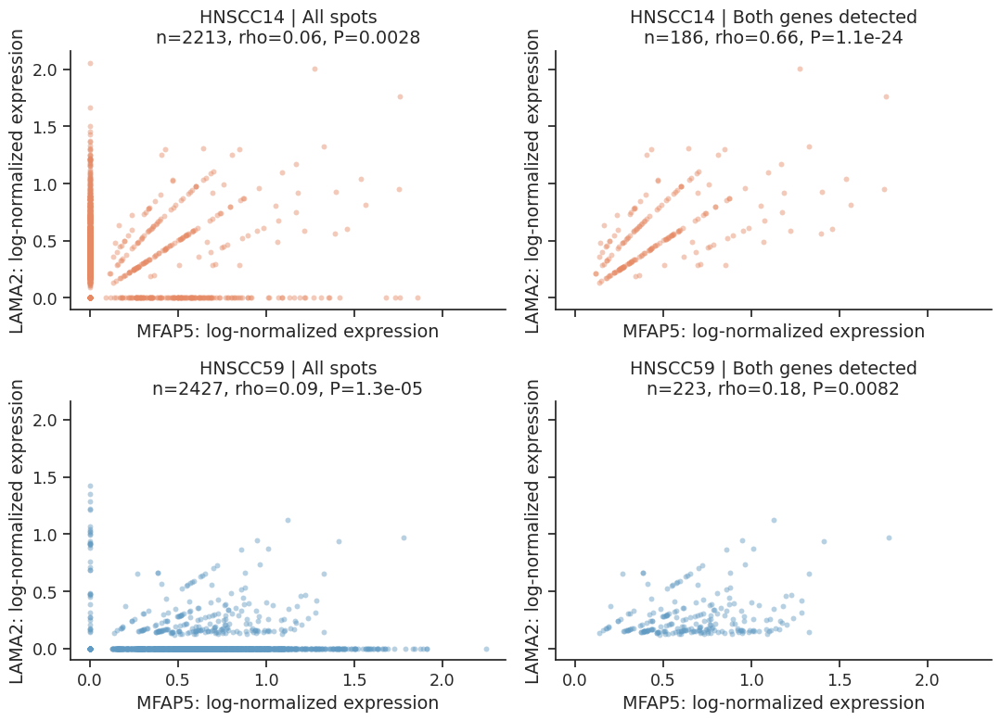

 sample            analysis  n_spots     rho   p_value
HNSCC14           All spots     2213 0.06348  0.002812
HNSCC14 Both genes detected      186  0.6607 1.062e-24
HNSCC59           All spots     2427  0.0885 1.265e-05
HNSCC59 Both genes detected      223  0.1767  0.008164


In [ ]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

# 参数
GENE1 = "MFAP5"
GENE2 = "LAMA2"
LAYER = None   # None 使用 X，或指定归一化表达 layer

SAMPLES = ["HNSCC14", "HNSCC59"]
COLORS = ["#E68A65", "#619BC3"]

# 1. 检查并提取表达
if not adata.var_names.is_unique:
    raise ValueError("基因名不唯一，请先检查。")

missing = [g for g in [GENE1, GENE2] if g not in adata.var_names]
if missing:
    raise KeyError(f"未找到基因：{missing}")

matrix = adata.X if LAYER is None else adata.layers[LAYER]
x = matrix[:, adata.var_names.get_indexer([GENE1, GENE2])]
x = x.toarray() if sp.issparse(x) else np.asarray(x)

df = pd.DataFrame({
    "sample": adata.obs["sample"].astype("string").str.strip(),
    "gene1": x[:, 0],
    "gene2": x[:, 1],
}, index=adata.obs_names)

# 全部组织内 spot
keep = df["sample"].isin(SAMPLES)
if "in_tissue" in adata.obs:
    keep &= pd.to_numeric(
        adata.obs["in_tissue"], errors="coerce"
    ).eq(1)

df = (
    df.loc[keep]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

if (df[["gene1", "gene2"]] < 0).any().any():
    raise ValueError("请使用非负的 log1p 表达，不使用 scale 后的数据。")

# 2. 分样本比较：全部 spot / 双阳性 spot
sns.set_theme(style="ticks", font_scale=1.15)

fig, axes = plt.subplots(
    len(SAMPLES), 2,
    figsize=(11, 4 * len(SAMPLES)),
    squeeze=False,
    sharex=True,
    sharey=True,
)
rows = []

for i, sample in enumerate(SAMPLES):
    sub = df.loc[df["sample"] == sample]
    positive = sub.loc[(sub["gene1"] > 0) & (sub["gene2"] > 0)]

    for j, (label, data) in enumerate([
        ("All spots", sub),
        ("Both genes detected", positive),
    ]):
        rho, p = np.nan, np.nan

        if (
            len(data) >= 3
            and data["gene1"].nunique() > 1
            and data["gene2"].nunique() > 1
        ):
            rho, p = spearmanr(data["gene1"], data["gene2"])

        rows.append({
            "sample": sample,
            "analysis": label,
            "n_spots": len(data),
            "rho": rho,
            "p_value": p,
        })

        ax = axes[i, j]
        ax.scatter(
            data["gene1"], data["gene2"],
            color=COLORS[i],
            s=18, alpha=0.45, linewidths=0,
        )
        ax.set(
            title=f"{sample} | {label}\n"
                  f"n={len(data)}, rho={rho:.2f}, P={p:.2g}",
            xlabel=f"{GENE1}: log-normalized expression",
            ylabel=f"{GENE2}: log-normalized expression",
        )

sns.despine()
fig.tight_layout()
plt.show()

result = pd.DataFrame(rows)
print(result.to_string(
    index=False,
    float_format=lambda x: f"{x:.4g}",
))

##cnv

In [ ]:
pip install infercnvpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 788.4/788.4 kB 43.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.4/48.4 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.8/70.8 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.6/87.6 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.8/74.8 kB 5.1 MB/s eta 0:00:00


In [ ]:
import infercnvpy as cnv

In [ ]:
with open("hg38_gencode_v27.txt") as f:
    for i,line in enumerate(f,1):
        if i==82:
            print(repr(line))

'TNFRSF18\tchr1\t1203508\t1206691\t\n'


In [ ]:
import numpy as np

cell_abundance = adata.obsm[
    "q05_cell_abundance_w_sf_norm"
]
adata.obs["cell2location_celltype"] = "Unknown"


for ct in cell_abundance.columns:

    mask = cell_abundance[ct] > 0.2

    adata.obs.loc[
        mask,
        "cell2location_celltype"
    ] = ct



In [ ]:
adata.obs["cell2location_major"] = (
    cell_abundance.idxmax(axis=1)
)

In [ ]:
adata.obs["cell2location_major"].value_counts()

cell2location_major
Diff_Epi         1516
Neutrophil       1116
CD4T_PTPRC        743
Normal_Epi        449
Basal_Epi         277
myCAF_CTHRC1      203
Hypoxia_Epi       101
Capillary_EC       88
qEC                81
Mac_FOLR2          27
Plasma             10
Stem_like_Epi       8
Arterial_EC         5
Prolif_Epi          5
CAF_COL14A1         3
Mac_SPP1            3
apCAF               2
EC_PGF              2
iCAF_CXCL1          1
Name: count, dtype: int64

/tmp/ipykernel_3382/188207367.py:15: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()
/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()


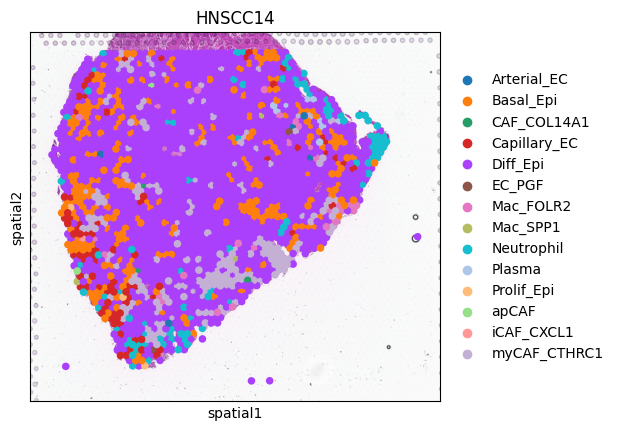

/tmp/ipykernel_3382/188207367.py:15: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()
/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()


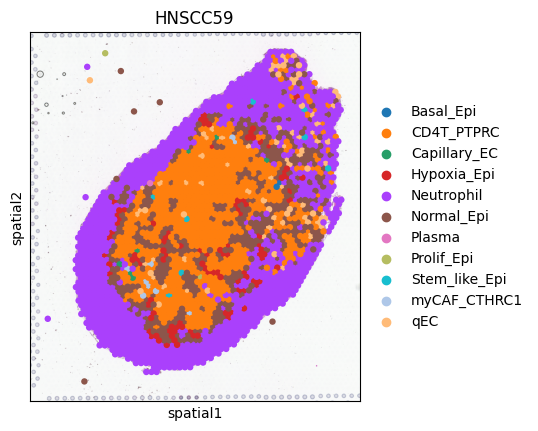

In [ ]:
prefix = "q05cell_abundance_w_sf_"

adata.obs["cell2location_major"] = (
    adata.obs["cell2location_major"]
    .str.replace(prefix, "", regex=False)
)

adata.obs["cell2location_major"].value_counts()

import scanpy as sc


for sample in adata.obs["sample"].unique():

    sc.pl.spatial(
        adata[adata.obs["sample"]==sample],
        color="cell2location_major",
        library_id=sample,
        img_key="hires",
        spot_size=150,
        title=sample
    )

/tmp/ipykernel_6613/1258846026.py:3: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()
/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()
/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata._sanitize()


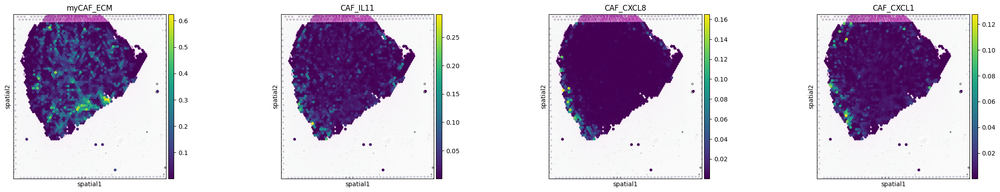

/tmp/ipykernel_6613/1258846026.py:3: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()
/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()
/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata._sanitize()


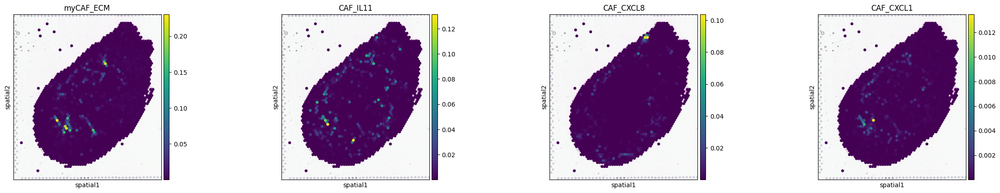

In [ ]:

for sample in adata.obs["sample"].unique():

  sc.pl.spatial(
    adata[adata.obs["sample"]==sample],
    color=[
        "myCAF_ECM",
        "CAF_IL11",
        "CAF_CXCL8",
        "CAF_CXCL1"
    ],library_id=sample,
    img_key="hires",
    spot_size=150
)

In [ ]:
adata.obs["cell2location_celltype"].value_counts()

cell2location_celltype
q05cell_abundance_w_sf_Detox_Epi           1577
q05cell_abundance_w_sf_Mesenchymal_Epi     1164
Unknown                                     952
q05cell_abundance_w_sf_Keratinizing_Epi     463
q05cell_abundance_w_sf_myCAF_ECM            230
q05cell_abundance_w_sf_Inflammatory Neu     189
q05cell_abundance_w_sf_FOLR2+ Macro          27
q05cell_abundance_w_sf_ISG+ Neu              21
q05cell_abundance_w_sf_IgG+ Plasma           10
q05cell_abundance_w_sf_CAF_IL11               4
q05cell_abundance_w_sf_Angiogenic EC          4
q05cell_abundance_w_sf_SPP1+ TAM              2
q05cell_abundance_w_sf_Basal_Epi              2
q05cell_abundance_w_sf_Arterial EC            2
q05cell_abundance_w_sf_Treg                   1
q05cell_abundance_w_sf_Mono                   1
Name: count, dtype: int64

In [ ]:
print(cnv_adata.obsm["X_cnv"])

NameError: name 'cnv_adata' is not defined

In [ ]:
gene_pos = pd.read_csv(
    "hg38_gencode_v27.txt",
    sep="\t",
    header=None,
    names=[
        "gene_symbol",
        "chromosome",
        "start",
        "end"
    ],
    engine="python",
    on_bad_lines="skip"
)

In [ ]:
gene_pos = gene_pos.drop_duplicates(
    "gene_symbol"
)

gene_pos = gene_pos.set_index(
    "gene_symbol"
)


adata.var = adata.var.join(
    gene_pos[
        ["chromosome","start","end"]
    ],
    how="left"
)

In [ ]:
gene_pos

            chromosome  start    end
gene_symbol                         
DDX11L1           chr1  11869  14409
WASH7P            chr1  14404  29570
MIR6859-1         chr1  17369  17436
MIR1302-2HG       chr1  29554  31109
MIR1302-2         chr1  30366  30503
...                ...    ...    ...
MT-ND6            chrM  14149  14673
MT-TE             chrM  14674  14742
MT-CYB            chrM  14747  15887
MT-TT             chrM  15888  15953
MT-TP             chrM  15956  16023

[56608 rows x 3 columns]

In [ ]:
adata.var[
    ["chromosome","start","end"]
].notna().mean()

chromosome    0.979268
start         0.979268
end           0.979268
dtype: float64

In [ ]:
sample="HNSCC14"

adata_sub = adata[
    adata.obs["sample"]==sample
].copy()

In [ ]:
cnv.tl.infercnv(
    adata_sub,
    reference_key="cnv_group",
    reference_cat="normal",
    window_size=100,
)

ValueError: Genomic positions not found. There need to be `chromosome`, `start`, and `end` columns in `adata.var`. 

##nich c2l

In [ ]:
from sklearn.decomposition import PCA

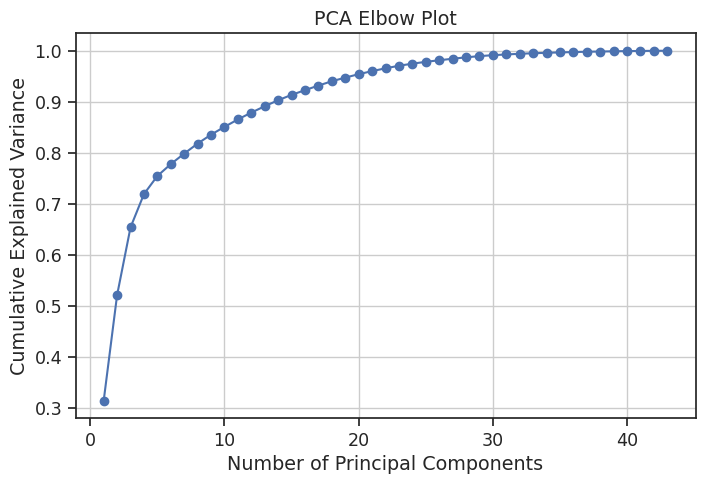

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# 提取 q05_cell_abundance_w_sf 数据
cell_abundance_data_norm = adata.obsm['q05_cell_abundance_w_sf']

# 归一化每个 spot，使其所有特征之和为 1
# cell_abundance_data_norm = cell_abundance_data.div(cell_abundance_data.sum(axis=1), axis=0)

# 标准化（类似 Scanpy 的 sc.pp.scale()）
scaler = StandardScaler()
cell_abundance_data_scaled = scaler.fit_transform(cell_abundance_data_norm)

# 限制最大值（与 sc.pp.scale() 的 max_value=10 机制相同）
cell_abundance_data_scaled = np.clip(cell_abundance_data_scaled, -10, 10)


# 计算 PCA，获取所有主成分的方差解释率
pca = PCA(n_components=min(cell_abundance_data_scaled.shape[0], cell_abundance_data_scaled.shape[1]))  # 选择最大可能的成分数
pca.fit(cell_abundance_data_scaled)
explained_variance_ratio = pca.explained_variance_ratio_

# 绘制 Elbow Plot
plt.figure(figsize=(8, 5))
plt.plot(np.arange(1, len(explained_variance_ratio) + 1), np.cumsum(explained_variance_ratio), marker='o', linestyle='-')
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Elbow Plot")
plt.grid()

# 显示图表
plt.show()


In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# 提取 q05_cell_abundance_w_sf 数据
cell_abundance_data = adata.obsm['q05_cell_abundance_w_sf']

# 归一化每个 spot，使其所有特征之和为 1
cell_abundance_data_norm = cell_abundance_data.div(cell_abundance_data.sum(axis=1), axis=0)

# 标准化（类似 Scanpy 的 sc.pp.scale()）
scaler = StandardScaler()
cell_abundance_data_scaled = scaler.fit_transform(cell_abundance_data_norm)

# 限制最大值（与 sc.pp.scale() 的 max_value=10 机制相同）
cell_abundance_data_scaled = np.clip(cell_abundance_data_scaled, -10, 10)

# 进行 PCA，获取前 30 个主成分
pca = PCA(n_components=30)
pca_result = pca.fit_transform(cell_abundance_data_scaled)

# 将 PCA 结果添加回 .obsm
adata.obsm['X_pca_q05'] = pca_result

In [ ]:
import numpy as np
import pandas as pd

# ===============================
# 1. 获取 cell abundance 矩阵
# ===============================

abundance = np.asarray(
    adata.obsm["q05_cell_abundance_w_sf"],
    dtype=np.float64
)

celltypes = np.array(
    adata.uns["mod"]["factor_names"]
)


# ===============================
# 2. 删除 Unknown
# ===============================

keep = ~np.char.contains(
    celltypes.astype(str),
    "Unknown",
    case=False
)

abundance = abundance[:, keep]
celltypes = celltypes[keep]


print("保留celltype数量:", len(celltypes))
print(celltypes)


# ===============================
# 3. 重新归一化
# 每个spot内所有cell比例=1
# ===============================

abundance_norm = (
    abundance /
    abundance.sum(axis=1, keepdims=True)
)

# 防止极端spot全0
abundance_norm = np.nan_to_num(
    abundance_norm
)


# ===============================
# 4. 删除obs中旧的cell abundance列
# ===============================

old_cols = [
    c for c in adata.obs.columns
    if c in adata.uns["mod"]["factor_names"]
]

adata.obs.drop(
    columns=old_cols,
    inplace=True,
    errors="ignore"
)


# ===============================
# 5. 写入新的归一化结果
# ===============================

adata.obs[celltypes] = abundance_norm


# 保存obsm
adata.obsm["q05_cell_abundance_w_sf_norm"] = abundance_norm

# 保存新的名字
adata.uns["celltypes_q05_norm"] = celltypes.tolist()


print(
    adata.obs[celltypes].head()
)

AttributeError: module 'numpy.char' has no attribute 'contains'

In [ ]:
import numpy as np


def get_gene_expr(adata, gene):

    x = adata[:, gene].X

    if hasattr(x, "toarray"):
        x = x.toarray().flatten()
    else:
        x = np.array(x).flatten()

    return x


adata.obs["MFAP5_expr"] = get_gene_expr(
    adata,
    "MFAP5"
)

adata.obs["LAMA2_expr"] = get_gene_expr(
    adata,
    "LAMA2"
)

In [ ]:
from scipy.stats import spearmanr


results=[]


for gene in [
    "MFAP5_expr",
    "LAMA2_expr"
]:

    r,p = spearmanr(
        adata.obs["myCAF_CTHRC1"],
        adata.obs[gene]
    )


    results.append(
        {
            "gene":gene,
            "rho":r,
            "pvalue":p
        }
    )


pd.DataFrame(results)

         gene       rho        pvalue
0  MFAP5_expr -0.142765  1.480912e-22
1  LAMA2_expr  0.301889  2.216146e-98

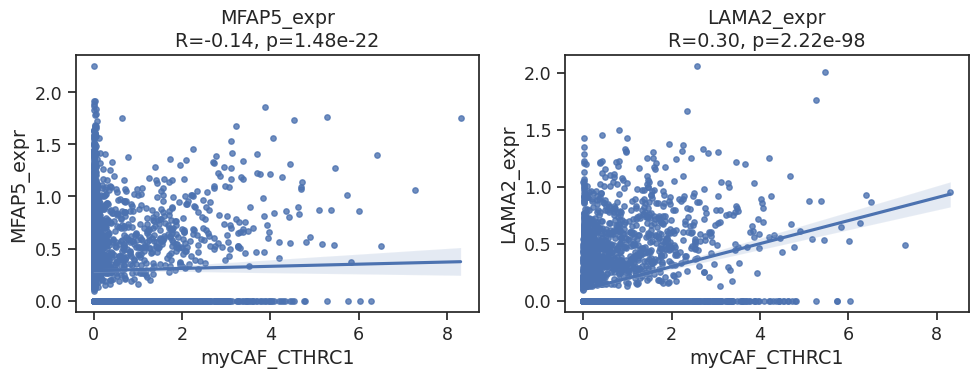

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt


fig,axs=plt.subplots(
    1,2,
    figsize=(10,4)
)


for ax,gene in zip(
    axs,
    ["MFAP5_expr","LAMA2_expr"]
):

    sns.regplot(
        data=adata.obs,
        x="myCAF_CTHRC1",
        y=gene,
        scatter_kws={"s":15},
        ax=ax
    )

    r,p=spearmanr(
        adata.obs["myCAF_CTHRC1"],
        adata.obs[gene]
    )

    ax.set_title(
        f"{gene}\nR={r:.2f}, p={p:.3g}"
    )


plt.tight_layout()

In [ ]:
import squidpy as sq


sq.gr.spatial_neighbors(
    adata,
    coord_type="grid"
)


sq.stats.spatial_autocorr(
    adata,
    genes=[
        "MFAP5",
        "LAMA2"
    ],
    mode="moran"
)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_3652/3346451557.py:4: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(


AttributeError: module 'squidpy' has no attribute 'stats'

In [ ]:
# pcs = adata.obsm['X_pca_q05']
pcs = np.asarray(
    adata.obsm["q05_cell_abundance_w_sf"],
    dtype=np.float64
)
# Run Harmony on the PCA embedding
harmony_out = hm.run_harmony(pcs,adata.obs, ["sample"],max_iter_harmony= 30)

# Store corrected PCs back in the AnnData object
adata.obsm['X_pca_harmony_c2l'] = harmony_out.Z_corr

sc.pp.neighbors(adata, n_neighbors=20, n_pcs=15, use_rep="X_pca_harmony_c2l")

sc.tl.umap(adata,key_added="umap_c2l")

2026-09-18 07:37:34,118 - harmonypy - INFO - Running Harmony
INFO:harmonypy:Running Harmony
2026-09-18 07:37:34,120 - harmonypy - INFO -   Parameters:
INFO:harmonypy:  Parameters:
2026-09-18 07:37:34,121 - harmonypy - INFO -     max_iter_harmony: 30
INFO:harmonypy:    max_iter_harmony: 30
2026-09-18 07:37:34,123 - harmonypy - INFO -     max_iter_kmeans: 4
INFO:harmonypy:    max_iter_kmeans: 4
2026-09-18 07:37:34,125 - harmonypy - INFO -     epsilon_cluster: 0.001
INFO:harmonypy:    epsilon_cluster: 0.001
2026-09-18 07:37:34,127 - harmonypy - INFO -     epsilon_harmony: 0.01
INFO:harmonypy:    epsilon_harmony: 0.01
2026-09-18 07:37:34,128 - harmonypy - INFO -     nclust: 100
INFO:harmonypy:    nclust: 100
2026-09-18 07:37:34,129 - harmonypy - INFO -     block_size: 0.05
INFO:harmonypy:    block_size: 0.05
2026-09-18 07:37:34,132 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
INFO:harmonypy:    lamb: dynamic (alpha=0.2)
2026-09-18 07:37:34,133 - harmonypy - INFO -     theta: [2. 2.]


In [ ]:
sc.tl.leiden(adata, resolution=0.2,key_added="leiden_c2l")


/tmp/ipykernel_3652/684348338.py:1: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=0.2,key_added="leiden_c2l")


In [ ]:
sc.tl.umap(adata)

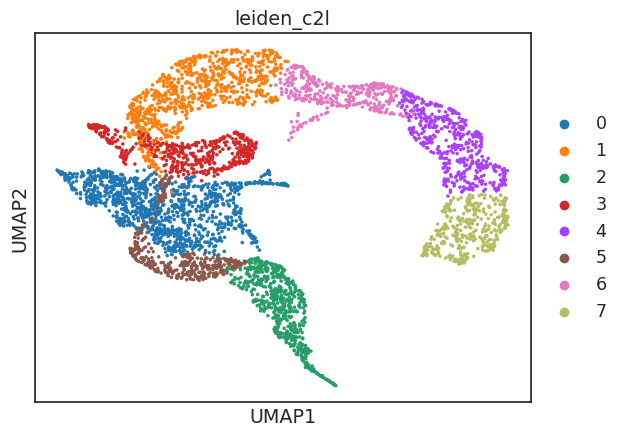

In [ ]:
sc.pl.umap(adata,color="leiden_c2l",)

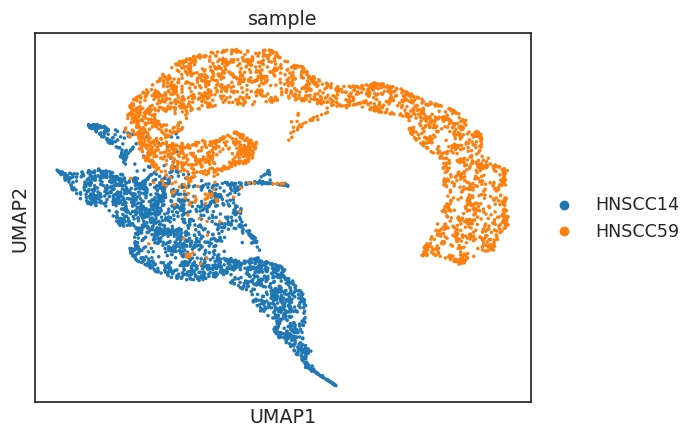

In [ ]:
sc.pl.umap(adata,color="sample")

/tmp/ipykernel_3652/1522366721.py:1: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/usr/local/lib/python3.13/dist-packages/scanpy/plotting/_utils.py:509: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


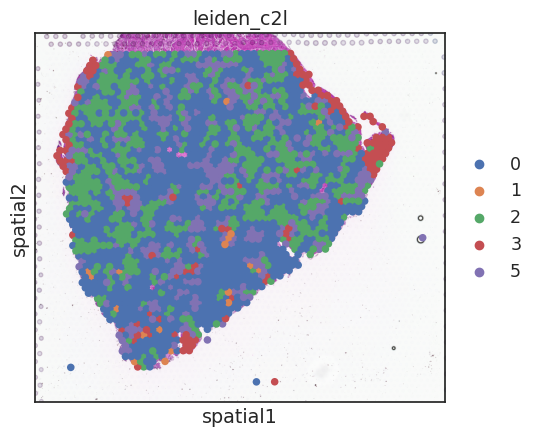

In [ ]:
sc.pl.spatial(
    adata[adata.obs["sample"]=="HNSCC14"],
    color="leiden_c2l",
    library_id="HNSCC14",
    img_key="hires",
    spot_size=150,
    cmap="RdBu_r",
    vmin=vmin,
    vmax="p99.2"
)

/tmp/ipykernel_3652/323251113.py:1: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/usr/local/lib/python3.13/dist-packages/scanpy/plotting/_utils.py:509: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


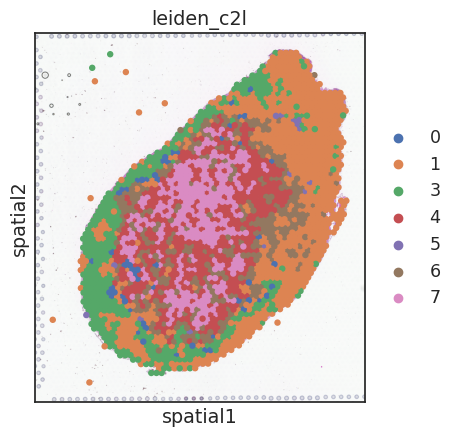

In [ ]:
sc.pl.spatial(
    adata[adata.obs["sample"]=="HNSCC59"],
    color="leiden_c2l",
    library_id="HNSCC59",
    img_key="hires",
    spot_size=150,
    cmap="RdBu_r",
    vmin=vmin,
    vmax="p99.2"
)

In [ ]:
adata.write_h5ad("./visum//st.h5ad")

# 距离写入

In [10]:
adata = sc.read_h5ad("./visum//st.h5ad")

In [11]:
import pandas as pd

# 1. 读取注释
anno = pd.read_csv("./visum/anno14 tumor.csv", index_col=0)
print(anno.head())   # 查看实际的分组列名

ANNO_COL = "tumor anno"       # 修改为 CSV 中的分组列名
OUT_COL = "Region"    # 写入 adata.obs 的列名

# 兼容 AAACA...-1、HNSCC14_AAACA...-1、
# HNSCC14_HNSCC14_AAACA...-1 等 spot 名
def clean_spot(index):
    return (
        pd.Index(index).astype(str).str.strip()
        .str.replace(r"^(?:HNSCC14_)+", "", regex=True)
    )

anno.index = clean_spot(anno.index)

if not anno.index.is_unique:
    raise ValueError("anno.csv 中清理后的 spot 名存在重复，请检查")

# 2. 整理区域名称，将 extrnodal 拼写统一为 extranodal
region = (
    anno[ANNO_COL]
    .astype("string")
    .str.strip()
    .replace({"extrnodal": "extranodal"})
)

# 3. 仅匹配 HNSCC14
mask = adata.obs["sample"].eq("HNSCC14")
spot_ids = clean_spot(adata.obs_names[mask])
matched = region.reindex(spot_ids)

if matched.notna().sum() == 0:
    raise ValueError(
        "没有匹配到有效注释，请检查 spot 名和分组列名。\n"
        f"adata 示例：{spot_ids[:3].tolist()}\n"
        f"CSV 示例：{anno.index[:3].tolist()}"
    )

# 4. 写入 obs；未匹配的 spot 保留为空
if OUT_COL not in adata.obs:
    adata.obs[OUT_COL] = pd.Series(
        pd.NA, index=adata.obs_names, dtype="string"
    )
else:
    adata.obs[OUT_COL] = adata.obs[OUT_COL].astype("string")

# 使用数组，避免清理后的 spot 名再次参与索引对齐
adata.obs.loc[mask, OUT_COL] = matched.to_numpy()

print(f"HNSCC14：成功注释 {matched.notna().sum()} / {mask.sum()} 个 spot")
print(adata.obs.loc[mask, OUT_COL].value_counts(dropna=False))

                   tumor anno
Barcode                      
AAACAATCTACTAGCA-1        CAF
AAACAGAGCGACTCCT-1      Tumor
AAACCGGGTAGGTACC-1        CAF
AAACCGTTCGTCCAGG-1        CAF
AAACCTCATGAAGTTG-1      Tumor
HNSCC14：成功注释 2209 / 2213 个 spot
Region
Tumor     1103
CAF       1068
Stroma      23
Normal      15
<NA>         4
Name: count, dtype: Int64


In [12]:
import pandas as pd
import re

SAMPLE = "HNSCC59"

# ========= 1. 读取注释 =========
anno59 = pd.read_csv("./visum/anno59 tumor.csv")
anno59["Barcode"] = anno59["Barcode"].astype(str).str.strip()

anno_map = anno59.set_index("Barcode")["tumor anno"]

# ========= 2. 准备注释列，保留其他样本的已有注释 =========
if "Region" not in adata.obs.columns:
    adata.obs["Region"] = pd.NA
else:
    adata.obs["Region"] = adata.obs["Region"].astype(object)

mask59 = adata.obs["sample"].eq(SAMPLE)

# ========= 3. 去掉开头的样本名及分隔符 =========
names59 = adata.obs_names[mask59].astype(str)

clean_names59 = names59.str.replace(
    rf"^{re.escape(SAMPLE)}[_:\-]+",
    "",
    regex=True,
).str.strip()

# 看一下清理结果
print(pd.DataFrame({
    "原始名称": names59[:5],
    "匹配用barcode": clean_names59[:5],
}))

# ========= 4. 精确匹配并写入 =========
matched = pd.Series(
    clean_names59.to_numpy(),
    index=names59,
).map(anno_map)

adata.obs.loc[mask59, "Region"] = matched.to_numpy()

# ========= 5. 检查匹配情况 =========
n_total = int(mask59.sum())
n_match = int(matched.notna().sum())

print("HNSCC59 总spot数:", n_total)
print("成功匹配:", n_match)
print("未匹配:", n_total - n_match)
print("匹配率:", f"{n_match / n_total:.2%}" if n_total else "无该样本")

print("\n注释分布：")
print(adata.obs.loc[mask59, "Region"].value_counts(dropna=False))

if matched.isna().any():
    print("\n未匹配的 barcode（前10个）：")
    print(clean_names59[matched.isna().to_numpy()][:10].tolist())

                         原始名称          匹配用barcode
0  HNSCC59_AAACAAGTATCTCCCA-1  AAACAAGTATCTCCCA-1
1  HNSCC59_AAACACCAATAACTGC-1  AAACACCAATAACTGC-1
2  HNSCC59_AAACAGAGCGACTCCT-1  AAACAGAGCGACTCCT-1
3  HNSCC59_AAACAGGGTCTATATT-1  AAACAGGGTCTATATT-1
4  HNSCC59_AAACAGTGTTCCTGGG-1  AAACAGTGTTCCTGGG-1
HNSCC59 总spot数: 2427
成功匹配: 2365
未匹配: 62
匹配率: 97.45%

注释分布：
Region
Tumor     1110
Stroma    1072
CAF        183
NaN         62
Name: count, dtype: int64

未匹配的 barcode（前10个）：
['AAATACCTATAAGCAT-1', 'AACGTGCGAAAGTCTC-1', 'AAGAGCTCTTTATCGG-1', 'ACATCCCGGCCATACG-1', 'ACCCGGTTACACTTCC-1', 'ACGGCCAACATGGACT-1', 'ACTCGTCAGTAATCCC-1', 'AGATACGACTTCATAT-1', 'AGCGTGGTATTCTACT-1', 'AGTCACTCCGCCTCAT-1']


In [13]:
adata = adata[adata.obs["Region"].notna()].copy()

In [14]:
adata.obs["Region"].unique()

array(['CAF', 'Tumor', 'Normal', 'Stroma'], dtype=object)

In [15]:
adata.obs["Region"] = adata.obs["Region"].replace({
    "CAF": "Stroma"
})

In [16]:
adata.obs["Region"].unique()

array(['Stroma', 'Tumor', 'Normal'], dtype=object)

# decoupler

In [ ]:
# adata=sc.read_h5ad("./visum/st.h5ad")

/tmp/ipykernel_3652/2291377331.py:1: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


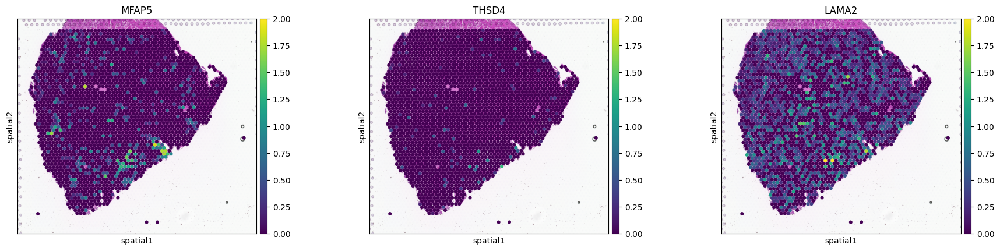

In [ ]:
sc.pl.spatial(
    adata[adata.obs["sample"]=="HNSCC14"],
    color=["MFAP5","THSD4","LAMA2"],
    library_id="HNSCC14",
    # cmap="magma",
    img_key="hires",
    spot_size =120,
    vmin=0, vmax='2'

)

In [17]:
pip install decoupler


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 147.4/147.4 kB 1.4 MB/s eta 0:00:00


In [18]:
import warnings

import scanpy as sc
import decoupler as dc

warnings.filterwarnings("ignore", category=FutureWarning)
sc.set_figure_params(figsize=(3, 3), frameon=False)

In [19]:
adata.X = adata.layers["counts"].copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

adata.layers["norm"] = adata.X.copy()

In [ ]:
collectri = dc.op.collectri(organism="human")
collectri

       source          target  weight  \
0         MYC            TERT     1.0   
1        SPI1           BGLAP     1.0   
2       SMAD3             JUN     1.0   
3       SMAD4             JUN     1.0   
4      STAT5A             IL2     1.0   
...       ...             ...     ...   
42985    NFKB  hsa-miR-143-3p     1.0   
42986     AP1     hsa-miR-206     1.0   
42987    NFKB      hsa-miR-21     1.0   
42988    NFKB  hsa-miR-224-5p     1.0   
42989     AP1  hsa-miR-144-3p     1.0   

                                               resources  \
0      DoRothEA-A;ExTRI;HTRI;NTNU.Curated;Pavlidis202...   
1                                                  ExTRI   
2                       ExTRI;NTNU.Curated;TFactS;TRRUST   
3                       ExTRI;NTNU.Curated;TFactS;TRRUST   
4                                                  ExTRI   
...                                                  ...   
42985                                              ExTRI   
42986                      

In [ ]:
dc.mt.ulm(data=adata, net=collectri)


In [ ]:
score = dc.pp.get_obsm(adata=adata, key="score_ulm")
score

AnnData object with n_obs × n_vars = 4574 × 14
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'log1p_total_counts_mt', 'clusters', 'leiden', 'gene_niche', 'subtype', '_indices', '_scvi_batch', '_scvi_labels', 'Program_1', 'Program_2', 'Program_3', 'Program_4', 'Program_5', 'Program_6', 'Program_7', 'LAMA2_positive', 'LAMA2_expr', 'Arterial_EC', 'B', 'Basal_Epi', 'CAF_COL14A1', 'CD4T_CXCL13', 'CD4T_GZMB', 'CD4T_PTPRC', 'CD4T_naive', 'CD8T_CXCL13', 'CD8T_GZMA', 'CD8T_GZMK', 'CD8T_naive', 'CD8T_str', 'Capillary_EC', 'Cycling_CAF', 'Cycling_EC', 'Cycling_T', 'Diff_Epi', 'EC_ACKR1', 'EC_PGF', 'EMT_like_Epi', 'Hypoxia_Epi', 'Mac_CXCL5', 'Mac_FOLR2', 'Mac_SPP1', 'Mast', 'Mono_FCN1', 'NK', 'Neutrophil', 'Normal_Epi', 'Plasma', 'Prolif_Epi', '

## progeny

In [ ]:
progeny = dc.op.progeny(organism="human")
progeny


         source   target     weight          padj
0      Androgen  TMPRSS2  11.490631  2.384806e-47
1      Androgen   NKX3-1  10.622551  2.205102e-44
2      Androgen   MBOAT2  10.472733  4.632376e-44
3      Androgen     KLK2  10.176186  1.944410e-40
4      Androgen     SARG  11.386852  2.790210e-40
...         ...      ...        ...           ...
62416       p53    ENPP2   2.771405  4.993215e-02
62417       p53   ARRDC4   3.494328  4.996747e-02
62418       p53    MYO1B  -1.148057  4.997905e-02
62419       p53     CTSC  -1.784693  4.998864e-02
62420       p53    NAA50  -1.435013  4.998884e-02

[62421 rows x 4 columns]

In [ ]:
dc.mt.ulm(data=adata, net=progeny)

In [ ]:
score = dc.pp.get_obsm(adata=adata, key="score_ulm")
score

AnnData object with n_obs × n_vars = 4574 × 14
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'log1p_total_counts_mt', 'clusters', 'leiden', 'gene_niche', 'subtype', '_indices', '_scvi_batch', '_scvi_labels', 'Program_1', 'Program_2', 'Program_3', 'Program_4', 'Program_5', 'Program_6', 'Program_7', 'LAMA2_positive', 'LAMA2_expr', 'Arterial_EC', 'B', 'Basal_Epi', 'CAF_COL14A1', 'CD4T_CXCL13', 'CD4T_GZMB', 'CD4T_PTPRC', 'CD4T_naive', 'CD8T_CXCL13', 'CD8T_GZMA', 'CD8T_GZMK', 'CD8T_naive', 'CD8T_str', 'Capillary_EC', 'Cycling_CAF', 'Cycling_EC', 'Cycling_T', 'Diff_Epi', 'EC_ACKR1', 'EC_PGF', 'EMT_like_Epi', 'Hypoxia_Epi', 'Mac_CXCL5', 'Mac_FOLR2', 'Mac_SPP1', 'Mast', 'Mono_FCN1', 'NK', 'Neutrophil', 'Normal_Epi', 'Plasma', 'Prolif_Epi', '

In [ ]:
df = dc.tl.rankby_group(adata=score, groupby="Region", reference="rest", method="t-test_overestim_var")
df = df[df["stat"] > 0]
df

     group reference      name       stat  meanchange           pval  \
1      CAF      rest       p53  23.961403    2.910247  2.321495e-114   
2      CAF      rest  JAK-STAT  22.911932    2.374357  1.653732e-105   
3      CAF      rest      TGFb  22.257068    1.501320  9.858444e-100   
5      CAF      rest  Androgen  16.611562    0.595859   1.058543e-58   
6      CAF      rest     Trail  14.622126    0.465412   1.622149e-46   
7      CAF      rest   Hypoxia  12.615457    1.954852   2.403264e-35   
8      CAF      rest      NFkB   4.630618    0.763544   3.887124e-06   
12     CAF      rest      TNFa   1.346658    0.197254   1.782509e-01   
13     CAF      rest  Estrogen   0.828315    0.041373   4.075765e-01   
15   Tumor      rest      PI3K  33.908495    1.678813  4.867719e-224   
23   Tumor      rest      MAPK  20.854600    1.313588   4.298032e-92   
24   Tumor      rest      VEGF  11.707731    0.358158   3.379270e-31   
25   Tumor      rest      EGFR   8.116050    0.435219   6.280981

In [ ]:
n_markers = 3
source_markers = (
    df.groupby("group")
    .head(n_markers)
    .drop_duplicates("name")
    .groupby("group")["name"]
    .apply(lambda x: list(x))
    .to_dict()
)
source_markers

{'CAF': ['p53', 'JAK-STAT', 'TGFb'],
 'Normal': ['EGFR', 'NFkB'],
 'Stroma': ['WNT', 'TNFa'],
 'Tumor': ['PI3K', 'MAPK', 'VEGF']}

In [ ]:
sc.pl.matrixplot(
    adata=score,
    var_names=source_markers,
    groupby="Region",
    dendrogram=True,
    standard_scale="var",
    colorbar_title="Z-scaled scores",
    cmap=dot_map,
    swap_axes=True,
)

/usr/local/lib/python3.13/dist-packages/scanpy/plotting/_utils.py:509: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


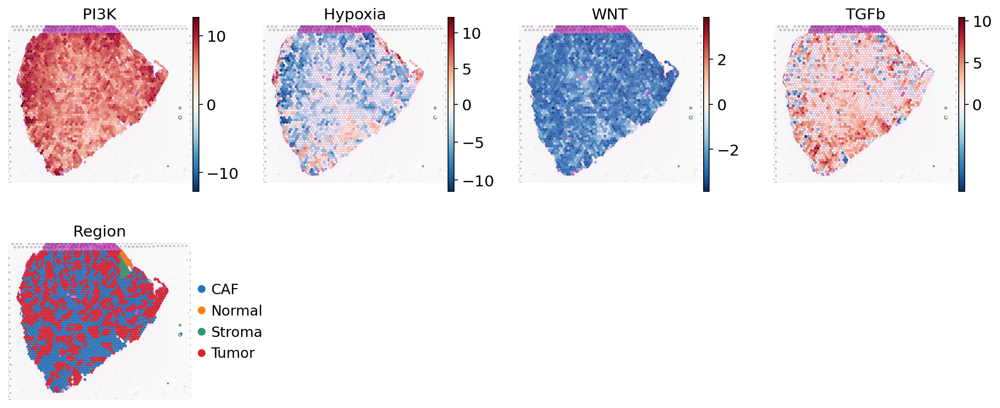

/usr/local/lib/python3.13/dist-packages/scanpy/plotting/_utils.py:509: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


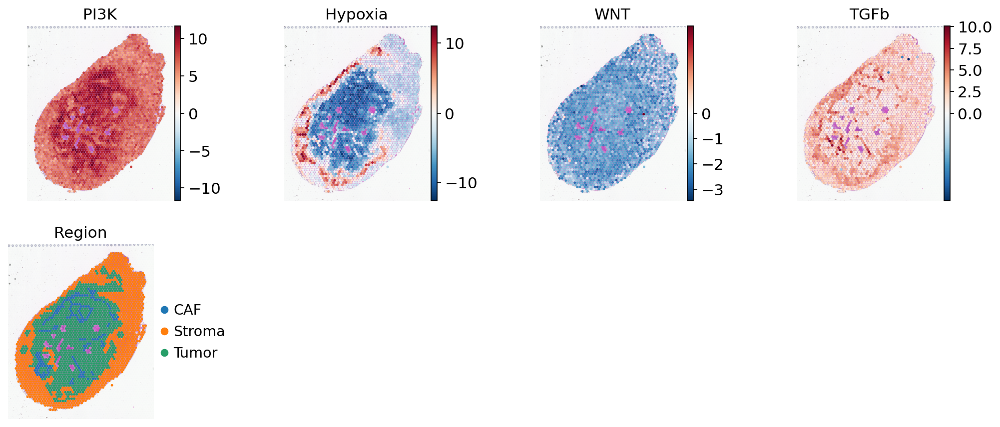

In [ ]:
hms = ["PI3K", "Hypoxia","WNT","TGFb"]
sc.pl.spatial(score[score.obs["sample"]=="HNSCC14"], color=hms + ["Region"], cmap="RdBu_r", vcenter=0, size=1.5,library_id="HNSCC14")
sc.pl.spatial(score[score.obs["sample"]=="HNSCC59"], color=hms + ["Region"], cmap="RdBu_r", vcenter=0, size=1.5,library_id="HNSCC59")


## hm

In [20]:
hallmark = dc.op.hallmark(organism="human")


In [21]:
dc.mt.ulm(data=adata, net=hallmark)


In [22]:
score = dc.pp.get_obsm(adata=adata, key="score_ulm")
score

AnnData object with n_obs × n_vars = 4574 × 50
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'log1p_total_counts_mt', 'clusters', 'leiden', 'gene_niche', 'subtype', '_indices', '_scvi_batch', '_scvi_labels', 'Program_1', 'Program_2', 'Program_3', 'Program_4', 'Program_5', 'Program_6', 'Program_7', 'LAMA2_positive', 'LAMA2_expr', 'Arterial_EC', 'B', 'Basal_Epi', 'CAF_COL14A1', 'CD4T_CXCL13', 'CD4T_GZMB', 'CD4T_PTPRC', 'CD4T_naive', 'CD8T_CXCL13', 'CD8T_GZMA', 'CD8T_GZMK', 'CD8T_naive', 'CD8T_str', 'Capillary_EC', 'Cycling_CAF', 'Cycling_EC', 'Cycling_T', 'Diff_Epi', 'EC_ACKR1', 'EC_PGF', 'EMT_like_Epi', 'Hypoxia_Epi', 'Mac_CXCL5', 'Mac_FOLR2', 'Mac_SPP1', 'Mast', 'Mono_FCN1', 'NK', 'Neutrophil', 'Normal_Epi', 'Plasma', 'Prolif_Epi', '

In [23]:
df = dc.tl.rankby_group(adata=score, groupby="Region", reference="rest", method="t-test_overestim_var")
df = df[df["stat"] > 0]

In [24]:
n_markers = 5
source_markers = (
    df.groupby("group")
    .head(n_markers)
    .drop_duplicates("name")
    .groupby("group")["name"]
    .apply(lambda x: list(x))
    .to_dict()
)
source_markers

{'Normal': ['P53_PATHWAY',
  'TNFA_SIGNALING_VIA_NFKB',
  'APOPTOSIS',
  'IL2_STAT5_SIGNALING',
  'APICAL_SURFACE'],
 'Stroma': ['KRAS_SIGNALING_UP',
  'ALLOGRAFT_REJECTION',
  'EPITHELIAL_MESENCHYMAL_TRANSITION',
  'UV_RESPONSE_DN',
  'INFLAMMATORY_RESPONSE'],
 'Tumor': ['MYC_TARGETS_V1',
  'OXIDATIVE_PHOSPHORYLATION',
  'MTORC1_SIGNALING',
  'PEROXISOME',
  'DNA_REPAIR']}

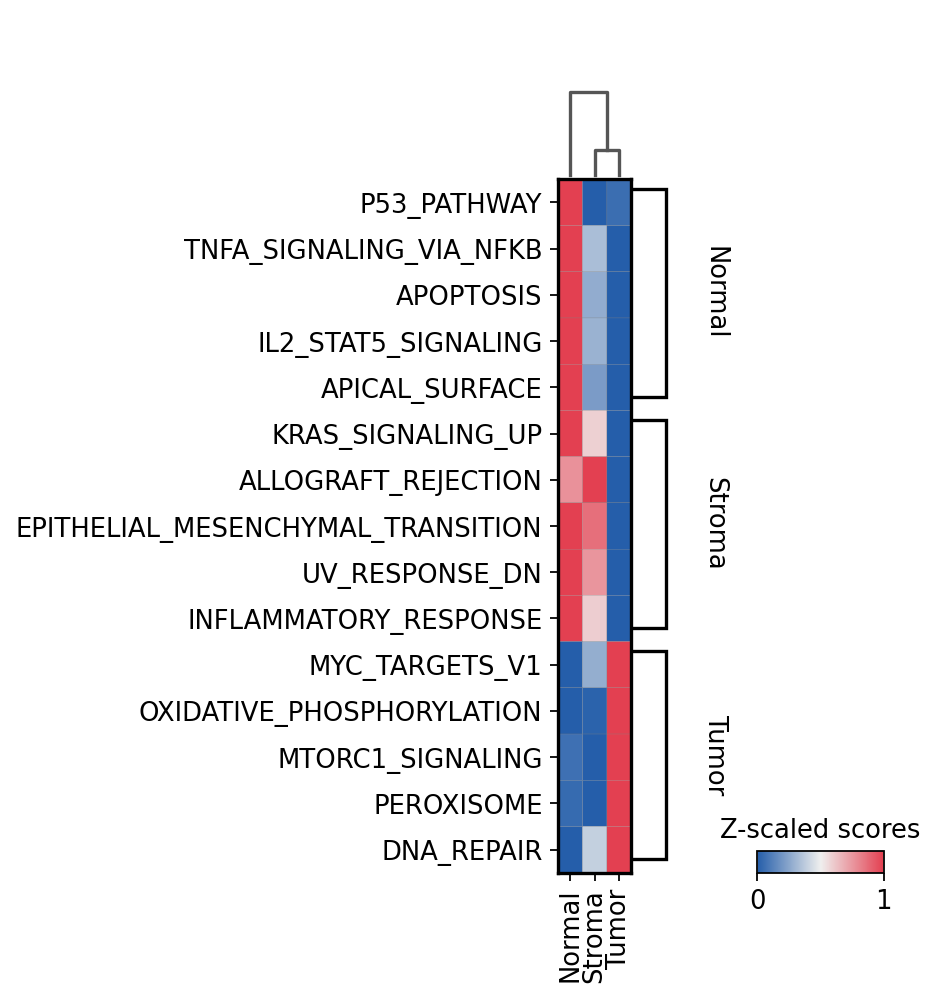

In [25]:
sc.pl.matrixplot(
    adata=score,
    var_names=source_markers,
    groupby="Region",
    dendrogram=True,
    standard_scale="var",
    colorbar_title="Z-scaled scores",
    cmap=dot_map,
    swap_axes=True,
)

In [ ]:
#  ['KRAS_SIGNALING_UP',
#   'ALLOGRAFT_REJECTION',
#   'EPITHELIAL_MESENCHYMAL_TRANSITION',
#   'UV_RESPONSE_DN',
#   'INFLAMMATORY_RESPONSE'],

In [30]:
hms = ["EPITHELIAL_MESENCHYMAL_TRANSITION", "MYOGENESIS","KRAS_SIGNALING_UP","ALLOGRAFT_REJECTION","UV_RESPONSE_DN","INFLAMMATORY_RESPONSE"]
sc.pl.spatial(score[score.obs["sample"]=="HNSCC14"], color=hms + ["Region"], cmap="RdBu_r", vcenter=0, size=1.5,library_id="HNSCC14",)
sc.pl.spatial(score[score.obs["sample"]=="HNSCC59"], color=hms + ["Region"], cmap="RdBu_r", vcenter=0, size=1.5,library_id="HNSCC59")

Output hidden; open in https://colab.research.google.com to view.

In [27]:
import numpy as np
import scipy.sparse as sp
import scanpy as sc

# ========= 参数 =========
SAMPLES = ["HNSCC14", "HNSCC59"]


# 用第2–98百分位作为颜色范围，减弱极端值对色标的影响
# 如果要严格使用最小值–最大值缩放，改成 0.00、1.00
Q_LOW = 0.02
Q_HIGH = 0.98

# 保存用于绘图的对象
scaled_slides = {}

for SAMPLE in SAMPLES:

    slide = score[score.obs["sample"].eq(SAMPLE)].copy()

    if slide.n_obs == 0:
        continue

    color_cols = []

    for pathway in hms:

        # 提取原始通路评分
        x = slide[:, pathway].X
        x = x.toarray().ravel() if sp.issparse(x) else np.asarray(x).ravel()
        x = x.astype(float)

        valid = np.isfinite(x)
        scaled = np.full(x.shape, np.nan)

        if valid.any():
            low, high = np.quantile(x[valid], [Q_LOW, Q_HIGH])

            if high > low:
                scaled[valid] = np.clip(
                    (x[valid] - low) / (high - low),
                    0,
                    1,
                )
            else:
                # 如果分位数相同，退回完整范围
                low, high = x[valid].min(), x[valid].max()

                scaled[valid] = (
                    (x[valid] - low) / (high - low)
                    if high > low else 0.5
                )

        # 单独存到 obs，不覆盖原始评分
        col = f"{pathway}_scaled"
        slide.obs[col] = scaled
        color_cols.append(col)

    # ========= 绘制空间图 =========
    sc.pl.spatial(
        slide,
        color=color_cols + ["Region"],
        title=[f"{p}\n{SAMPLE} | scaled score" for p in hms] + ["Region"],
        library_id=SAMPLE,
        img_key="hires",
        use_raw=False,

        cmap="RdBu_r",
        vmin=0,
        vmax=1,
        vcenter=0.5,

        size=1.5,
        alpha=1,
        alpha_img=0.5,       # 淡化 HE 背景，让评分颜色更清楚
        frameon=False,
        ncols=3,
    )

    scaled_slides[SAMPLE] = slide

Output hidden; open in https://colab.research.google.com to view.

# 距离量化

保存成功: HNSCC14_LAMA2_interface.tiff
文件大小: 1062.3 KB
保存成功: HNSCC14_LAMA2_interface.png
文件大小: 247.3 KB
保存成功: HNSCC14_LAMA2_gradient.tiff
文件大小: 474.4 KB
保存成功: HNSCC14_LAMA2_gradient.png
文件大小: 99.9 KB

输出文件夹: /content/drive/MyDrive/pharynx/visum/figure/tumor_stroma


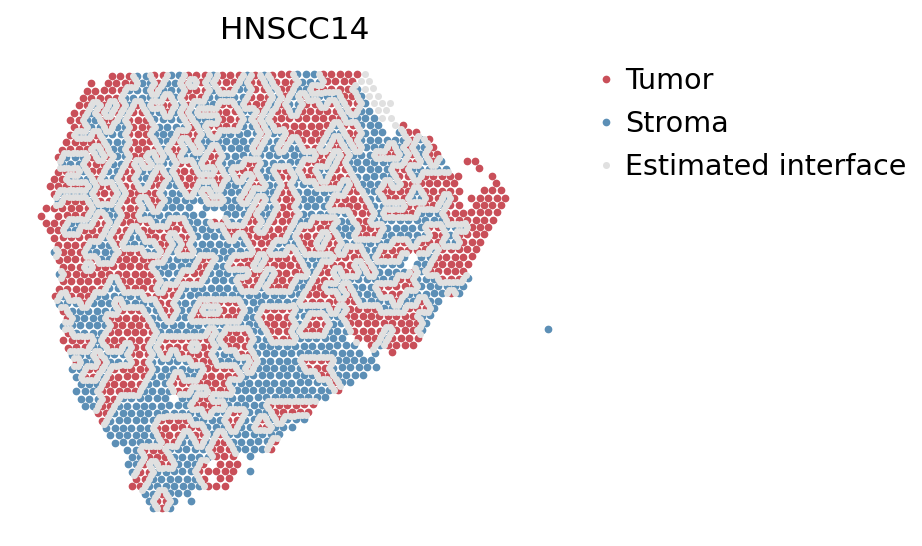

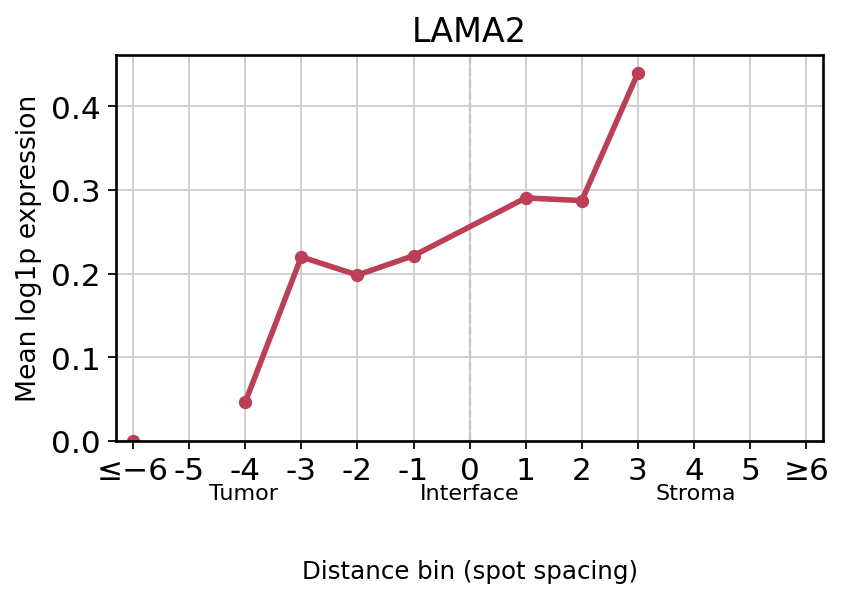

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.spatial import cKDTree
from pathlib import Path

# ========= 参数 =========
SAMPLE = "HNSCC14"        # 改成这张切片的实际 sample 名称
REGION = "Region"
GENE = "LAMA2"

TUMOR_LABEL = "Tumor"
CAPSULE_LABEL = "Stroma"

USE_RAW = True           # 确认 raw.X 是归一化后的 log1p 表达
MAX_BIN = 6               # 第6层及更远的 spot 合并
MIN_SPOTS = 5
ADJ_FACTOR = 1.2          # 跨区域相邻 spot 的最大距离 / spot间距
SAVE = False             # 改为 True 保存 TIFF 和 CSV

outdir = Path("./visum/figure/tumor_CAF")

# ========= 1. 提取样本 =========
slide = adata[adata.obs["sample"].eq(SAMPLE)].copy()

if slide.n_obs < 2:
    raise ValueError(f"{SAMPLE} 的 spot 数不足，请检查 SAMPLE")

region_all = (
    slide.obs[REGION]
    .astype("string")
    .str.strip()
    # .str.lower()
)

# 仅保留 tumor 和被膜
keep = region_all.isin([TUMOR_LABEL, CAPSULE_LABEL])
sub = slide[keep.to_numpy()].copy()
region = region_all.loc[sub.obs_names]

xy_all = np.asarray(slide.obsm["spatial"], dtype=float)
xy = np.asarray(sub.obsm["spatial"], dtype=float)

if not np.isfinite(xy_all).all():
    raise ValueError("spatial 坐标包含缺失值或无穷值")

tumor_mask = region.eq(TUMOR_LABEL).to_numpy(dtype=bool)
capsule_mask = region.eq(CAPSULE_LABEL).to_numpy(dtype=bool)

if not tumor_mask.any() or not capsule_mask.any():
    raise ValueError(
        "需要同时存在 tumor 和 thickened fibrous capsule。\n"
        f"当前标签：{region_all.dropna().unique().tolist()}"
    )

# ========= 2. 估计 spot 中心间距 =========
nn_dist = cKDTree(xy_all).query(xy_all, k=2)[0][:, 1]
valid_dist = nn_dist[np.isfinite(nn_dist) & (nn_dist > 0)]

if valid_dist.size == 0:
    raise ValueError("无法估计 spot 间距")

spacing = np.median(valid_dist)

# ========= 3. 找到 tumor–被膜交界 =========
xy_tumor = xy[tumor_mask]
xy_capsule = xy[capsule_mask]

neighbors = cKDTree(xy_tumor).query_ball_tree(
    cKDTree(xy_capsule),
    r=ADJ_FACTOR * spacing,
)

pairs = np.array(
    [(i, j) for i, js in enumerate(neighbors) for j in js],
    dtype=int,
).reshape(-1, 2)

if len(pairs) == 0:
    raise ValueError(
        "没有找到相邻的 tumor–被膜 spot，"
        "请检查两类标注是否直接接壤。"
    )

# 跨区域相邻 spot 的中点，作为交界参考点
interface_xy = (
    xy_tumor[pairs[:, 0]] + xy_capsule[pairs[:, 1]]
) / 2

interface_xy = np.unique(interface_xy, axis=0)

# ========= 4. 计算距离分层 =========
# 到最近交界参考点的欧氏距离
distance = cKDTree(interface_xy).query(xy, k=1)[0]
distance_units = distance / spacing

# 第1层：(0, 1]；第2层：(1, 2]；以此类推
level = np.maximum(
    1,
    np.ceil(distance_units - 1e-6).astype(int),
)
level = np.minimum(level, MAX_BIN)

# tumor 为负，被膜为正
sign = np.where(tumor_mask, -1, 1)
distance_bin = sign * level

sub.obs["tumor_capsule_distance"] = sign * distance_units
sub.obs["tumor_capsule_bin"] = distance_bin

# ========= 5. 提取表达 =========
source = sub.raw if USE_RAW else sub

if source is None:
    raise ValueError("sub.raw 不存在，请设置 USE_RAW=False")

if GENE not in source.var_names:
    raise ValueError(f"{GENE} 不在所选表达矩阵中")

x = source[:, [GENE]].X
expression = (
    x.toarray().ravel()
    if sp.issparse(x)
    else np.asarray(x).ravel()
).astype(float)

expression[~np.isfinite(expression)] = np.nan

df = pd.DataFrame({
    "region": region.to_numpy(),
    "distance_signed": sign * distance_units,
    "distance_bin": distance_bin,
    "expression": expression,
}, index=sub.obs_names)

# ========= 6. 汇总每层表达，包含0值 =========
bin_order = np.r_[
    np.arange(-MAX_BIN, 0),
    np.arange(1, MAX_BIN + 1),
]

profile = (
    df.groupby("distance_bin")["expression"]
    .agg(
        mean_expression="mean",
        median_expression="median",
        n_spots="count",
    )
    .reindex(bin_order)
)

profile.index.name = "distance_bin"
profile["n_spots"] = profile["n_spots"].fillna(0).astype(int)

y = profile["mean_expression"].where(
    profile["n_spots"] >= MIN_SPOTS
)

# ========= 7. 交界定位检查图 =========
fig_check, ax_check = plt.subplots(figsize=(6, 6))

# 整张切片作为浅灰色背景
ax_check.scatter(
    xy_all[:, 0], xy_all[:, 1],
    s=10, color="#E0E0E0",
    linewidths=0,
)

ax_check.scatter(
    xy_tumor[:, 0], xy_tumor[:, 1],
    s=12, color="#C94F59",##80c2ba
    linewidths=0, label="Tumor",
)

ax_check.scatter(
    xy_capsule[:, 0], xy_capsule[:, 1],
    s=12, color="#5C8FB6",#eba07f
    linewidths=0, label="Stroma",
)

# 不连接中点，避免把不连续的交界强行连起来
ax_check.scatter(
    interface_xy[:, 0], interface_xy[:, 1],
    s=10, color="#E0E0E0",
    linewidths=0, label="Estimated interface",
    zorder=5,
)

ax_check.set_aspect("equal")
ax_check.invert_yaxis()
ax_check.set_axis_off()
ax_check.set_title(f"{SAMPLE}")
ax_check.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False,
)
fig_check.tight_layout()

# ========= 8. 表达梯度图 =========
fig, ax = plt.subplots(figsize=(5.5, 4))

# 两侧分别画；0处没有实际表达观测值
ax.plot(
    profile.index,
    y,
    color="#bb4055",
    linewidth=2.5,
    marker="o",
    markersize=5,
)

ax.axvline(
    0,
    color="0.6",
    linestyle="--",
    linewidth=1,
    zorder=0,
)

ticks = np.arange(-MAX_BIN, MAX_BIN + 1)
labels = [str(i) for i in ticks]
labels[0] = f"≤−{MAX_BIN}"
labels[-1] = f"≥{MAX_BIN}"

ax.set_xticks(ticks)
ax.set_xticklabels(labels)
ax.set_xlim(-MAX_BIN - 0.3, MAX_BIN + 0.3)
ax.set_ylim(bottom=0)

ax.set_title(GENE, fontsize=15)
ax.set_ylabel("Mean log1p expression", fontsize=12)
ax.set_xlabel(
    "Distance bin (spot spacing)",
    labelpad=33,
    fontsize=11,
)

for pos, label in [
    (0.18, "Tumor"),
    (0.50, "Interface"),
    (0.82, "Stroma"),
]:
    ax.text(
        pos, -0.15, label,
        transform=ax.transAxes,
        ha="center",
        fontsize=10,
    )

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

fig.tight_layout()

# ========= 9. 分别保存图片 =========
from pathlib import Path
import matplotlib.pyplot as plt

outdir = Path("./visum/figure/tumor_stroma").resolve()
outdir.mkdir(parents=True, exist_ok=True)

prefix = f"{SAMPLE}_{GENE}"

# 分别保存两个 Figure
figures = {
    "interface": fig_check,
    "gradient": fig,
}

for name, figure in figures.items():

    # TIFF，600 dpi，LZW压缩
    tiff_path = outdir / f"{prefix}_{name}.tiff"

    figure.savefig(
        tiff_path,
        format="tiff",
        dpi=600,
        bbox_inches="tight",
        facecolor="white",
        pil_kwargs={"compression": "tiff_lzw"},
    )

    # PNG，300 dpi
    png_path = outdir / f"{prefix}_{name}.png"

    figure.savefig(
        png_path,
        format="png",
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

    # 检查文件是否存在
    for path in [tiff_path, png_path]:
        if path.exists() and path.stat().st_size > 0:
            print(f"保存成功: {path.name}")
            print(f"文件大小: {path.stat().st_size / 1024:.1f} KB")
        else:
            print(f"保存失败: {path}")

# 保存数据
profile.to_csv(outdir / f"{prefix}_profile.csv")
df.to_csv(outdir / f"{prefix}_spot_data.csv")

print(f"\n输出文件夹: {outdir}")

plt.show()

保存成功: HNSCC59_LAMA2_interface.tiff
文件大小: 1535.9 KB
保存成功: HNSCC59_LAMA2_interface.png
文件大小: 268.0 KB
保存成功: HNSCC59_LAMA2_gradient.tiff
文件大小: 509.5 KB
保存成功: HNSCC59_LAMA2_gradient.png
文件大小: 120.4 KB

输出文件夹: /content/drive/MyDrive/pharynx/visum/figure/tumor_stroma


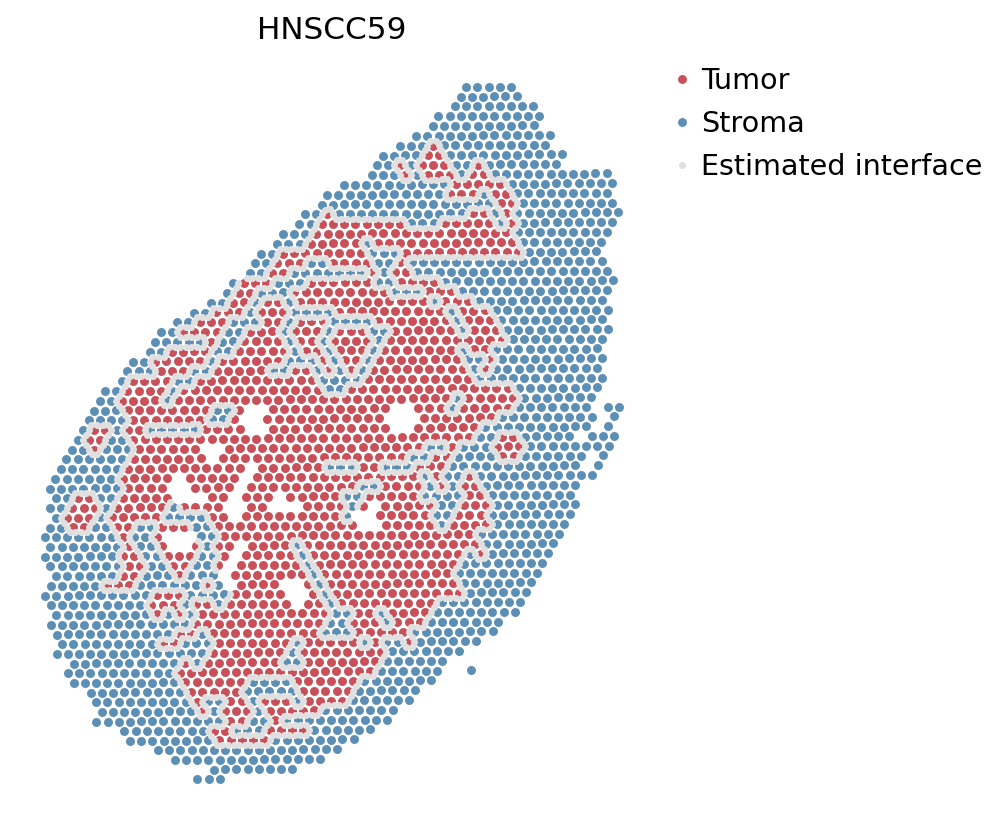

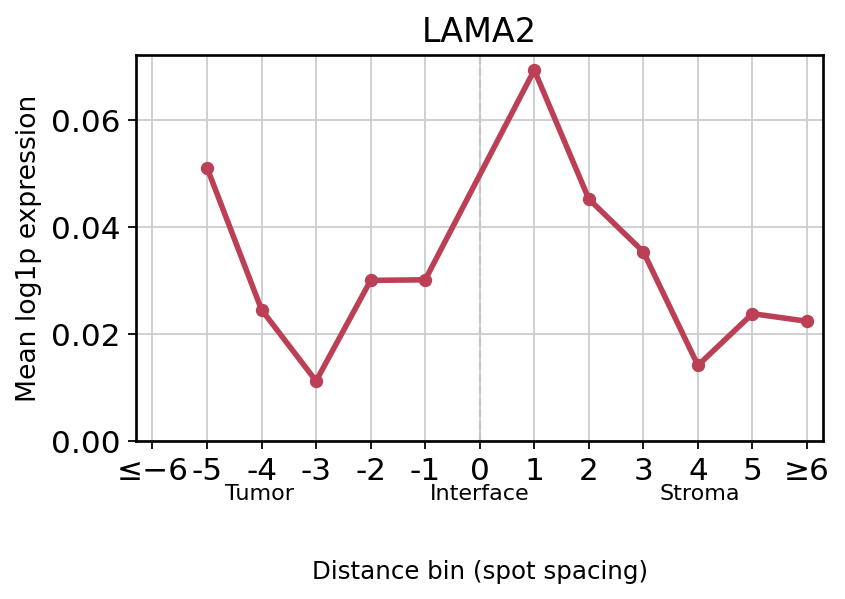

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.spatial import cKDTree
from pathlib import Path

# ========= 参数 =========
SAMPLE = "HNSCC59"        # 改成这张切片的实际 sample 名称
REGION = "Region"
GENE = "LAMA2"

TUMOR_LABEL = "Tumor"
CAPSULE_LABEL = "Stroma"

USE_RAW = True           # 确认 raw.X 是归一化后的 log1p 表达
MAX_BIN = 6               # 第6层及更远的 spot 合并
MIN_SPOTS = 5
ADJ_FACTOR = 1.2          # 跨区域相邻 spot 的最大距离 / spot间距
SAVE = False             # 改为 True 保存 TIFF 和 CSV

outdir = Path("./visum/figure/")

# ========= 1. 提取样本 =========
slide = adata[adata.obs["sample"].eq(SAMPLE)].copy()

if slide.n_obs < 2:
    raise ValueError(f"{SAMPLE} 的 spot 数不足，请检查 SAMPLE")

region_all = (
    slide.obs[REGION]
    .astype("string")
    .str.strip()
    # .str.lower()
)

# 仅保留 tumor 和被膜
keep = region_all.isin([TUMOR_LABEL, CAPSULE_LABEL])
sub = slide[keep.to_numpy()].copy()
region = region_all.loc[sub.obs_names]

xy_all = np.asarray(slide.obsm["spatial"], dtype=float)
xy = np.asarray(sub.obsm["spatial"], dtype=float)

if not np.isfinite(xy_all).all():
    raise ValueError("spatial 坐标包含缺失值或无穷值")

tumor_mask = region.eq(TUMOR_LABEL).to_numpy(dtype=bool)
capsule_mask = region.eq(CAPSULE_LABEL).to_numpy(dtype=bool)

if not tumor_mask.any() or not capsule_mask.any():
    raise ValueError(
        "需要同时存在 tumor 和 thickened fibrous capsule。\n"
        f"当前标签：{region_all.dropna().unique().tolist()}"
    )

# ========= 2. 估计 spot 中心间距 =========
nn_dist = cKDTree(xy_all).query(xy_all, k=2)[0][:, 1]
valid_dist = nn_dist[np.isfinite(nn_dist) & (nn_dist > 0)]

if valid_dist.size == 0:
    raise ValueError("无法估计 spot 间距")

spacing = np.median(valid_dist)

# ========= 3. 找到 tumor–被膜交界 =========
xy_tumor = xy[tumor_mask]
xy_capsule = xy[capsule_mask]

neighbors = cKDTree(xy_tumor).query_ball_tree(
    cKDTree(xy_capsule),
    r=ADJ_FACTOR * spacing,
)

pairs = np.array(
    [(i, j) for i, js in enumerate(neighbors) for j in js],
    dtype=int,
).reshape(-1, 2)

if len(pairs) == 0:
    raise ValueError(
        "没有找到相邻的 tumor–被膜 spot，"
        "请检查两类标注是否直接接壤。"
    )

# 跨区域相邻 spot 的中点，作为交界参考点
interface_xy = (
    xy_tumor[pairs[:, 0]] + xy_capsule[pairs[:, 1]]
) / 2

interface_xy = np.unique(interface_xy, axis=0)

# ========= 4. 计算距离分层 =========
# 到最近交界参考点的欧氏距离
distance = cKDTree(interface_xy).query(xy, k=1)[0]
distance_units = distance / spacing

# 第1层：(0, 1]；第2层：(1, 2]；以此类推
level = np.maximum(
    1,
    np.ceil(distance_units - 1e-6).astype(int),
)
level = np.minimum(level, MAX_BIN)

# tumor 为负，被膜为正
sign = np.where(tumor_mask, -1, 1)
distance_bin = sign * level

sub.obs["tumor_capsule_distance"] = sign * distance_units
sub.obs["tumor_capsule_bin"] = distance_bin

# ========= 5. 提取表达 =========
source = sub.raw if USE_RAW else sub

if source is None:
    raise ValueError("sub.raw 不存在，请设置 USE_RAW=False")

if GENE not in source.var_names:
    raise ValueError(f"{GENE} 不在所选表达矩阵中")

x = source[:, [GENE]].X
expression = (
    x.toarray().ravel()
    if sp.issparse(x)
    else np.asarray(x).ravel()
).astype(float)

expression[~np.isfinite(expression)] = np.nan

df = pd.DataFrame({
    "region": region.to_numpy(),
    "distance_signed": sign * distance_units,
    "distance_bin": distance_bin,
    "expression": expression,
}, index=sub.obs_names)

# ========= 6. 汇总每层表达，包含0值 =========
bin_order = np.r_[
    np.arange(-MAX_BIN, 0),
    np.arange(1, MAX_BIN + 1),
]

profile = (
    df.groupby("distance_bin")["expression"]
    .agg(
        mean_expression="mean",
        median_expression="median",
        n_spots="count",
    )
    .reindex(bin_order)
)

profile.index.name = "distance_bin"
profile["n_spots"] = profile["n_spots"].fillna(0).astype(int)

y = profile["mean_expression"].where(
    profile["n_spots"] >= MIN_SPOTS
)

# ========= 7. 交界定位检查图 =========
fig_check, ax_check = plt.subplots(figsize=(6, 6))

# 整张切片作为浅灰色背景
ax_check.scatter(
    xy_all[:, 0], xy_all[:, 1],
    s=16, color="#E0E0E0",
    linewidths=0,
)

ax_check.scatter(
    xy_tumor[:, 0], xy_tumor[:, 1],
    s=16, color="#C94F59",##80c2ba
    linewidths=0, label="Tumor",
)

ax_check.scatter(
    xy_capsule[:, 0], xy_capsule[:, 1],
    s=16, color="#5C8FB6",#eba07f
    linewidths=0, label="Stroma",
)

# 不连接中点，避免把不连续的交界强行连起来
ax_check.scatter(
    interface_xy[:, 0], interface_xy[:, 1],
    s=10, color="#E0E0E0",
    linewidths=0, label="Estimated interface",
    zorder=5,
)

ax_check.set_aspect("equal")
ax_check.invert_yaxis()
ax_check.set_axis_off()
ax_check.set_title(f"{SAMPLE}")
ax_check.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False,
)
fig_check.tight_layout()

# ========= 8. 表达梯度图 =========
fig, ax = plt.subplots(figsize=(5.5, 4))

# 两侧分别画；0处没有实际表达观测值
ax.plot(
    profile.index,
    y,
    color="#bb4055",
    linewidth=2.5,
    marker="o",
    markersize=5,
)

ax.axvline(
    0,
    color="0.6",
    linestyle="--",
    linewidth=1,
    zorder=0,
)

ticks = np.arange(-MAX_BIN, MAX_BIN + 1)
labels = [str(i) for i in ticks]
labels[0] = f"≤−{MAX_BIN}"
labels[-1] = f"≥{MAX_BIN}"

ax.set_xticks(ticks)
ax.set_xticklabels(labels)
ax.set_xlim(-MAX_BIN - 0.3, MAX_BIN + 0.3)
ax.set_ylim(bottom=0)

ax.set_title(GENE, fontsize=15)
ax.set_ylabel("Mean log1p expression", fontsize=12)
ax.set_xlabel(
    "Distance bin (spot spacing)",
    labelpad=33,
    fontsize=11,
)

for pos, label in [
    (0.18, "Tumor"),
    (0.50, "Interface"),
    (0.82, "Stroma"),
]:
    ax.text(
        pos, -0.15, label,
        transform=ax.transAxes,
        ha="center",
        fontsize=10,
    )

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

fig.tight_layout()

# ========= 9. 分别保存图片 =========
from pathlib import Path
import matplotlib.pyplot as plt

outdir = Path("./visum/figure/tumor_stroma").resolve()
outdir.mkdir(parents=True, exist_ok=True)

prefix = f"{SAMPLE}_{GENE}"

# 分别保存两个 Figure
figures = {
    "interface": fig_check,
    "gradient": fig,
}

for name, figure in figures.items():

    # TIFF，600 dpi，LZW压缩
    tiff_path = outdir / f"{prefix}_{name}.tiff"

    figure.savefig(
        tiff_path,
        format="tiff",
        dpi=600,
        bbox_inches="tight",
        facecolor="white",
        pil_kwargs={"compression": "tiff_lzw"},
    )

    # PNG，300 dpi
    png_path = outdir / f"{prefix}_{name}.png"

    figure.savefig(
        png_path,
        format="png",
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

    # 检查文件是否存在
    for path in [tiff_path, png_path]:
        if path.exists() and path.stat().st_size > 0:
            print(f"保存成功: {path.name}")
            print(f"文件大小: {path.stat().st_size / 1024:.1f} KB")
        else:
            print(f"保存失败: {path}")

# 保存数据
profile.to_csv(outdir / f"{prefix}_profile.csv")
df.to_csv(outdir / f"{prefix}_spot_data.csv")

print(f"\n输出文件夹: {outdir}")

plt.show()

In [33]:
profile_extended = (
    df.groupby("distance_bin")["expression"]
    .agg(
        mean_expression="mean",
        median_expression="median",
        positive_fraction=lambda x: (x.dropna() > 0).mean(),
        positive_mean=lambda x: x[x > 0].mean(),
        n_spots="count",
    )
)

profile_extended["positive_percent"] = (
    profile_extended["positive_fraction"] * 100
)

print(profile_extended)

              mean_expression  median_expression  positive_fraction  \
distance_bin                                                          
-6                   0.038916                0.0           0.250000   
-5                   0.051040                0.0           0.250000   
-4                   0.024520                0.0           0.134454   
-3                   0.011211                0.0           0.065217   
-2                   0.029988                0.0           0.145038   
-1                   0.030099                0.0           0.116402   
 1                   0.069229                0.0           0.197154   
 2                   0.045167                0.0           0.057292   
 3                   0.035310                0.0           0.035971   
 4                   0.014126                0.0           0.018987   
 5                   0.023780                0.0           0.022989   
 6                   0.022361                0.0           0.021390   

     

保存成功：
/content/drive/MyDrive/pharynx/visum/figure/tumor_stroma/LAMA2_combined_gradient_2samples.tiff
/content/drive/MyDrive/pharynx/visum/figure/tumor_stroma/LAMA2_combined_gradient_2samples.png
/content/drive/MyDrive/pharynx/visum/figure/tumor_stroma/LAMA2_combined_profile.csv


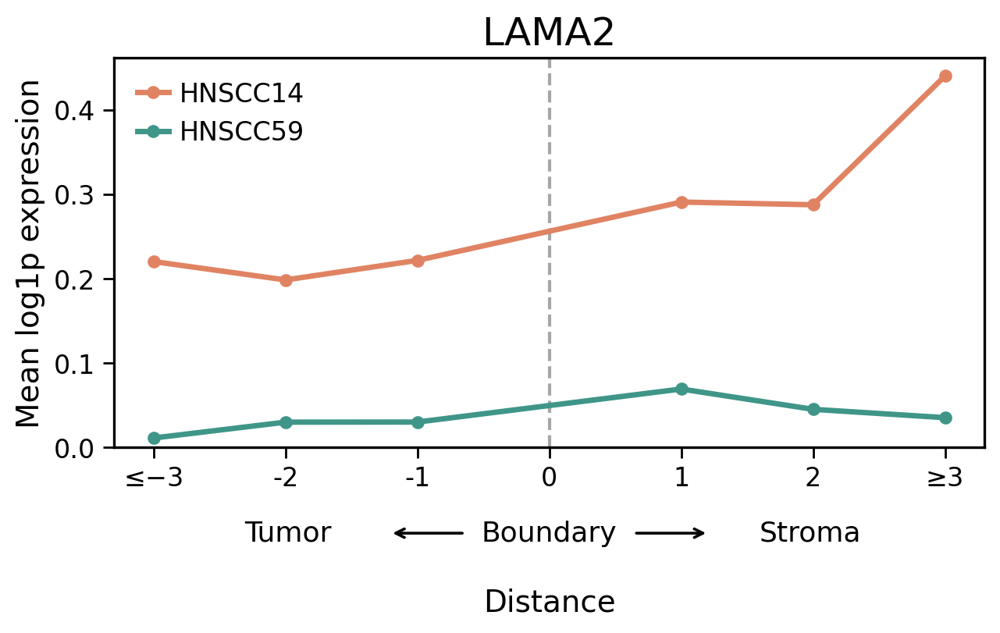

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# =========================
# 参数
# =========================
SAMPLES = ["HNSCC14", "HNSCC59"]
GENE = "LAMA2"
MAX_BIN = 3
MIN_SPOTS = 5
TITLE_SIZE = 18
AXIS_LABEL_SIZE = 14
TICK_SIZE = 12
LEGEND_SIZE = 12
REGION_SIZE = 13
ARROW_SIZE = 18
# 输入目录
indir = Path("./visum/figure/tumor_stroma").resolve()

# 输出目录
outdir = Path("./visum/figure/tumor_stroma").resolve()
outdir.mkdir(parents=True, exist_ok=True)

# 两条折线的颜色
COLORS = {
    "HNSCC14": "#E08363",  # 橙红
    "HNSCC59": "#3F9688",  # 青绿
}

# 恢复 Matplotlib 默认绘图设置
# 避免之前设置的 Arial 字体继续生效
plt.rcdefaults()


# =========================
# 1. 读取两个样本的 profile
# =========================
profiles = {}

for sample in SAMPLES:

    file = indir / f"{sample}_{GENE}_profile.csv"

    if not file.exists():
        raise FileNotFoundError(f"未找到文件: {file}")

    profile = pd.read_csv(
        file,
        index_col="distance_bin"
    )

    profile.index = profile.index.astype(int)

    # 只显示 spot 数量 >= MIN_SPOTS 的距离层
    profile["plot_expression"] = (
        profile["mean_expression"].where(
            profile["n_spots"] >= MIN_SPOTS
        )
    )

    profiles[sample] = profile


# =========================
# 2. 绘制两个样本的折线图
# =========================
# =========================
# 2. 绘制两个样本的折线图
# =========================
fig, ax = plt.subplots(figsize=(6.8, 4.8))

for sample in SAMPLES:

    profile = profiles[sample]

    # 只保留 -MAX_BIN ~ MAX_BIN 范围的数据
    plot_data = (
        profile.loc[
            (profile.index >= -MAX_BIN) &
            (profile.index <= MAX_BIN),
            ["plot_expression"]
        ]
        .dropna()
        .sort_index()
    )

    ax.plot(
        plot_data.index,
        plot_data["plot_expression"],
        color=COLORS[sample],
        linewidth=2.5,
        marker="o",
        markersize=5,
        label=sample,
    )

# =========================
# 3. Boundary 虚线
# =========================
ax.axvline(
    0,
    color="0.65",
    linestyle="--",
    linewidth=1.5,
    zorder=0,
)


# =========================
# 4. 坐标轴
# =========================
ticks = np.arange(-MAX_BIN, MAX_BIN + 1)

tick_labels = [str(i) for i in ticks]

tick_labels[0] = f"≤−{MAX_BIN}"
tick_labels[-1] = f"≥{MAX_BIN}"

ax.set_xticks(ticks)
ax.set_xticklabels(tick_labels)

ax.set_xlim(
    -MAX_BIN - 0.3,
    MAX_BIN + 0.3
)

ax.set_ylim(bottom=0)

# 标题和坐标轴名称
# =========================
# 字体大小设置
# =========================
TITLE_SIZE = 18
AXIS_LABEL_SIZE = 14
TICK_SIZE = 12
LEGEND_SIZE = 12
REGION_SIZE = 13
ARROW_SIZE = 18

# 标题和坐标轴名称
ax.set_title(GENE, fontsize=TITLE_SIZE)
ax.set_ylabel("Mean log1p expression", fontsize=AXIS_LABEL_SIZE)
ax.set_xlabel("Distance", fontsize=AXIS_LABEL_SIZE)

# x轴标题下移
ax.xaxis.set_label_coords(0.5, -0.36)

# 坐标轴边框
for spine in ax.spines.values():
    spine.set_linewidth(1.2)

# 坐标轴刻度
ax.tick_params(
    axis="both",
    width=1.0,
    length=5,
    labelsize=TICK_SIZE,
)

# 图例
ax.legend(
    loc="upper left",
    frameon=False,
    handlelength=1.2,
    handletextpad=0.4,
    fontsize=LEGEND_SIZE,
)


# =========================
# 6. 下方区域标签及箭头
# =========================

# =========================
# 下方区域标签及等长箭头
# =========================
y_text = -0.22

# 文字位置
x_tumor = 0.20
x_boundary = 0.50
x_stroma = 0.80

# 箭头长度控制：左右完全一样
arrow_len = 0.08

# 左箭头中心和右箭头中心
x_left_center = 0.36
x_right_center = 0.64

# 字体大小
REGION_SIZE = 13
ARROW_LW = 1.3

# 三个标签
ax.text(
    x_tumor, y_text, "Tumor",
    transform=ax.transAxes,
    ha="center", va="center",
    fontsize=REGION_SIZE,
    clip_on=False,
)

ax.text(
    x_boundary, y_text, "Boundary",
    transform=ax.transAxes,
    ha="center", va="center",
    fontsize=REGION_SIZE,
    clip_on=False,
)

ax.text(
    x_stroma, y_text, "Stroma",
    transform=ax.transAxes,
    ha="center", va="center",
    fontsize=REGION_SIZE,
    clip_on=False,
)

# 左箭头：Boundary 指向 Tumor
ax.annotate(
    "",
    xy=(x_left_center - arrow_len/2, y_text),   # 箭头尖端（左）
    xytext=(x_left_center + arrow_len/2, y_text),  # 起点（右）
    xycoords=ax.transAxes,
    textcoords=ax.transAxes,
    arrowprops=dict(
        arrowstyle="->",
        lw=ARROW_LW,
        color="black",
        shrinkA=0,
        shrinkB=0,
    ),
    annotation_clip=False,
)

# 右箭头：Boundary 指向 Stroma
ax.annotate(
    "",
    xy=(x_right_center + arrow_len/2, y_text),   # 箭头尖端（右）
    xytext=(x_right_center - arrow_len/2, y_text),  # 起点（左）
    xycoords=ax.transAxes,
    textcoords=ax.transAxes,
    arrowprops=dict(
        arrowstyle="->",
        lw=ARROW_LW,
        color="black",
        shrinkA=0,
        shrinkB=0,
    ),
    annotation_clip=False,
)

# =========================
# 7. 调整图形边距
# =========================
fig.subplots_adjust(
    left=0.14,
    right=0.96,
    top=0.88,
    bottom=0.36,
)


# =========================
# 8. 保存图片
# =========================
tiff_path = (
    outdir /
    f"{GENE}_combined_gradient_2samples.tiff"
)

png_path = (
    outdir /
    f"{GENE}_combined_gradient_2samples.png"
)

# TIFF 600 dpi + LZW压缩
fig.savefig(
    tiff_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
    pil_kwargs={
        "compression": "tiff_lzw"
    },
)

# PNG 300 dpi
fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)


# =========================
# 9. 保存合并后的数据
# =========================
combined_profile = pd.concat(
    profiles,
    names=["sample", "distance_bin"]
)

csv_path = (
    outdir /
    f"{GENE}_combined_profile.csv"
)

combined_profile.to_csv(csv_path)


# =========================
# 10. 显示
# =========================
print("保存成功：")
print(tiff_path)
print(png_path)
print(csv_path)

plt.show()

已保存: LAMA2_mean_expression


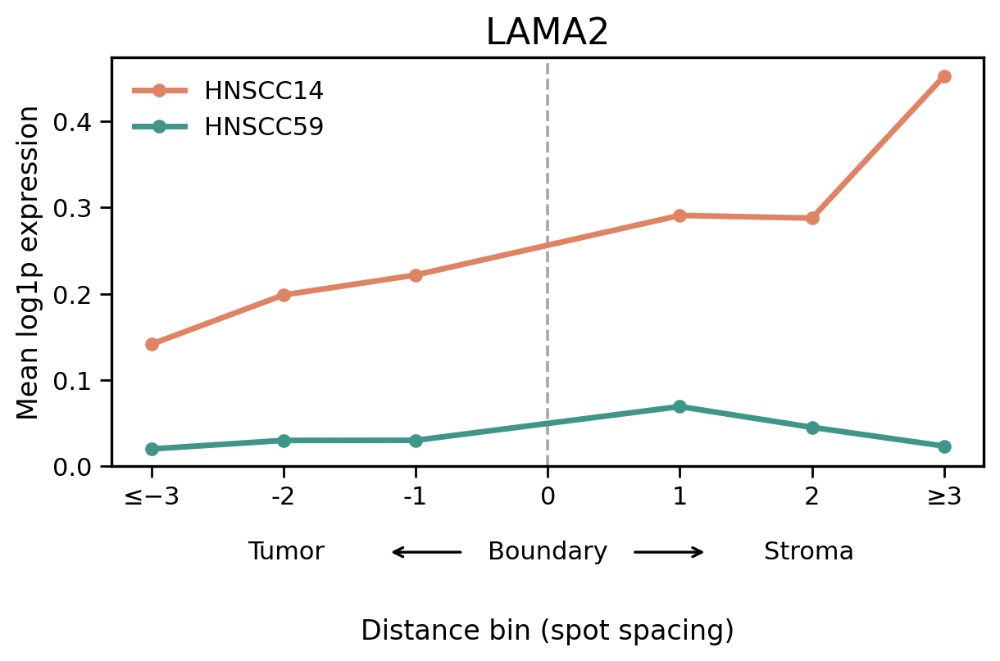

已保存: LAMA2_positive_percent


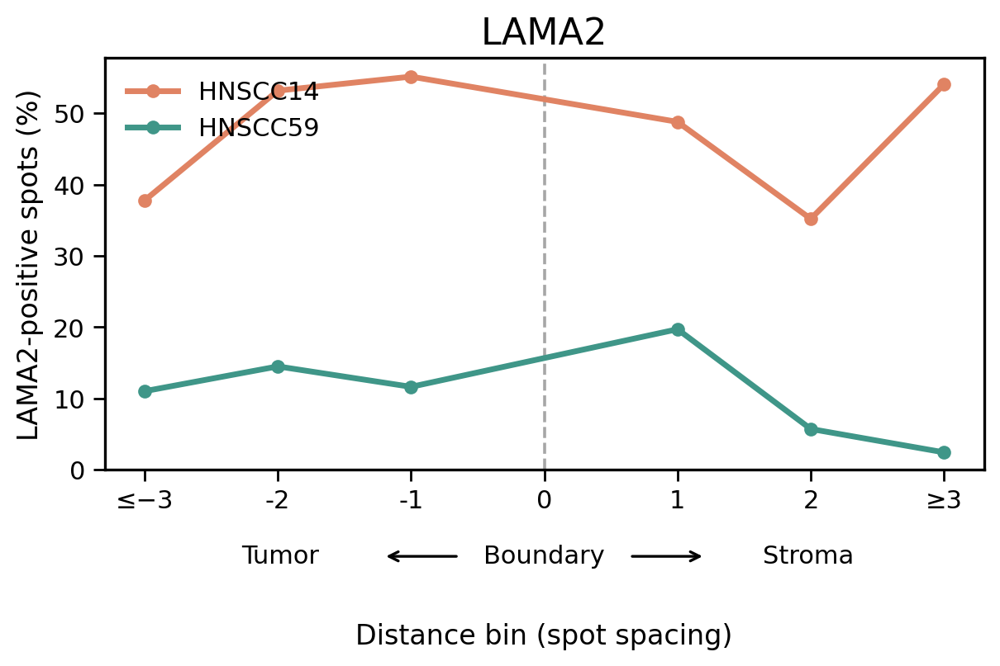

已保存: LAMA2_positive_mean


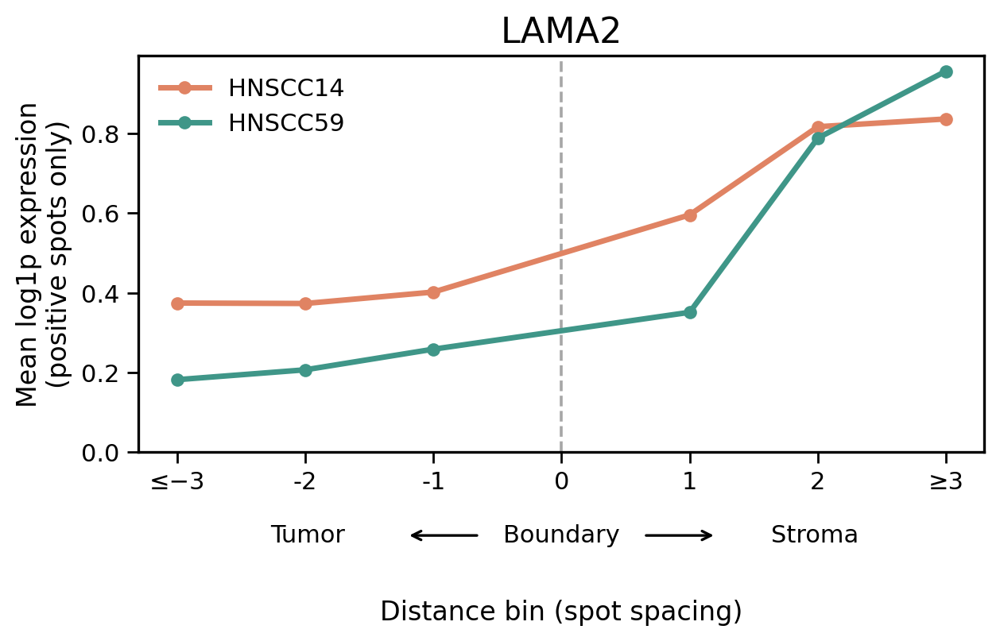


保存完成
输出目录: /content/drive/MyDrive/pharynx/visum/figure/tumor_stroma
                      n_spots  mean_expression  median_expression  n_positive  \
sample  distance_bin                                                            
HNSCC14 -3                 45         0.141425           0.000000          17   
        -2                173         0.198464           0.138187          92   
        -1                885         0.221617           0.206947         488   
         1                875         0.290669           0.000000         427   
         2                179         0.287509           0.000000          63   
         3                 37         0.452091           0.321559          20   
HNSCC59 -3                281         0.020076           0.000000          31   
        -2                262         0.029988           0.000000          38   
        -1                567         0.030099           0.000000          66   
         1                492         0.

In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# =========================
# 1. 参数
# =========================
SAMPLES = ["HNSCC14", "HNSCC59"]
GENE = "LAMA2"

MAX_BIN = 3          # 可修改为 3 或 6
MIN_SPOTS = 5
MIN_POS_SPOTS = 3

CONNECT_BOUNDARY = True

indir = Path("./visum/figure/tumor_stroma").resolve()
outdir = indir
outdir.mkdir(parents=True, exist_ok=True)

COLORS = {
    "HNSCC14": "#E08363",
    "HNSCC59": "#3F9688",
}

TITLE_SIZE = 16
LABEL_SIZE = 12
TICK_SIZE = 11
LEGEND_SIZE = 11
REGION_SIZE = 11

plt.rcdefaults()


# =========================
# 2. 读取 spot 数据
# =========================
bin_order = np.r_[
    np.arange(-MAX_BIN, 0),
    np.arange(1, MAX_BIN + 1)
]

profiles = {}

for sample in SAMPLES:

    file = indir / f"{sample}_{GENE}_spot_data.csv"

    if not file.exists():
        raise FileNotFoundError(
            f"未找到文件：{file}"
        )

    df = pd.read_csv(file, index_col=0)

    df["expression"] = pd.to_numeric(
        df["expression"],
        errors="coerce"
    )

    df["distance_bin"] = pd.to_numeric(
        df["distance_bin"],
        errors="coerce"
    )

    df = df.dropna(
        subset=["expression", "distance_bin"]
    ).copy()

    df = df[
        np.isfinite(df["expression"]) &
        np.isfinite(df["distance_bin"])
    ].copy()

    # 0是边界线，不作为独立距离层
    df = df[df["distance_bin"] != 0].copy()

    # =================================
    # 关键修改：合并超出MAX_BIN的距离层
    # =================================
    # 例如 MAX_BIN=3:
    # -6,-5,-4,-3 -> -3
    #  3, 4, 5, 6 ->  3

    df["plot_bin"] = (
        df["distance_bin"]
        .clip(
            lower=-MAX_BIN,
            upper=MAX_BIN
        )
        .astype(int)
    )

    # =================================
    # 根据原始spot重新计算统计指标
    # =================================
    profile = (
        df.groupby("plot_bin")["expression"]
        .agg(
            n_spots="count",
            mean_expression="mean",
            median_expression="median",
            n_positive=lambda x: (x > 0).sum(),
            positive_mean=lambda x: x[x > 0].mean()
        )
        .reindex(bin_order)
    )

    profile.index.name = "distance_bin"

    profile["n_spots"] = (
        profile["n_spots"]
        .fillna(0)
        .astype(int)
    )

    profile["n_positive"] = (
        profile["n_positive"]
        .fillna(0)
        .astype(int)
    )

    # 阳性spot比例
    profile["positive_percent"] = (
        profile["n_positive"]
        / profile["n_spots"].replace(0, np.nan)
        * 100
    )

    # 至少5个spot
    valid = (
        profile["n_spots"] >= MIN_SPOTS
    )

    profile["plot_mean"] = (
        profile["mean_expression"].where(valid)
    )

    profile["plot_percent"] = (
        profile["positive_percent"].where(valid)
    )

    # 阳性spot至少3个
    valid_positive = (
        valid &
        (profile["n_positive"] >= MIN_POS_SPOTS)
    )

    profile["plot_positive_mean"] = (
        profile["positive_mean"].where(
            valid_positive
        )
    )

    profiles[sample] = profile


# =========================
# 3. 定义三个指标
# =========================
metrics = [
    (
        "plot_mean",
        "Mean log1p expression",
        "mean_expression"
    ),
    (
        "plot_percent",
        "LAMA2-positive spots (%)",
        "positive_percent"
    ),
    (
        "plot_positive_mean",
        "Mean log1p expression\n(positive spots only)",
        "positive_mean"
    ),
]


# =========================
# 4. 绘制折线
# =========================
def draw_metric(ax, metric, ylabel):

    for sample in SAMPLES:

        profile = profiles[sample]
        color = COLORS[sample]

        # Tumor侧
        tumor = profile.loc[
            profile.index < 0
        ]

        # Stroma侧
        stroma = profile.loc[
            profile.index > 0
        ]

        ax.plot(
            tumor.index,
            tumor[metric],
            color=color,
            linewidth=2.5,
            marker="o",
            markersize=5,
            label=sample,
        )

        ax.plot(
            stroma.index,
            stroma[metric],
            color=color,
            linewidth=2.5,
            marker="o",
            markersize=5,
        )

        # 连接边界两侧 -1 和 +1
        if CONNECT_BOUNDARY:

            y_left = profile.loc[-1, metric]
            y_right = profile.loc[1, metric]

            if (
                pd.notna(y_left) and
                pd.notna(y_right)
            ):
                ax.plot(
                    [-1, 1],
                    [y_left, y_right],
                    color=color,
                    linewidth=2.5,
                )

    # Boundary虚线
    ax.axvline(
        0,
        color="0.65",
        linestyle="--",
        linewidth=1.3,
        zorder=0,
    )

    # X轴范围
    ticks = np.arange(
        -MAX_BIN,
        MAX_BIN + 1
    )

    tick_labels = [
        str(i) for i in ticks
    ]

    tick_labels[0] = f"≤−{MAX_BIN}"
    tick_labels[-1] = f"≥{MAX_BIN}"

    ax.set_xticks(ticks)
    ax.set_xticklabels(tick_labels)

    ax.set_xlim(
        -MAX_BIN - 0.3,
        MAX_BIN + 0.3
    )

    ax.set_ylim(bottom=0)

    ax.set_ylabel(
        ylabel,
        fontsize=LABEL_SIZE
    )

    ax.tick_params(
        axis="both",
        labelsize=TICK_SIZE,
        width=1.0,
        length=5,
    )

    for spine in ax.spines.values():
        spine.set_linewidth(1.2)


# =========================
# 5. 下方区域标签及箭头
# =========================
def add_region_labels(ax):

    y_text = -0.21

    region_labels = [
        (0.20, "Tumor"),
        (0.50, "Boundary"),
        (0.80, "Stroma"),
    ]

    for x, label in region_labels:

        ax.text(
            x,
            y_text,
            label,
            transform=ax.transAxes,
            ha="center",
            va="center",
            fontsize=REGION_SIZE,
            clip_on=False,
        )

    # 左右等长箭头
    arrow_len = 0.08

    for center, direction in [
        (0.36, -1),
        (0.64, 1),
    ]:

        start = (
            center -
            direction * arrow_len / 2
        )

        end = (
            center +
            direction * arrow_len / 2
        )

        ax.annotate(
            "",
            xy=(end, y_text),
            xytext=(start, y_text),
            xycoords=ax.transAxes,
            textcoords=ax.transAxes,
            arrowprops=dict(
                arrowstyle="->",
                lw=1.2,
                color="black",
                shrinkA=0,
                shrinkB=0,
            ),
            annotation_clip=False,
        )

    ax.set_xlabel(
        "Distance bin (spot spacing)",
        fontsize=LABEL_SIZE
    )

    ax.xaxis.set_label_coords(
        0.5,
        -0.37
    )


# =========================
# 6. 保存图片函数
# =========================
def save_figure(fig, filename):

    tiff_path = outdir / f"{filename}.tiff"
    png_path = outdir / f"{filename}.png"

    # TIFF 600 dpi + LZW
    fig.savefig(
        tiff_path,
        dpi=600,
        bbox_inches="tight",
        facecolor="white",
        pil_kwargs={
            "compression": "tiff_lzw"
        },
    )

    # PNG 300 dpi
    fig.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

    print("已保存:", filename)


# =========================
# 7. 分别绘制三个指标
# =========================
for metric, ylabel, filename in metrics:

    fig, ax = plt.subplots(
        figsize=(7, 4.8)
    )

    draw_metric(
        ax,
        metric,
        ylabel
    )

    ax.set_title(
        GENE,
        fontsize=TITLE_SIZE
    )

    ax.legend(
        loc="upper left",
        frameon=False,
        fontsize=LEGEND_SIZE,
    )

    add_region_labels(ax)

    fig.subplots_adjust(
        left=0.20,
        right=0.96,
        top=0.88,
        bottom=0.36,
    )

    save_figure(
        fig,
        f"{GENE}_{filename}"
    )

    plt.show()
    plt.close(fig)


# # =========================
# # 8. 同时保留三联图
# # =========================
# fig, axes = plt.subplots(
#     3,
#     1,
#     figsize=(7, 10),
#     sharex=True,
# )

# for ax, (metric, ylabel, _) in zip(
#     axes,
#     metrics
# ):

#     draw_metric(
#         ax,
#         metric,
#         ylabel
#     )

#     ax.tick_params(
#         axis="x",
#         labelbottom=True
#     )

# axes[0].set_title(
#     GENE,
#     fontsize=TITLE_SIZE
# )

# axes[0].legend(
#     loc="upper left",
#     frameon=False,
#     fontsize=LEGEND_SIZE,
# )

# # 三联图只在最下面显示区域箭头
# add_region_labels(axes[-1])

# fig.subplots_adjust(
#     left=0.20,
#     right=0.96,
#     top=0.95,
#     bottom=0.17,
#     hspace=0.32,
# )

# save_figure(
#     fig,
#     f"{GENE}_three_metrics_combined"
# )

# plt.show()
# plt.close(fig)


# =========================
# 9. 保存合并统计数据
# =========================
combined_profile = pd.concat(
    profiles,
    names=["sample", "distance_bin"]
)

csv_path = (
    outdir /
    f"{GENE}_three_metrics.csv"
)

combined_profile.to_csv(csv_path)

print("\n保存完成")
print("输出目录:", outdir)
print(combined_profile)

#expr

共同高表达阈值：0.5305
阈值来源：all_spots
INFO     Creating graph using `None` transform and `1` libraries.                                                  


  0%|          | 0/999 [00:00<?, ?/s]

INFO     Creating graph using `None` transform and `1` libraries.                                                  


  0%|          | 0/999 [00:00<?, ?/s]


每个样本的统计结果：
         n_spots  mean_expression  median_expression  q25_expression  q75_expression  detected_pct  mean_detected_expression  high_expression_pct  high_threshold threshold_basis  Moran_I  Moran_p_perm  isolated_spots
sample                                                                                                                                                                                                                  
HNSCC14     2209           0.2553             0.1391             0.0          0.4549       50.6111                    0.5045               18.651          0.5305       all_spots   0.0283         0.002               2
HNSCC59     2365           0.0367             0.0000             0.0          0.0000       10.8668                    0.3374                1.945          0.5305       all_spots   0.0448         0.001               1


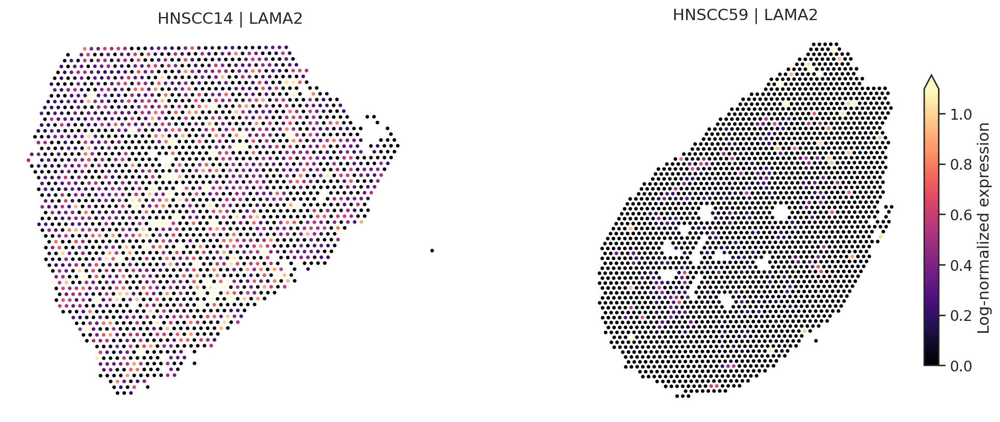

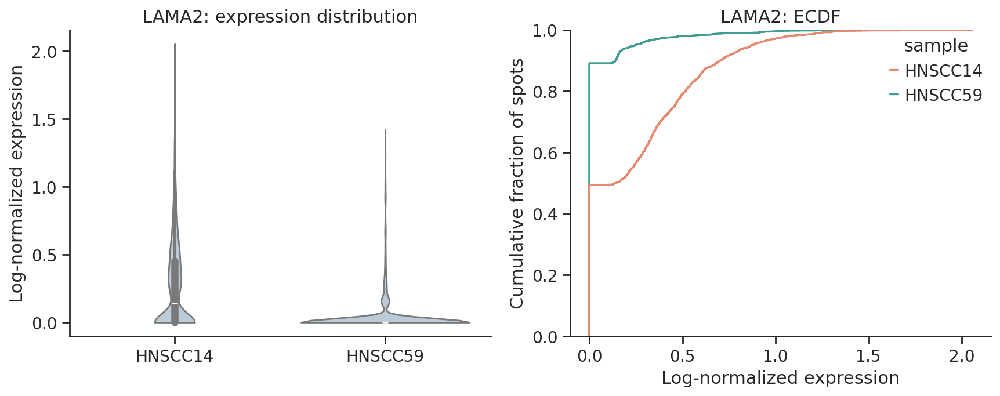

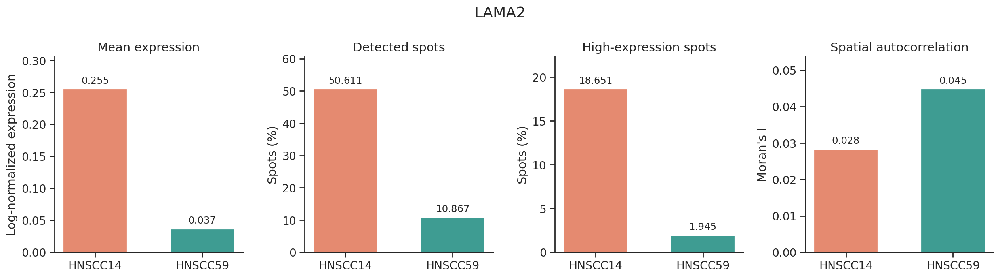


结果已保存至：/content/drive/MyDrive/pharynx/figures/LAMA2_two_samples


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp
import anndata as ad
import squidpy as sq

from pathlib import Path
from matplotlib.colors import Normalize

# ============================================================
# 1. 参数
# ============================================================
GENE = "LAMA2"                 # 修改为目标基因
SAMPLE_COL = "sample"
SAMPLES = ["HNSCC14", "HNSCC59"]

SOURCE = "X"                    # "X" 或 "counts"
TARGET_SUM = 1e4                 # 仅 SOURCE="counts" 时使用
HIGH_QUANTILE = 0.90             # 两个样本共用的高表达阈值
N_PERMS = 999

OUTDIR = Path(f"./figures/{GENE}_two_samples")
OUTDIR.mkdir(parents=True, exist_ok=True)

PALETTE = {
    "HNSCC14": "#E58A70",
    "HNSCC59": "#3E9C92",
}

sns.set_theme(style="ticks", context="notebook", font_scale=1.15)

def to_vector(x):
    if sp.issparse(x):
        return x.toarray().ravel()
    return np.asarray(x).ravel()

def save_figure(fig, name):
    fig.savefig(
        OUTDIR / f"{name}.tiff",
        dpi=600,
        bbox_inches="tight",
        pil_kwargs={"compression": "tiff_lzw"},
    )
    plt.show()
    plt.close(fig)


# ============================================================
# 2. 检查数据，只提取目标基因，不复制整个表达矩阵
# ============================================================
if SAMPLE_COL not in adata.obs:
    raise KeyError(f"adata.obs 中没有 {SAMPLE_COL}")

if not adata.var_names.is_unique:
    raise ValueError("adata.var_names 存在重复，请先检查重复基因名。")

if GENE not in adata.var_names:
    raise KeyError(f"{GENE} 不在 adata.var_names 中")

if "spatial" not in adata.obsm:
    raise KeyError("缺少 adata.obsm['spatial']，需要先恢复空间坐标。")

sample_values = adata.obs[SAMPLE_COL].astype(str)
mask = sample_values.isin(SAMPLES).to_numpy()

# 如有组织标记，仅纳入组织内 spot
if "in_tissue" in adata.obs:
    in_tissue = pd.to_numeric(
        adata.obs["in_tissue"], errors="coerce"
    ).eq(1).to_numpy()
    mask &= in_tissue

idx = np.flatnonzero(mask)
gene_idx = adata.var_names.get_loc(GENE)

for sample in SAMPLES:
    if not (sample_values.iloc[idx] == sample).any():
        raise ValueError(f"没有找到 {sample} 的有效组织内 spot")

# 原始计数：如存在，用于判断是否检出
raw_gene = None
if "counts" in adata.layers:
    raw_gene = to_vector(
        adata.layers["counts"][idx, :][:, gene_idx]
    )

if SOURCE == "counts":
    if raw_gene is None:
        raise KeyError(
            "没有 adata.layers['counts']。"
            "若 X 已是归一化后的 log1p 表达，可设置 SOURCE='X'。"
        )

    # 分母应包含检测到的全部基因，不应只保留 HVG
    total_counts = to_vector(
        adata.layers["counts"][idx, :].sum(axis=1)
    )

    if np.any(total_counts <= 0):
        raise ValueError("存在总 counts 为 0 的 spot，请先过滤。")

    expr = np.log1p(raw_gene / total_counts * TARGET_SUM)
    expr_label = "log1p(counts per 10,000)"

elif SOURCE == "X":
    expr = to_vector(adata.X[idx, :][:, gene_idx])
    expr_label = "Log-normalized expression"

else:
    raise ValueError("SOURCE 只能是 'X' 或 'counts'")

if not np.isfinite(expr).all() or np.any(expr < 0):
    raise ValueError(
        "表达数据存在缺失、无穷值或负值。"
        "请使用非负的 log1p 归一化表达，不使用 scale 后的数据。"
    )

coords = np.asarray(adata.obsm["spatial"])[idx, :2]
if not np.isfinite(coords).all():
    raise ValueError("空间坐标包含缺失或无穷值")

df = pd.DataFrame(
    {
        "sample": sample_values.iloc[idx].to_numpy(),
        "expression": expr,
        "detected": (raw_gene > 0) if raw_gene is not None else (expr > 0),
        "x": coords[:, 0],
        "y": coords[:, 1],
    },
    index=adata.obs_names[idx],
)
df.index.name = "spot"

if raw_gene is None:
    print("检出状态由 X > 0 推导；要求 X 未经插补、平滑或 scale。")


# ============================================================
# 3. 两个样本使用同一个高表达阈值
# ============================================================
positive_expr = df.loc[df["expression"] > 0, "expression"]

if positive_expr.empty:
    raise ValueError(f"{GENE} 在两个样本中均未检出。")

high_threshold = float(df["expression"].quantile(HIGH_QUANTILE))
threshold_basis = "all_spots"

# 基因稀疏时，全部 spot 的 P90 可能是 0
if high_threshold <= 0:
    high_threshold = float(positive_expr.quantile(HIGH_QUANTILE))
    threshold_basis = "positive_spots"
    print("全部 spot 的 P90 为 0，改用合并后阳性 spot 的 P90。")

# 严格超过阈值；有并列值时比例不一定等于 10%
df["high_expression"] = df["expression"] > high_threshold

print(f"共同高表达阈值：{high_threshold:.4f}")
print(f"阈值来源：{threshold_basis}")


# ============================================================
# 4. 每个样本分别计算统计指标及 Moran's I
# ============================================================
rows = []

for sample in SAMPLES:
    sub = df.loc[df["sample"] == sample].copy()
    x = sub["expression"].to_numpy()

    # 仅含一个基因的小对象，用于空间计算
    a = ad.AnnData(
        X=x.reshape(-1, 1),
        obs=pd.DataFrame(index=sub.index),
        var=pd.DataFrame(index=[GENE]),
    )
    a.obsm["spatial"] = sub[["x", "y"]].to_numpy()

    # 兼容新版/旧版 Squidpy；经典 Visium 使用一圈六邻域
    if hasattr(sq.gr, "spatial_neighbors_grid"):
        sq.gr.spatial_neighbors_grid(
            a, n_neighs=6, n_rings=1
        )
    else:
        sq.gr.spatial_neighbors(
            a, coord_type="grid", n_neighs=6, n_rings=1
        )

    moran_i = np.nan
    moran_p = np.nan

    degree = np.asarray(
        a.obsp["spatial_connectivities"].sum(axis=1)
    ).ravel()

    if len(x) >= 3 and np.ptp(x) > 0 and degree.sum() > 0:
        sq.gr.spatial_autocorr(
            a,
            genes=[GENE],
            mode="moran",
            use_raw=False,
            n_perms=N_PERMS,
            two_tailed=True,
            corr_method=None,
            seed=42,
            n_jobs=1,
        )
        moran_i = float(a.uns["moranI"].loc[GENE, "I"])
        moran_p = float(a.uns["moranI"].loc[GENE, "pval_sim"])
    else:
        print(f"{sample}：表达无变异或有效邻接不足，Moran's I 记为 NA。")

    detected_expr = sub.loc[sub["detected"], "expression"]

    rows.append(
        {
            "sample": sample,
            "n_spots": len(sub),
            "mean_expression": x.mean(),
            "median_expression": np.median(x),
            "q25_expression": np.quantile(x, 0.25),
            "q75_expression": np.quantile(x, 0.75),
            "detected_pct": sub["detected"].mean() * 100,
            "mean_detected_expression": detected_expr.mean(),
            "high_expression_pct": sub["high_expression"].mean() * 100,
            "high_threshold": high_threshold,
            "threshold_basis": threshold_basis,
            "Moran_I": moran_i,
            "Moran_p_perm": moran_p,
            "isolated_spots": int((degree == 0).sum()),
        }
    )

summary = pd.DataFrame(rows).set_index("sample")

print("\n每个样本的统计结果：")
print(summary.round(4).to_string())

summary.to_csv(OUTDIR / f"{GENE}_sample_summary.csv")
df.to_csv(OUTDIR / f"{GENE}_spot_expression.csv")


# ============================================================
# 5. 空间表达图：统一色标
#    不依赖组织图片；坐标来自 obsm["spatial"]
# ============================================================
# 仅绘图时截断顶部 1% 的颜色，统计仍使用未截断数据
vmax = max(
    float(df["expression"].quantile(0.99)),
    float(positive_expr.min()),
)
norm = Normalize(vmin=0, vmax=vmax)

fig, axes = plt.subplots(
    1, 2, figsize=(12, 5), layout="constrained"
)

for ax, sample in zip(axes, SAMPLES):
    sub = df.loc[df["sample"] == sample]

    sca = ax.scatter(
        sub["x"],
        sub["y"],
        c=sub["expression"],
        cmap="magma",
        norm=norm,
        s=10,                 # 根据 spot 数调整大小
        linewidths=0,
        rasterized=True,
    )

    ax.set_title(f"{sample} | {GENE}")
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.axis("off")

cbar = fig.colorbar(
    sca, ax=axes, shrink=0.75, pad=0.02, extend="max"
)
cbar.set_label(expr_label)

save_figure(fig, f"{GENE}_spatial")


# ============================================================
# 6. 表达分布：小提琴图 + ECDF
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

sns.violinplot(
    data=df,
    x="sample",
    y="expression",
    order=SAMPLES,
    color="#B6CCDC",
    inner="box",
    cut=0,
    ax=axes[0],
)
axes[0].set(
    xlabel="",
    ylabel=expr_label,
    title=f"{GENE}: expression distribution",
)

sns.ecdfplot(
    data=df,
    x="expression",
    hue="sample",
    hue_order=SAMPLES,
    palette=PALETTE,
    ax=axes[1],
)
axes[1].set(
    xlabel=expr_label,
    ylabel="Cumulative fraction of spots",
    title=f"{GENE}: ECDF",
)

sns.despine()
fig.tight_layout()
save_figure(fig, f"{GENE}_expression_distribution")


# ============================================================
# 7. 四项核心指标
# ============================================================
metrics = [
    ("mean_expression", "Mean expression", expr_label),
    ("detected_pct", "Detected spots", "Spots (%)"),
    ("high_expression_pct", "High-expression spots", "Spots (%)"),
    ("Moran_I", "Spatial autocorrelation", "Moran's I"),
]

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))

for ax, (column, title, ylabel) in zip(axes, metrics):
    values = summary.loc[SAMPLES, column].to_numpy(dtype=float)

    bars = ax.bar(
        SAMPLES,
        values,
        color=[PALETTE[s] for s in SAMPLES],
        width=0.6,
    )

    labels = [
        f"{v:.3f}" if np.isfinite(v) else "NA"
        for v in values
    ]
    ax.bar_label(bars, labels=labels, padding=4, fontsize=11)
    ax.set(title=title, ylabel=ylabel)
    ax.margins(y=0.2)

    if column != "Moran_I":
        ax.set_ylim(bottom=0)
    else:
        ax.axhline(0, color="grey", linewidth=0.8)

sns.despine()
fig.suptitle(GENE, fontsize=17)
fig.tight_layout()
save_figure(fig, f"{GENE}_quantitative_comparison")

print(f"\n结果已保存至：{OUTDIR.resolve()}")

共同高表达阈值：5.0000
阈值来源：all_spots
INFO     Creating graph using `None` transform and `1` libraries.                                                  


  0%|          | 0/999 [00:00<?, ?/s]

INFO     Creating graph using `None` transform and `1` libraries.                                                  


  0%|          | 0/999 [00:00<?, ?/s]


每个样本的统计结果：
         n_spots  mean_expression  median_expression  q25_expression  q75_expression  detected_pct  mean_detected_expression  high_expression_pct  high_threshold threshold_basis  Moran_I  Moran_p_perm  isolated_spots
sample                                                                                                                                                                                                                  
HNSCC14     2213           0.2092                0.0             0.0             0.0       15.5445                    1.3459               0.0904             5.0       all_spots   0.1842         0.001               5
HNSCC59     2427           2.5674                1.0             0.0             4.0       69.6333                    3.6870              15.0391             5.0       all_spots   0.5278         0.001              10


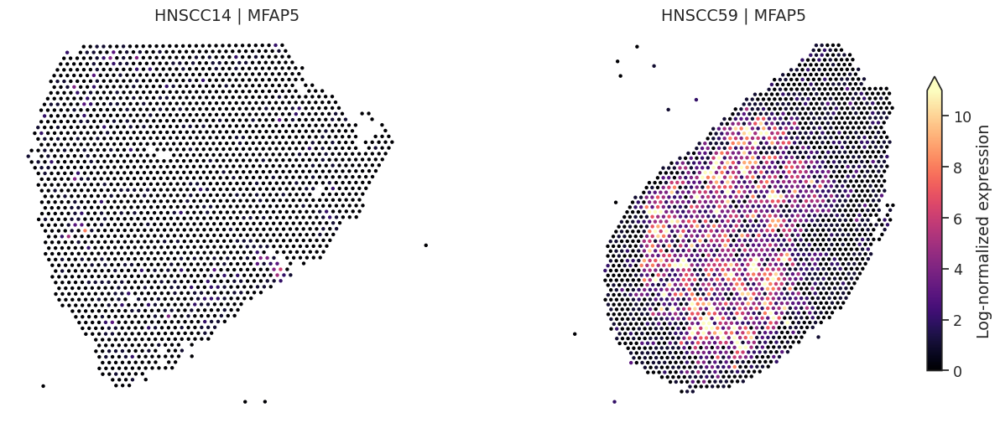

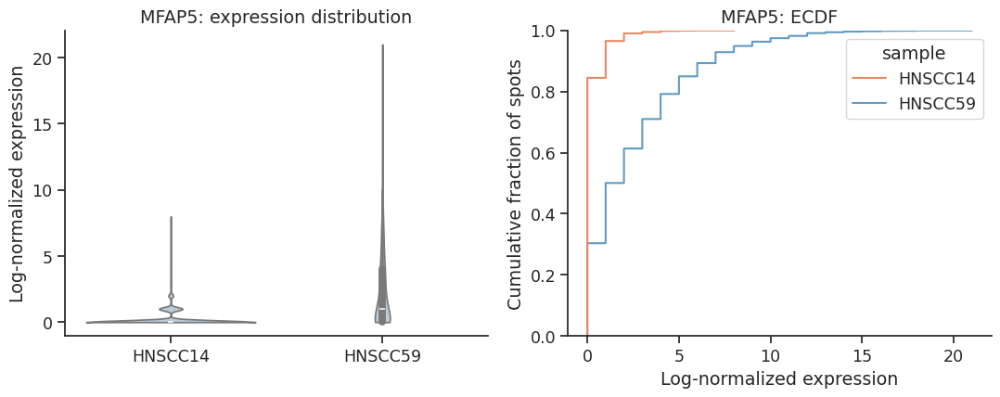

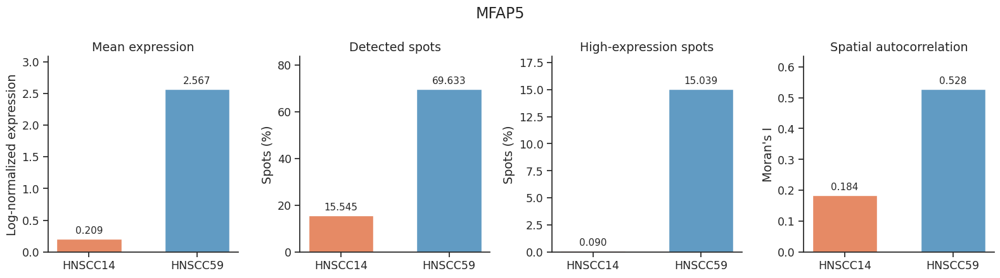


结果已保存至：/content/drive/MyDrive/pharynx/figures/MFAP5_two_samples


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp
import anndata as ad
import squidpy as sq

from pathlib import Path
from matplotlib.colors import Normalize

# ============================================================
# 1. 参数
# ============================================================
GENE = "MFAP5"                 # 修改为目标基因
SAMPLE_COL = "sample"
SAMPLES = ["HNSCC14", "HNSCC59"]

SOURCE = "X"                    # "X" 或 "counts"
TARGET_SUM = 1e4                 # 仅 SOURCE="counts" 时使用
HIGH_QUANTILE = 0.90             # 两个样本共用的高表达阈值
N_PERMS = 999

OUTDIR = Path(f"./figures/{GENE}_two_samples")
OUTDIR.mkdir(parents=True, exist_ok=True)

PALETTE = {
    "HNSCC14": "#E68A65",
    "HNSCC59": "#619BC3",
}

sns.set_theme(style="ticks", context="notebook", font_scale=1.15)

def to_vector(x):
    if sp.issparse(x):
        return x.toarray().ravel()
    return np.asarray(x).ravel()

def save_figure(fig, name):
    fig.savefig(
        OUTDIR / f"{name}.tiff",
        dpi=600,
        bbox_inches="tight",
        pil_kwargs={"compression": "tiff_lzw"},
    )
    plt.show()
    plt.close(fig)


# ============================================================
# 2. 检查数据，只提取目标基因，不复制整个表达矩阵
# ============================================================
if SAMPLE_COL not in adata.obs:
    raise KeyError(f"adata.obs 中没有 {SAMPLE_COL}")

if not adata.var_names.is_unique:
    raise ValueError("adata.var_names 存在重复，请先检查重复基因名。")

if GENE not in adata.var_names:
    raise KeyError(f"{GENE} 不在 adata.var_names 中")

if "spatial" not in adata.obsm:
    raise KeyError("缺少 adata.obsm['spatial']，需要先恢复空间坐标。")

sample_values = adata.obs[SAMPLE_COL].astype(str)
mask = sample_values.isin(SAMPLES).to_numpy()

# 如有组织标记，仅纳入组织内 spot
if "in_tissue" in adata.obs:
    in_tissue = pd.to_numeric(
        adata.obs["in_tissue"], errors="coerce"
    ).eq(1).to_numpy()
    mask &= in_tissue

idx = np.flatnonzero(mask)
gene_idx = adata.var_names.get_loc(GENE)

for sample in SAMPLES:
    if not (sample_values.iloc[idx] == sample).any():
        raise ValueError(f"没有找到 {sample} 的有效组织内 spot")

# 原始计数：如存在，用于判断是否检出
raw_gene = None
if "counts" in adata.layers:
    raw_gene = to_vector(
        adata.layers["counts"][idx, :][:, gene_idx]
    )

if SOURCE == "counts":
    if raw_gene is None:
        raise KeyError(
            "没有 adata.layers['counts']。"
            "若 X 已是归一化后的 log1p 表达，可设置 SOURCE='X'。"
        )

    # 分母应包含检测到的全部基因，不应只保留 HVG
    total_counts = to_vector(
        adata.layers["counts"][idx, :].sum(axis=1)
    )

    if np.any(total_counts <= 0):
        raise ValueError("存在总 counts 为 0 的 spot，请先过滤。")

    expr = np.log1p(raw_gene / total_counts * TARGET_SUM)
    expr_label = "log1p(counts per 10,000)"

elif SOURCE == "X":
    expr = to_vector(adata.X[idx, :][:, gene_idx])
    expr_label = "Log-normalized expression"

else:
    raise ValueError("SOURCE 只能是 'X' 或 'counts'")

if not np.isfinite(expr).all() or np.any(expr < 0):
    raise ValueError(
        "表达数据存在缺失、无穷值或负值。"
        "请使用非负的 log1p 归一化表达，不使用 scale 后的数据。"
    )

coords = np.asarray(adata.obsm["spatial"])[idx, :2]
if not np.isfinite(coords).all():
    raise ValueError("空间坐标包含缺失或无穷值")

df = pd.DataFrame(
    {
        "sample": sample_values.iloc[idx].to_numpy(),
        "expression": expr,
        "detected": (raw_gene > 0) if raw_gene is not None else (expr > 0),
        "x": coords[:, 0],
        "y": coords[:, 1],
    },
    index=adata.obs_names[idx],
)
df.index.name = "spot"

if raw_gene is None:
    print("检出状态由 X > 0 推导；要求 X 未经插补、平滑或 scale。")


# ============================================================
# 3. 两个样本使用同一个高表达阈值
# ============================================================
positive_expr = df.loc[df["expression"] > 0, "expression"]

if positive_expr.empty:
    raise ValueError(f"{GENE} 在两个样本中均未检出。")

high_threshold = float(df["expression"].quantile(HIGH_QUANTILE))
threshold_basis = "all_spots"

# 基因稀疏时，全部 spot 的 P90 可能是 0
if high_threshold <= 0:
    high_threshold = float(positive_expr.quantile(HIGH_QUANTILE))
    threshold_basis = "positive_spots"
    print("全部 spot 的 P90 为 0，改用合并后阳性 spot 的 P90。")

# 严格超过阈值；有并列值时比例不一定等于 10%
df["high_expression"] = df["expression"] > high_threshold

print(f"共同高表达阈值：{high_threshold:.4f}")
print(f"阈值来源：{threshold_basis}")


# ============================================================
# 4. 每个样本分别计算统计指标及 Moran's I
# ============================================================
rows = []

for sample in SAMPLES:
    sub = df.loc[df["sample"] == sample].copy()
    x = sub["expression"].to_numpy()

    # 仅含一个基因的小对象，用于空间计算
    a = ad.AnnData(
        X=x.reshape(-1, 1),
        obs=pd.DataFrame(index=sub.index),
        var=pd.DataFrame(index=[GENE]),
    )
    a.obsm["spatial"] = sub[["x", "y"]].to_numpy()

    # 兼容新版/旧版 Squidpy；经典 Visium 使用一圈六邻域
    if hasattr(sq.gr, "spatial_neighbors_grid"):
        sq.gr.spatial_neighbors_grid(
            a, n_neighs=6, n_rings=1
        )
    else:
        sq.gr.spatial_neighbors(
            a, coord_type="grid", n_neighs=6, n_rings=1
        )

    moran_i = np.nan
    moran_p = np.nan

    degree = np.asarray(
        a.obsp["spatial_connectivities"].sum(axis=1)
    ).ravel()

    if len(x) >= 3 and np.ptp(x) > 0 and degree.sum() > 0:
        sq.gr.spatial_autocorr(
            a,
            genes=[GENE],
            mode="moran",
            use_raw=False,
            n_perms=N_PERMS,
            two_tailed=True,
            corr_method=None,
            seed=42,
            n_jobs=1,
        )
        moran_i = float(a.uns["moranI"].loc[GENE, "I"])
        moran_p = float(a.uns["moranI"].loc[GENE, "pval_sim"])
    else:
        print(f"{sample}：表达无变异或有效邻接不足，Moran's I 记为 NA。")

    detected_expr = sub.loc[sub["detected"], "expression"]

    rows.append(
        {
            "sample": sample,
            "n_spots": len(sub),
            "mean_expression": x.mean(),
            "median_expression": np.median(x),
            "q25_expression": np.quantile(x, 0.25),
            "q75_expression": np.quantile(x, 0.75),
            "detected_pct": sub["detected"].mean() * 100,
            "mean_detected_expression": detected_expr.mean(),
            "high_expression_pct": sub["high_expression"].mean() * 100,
            "high_threshold": high_threshold,
            "threshold_basis": threshold_basis,
            "Moran_I": moran_i,
            "Moran_p_perm": moran_p,
            "isolated_spots": int((degree == 0).sum()),
        }
    )

summary = pd.DataFrame(rows).set_index("sample")

print("\n每个样本的统计结果：")
print(summary.round(4).to_string())

summary.to_csv(OUTDIR / f"{GENE}_sample_summary.csv")
df.to_csv(OUTDIR / f"{GENE}_spot_expression.csv")


# ============================================================
# 5. 空间表达图：统一色标
#    不依赖组织图片；坐标来自 obsm["spatial"]
# ============================================================
# 仅绘图时截断顶部 1% 的颜色，统计仍使用未截断数据
vmax = max(
    float(df["expression"].quantile(0.99)),
    float(positive_expr.min()),
)
norm = Normalize(vmin=0, vmax=vmax)

fig, axes = plt.subplots(
    1, 2, figsize=(12, 5), layout="constrained"
)

for ax, sample in zip(axes, SAMPLES):
    sub = df.loc[df["sample"] == sample]

    sca = ax.scatter(
        sub["x"],
        sub["y"],
        c=sub["expression"],
        cmap="magma",
        norm=norm,
        s=10,                 # 根据 spot 数调整大小
        linewidths=0,
        rasterized=True,
    )

    ax.set_title(f"{sample} | {GENE}")
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.axis("off")

cbar = fig.colorbar(
    sca, ax=axes, shrink=0.75, pad=0.02, extend="max"
)
cbar.set_label(expr_label)

save_figure(fig, f"{GENE}_spatial")


# ============================================================
# 6. 表达分布：小提琴图 + ECDF
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

sns.violinplot(
    data=df,
    x="sample",
    y="expression",
    order=SAMPLES,
    color="#B6CCDC",
    inner="box",
    cut=0,
    ax=axes[0],
)
axes[0].set(
    xlabel="",
    ylabel=expr_label,
    title=f"{GENE}: expression distribution",
)

sns.ecdfplot(
    data=df,
    x="expression",
    hue="sample",
    hue_order=SAMPLES,
    palette=PALETTE,
    ax=axes[1],
)
axes[1].set(
    xlabel=expr_label,
    ylabel="Cumulative fraction of spots",
    title=f"{GENE}: ECDF",
)

sns.despine()
fig.tight_layout()
save_figure(fig, f"{GENE}_expression_distribution")


# ============================================================
# 7. 四项核心指标
# ============================================================
metrics = [
    ("mean_expression", "Mean expression", expr_label),
    ("detected_pct", "Detected spots", "Spots (%)"),
    ("high_expression_pct", "High-expression spots", "Spots (%)"),
    ("Moran_I", "Spatial autocorrelation", "Moran's I"),
]

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))

for ax, (column, title, ylabel) in zip(axes, metrics):
    values = summary.loc[SAMPLES, column].to_numpy(dtype=float)

    bars = ax.bar(
        SAMPLES,
        values,
        color=[PALETTE[s] for s in SAMPLES],
        width=0.6,
    )

    labels = [
        f"{v:.3f}" if np.isfinite(v) else "NA"
        for v in values
    ]
    ax.bar_label(bars, labels=labels, padding=4, fontsize=11)
    ax.set(title=title, ylabel=ylabel)
    ax.margins(y=0.2)

    if column != "Moran_I":
        ax.set_ylim(bottom=0)
    else:
        ax.axhline(0, color="grey", linewidth=0.8)

sns.despine()
fig.suptitle(GENE, fontsize=17)
fig.tight_layout()
save_figure(fig, f"{GENE}_quantitative_comparison")

print(f"\n结果已保存至：{OUTDIR.resolve()}")

保留 4640 个 spot；排除 0 个。


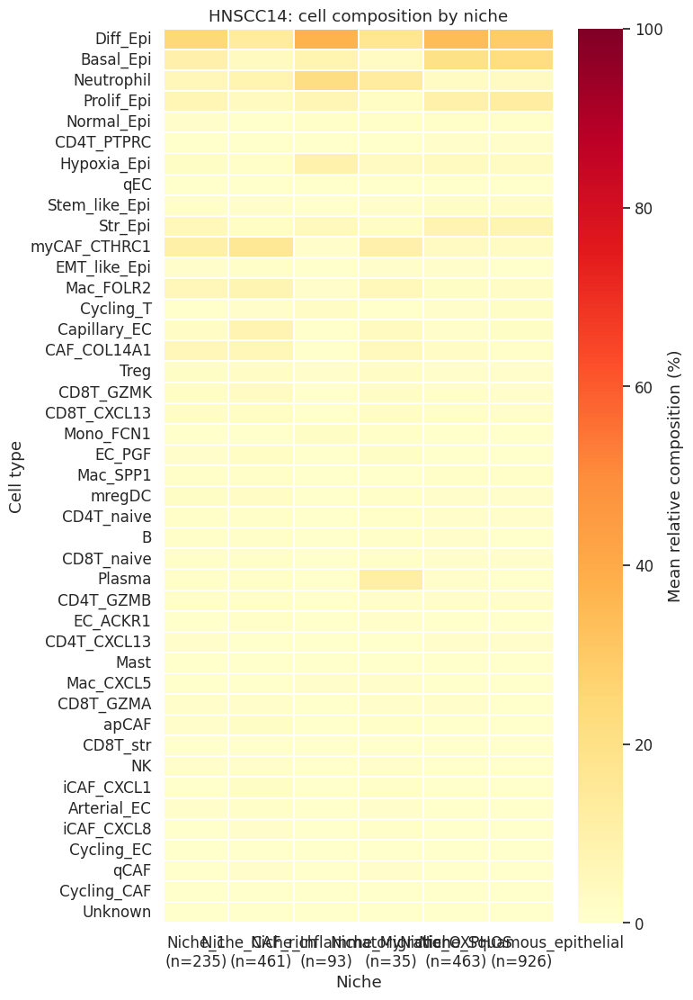

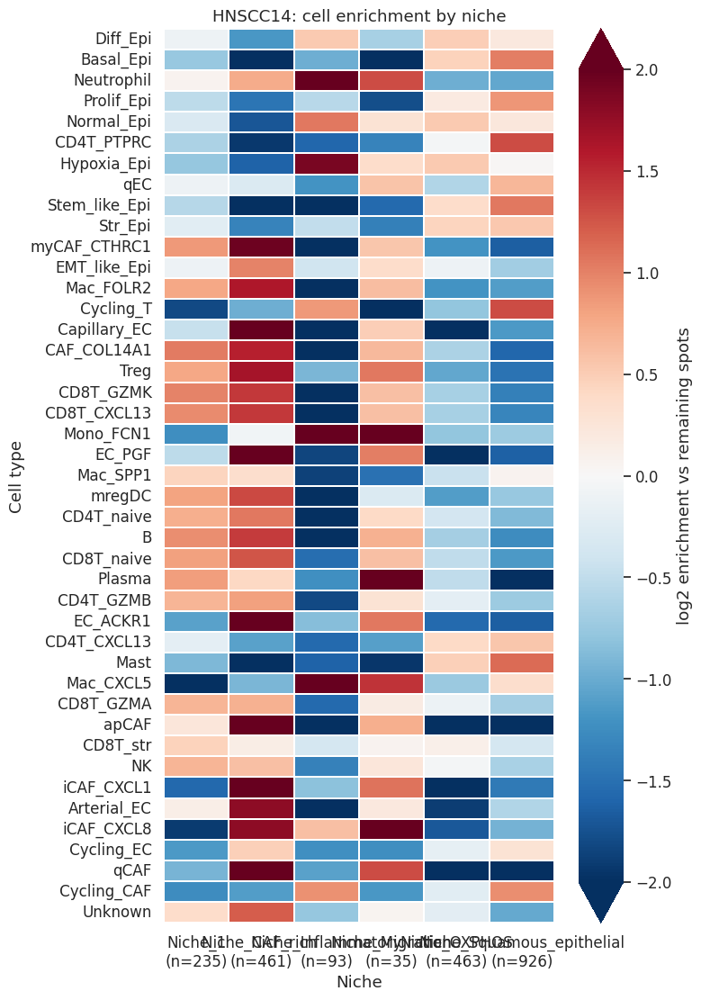

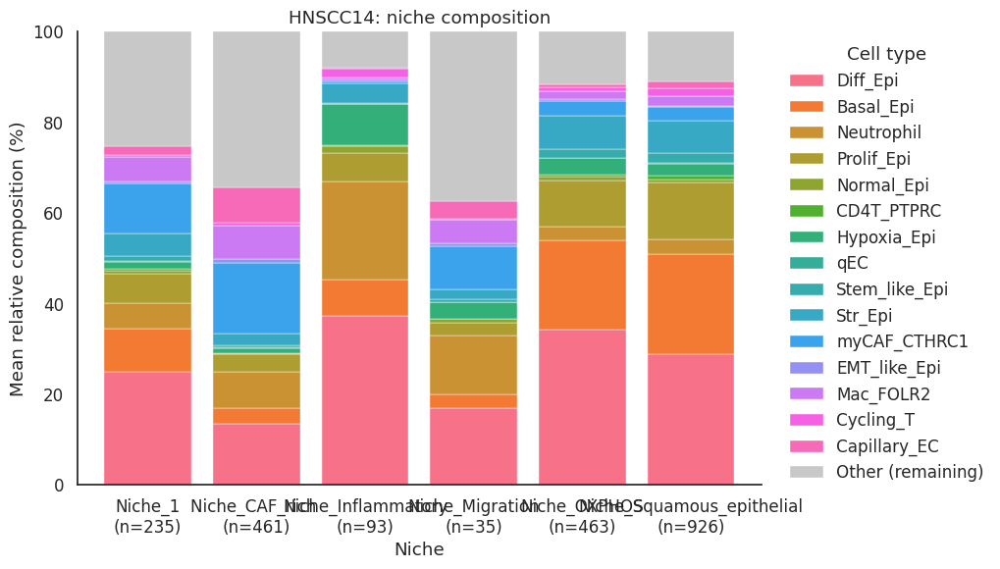

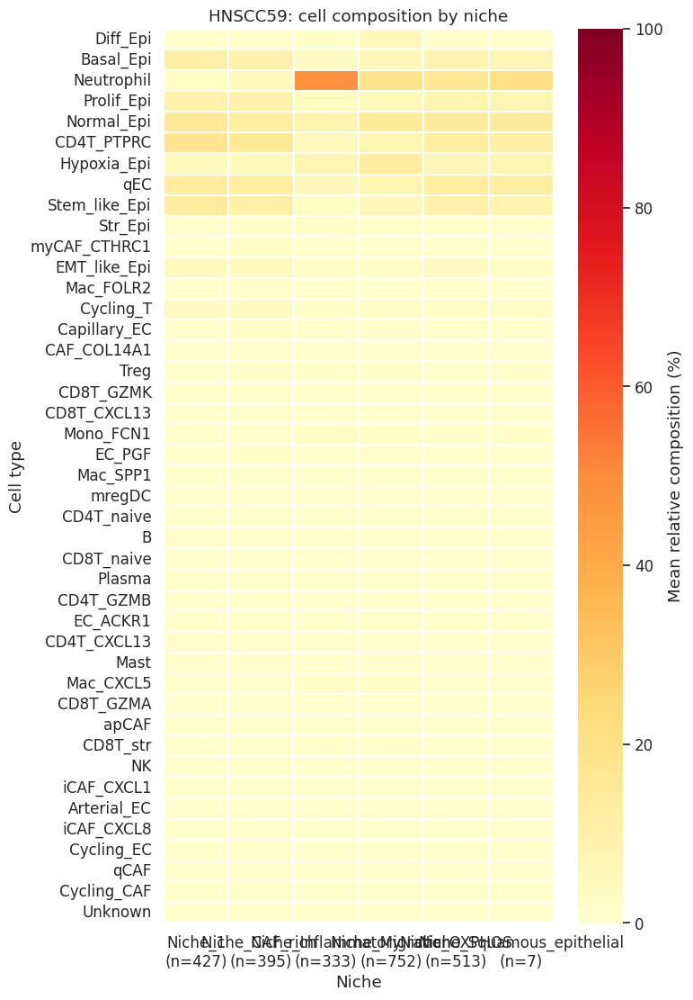

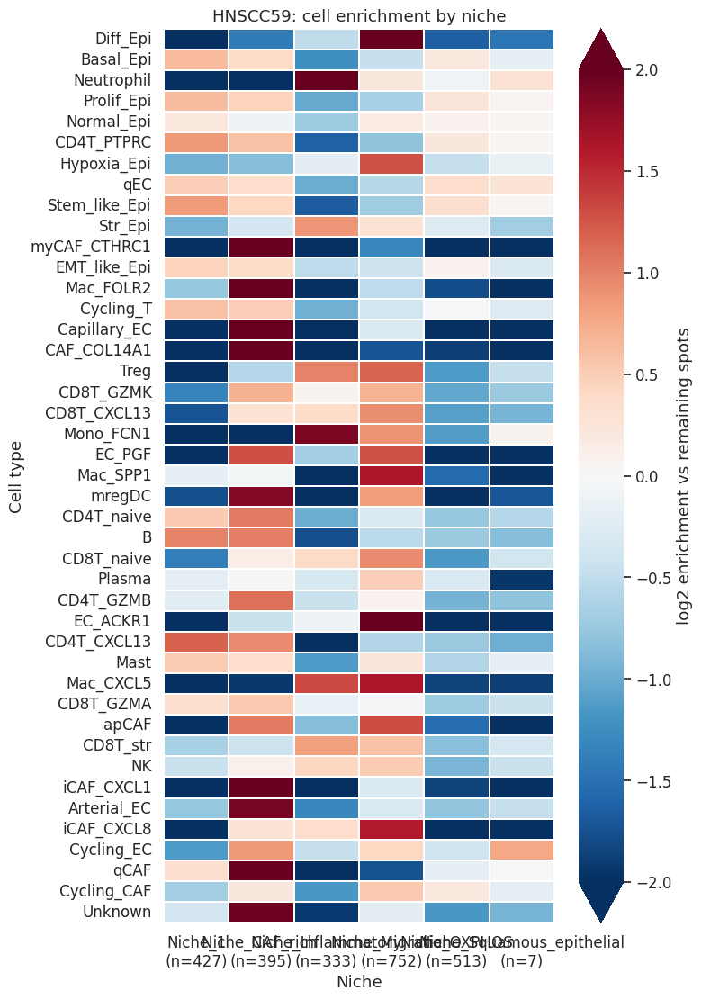

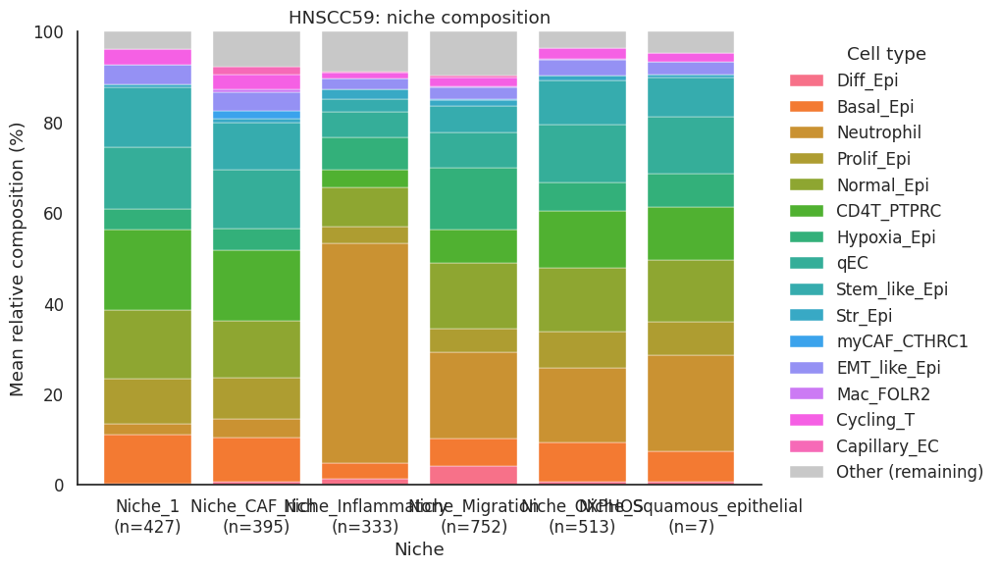

 sample                     niche  n_spots                                         top3_composition                                                                  top3_enriched
HNSCC14                   Niche_1      235    Diff_Epi: 24.9%; myCAF_CTHRC1: 10.9%; Basal_Epi: 9.6%     CAF_COL14A1: log2FC=1.04; CD8T_GZMK: log2FC=1.00; CD8T_CXCL13: log2FC=0.95
HNSCC14           Niche_CAF_rich       461   myCAF_CTHRC1: 15.7%; Diff_Epi: 13.4%; Neutrophil: 7.9%                 qCAF: log2FC=3.44; apCAF: log2FC=2.92; iCAF_CXCL1: log2FC=2.88
HNSCC14        Niche_Inflammatory       93    Diff_Epi: 37.3%; Neutrophil: 21.6%; Hypoxia_Epi: 9.1%        Mono_FCN1: log2FC=2.90; Mac_CXCL5: log2FC=2.49; Neutrophil: log2FC=2.21
HNSCC14           Niche_Migration       35        Diff_Epi: 16.9%; Neutrophil: 13.0%; Plasma: 11.6%           Plasma: log2FC=4.55; iCAF_CXCL8: log2FC=2.48; Mono_FCN1: log2FC=2.20
HNSCC14              Niche_OXPHOS      463     Diff_Epi: 34.3%; Basal_Epi: 19.6%; Prolif_Epi: 10.1%      

In [ ]:
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import sparse
from pathlib import Path

# =========================
# 1. 参数
# =========================
c2l_key = "q05_cell_abundance_w_sf_norm"
niche_key = "gene_niche"
sample_key = "sample"

outdir = Path("./figures/c2l_niche")
outdir.mkdir(parents=True, exist_ok=True)

# 若 obsm 中是没有列名的 numpy 数组，
# 且 adata.uns["mod"]["factor_names"] 不存在，
# 请填写与 c2l 矩阵列顺序完全一致的细胞亚型名称。
celltype_names = None

# 堆叠图显示总体平均组成最高的前 15 类，剩余合并为 Other
top_n = 15

# 富集计算的伪计数；比例单位为 0–1
eps = 1e-6

sns.set_theme(style="white", font_scale=1.1)
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

# =========================
# 2. 提取 c2l 矩阵
# =========================
if not adata.obs_names.is_unique:
    raise ValueError("adata.obs_names 有重复，请先确保 spot 名唯一。")

for key in [niche_key, sample_key]:
    if key not in adata.obs:
        raise KeyError(f"adata.obs 中不存在 {key}")

if c2l_key not in adata.obsm:
    raise KeyError(f"adata.obsm 中不存在 {c2l_key}")

x = adata.obsm[c2l_key]

if isinstance(x, pd.DataFrame):
    abundance = x.reindex(adata.obs_names).copy()
else:
    x = x.toarray() if sparse.issparse(x) else np.asarray(x)

    if celltype_names is None:
        mod_info = adata.uns.get("mod", {})
        celltype_names = mod_info.get("factor_names")

    if celltype_names is None:
        raise ValueError(
            "c2l 矩阵没有列名。请设置 celltype_names，"
            "顺序必须与生成该矩阵时的细胞亚型顺序一致。"
        )

    if len(celltype_names) != x.shape[1]:
        raise ValueError("细胞亚型名称数量与 c2l 矩阵列数不一致。")

    abundance = pd.DataFrame(
        x,
        index=adata.obs_names,
        columns=celltype_names
    )

abundance.columns = abundance.columns.astype(str)
abundance = abundance.astype(float)

if not abundance.columns.is_unique:
    raise ValueError("c2l 的细胞亚型名称存在重复。")

if not np.isfinite(abundance.to_numpy()).all():
    raise ValueError("c2l 矩阵含 NaN 或 inf，请先检查。")

if (abundance.to_numpy() < 0).any():
    raise ValueError("c2l 矩阵含负数，不能用作细胞相对组成。")

# =========================
# 3. 按 spot 转为相对组成
# =========================
meta = adata.obs[[sample_key, niche_key]].copy()
row_sum = abundance.sum(axis=1)

valid = (
    meta.notna().all(axis=1)
    & row_sum.gt(0)
)

print(f"保留 {valid.sum()} 个 spot；排除 {(~valid).sum()} 个。")

if valid.sum() == 0:
    raise ValueError("没有有效 spot。")

meta = meta.loc[valid].astype(str)
abundance = abundance.loc[valid]

# 已按行归一化的数据基本不变
# 输入应为非负丰度或其按 spot 归一化的结果，不能是按列缩放后的值
composition = abundance.div(abundance.sum(axis=1), axis=0)

# 去掉所有 spot 中均为 0 的细胞类型
composition = composition.loc[:, composition.sum(axis=0).gt(0)]

def natural_key(value):
    return [
        int(part) if part.isdigit() else part.lower()
        for part in re.split(r"(\d+)", str(value))
    ]

# 所有样本的图使用相同的细胞顺序和颜色
# 先算每个样本均值，再对样本等权平均
cell_order = (
    composition.groupby(meta[sample_key], observed=True)
    .mean()
    .mean(axis=0)
    .sort_values(ascending=False)
    .index.tolist()
)
composition = composition[cell_order]

top_cells = cell_order[:top_n]
other_label = "Other (remaining)"
while other_label in cell_order:
    other_label += "_"

colors = dict(zip(
    top_cells,
    sns.color_palette("husl", n_colors=len(top_cells))
))
colors[other_label] = "#C8C8C8"

def save_figure(fig, stem):
    fig.savefig(
        outdir / f"{stem}.tiff",
        dpi=300,
        bbox_inches="tight",
        pil_kwargs={"compression": "tiff_lzw"}
    )
    plt.show()
    plt.close(fig)

# =========================
# 4. 按 sample × niche 计算
# =========================
results = {}
summary_tables = []

for sample in sorted(meta[sample_key].unique(), key=natural_key):
    idx = meta.index[meta[sample_key].eq(sample)]
    p = composition.loc[idx]
    labels = meta.loc[idx, niche_key]

    niche_order = sorted(labels.unique(), key=natural_key)

    # 每个 niche 的 spot 数
    n_spots = (
        labels.value_counts()
        .reindex(niche_order)
        .rename("n_spots")
    )

    # 每个 niche 中各细胞的平均相对组成
    mean_comp = (
        p.groupby(labels, observed=True)
        .mean()
        .reindex(niche_order)
    )
    mean_comp.index.name = niche_key

    # 富集 = 本 niche 平均组成 / 同一样本其余 spot 平均组成
    log2_enrichment = pd.DataFrame(
        np.nan,
        index=mean_comp.index,
        columns=mean_comp.columns
    )

    for niche in niche_order:
        outside = p.loc[labels.ne(niche)]

        # 样本只有一个 niche 时，没有比较背景，保持 NaN
        if outside.empty:
            continue

        log2_enrichment.loc[niche] = np.log2(
            (mean_comp.loc[niche] + eps)
            / (outside.mean(axis=0) + eps)
        )

    # 保存完整结果
    stem = re.sub(r"[^\w.-]+", "_", sample)

    mean_comp.to_csv(outdir / f"{stem}_mean_composition.csv")
    log2_enrichment.to_csv(outdir / f"{stem}_log2_enrichment.csv")
    n_spots.to_csv(outdir / f"{stem}_n_spots.csv")

    results[sample] = {
        "mean_composition": mean_comp,
        "log2_enrichment": log2_enrichment,
        "n_spots": n_spots
    }

    # 汇总每个 niche 的主要细胞与富集细胞
    for niche in niche_order:
        dominant = mean_comp.loc[niche].sort_values(ascending=False)
        enriched = log2_enrichment.loc[niche].dropna()
        enriched = enriched[enriched > 0].sort_values(ascending=False)

        summary_tables.append({
            "sample": sample,
            "niche": niche,
            "n_spots": int(n_spots.loc[niche]),
            "top3_composition": "; ".join(
                f"{ct}: {value:.1%}"
                for ct, value in dominant.head(3).items()
            ),
            "top3_enriched": "; ".join(
                f"{ct}: log2FC={value:.2f}"
                for ct, value in enriched.head(3).items()
            )
        })

    # =========================
    # 5. 平均组成热图
    # 行 = 细胞亚型，列 = niche
    # =========================
    tick_labels = [
        f"{n}\n(n={n_spots.loc[n]})"
        for n in niche_order
    ]

    fig, ax = plt.subplots(
        figsize=(
            max(7, len(niche_order) * 1.0),
            max(5, len(cell_order) * 0.30)
        )
    )

    sns.heatmap(
        mean_comp.T * 100,
        cmap="YlOrRd",
        vmin=0,
        vmax=100,
        xticklabels=tick_labels,
        yticklabels=True,
        linewidths=0.2,
        cbar_kws={"label": "Mean relative composition (%)"},
        ax=ax
    )

    ax.set(
        title=f"{sample}: cell composition by niche",
        xlabel="Niche",
        ylabel="Cell type"
    )
    ax.tick_params(axis="x", rotation=0)
    save_figure(fig, f"{stem}_composition_heatmap")

    # =========================
    # 6. 相对富集热图
    # =========================
    if log2_enrichment.notna().any().any():
        fig, ax = plt.subplots(
            figsize=(
                max(7, len(niche_order) * 1.0),
                max(5, len(cell_order) * 0.30)
            )
        )

        sns.heatmap(
            log2_enrichment.T,
            cmap="RdBu_r",
            center=0,
            vmin=-2,
            vmax=2,
            xticklabels=tick_labels,
            yticklabels=True,
            linewidths=0.2,
            cbar_kws={
                "label": "log2 enrichment vs remaining spots",
                "extend": "both"
            },
            ax=ax
        )

        ax.set(
            title=f"{sample}: cell enrichment by niche",
            xlabel="Niche",
            ylabel="Cell type"
        )
        ax.tick_params(axis="x", rotation=0)
        save_figure(fig, f"{stem}_enrichment_heatmap")

    # =========================
    # 7. 细胞组成堆叠柱状图
    # =========================
    plot_comp = mean_comp[top_cells].copy()
    remaining = [ct for ct in cell_order if ct not in top_cells]

    if remaining:
        plot_comp[other_label] = mean_comp[remaining].sum(axis=1)

    fig, ax = plt.subplots(
        figsize=(max(9, len(niche_order) * 1.0), 6)
    )

    (plot_comp * 100).plot.bar(
        stacked=True,
        color=[colors[ct] for ct in plot_comp.columns],
        width=0.8,
        edgecolor="white",
        linewidth=0.3,
        ax=ax
    )

    ax.set(
        title=f"{sample}: niche composition",
        xlabel="Niche",
        ylabel="Mean relative composition (%)",
        ylim=(0, 100)
    )
    ax.set_xticklabels(tick_labels, rotation=0)
    ax.legend(
        title="Cell type",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        frameon=False
    )
    sns.despine(ax=ax)
    save_figure(fig, f"{stem}_composition_stacked")

# =========================
# 8. 汇总表
# =========================
niche_summary = pd.DataFrame(summary_tables)
niche_summary.to_csv(outdir / "niche_celltype_summary.csv", index=False)

print(niche_summary.to_string(index=False))
print(f"\n结果保存至：{outdir.resolve()}")

#end

In [ ]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr


def plot_gene_caf(
    adata,
    gene="LAMA2",
    niche="Niche_CAF_rich",
    key="q05_cell_abundance_w_sf_norm",
    layer=None,
    caf_cols=None,
    samples=("HNSCC14", "HNSCC59"),
    trim=0.025,
):
    """在指定 niche 内，展示基因表达与总 CAF 占比的关系。"""
    samples = list(samples)
    if len(samples) != 2:
        raise ValueError("请指定两个样本。")
    if not 0 <= trim < 0.5:
        raise ValueError("trim 应在 [0, 0.5) 范围内。")
    if not adata.var_names.is_unique or gene not in adata.var_names:
        raise ValueError("请检查基因是否存在，以及基因名是否唯一。")

    # 1. c2l 矩阵及 CAF 占比
    ab = adata.obsm[key]
    if not isinstance(ab, pd.DataFrame):
        names = adata.uns.get("mod", {}).get("factor_names")
        if names is None:
            raise ValueError("c2l 矩阵无列名，请先转换为带亚型列名的 DataFrame。")
        ab = pd.DataFrame(
            ab.toarray() if sp.issparse(ab) else np.asarray(ab),
            index=adata.obs_names,
            columns=names,
        )

    ab = ab.reindex(adata.obs_names).astype(float)
    if not ab.columns.is_unique:
        raise ValueError("c2l 亚型列名重复。")
    if not np.isfinite(ab.to_numpy()).all() or (ab.to_numpy() < 0).any():
        raise ValueError("c2l 矩阵包含缺失、无穷值或负值。")

    if caf_cols is None:
        caf_cols = [c for c in ab.columns if "CAF" in str(c).upper()]
    if not caf_cols:
        raise ValueError("未找到 CAF 列，请手动指定 caf_cols。")
    print("CAF 亚型：", caf_cols)

    caf = ab[caf_cols].sum(axis=1) / ab.sum(axis=1).replace(0, np.nan)

    # 2. 筛选 niche 和样本，自动去除名称前后空格
    sample = adata.obs["sample"].astype("string").str.strip()
    niche_label = adata.obs["gene_niche"].astype("string").str.strip()
    keep = sample.isin(samples) & niche_label.eq(niche.strip()).fillna(False)

    if "in_tissue" in adata.obs:
        keep &= pd.to_numeric(adata.obs["in_tissue"], errors="coerce").eq(1)

    idx = np.flatnonzero(keep.to_numpy(dtype=bool))
    matrix = adata.X if layer is None else adata.layers[layer]
    x = matrix[:, [adata.var_names.get_loc(gene)]][idx, :]
    x = x.toarray().ravel() if sp.issparse(x) else np.asarray(x).ravel()

    if not np.isfinite(x).all() or (x < 0).any():
        raise ValueError("请使用非负、无缺失的 log1p 归一化表达。")

    df = pd.DataFrame({
        "sample": sample.iloc[idx].to_numpy(),
        "expression": x,
        "caf_fraction": caf.iloc[idx].to_numpy(),
    }, index=adata.obs_names[idx]).dropna()

    if any((df["sample"] == s).sum() < 3 for s in samples):
        raise ValueError("至少一个样本在该 niche 内不足 3 个有效 spot。")

    # 3. 完整 niche 的统计与 Spearman 相关性
    rows = []
    for s in samples:
        d = df.loc[df["sample"] == s]
        rho, p = np.nan, np.nan
        if d["expression"].nunique() > 1 and d["caf_fraction"].nunique() > 1:
            rho, p = spearmanr(d["caf_fraction"], d["expression"])

        rows.append({
            "sample": s,
            "n_spots": len(d),
            "CAF_median": d["caf_fraction"].median(),
            "gene_mean": d["expression"].mean(),
            "gene_median": d["expression"].median(),
            "rho": rho,
            "p_value": p,
        })
    summary = pd.DataFrame(rows).set_index("sample")

    # 4. 共同范围仅用于标记和描述，不用于筛选相关性分析
    ranges = df.groupby("sample")["caf_fraction"].quantile(
        [trim, 1 - trim]
    ).unstack()
    lower, upper = ranges[trim].max(), ranges[1 - trim].min()
    has_overlap = lower < upper

    overlap = df.loc[
        df["caf_fraction"].between(lower, upper)
    ] if has_overlap else df.iloc[:0]

    overlap_summary = overlap.groupby("sample").agg(
        n_spots=("expression", "size"),
        CAF_median=("caf_fraction", "median"),
        gene_mean=("expression", "mean"),
        gene_median=("expression", "median"),
    ).reindex(samples)

    overlap_summary["n_spots"] = overlap_summary["n_spots"].fillna(0).astype(int)
    overlap_summary["retained_pct"] = (
        overlap_summary["n_spots"] / summary["n_spots"] * 100
    )

    print("\n完整 niche：")
    print(summary.to_string(float_format=lambda v: f"{v:.4g}"))
    print(f"\n共同范围：{lower:.3f}–{upper:.3f}" if has_overlap else "\n无共同范围")
    print(overlap_summary.round(4).to_string())

    # 5. ECDF + 两张切片散点图
    palette = dict(zip(samples, ["#E68A65", "#619BC3"]))
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

    sns.ecdfplot(
        data=df, x="caf_fraction", hue="sample",
        hue_order=samples, palette=palette, ax=axes[0],
    )
    axes[0].set(
        title=f"CAF fraction | {niche.strip()}",
        xlabel="Total CAF fraction",
        ylabel="Cumulative fraction of spots",
    )

    xmax = max(df["caf_fraction"].max() * 1.05, 0.01)
    ymax = max(df["expression"].max() * 1.05, 0.1)

    for ax, s in zip(axes[1:], samples):
        d = df.loc[df["sample"] == s]
        ax.scatter(
            d["caf_fraction"], d["expression"],
            color=palette[s], s=18, alpha=0.5, linewidths=0,
        )
        ax.set(
            title=f"{s}: rho={summary.loc[s, 'rho']:.2f}, "
                  f"P={summary.loc[s, 'p_value']:.2g}",
            xlabel="Total CAF fraction",
            ylabel=f"{gene}: log-normalized expression",
            xlim=(0, xmax), ylim=(0, ymax),
        )

    # for ax in axes:
    #     if has_overlap:
    #         ax.axvspan(lower, upper, color="grey", alpha=0.15)
    #     ax.set_xlim(0, xmax)

    sns.despine()
    fig.tight_layout()
    plt.show()

    return {
        "data": df,
        "summary": summary,
        "overlap_summary": overlap_summary,
        "figure": fig,
    }

In [ ]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
from pathlib import Path


def plot_caf_subtypes(
    adata,
    gene="LAMA2",
    niche="Niche_CAF_rich",
    key="q05_cell_abundance_w_sf_norm",
    layer=None,
    caf_cols=None,
    samples=("HNSCC14", "HNSCC59"),
    min_caf=0.0,
    scatter=False,
    show_q=False,
    outdir=None,
):
    """
    layer=None：使用 adata.X，要求已经 normalize_total + log1p。
    min_caf：仅影响 CAF 内部组成及其相关性。
    outdir=None：不保存；指定路径后保存 TIFF 和 CSV。
    """
    samples = list(samples)
    if len(samples) != 2 or len(set(samples)) != 2:
        raise ValueError("请指定两个不同的样本。")
    if not 0 <= min_caf <= 1:
        raise ValueError("min_caf 应在 0–1 之间。")
    if not adata.obs_names.is_unique or not adata.var_names.is_unique:
        raise ValueError("spot 或基因名称不唯一。")
    if gene not in adata.var_names:
        raise KeyError(f"未找到基因：{gene}")

    palette = dict(zip(samples, ["#E68A65", "#619BC3"]))
    sns.set_theme(style="ticks", font_scale=1.1)

    # 1. 读取 c2l
    ab = adata.obsm[key]
    if not isinstance(ab, pd.DataFrame):
        names = adata.uns.get("mod", {}).get("factor_names")
        if names is None:
            raise ValueError("c2l 无列名，请先转换为带亚型列名的 DataFrame。")
        ab = pd.DataFrame(
            ab.toarray() if sp.issparse(ab) else np.asarray(ab),
            index=adata.obs_names, columns=names,
        )
    ab = ab.reindex(adata.obs_names).astype(float)

    if not ab.columns.is_unique:
        raise ValueError("c2l 亚型列名重复。")
    if not np.isfinite(ab.to_numpy()).all() or (ab.to_numpy() < 0).any():
        raise ValueError("c2l 包含缺失、无穷值或负值。")

    if caf_cols is None:
        caf_cols = [c for c in ab.columns if "CAF" in str(c).upper()]
    caf_cols = list(caf_cols)
    if not caf_cols or len(set(caf_cols)) != len(caf_cols):
        raise ValueError("请指定非空且不重复的 CAF 亚型列表。")
    missing = [c for c in caf_cols if c not in ab.columns]
    if missing:
        raise KeyError(f"缺少亚型：{missing}")
    print("CAF 亚型：", caf_cols)

    # 2. 筛选 niche，重新提取当前基因表达
    sample = adata.obs["sample"].astype("string").str.strip()
    labels = adata.obs["gene_niche"].astype("string").str.strip()
    keep = sample.isin(samples) & labels.eq(niche.strip()).fillna(False)

    if "in_tissue" in adata.obs:
        keep &= pd.to_numeric(adata.obs["in_tissue"], errors="coerce").eq(1)

    idx = np.flatnonzero(keep.to_numpy(dtype=bool))
    matrix = adata.X if layer is None else adata.layers[layer]
    x = matrix[:, [adata.var_names.get_loc(gene)]][idx, :]
    x = x.toarray().ravel() if sp.issparse(x) else np.asarray(x).ravel()

    if not np.isfinite(x).all() or (x < 0).any():
        raise ValueError("请使用非负、无缺失的 log-normalized 表达。")

    df = pd.DataFrame({
        "sample": sample.iloc[idx].to_numpy(),
        "expression": x,
    }, index=adata.obs_names[idx])

    ab = ab.iloc[idx]
    valid = ab.sum(axis=1) > 0
    df, ab = df.loc[valid].copy(), ab.loc[valid].copy()

    # 3. 两种比例：占全部类型、占 CAF 内部
    frac_all = ab[caf_cols].div(ab.sum(axis=1), axis=0)
    total_caf = frac_all.sum(axis=1)
    frac_within = frac_all.div(total_caf.replace(0, np.nan), axis=0)
    frac_within.loc[total_caf <= min_caf, :] = np.nan

    counts = pd.DataFrame({
        "all_spots": df.groupby("sample").size(),
        "within_CAF_spots": df.loc[total_caf > min_caf].groupby("sample").size(),
    }).reindex(samples).fillna(0).astype(int)

    if (counts["all_spots"] < 3).any():
        raise ValueError("至少一个样本在该 niche 内不足 3 个有效 spot。")
    print("\n使用的 spot 数：\n", counts)

    fractions = {"all_cells": frac_all, "within_CAF": frac_within}
    means = {
        name: table.groupby(df["sample"]).mean().reindex(samples)
        for name, table in fractions.items()
    }

    # 4. Spearman 及全部有效比较的 BH 校正
    rows = []
    for mode, table in fractions.items():
        for s in samples:
            mask = df["sample"].eq(s)
            for subtype in caf_cols:
                pair = pd.DataFrame({
                    "x": table.loc[mask, subtype],
                    "y": df.loc[mask, "expression"],
                }).dropna()

                rho, p = np.nan, np.nan
                if len(pair) >= 3 and pair["x"].nunique() > 1 and pair["y"].nunique() > 1:
                    rho, p = spearmanr(pair["x"], pair["y"])

                rows.append([mode, s, subtype, len(pair), rho, p])

    corr = pd.DataFrame(rows, columns=[
        "mode", "sample", "subtype", "n_spots", "rho", "p_value",
    ])
    corr["p_adj"] = np.nan
    valid_p = corr["p_value"].notna()
    if valid_p.any():
        corr.loc[valid_p, "p_adj"] = multipletests(
            corr.loc[valid_p, "p_value"], method="fdr_bh"
        )[1]

    figures = {}

    # 5. 各亚型占全部细胞的平均比例
    fig, ax = plt.subplots(figsize=(10, 4.5))
    (means["all_cells"].T * 100).plot.bar(
        ax=ax, color=[palette[s] for s in samples], width=0.75,
    )
    ax.set(
        title=f"CAF subtypes | {niche.strip()}",
        xlabel="", ylabel="Mean fraction of all cell types (%)",
    )
    plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
    figures["01_abundance"] = fig

    # 6. CAF 内部组成，未满足门槛的样本保留为空白
    fig, ax = plt.subplots(figsize=(8, 5))
    bottoms = np.zeros(len(samples))
    colors = sns.color_palette("Set2", len(caf_cols))

    for subtype, color in zip(caf_cols, colors):
        values = means["within_CAF"][subtype].to_numpy() * 100
        ax.bar(samples, values, bottom=bottoms, color=color, label=subtype)
        for i, value in enumerate(values):
            if np.isfinite(value) and value >= 5:
                ax.text(i, bottoms[i] + value / 2, f"{value:.1f}%",
                        ha="center", va="center", fontsize=10)
        bottoms += np.nan_to_num(values)

    for i, s in enumerate(samples):
        if counts.loc[s, "within_CAF_spots"] == 0:
            ax.text(i, 50, "No eligible spots", ha="center", rotation=90)

    ax.set(
        title=f"CAF composition | {niche.strip()}",
        ylabel="Mean within-CAF fraction (%)", ylim=(0, 100),
    )
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
    figures["02_composition"] = fig

    # 7. 相关性热图
    fig, axes = plt.subplots(
        1, 2, figsize=(14, max(4, len(caf_cols) * 0.9))
    )
    titles = ["Subtype fraction of all cell types", "Subtype fraction within CAF"]

    for ax, mode, title in zip(axes, fractions, titles):
        table = corr.loc[corr["mode"] == mode]
        heat = table.pivot(
            index="subtype", columns="sample", values="rho"
        ).reindex(index=caf_cols, columns=samples)

        annot = pd.DataFrame("", index=caf_cols, columns=samples)
        for _, r in table.iterrows():
            if pd.notna(r["rho"]):
                text = f'{r["rho"]:.2f}\nP={r["p_value"]:.2g}'
                if show_q:
                    text += f'\nq={r["p_adj"]:.2g}'
                annot.loc[r["subtype"], r["sample"]] = text

        sns.heatmap(
            heat, mask=heat.isna(), annot=annot, fmt="",
            cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            linewidths=0.5, annot_kws={"fontsize": 10},
            cbar_kws={"label": "Spearman rho"}, ax=ax,
        )
        ax.set(title=title, xlabel="", ylabel="")
        ax.tick_params(axis="y", rotation=0)

    fig.suptitle(f"{gene}–CAF associations | {niche.strip()}")
    figures["03_correlations"] = fig

    # 8. 可选：逐亚型散点图
    if scatter:
        fig, axes = plt.subplots(
            len(caf_cols), 2,
            figsize=(11, 3 * len(caf_cols)), squeeze=False,
        )
        ymax = max(df["expression"].max() * 1.05, 0.1)

        for i, subtype in enumerate(caf_cols):
            xmax = max(frac_all[subtype].max() * 1.05, 0.001)
            for j, s in enumerate(samples):
                mask = df["sample"].eq(s)
                r = corr.loc[
                    corr["mode"].eq("all_cells")
                    & corr["sample"].eq(s)
                    & corr["subtype"].eq(subtype)
                ].iloc[0]

                axes[i, j].scatter(
                    frac_all.loc[mask, subtype], df.loc[mask, "expression"],
                    color=palette[s], s=14, alpha=0.45, linewidths=0,
                )
                axes[i, j].set(
                    title=f'{s} | {subtype}\nrho={r["rho"]:.2f}, P={r["p_value"]:.2g}',
                    xlabel="Subtype fraction of all cell types",
                    ylabel=f"{gene} expression",
                    xlim=(0, xmax), ylim=(0, ymax),
                )
        figures["04_scatterplots"] = fig

    # 9. 显示和可选保存
    folder = Path(outdir) if outdir is not None else None
    if folder is not None:
        folder.mkdir(parents=True, exist_ok=True)
        corr.to_csv(folder / "correlations.csv", index=False)
        counts.to_csv(folder / "spot_counts.csv")
        df.to_csv(folder / "expression.csv")
        for mode, table in means.items():
            table.to_csv(folder / f"mean_fraction_{mode}.csv")

    for name, fig in figures.items():
        fig.tight_layout()
        if folder is not None:
            fig.savefig(
                folder / f"{name}.tiff", dpi=600, bbox_inches="tight",
                pil_kwargs={"compression": "tiff_lzw"},
            )
        plt.show()
        plt.close(fig)

    return {
        "data": df,
        "counts": counts,
        "mean_all": means["all_cells"],
        "mean_within": means["within_CAF"],
        "correlations": corr,
        "figures": figures,
    }

In [ ]:
adata.obs["gene_niche"].unique()

['Niche_OXPHOS', 'Niche_Squamous_epithelial', 'Niche_CAF_rich', 'Niche_Inflammatory', 'Niche_1', 'Niche_Migration']
Categories (6, object): ['Niche_1', 'Niche_CAF_rich', 'Niche_Inflammatory', 'Niche_Migration',
                         'Niche_OXPHOS', 'Niche_Squamous_epithelial']

CAF 亚型： ['CAF_COL14A1', 'Cycling_CAF', 'apCAF', 'iCAF_CXCL1', 'iCAF_CXCL8', 'myCAF_CTHRC1', 'qCAF']

完整 niche：
         n_spots  CAF_median  gene_mean  gene_median    rho   p_value
sample                                                               
HNSCC14      461      0.2585      0.241            0 0.3572 2.575e-15
HNSCC59      395    0.009809     0.6832       0.6661 0.1452  0.003819

共同范围：0.089–0.156
         n_spots  CAF_median  gene_mean  gene_median  retained_pct
sample                                                            
HNSCC14       57      0.1217     0.0487       0.0000       12.3644
HNSCC59       16      0.1115     0.8854       0.9691        4.0506


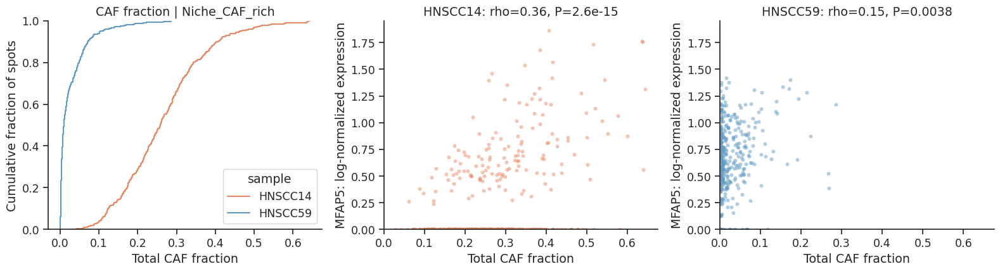

In [ ]:
res = plot_gene_caf(adata, gene="MFAP5", niche="Niche_CAF_rich")


CAF 亚型： ['CAF_COL14A1', 'Cycling_CAF', 'apCAF', 'iCAF_CXCL1', 'iCAF_CXCL8', 'myCAF_CTHRC1', 'qCAF']

完整 niche：
         n_spots  CAF_median  gene_mean  gene_median    rho   p_value
sample                                                               
HNSCC14      461      0.2585     0.3536       0.3029 0.1466  0.001598
HNSCC59      395    0.009809    0.07399            0 0.4405 3.494e-20

共同范围：0.089–0.156
         n_spots  CAF_median  gene_mean  gene_median  retained_pct
sample                                                            
HNSCC14       57      0.1217     0.2580       0.0000       12.3644
HNSCC59       16      0.1115     0.2516       0.2282        4.0506


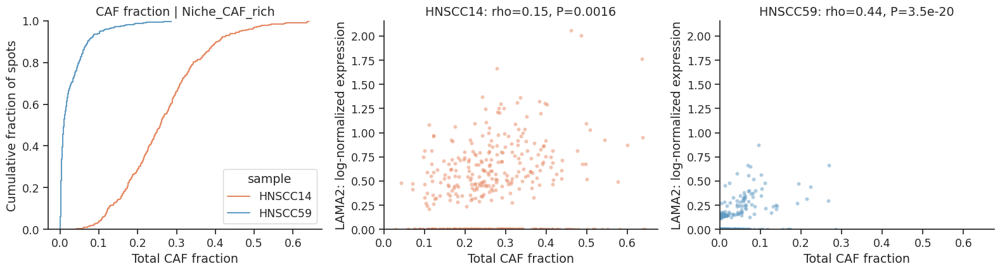

In [ ]:
res = plot_gene_caf(adata, gene="LAMA2", niche="Niche_CAF_rich")


CAF 亚型： ['CAF_COL14A1', 'Cycling_CAF', 'apCAF', 'iCAF_CXCL1', 'iCAF_CXCL8', 'myCAF_CTHRC1', 'qCAF']

完整 niche：
         n_spots  CAF_median  gene_mean  gene_median    rho   p_value
sample                                                               
HNSCC14      461      0.2585     0.3536       0.3029 0.1466  0.001598
HNSCC59      395    0.009809    0.07399            0 0.4405 3.494e-20

共同范围：0.089–0.156
         n_spots  CAF_median  gene_mean  gene_median  retained_pct
sample                                                            
HNSCC14       57      0.1217     0.2580       0.0000       12.3644
HNSCC59       16      0.1115     0.2516       0.2282        4.0506


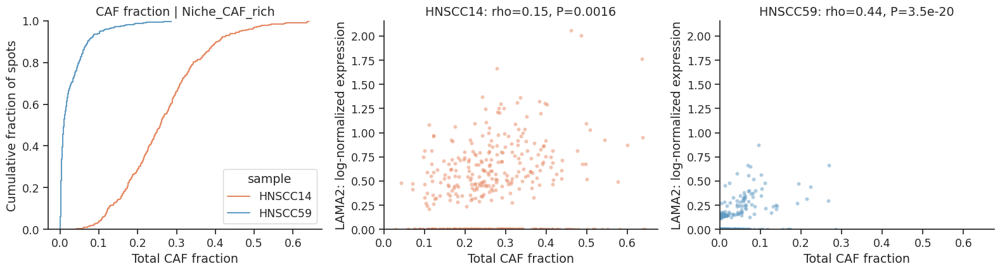

In [ ]:
# LAMA2，在 CAF-rich niche 内
res = plot_gene_caf(adata, gene="LAMA2", niche="Niche_CAF_rich")

# # 换基因
# res = plot_gene_caf(adata, gene="THSD4", niche="Niche_CAF_rich")

# # 换 niche
# res = plot_gene_caf(adata, gene="LAMA2", niche="Niche_Migration")

# 如果归一化表达在 layer 中
# res = plot_gene_caf(
#     adata, gene="LAMA2", niche="Niche_CAF_rich", layer="log1p"
# )

CAF 亚型： ['CAF_COL14A1', 'Cycling_CAF', 'apCAF', 'iCAF_CXCL1', 'iCAF_CXCL8', 'myCAF_CTHRC1', 'qCAF']

使用的 spot 数：
          all_spots  within_CAF_spots
sample                              
HNSCC14        461               461
HNSCC59        395               395


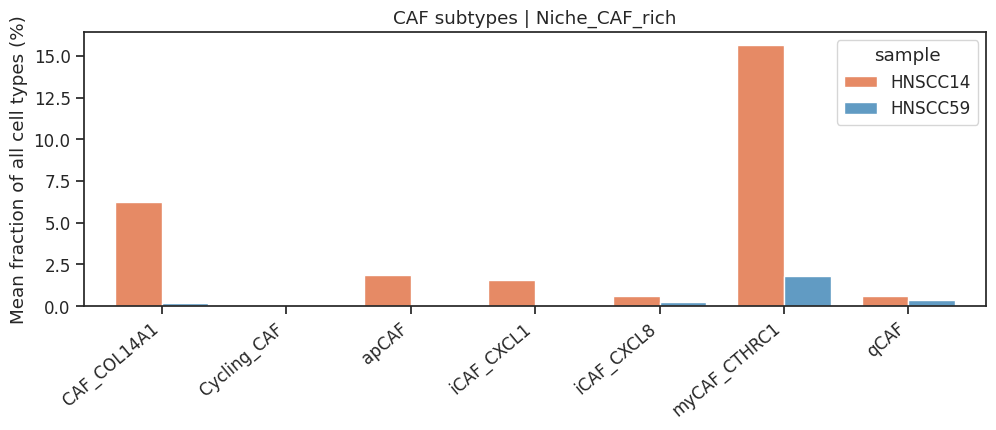

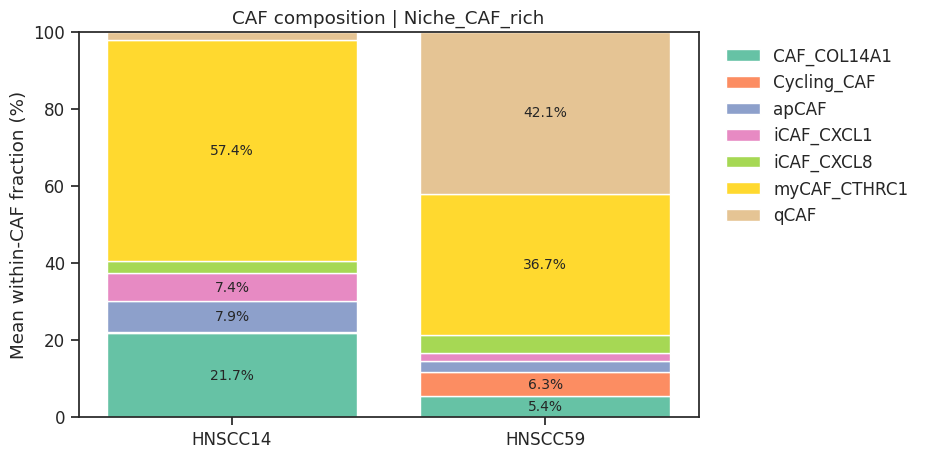

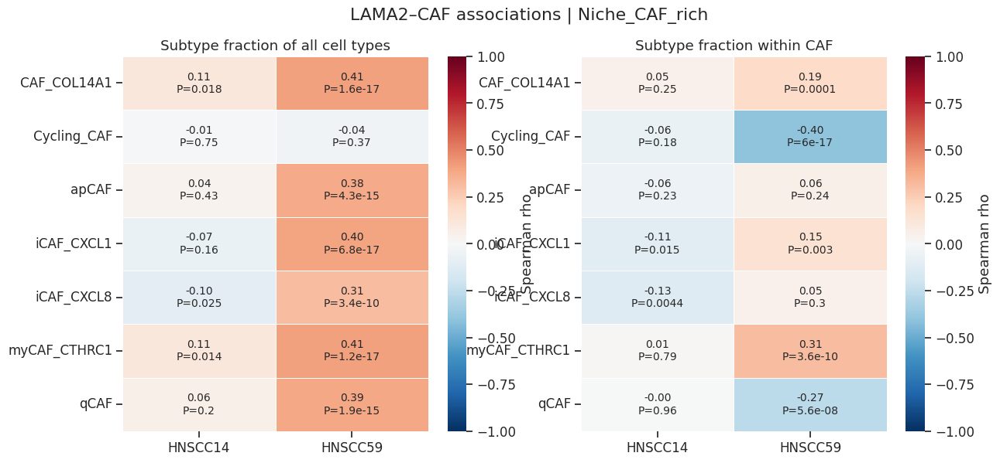

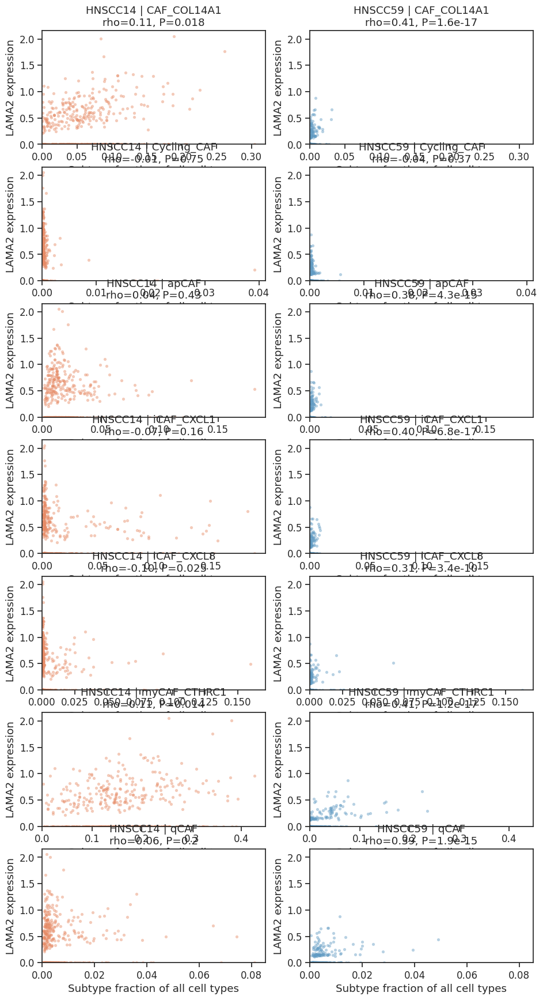

In [ ]:
res = plot_caf_subtypes(
    adata,
    gene="LAMA2",
    niche="Niche_CAF_rich",
    scatter=True,
    # show_q=True,
    # outdir="./visum/figures/THSD4_Niche_CAF_rich",
)

CAF 亚型： ['CAF_COL14A1', 'Cycling_CAF', 'apCAF', 'iCAF_CXCL1', 'iCAF_CXCL8', 'myCAF_CTHRC1', 'qCAF']

使用的 spot 数：
          all_spots  within_CAF_spots
sample                              
HNSCC14        461               461
HNSCC59        395               395


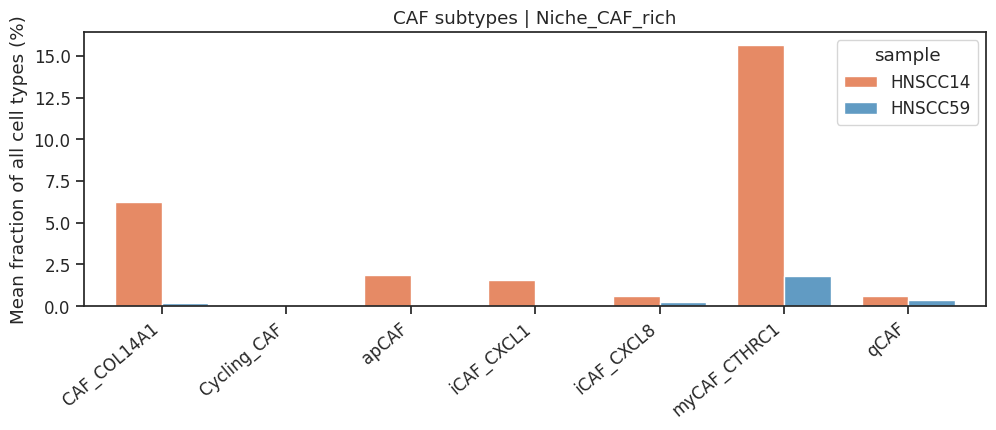

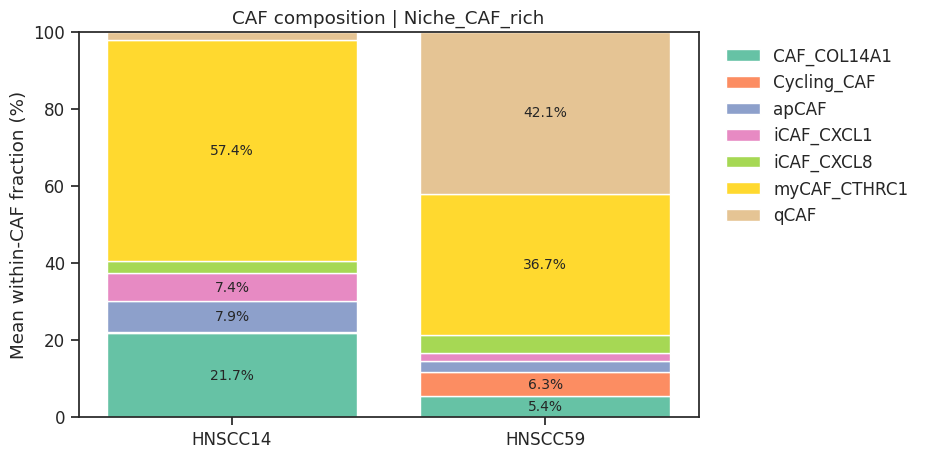

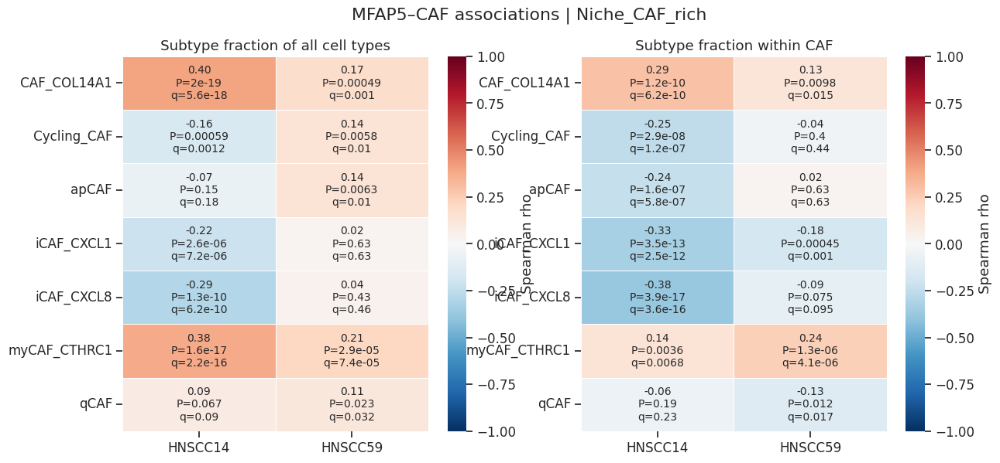

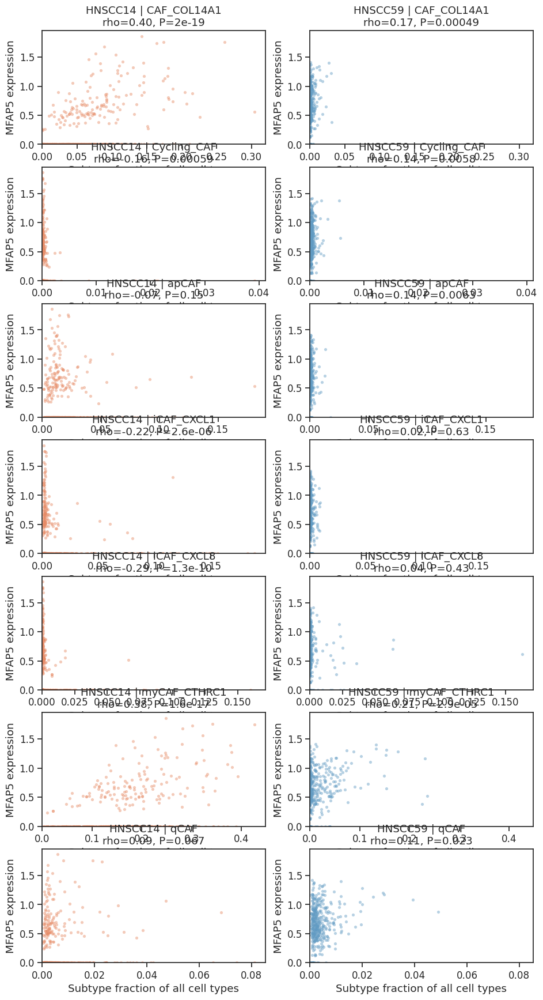

In [ ]:
res = plot_caf_subtypes(
    adata,
    gene="MFAP5",
    niche="Niche_CAF_rich",
    scatter=True,
    show_q=True,
    # outdir="./visum/figures/THSD4_Niche_CAF_rich",
)

CAF 亚型： ['CAF_COL14A1', 'Cycling_CAF', 'apCAF', 'iCAF_CXCL1', 'iCAF_CXCL8', 'myCAF_CTHRC1', 'qCAF']

使用的 spot 数：
          all_spots  within_CAF_spots
sample                              
HNSCC14        461               461
HNSCC59        395               395


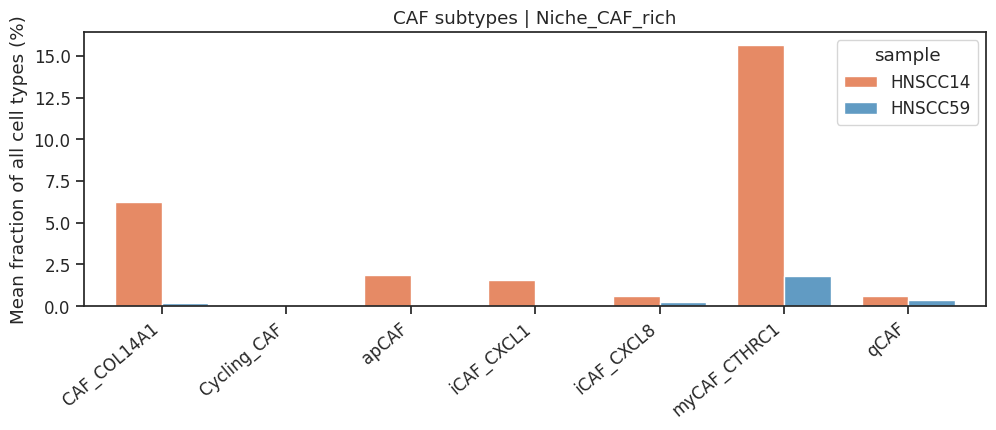

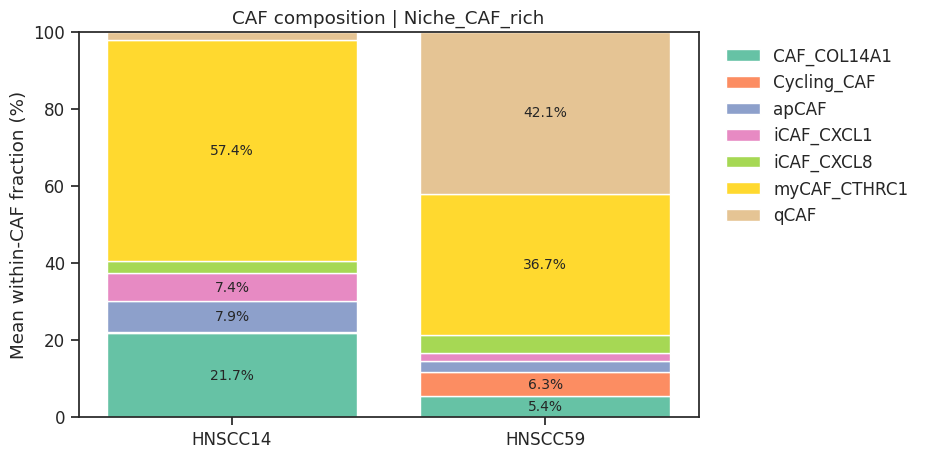

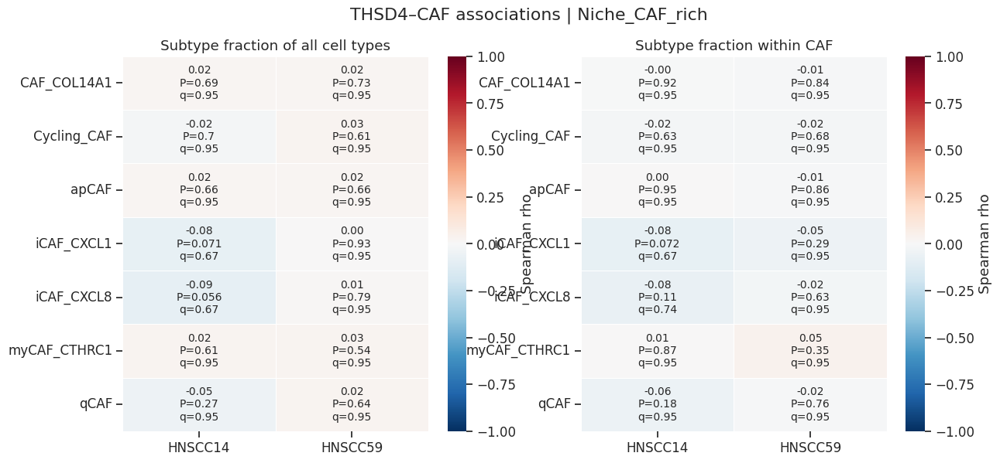

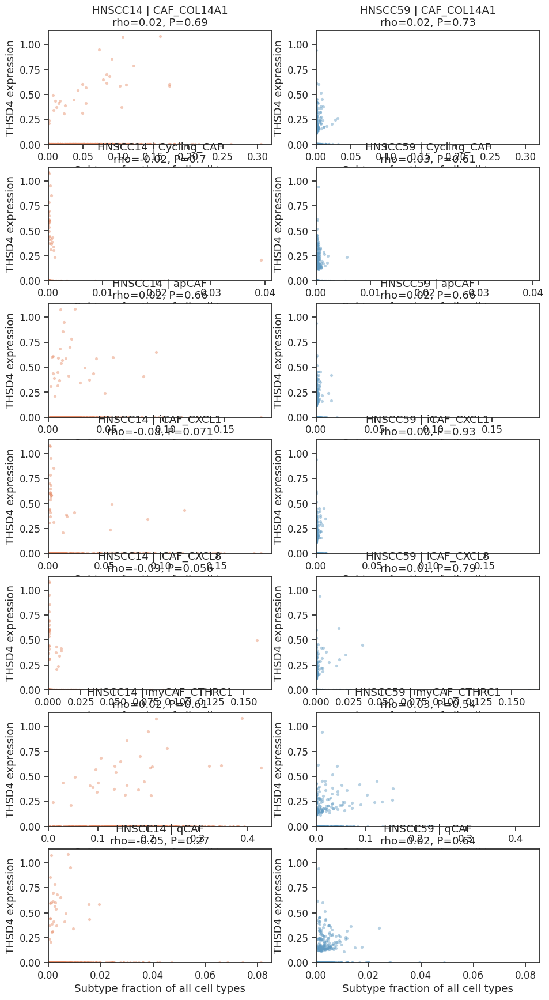

In [ ]:
res = plot_caf_subtypes(
    adata,
    gene="THSD4",
    niche="Niche_CAF_rich",
    scatter=True,
    show_q=True,
    outdir="./visum/figures/THSD4_Niche_CAF_rich",
)

In [ ]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr


def plot_gene_caf(
    adata,
    gene="LAMA2",
    niche="Niche_CAF_rich",
    key="q05_cell_abundance_w_sf_norm",
    layer=None,
    caf_cols=None,
    samples=("HNSCC14", "HNSCC59"),
):
    """合并指定样本，在指定 niche 内计算基因与总 CAF 占比的相关性。"""

    if not adata.var_names.is_unique or gene not in adata.var_names:
        raise ValueError("请检查基因是否存在，以及基因名是否唯一。")

    # 1. 获取 c2l 矩阵
    ab = adata.obsm[key]

    if not isinstance(ab, pd.DataFrame):
        names = adata.uns.get("mod", {}).get("factor_names")
        if names is None:
            raise ValueError("c2l 矩阵无列名，请提供对应的亚型名称。")

        ab = pd.DataFrame(
            ab.toarray() if sp.issparse(ab) else np.asarray(ab),
            index=adata.obs_names,
            columns=names,
        )

    ab = ab.reindex(adata.obs_names).astype(float)

    if not ab.columns.is_unique:
        raise ValueError("c2l 亚型列名重复。")

    if not np.isfinite(ab.to_numpy()).all() or (ab.to_numpy() < 0).any():
        raise ValueError("c2l 矩阵包含缺失、无穷值或负值。")

    if caf_cols is None:
        caf_cols = [c for c in ab.columns if "CAF" in str(c).upper()]
    elif isinstance(caf_cols, str):
        caf_cols = [caf_cols]

    caf_cols = list(dict.fromkeys(caf_cols))
    if not caf_cols:
        raise ValueError("未找到 CAF 列，请手动指定 caf_cols。")

    missing = [c for c in caf_cols if c not in ab.columns]
    if missing:
        raise KeyError(f"缺少 CAF 亚型：{missing}")

    print("纳入的 CAF 亚型：", caf_cols)

    caf = (
        ab[caf_cols].sum(axis=1)
        / ab.sum(axis=1).replace(0, np.nan)
    )

    # 2. 筛选 niche 和组织内 spot
    sample = adata.obs["sample"].astype("string").str.strip()
    niche_label = adata.obs["gene_niche"].astype("string").str.strip()

    keep = niche_label.eq(niche.strip()).fillna(False)

    # samples=None 时纳入所有样本
    if samples is not None:
        keep &= sample.isin(list(samples))

    if "in_tissue" in adata.obs:
        keep &= pd.to_numeric(
            adata.obs["in_tissue"], errors="coerce"
        ).eq(1)

    idx = np.flatnonzero(keep.to_numpy(dtype=bool))

    # 使用 log1p 归一化表达
    matrix = adata.X if layer is None else adata.layers[layer]
    x = matrix[:, [adata.var_names.get_loc(gene)]][idx, :]
    x = x.toarray().ravel() if sp.issparse(x) else np.asarray(x).ravel()

    if not np.isfinite(x).all() or (x < 0).any():
        raise ValueError("请使用非负、无缺失的 log1p 归一化表达。")

    df = pd.DataFrame({
        "sample": sample.iloc[idx].to_numpy(),
        "expression": x,
        "caf_fraction": caf.iloc[idx].to_numpy(),
    }, index=adata.obs_names[idx]).dropna(
        subset=["expression", "caf_fraction"]
    )

    if len(df) < 3:
        raise ValueError("筛选后不足 3 个有效 spot。")

    # 3. 合并全部选中 spot，计算一次相关性
    rho, p = np.nan, np.nan

    if df["expression"].nunique() > 1 and df["caf_fraction"].nunique() > 1:
        rho, p = spearmanr(
            df["caf_fraction"],
            df["expression"],
        )

    summary = pd.DataFrame([{
        "gene": gene,
        "niche": niche.strip(),
        "n_spots": len(df),
        "CAF_median": df["caf_fraction"].median(),
        "gene_mean": df["expression"].mean(),
        "gene_median": df["expression"].median(),
        "rho": rho,
        "p_value": p,
    }])

    print(summary.to_string(
        index=False, float_format=lambda v: f"{v:.4g}"
    ))

    # 4. 合并后的 ECDF 和散点图
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

    sns.ecdfplot(
        data=df,
        x="caf_fraction",
        color="#619BC3",
        ax=axes[0],
    )
    axes[0].set(
        title=f"CAF fraction | {niche.strip()}",
        xlabel="Total CAF fraction",
        ylabel="Cumulative fraction of spots",
    )

    axes[1].scatter(
        df["caf_fraction"],
        df["expression"],
        color="#619BC3",
        s=18,
        alpha=0.5,
        linewidths=0,
    )
    axes[1].set(
        title=f"Pooled spots: n={len(df)}\nrho={rho:.2f}, P={p:.2g}",
        xlabel="Total CAF fraction",
        ylabel=f"{gene}: log-normalized expression",
        xlim=(0, max(df["caf_fraction"].max() * 1.05, 0.01)),
        ylim=(0, max(df["expression"].max() * 1.05, 0.1)),
    )

    sns.despine()
    fig.tight_layout()
    plt.show()

    return {
        "data": df,
        "summary": summary,
        "figure": fig,
    }

纳入的 CAF 亚型： ['CAF_COL14A1', 'Cycling_CAF', 'apCAF', 'iCAF_CXCL1', 'iCAF_CXCL8', 'myCAF_CTHRC1', 'qCAF']
 gene          niche  n_spots  CAF_median  gene_mean  gene_median    rho   p_value
LAMA2 Niche_CAF_rich      856      0.1262     0.2246            0 0.4001 3.038e-34


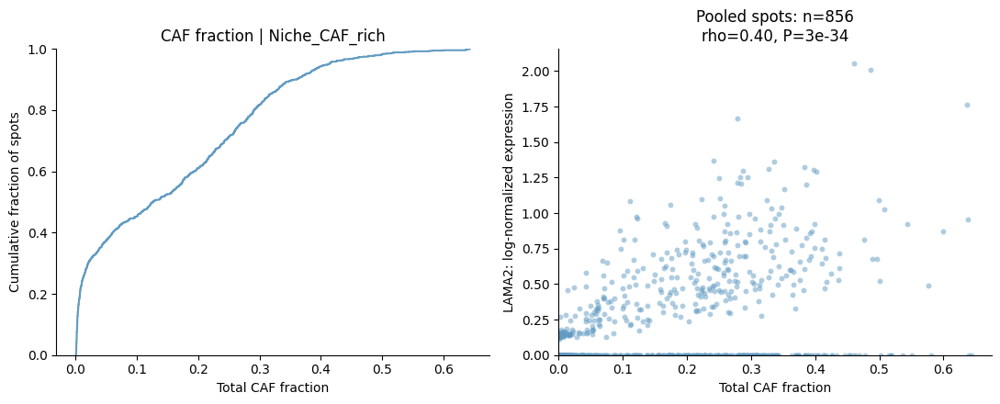

纳入的 CAF 亚型： ['CAF_COL14A1', 'Cycling_CAF', 'apCAF', 'iCAF_CXCL1', 'iCAF_CXCL8', 'myCAF_CTHRC1', 'qCAF']
 gene          niche  n_spots  CAF_median  gene_mean  gene_median     rho   p_value
MFAP5 Niche_CAF_rich      856      0.1262      0.445       0.4711 -0.3454 2.152e-25


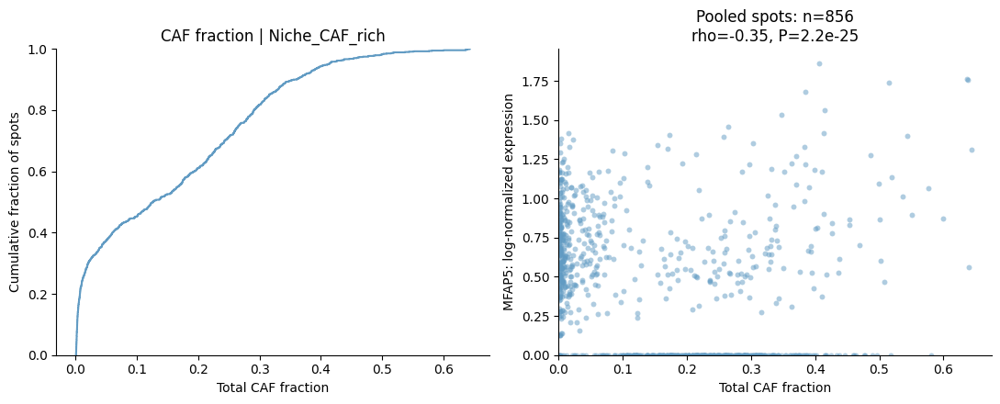

In [ ]:
res = plot_gene_caf(
    adata,
    gene="LAMA2",
    niche="Niche_CAF_rich",
)

# 换基因
res = plot_gene_caf(
    adata,
    gene="MFAP5",
    niche="Niche_CAF_rich",
)

模型亚型数： 43
映射表中有、模型中没有： []
模型中有、尚未归类： []
                                 CAF         T   Myeloid      Endo       Epi  \
HNSCC14_AAACAATCTACTAGCA-1  0.375972  0.621807  0.238518  0.170983  6.858804   
HNSCC14_AAACAGAGCGACTCCT-1  0.031624  0.454683  0.016695  0.027254  7.428721   
HNSCC14_AAACCGGGTAGGTACC-1  0.575617  0.536643  0.059437  0.530566  6.995726   
HNSCC14_AAACCGTTCGTCCAGG-1  3.158910  3.779915  1.402210  0.625999  3.387990   
HNSCC14_AAACCTCATGAAGTTG-1  0.948245  0.645658  0.453488  3.353295  4.839499   

                                   B    Plasma        NK  Neutrophil  \
HNSCC14_AAACAATCTACTAGCA-1  0.030580  0.017362  0.030587    0.088719   
HNSCC14_AAACAGAGCGACTCCT-1  0.011913  0.199839  0.022164    0.043319   
HNSCC14_AAACCGGGTAGGTACC-1  0.019368  0.001097  0.023873    0.060766   
HNSCC14_AAACCGTTCGTCCAGG-1  0.279103  0.125144  0.168383    2.775077   
HNSCC14_AAACCTCATGAAGTTG-1  0.117733  0.000422  0.038591    0.376122   

                                Mast   Unknown

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 3 is different from 1)

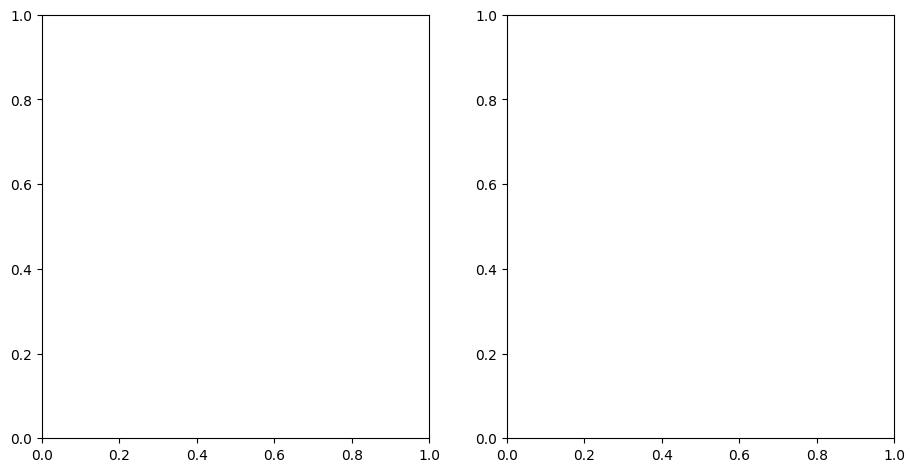

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# =========================================================
# 1. 根据你自己的单细胞注释定义大类
# =========================================================
big_to_sub = {
    "CAF": [
        "CAF_COL14A1",
        "Cycling_CAF",
        "apCAF",
        "iCAF_CXCL1",
        "iCAF_CXCL8",
        "myCAF_CTHRC1",
        "qCAF",
    ],

    "T": [
        "CD4T_CXCL13",
        "CD4T_GZMB",
        "CD4T_PTPRC",
        "CD4T_naive",
        "CD8T_CXCL13",
        "CD8T_GZMA",
        "CD8T_GZMK",
        "CD8T_naive",
        "CD8T_str",
        "Cycling_T",
        "Treg",
    ],

    "Myeloid": [
        "Mac_CXCL5",
        "Mac_FOLR2",
        "Mac_SPP1",
        "Mono_FCN1",
        "mregDC",
    ],

    "Endo": [
        "Arterial_EC",
        "Capillary_EC",
        "Cycling_EC",
        "EC_ACKR1",
        "EC_PGF",
        "qEC",
    ],

    "Epi": [
        "Basal_Epi",
        "Diff_Epi",
        "EMT_like_Epi",
        "Hypoxia_Epi",
        "Normal_Epi",
        "Prolif_Epi",
        "Stem_like_Epi",
        "Str_Epi",
    ],

    "B": ["B"],
    "Plasma": ["Plasma"],
    "NK": ["NK"],
    "Neutrophil": ["Neutrophil"],
    "Mast": ["Mast"],
    "Unknown": ["Unknown"],
}

# =========================================================
# 2. 提取原始 q05 丰度
# 注意：这里不用 q05_cell_abundance_w_sf_norm
# =========================================================
factor_names = list(adata.uns["mod"]["factor_names"])

q05 = pd.DataFrame(
    np.asarray(adata.obsm["q05_cell_abundance_w_sf"]),
    index=adata.obs_names,
    columns=factor_names,
)

# 检查注释表与实际模型标签是否一致
mapped = [
    subtype
    for subtypes in big_to_sub.values()
    for subtype in subtypes
]

missing = sorted(set(mapped) - set(q05.columns))
unmapped = sorted(set(q05.columns) - set(mapped))

print("模型亚型数：", len(factor_names))
print("映射表中有、模型中没有：", missing)
print("模型中有、尚未归类：", unmapped)

if missing or unmapped:
    raise ValueError("细胞标签与映射表不一致，请先核对上面的列表。")

# =========================================================
# 3. 汇总所有大类的丰度
# =========================================================
major_abundance = pd.DataFrame({
    group: q05[subtypes].sum(axis=1)
    for group, subtypes in big_to_sub.items()
})

# 保存到 obsm，避免覆盖 obs 中已有的 B、NK 等列
adata.obsm["major_cell_abundance_q05sum"] = major_abundance

print(major_abundance.head())

# =========================================================
# 4. 选择绘图大类，按全部样本的共同阈值缩放
# =========================================================
groups = ["CAF", "T", "Myeloid"]
tme = major_abundance[groups].copy()
scaled = tme.copy()

for group in groups:
    x = tme[group].to_numpy()

    lo = np.nanquantile(x, 0.05)
    hi = np.nanquantile(x, 0.95)

    if hi <= lo:
        hi = np.nanmax(x)

    scaled[group] = np.clip(
        (x - lo) / (hi - lo + 1e-12),
        0, 1,
    )

    print(f"{group}: 显示下限={lo:.4f}, 显示上限={hi:.4f}")

# =========================================================
# 5. 设置颜色
# =========================================================
base_colors = np.array([
    [0.90, 0.20, 0.18],   # CAF：红
    [0.15, 0.35, 0.90],   # T：蓝
    [0.20, 0.65, 0.32],   # Myeloid：绿
])

# 样本名需要与 uns["spatial"] 的键一致
samples = list(adata.obs["sample"].astype(str).unique())

print("样本名：", samples)
print("空间图像名称：", list(adata.uns["spatial"].keys()))

missing_images = [
    sample for sample in samples
    if sample not in adata.uns["spatial"]
]

if missing_images:
    raise ValueError(
        f"以下样本名没有对应的空间图像键：{missing_images}"
    )

# =========================================================
# 6. 绘制各样本
# =========================================================
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

fig, axes = plt.subplots(
    1,
    len(samples),
    figsize=(5.5 * len(samples), 5.5),
    squeeze=False,
)

for ax, sample in zip(axes.ravel(), samples):

    mask = adata.obs["sample"].astype(str).eq(sample).to_numpy()

    # 与该样本 spot 顺序一致
    weights = scaled.iloc[np.flatnonzero(mask)].to_numpy()

    # 颜色：三个信号的加权平均
    rgb = (
        weights @ base_colors
        / (weights.sum(axis=1, keepdims=True) + 1e-12)
    )

    # 透明度：由三类中最强的信号决定
    alpha = 0.12 + 0.83 * weights.max(axis=1)
    rgba = np.column_stack([rgb, alpha])

    # 组织图像和坐标
    spatial_info = adata.uns["spatial"][sample]
    img = spatial_info["images"]["hires"]
    scale = spatial_info["scalefactors"]["tissue_hires_scalef"]

    coords = np.asarray(adata.obsm["spatial"])[mask] * scale

    ax.imshow(img, alpha=0.45)

    ax.scatter(
        coords[:, 0],
        coords[:, 1],
        c=rgba,
        s=15,
        linewidths=0,
    )

    ax.set_title(sample, fontsize=15)
    ax.set_axis_off()

# =========================================================
# 7. 图例和保存
# =========================================================
handles = [
    Line2D(
        [], [],
        marker="o",
        linestyle="",
        markerfacecolor=color,
        markeredgecolor="none",
        markersize=9,
        label=label,
    )
    for color, label in zip(
        base_colors,
        ["CAF", ],#"T cells", "Myeloid"
    )
]

fig.legend(
    handles=handles,
    loc="lower center",
    ncol=3,
    frameon=False,
    fontsize=12,
)

fig.tight_layout(rect=[0, 0.08, 1, 1])

fig.savefig(
    "TME_spatial_mapping.pdf",
    bbox_inches="tight",
)

fig.savefig(
    "TME_spatial_mapping.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

HNSCC14: Pearson r=0.8703, P=0.000e+00; Spearman ρ=0.9861, P=0.000e+00
HNSCC59: Pearson r=0.7253, P=0.000e+00; Spearman ρ=0.2521, P=1.679e-36


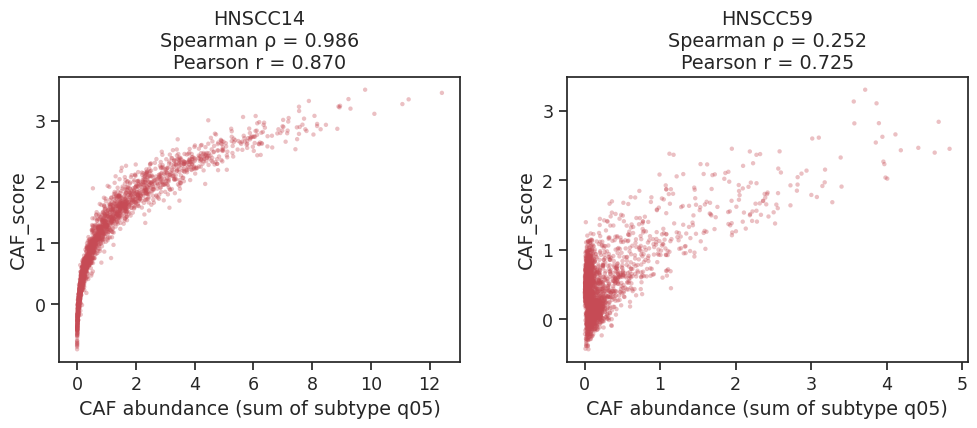

In [ ]:
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

samples = df["sample"].unique()

fig, axes = plt.subplots(
    1, len(samples),
    figsize=(5 * len(samples), 4.5),
    squeeze=False
)

for ax, sample in zip(axes.ravel(), samples):
    sub = df.loc[
        df["sample"] == sample,
        ["CAF_abundance", "CAF_score"]
    ].dropna()

    x = sub["CAF_abundance"]
    y = sub["CAF_score"]

    r, p_r = pearsonr(x, y)
    rho, p_s = spearmanr(x, y)

    ax.scatter(
        x, y,
        s=10,
        alpha=0.35,
        color="#C64B55",
        edgecolors="none"
    )

    ax.set_title(
        f"{sample}\n"
        f"Spearman ρ = {rho:.3f}\n"
        f"Pearson r = {r:.3f}"
    )
    ax.set_xlabel("CAF abundance (sum of subtype q05)")
    ax.set_ylabel("CAF_score")

    print(
        f"{sample}: "
        f"Pearson r={r:.4f}, P={p_r:.3e}; "
        f"Spearman ρ={rho:.4f}, P={p_s:.3e}"
    )

fig.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd


def define_caf_hotspot(
    adata,
    caf="myCAF_CTHRC1",
    quantile=0.8,
    sample_key="sample"
):

    adata.obs["CAF_hotspot"] = "Low"

    for sample in adata.obs[sample_key].unique():

        idx = adata.obs[sample_key] == sample

        thr = (
            adata.obs.loc[idx, caf]
            .quantile(quantile)
        )

        high_idx = (
            idx &
            (adata.obs[caf] >= thr)
        )

        adata.obs.loc[
            high_idx,
            "CAF_hotspot"
        ] = "High"

        print(
            sample,
            "threshold:",
            thr,
            "spots:",
            high_idx.sum()
        )

    return adata


adata = define_caf_hotspot(
    adata,
    caf="myCAF_CTHRC1",
    quantile=0.9
)

HNSCC14 threshold: 2.2079289999999996 spots: 222
HNSCC59 threshold: 0.24815630600000002 spots: 243


/tmp/ipykernel_3652/2085577307.py:5: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


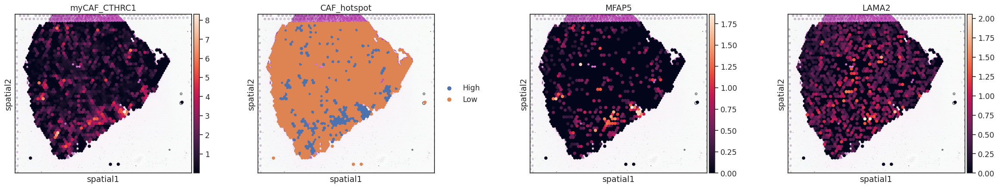

In [ ]:
import scanpy as sc

slide = select_slide(adata, 'HNSCC14')

sc.pl.spatial(
    slide,
    color=[
        "myCAF_CTHRC1",
        "CAF_hotspot","MFAP5","LAMA2"
    ],
    img_key="hires",
    spot_size=150
)

/tmp/ipykernel_3652/2729844582.py:5: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


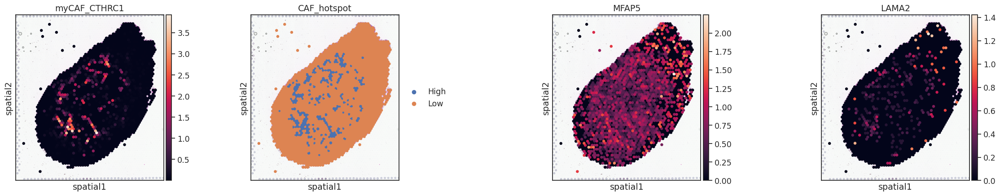

In [ ]:
import scanpy as sc

slide = select_slide(adata, 'HNSCC59')

sc.pl.spatial(
    slide,
    color=[
        "myCAF_CTHRC1",
        "CAF_hotspot","MFAP5","LAMA2"
    ],
    img_key="hires",
    spot_size=150
)

In [ ]:
from scipy.stats import spearmanr


genes = [
    "MFAP5",
    "LAMA2"
]


results=[]


for gene in genes:

    x = slide.obs["CAF_hotspot"]

    y = slide[:,gene].X


    if hasattr(y,"toarray"):
        y = y.toarray().flatten()
    else:
        y = np.array(y).flatten()


    r,p = spearmanr(
        x,
        y
    )


    results.append(
        {
            "gene":gene,
            "rho":r,
            "pvalue":p
        }
    )


pd.DataFrame(results)

    gene       rho        pvalue
0  MFAP5 -0.285170  1.120221e-42
1  LAMA2 -0.081292  1.290039e-04

# 量化

In [ ]:
threshold = adata[:, "LAMA2"].X.toarray().flatten()

lama2_cutoff = np.percentile(
    threshold,
    90
)

print("LAMA2 positive cutoff:", lama2_cutoff)

LAMA2 positive cutoff: 0.5275343


In [ ]:
import numpy as np
import pandas as pd
import scipy.sparse as sp


def quantify_lama2(
    adata,
    gene="LAMA2",
    cutoff=0.2,
    sample_key="sample"
):

    results = []

    # 提取表达
    x = adata[:, gene].X

    if sp.issparse(x):
        x = x.toarray().flatten()
    else:
        x = np.asarray(x).flatten()


    df = pd.DataFrame({
        "sample": adata.obs[sample_key].values,
        "LAMA2": x
    },
    index=adata.obs_names)


    for sample, sub in df.groupby("sample"):

        pos = sub["LAMA2"] > cutoff


        result = {
            "sample": sample,

            # 所有spot
            "n_spots": len(sub),

            # 阳性比例
            "LAMA2_positive_fraction":
                pos.mean(),


            # 全部spot平均
            "LAMA2_mean_all":
                sub["LAMA2"].mean(),


            # 阳性spot平均表达
            "LAMA2_mean_positive":
                sub.loc[pos, "LAMA2"].mean(),


            # 阳性spot数量
            "n_positive":
                pos.sum()
        }

        results.append(result)


    return pd.DataFrame(results)

In [ ]:
lama2_summary = quantify_lama2(
    adata,
    gene="LAMA2",
    cutoff=0.5275343
)

lama2_summary

/tmp/ipykernel_2015/2235248429.py:31: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for sample, sub in df.groupby("sample"):


    sample  n_spots  LAMA2_positive_fraction  LAMA2_mean_all  \
0  HNSCC14     2213                 0.188432        0.254812   
1  HNSCC59     2427                 0.019365        0.036218   

   LAMA2_mean_positive  n_positive  
0             0.780595         417  
1             0.839173          47  

In [ ]:
adata.obs["LAMA2_positive"] = (
    adata[:, "LAMA2"].X.toarray().flatten()
    > lama2_cutoff
)

In [ ]:
adata.obs["LAMA2_positive"] = (
    adata.obs["LAMA2_expr"] > 0
)

/tmp/ipykernel_13229/2951035206.py:5: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


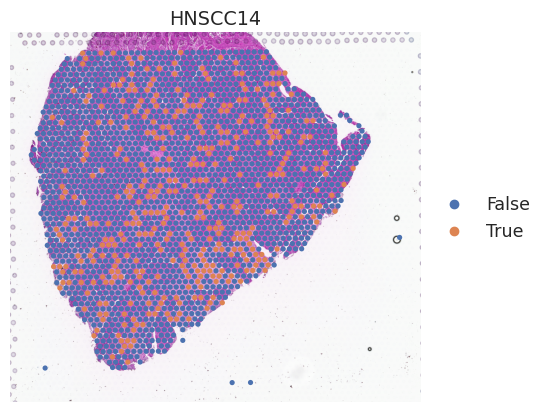

/tmp/ipykernel_13229/2951035206.py:5: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


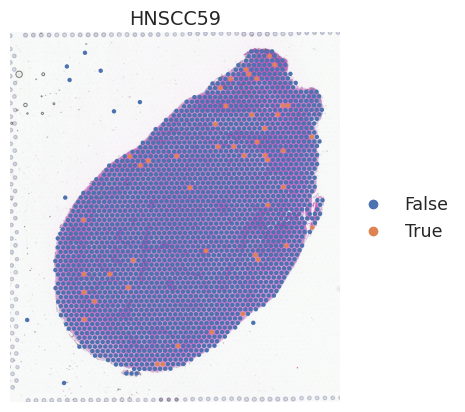

In [ ]:
for s in ["HNSCC14","HNSCC59"]:

    slide = adata[adata.obs["sample"] == s].copy()

    sc.pl.spatial(
        slide,
        color="LAMA2_positive",
        library_id=s,
        img_key="hires",
        size=1.3,
        title=s,
        frameon=False
    )

In [ ]:
adata

AnnData object with n_obs × n_vars = 4640 × 12179
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'log1p_total_counts_mt', 'clusters', 'leiden', 'gene_niche', 'subtype', '_indices', '_scvi_batch', '_scvi_labels', 'Program_1', 'Program_2', 'Program_3', 'Program_4', 'Program_5', 'Program_6', 'Program_7', 'LAMA2_positive', 'LAMA2_expr', 'Arterial_EC', 'B', 'Basal_Epi', 'CAF_COL14A1', 'CD4T_CXCL13', 'CD4T_GZMB', 'CD4T_PTPRC', 'CD4T_naive', 'CD8T_CXCL13', 'CD8T_GZMA', 'CD8T_GZMK', 'CD8T_naive', 'CD8T_str', 'Capillary_EC', 'Cycling_CAF', 'Cycling_EC', 'Cycling_T', 'Diff_Epi', 'EC_ACKR1', 'EC_PGF', 'EMT_like_Epi', 'Hypoxia_Epi', 'Mac_CXCL5', 'Mac_FOLR2', 'Mac_SPP1', 'Mast', 'Mono_FCN1', 'NK', 'Neutrophil', 'Normal_Epi', 'Plasma', 'Prolif_Epi'

In [ ]:
caf_thr = adata.obs[
    "CAF_score"
].quantile(0.9)
caf_thr

adata.obs["CAF_positive"] = (
    adata.obs["CAF_score"]
    >= caf_thr
)

In [ ]:
caf_thr

np.float64(1.974678518658593)

In [ ]:
def coloc(row):

    if (
        row["LAMA2_positive"]
        and row["CAF_positive"]
    ):
        return "LAMA2 positive & CAF Heatspot"

    elif row["CAF_positive"]:
        return "CAF high Heatspot"

    elif row["LAMA2_positive"]:
        return "LAMA2 positive spot"

    else:
        return "Other"


adata.obs["LAMA2_CAF_coloc"] = (
    adata.obs.apply(
        coloc,
        axis=1
    )
)

In [ ]:
adata.obs["LAMA2_CAF_coloc"].unique()

array(['Other', 'CAF high Heatspot', 'LAMA2 positive spot',
       'LAMA2 positive & CAF Heatspot'], dtype=object)

In [ ]:
adata.obs[
    "LAMA2_CAF_coloc"
].value_counts()

adata.obs["LAMA2_CAF_coloc_plot"] = adata.obs["LAMA2_CAF_coloc"]

# adata.obs.loc[
#     adata.obs["LAMA2_CAF_coloc_plot"] == "Other",
#     "LAMA2_CAF_coloc_plot"
# ] = np.nan

colormap = {
    "LAMA2 positive & CAF Heatspot": "#d73027",
    "CAF Heatspot": "#3288bd",
    "LAMA2 positive spot": "#fdae61",
        # 绿
}

adata.obs["LAMA2_CAF_coloc_plot"] = pd.Categorical(
    adata.obs["LAMA2_CAF_coloc_plot"],
    categories=[
        "LAMA2 positive & CAF Heatspot",
        "LAMA2 positive spot",
        "CAF Heatspot",
    ],
    ordered=True
)

/tmp/ipykernel_2015/929940139.py:11: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  fig = sc.pl.spatial(


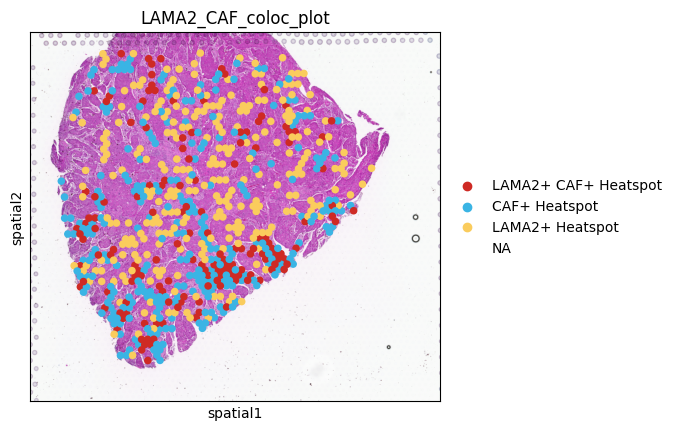

/tmp/ipykernel_2015/929940139.py:11: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  fig = sc.pl.spatial(


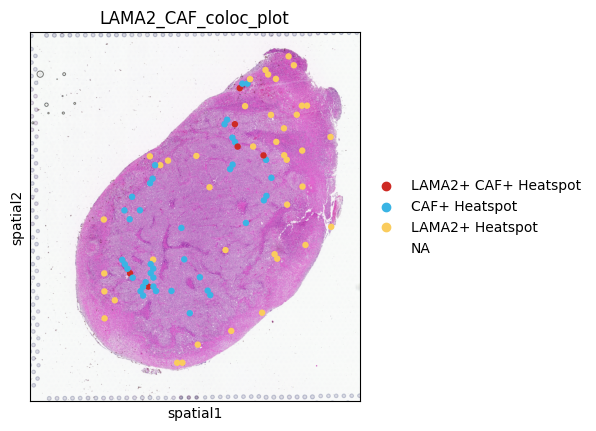

In [ ]:
import matplotlib.pyplot as plt
import os

outdir = "./visum/figure/"
os.makedirs(outdir, exist_ok=True)

for s in ["HNSCC14", "HNSCC59"]:

    slide = adata[adata.obs["sample"] == s].copy()

    fig = sc.pl.spatial(
        slide,
        color="LAMA2_CAF_coloc_plot",
        library_id=s,
        palette=colormap,
        img_key="hires",
        spot_size=150,
        show=False,
        return_fig=True
    )

    fig.savefig(
        f"{outdir}/{s}_LAMA2_CAF_coloc_plot.tiff",
        dpi=600,
        bbox_inches="tight",
        pil_kwargs={"compression": "tiff_lzw"}
    )
    plt.show(fig)
    plt.close(fig)

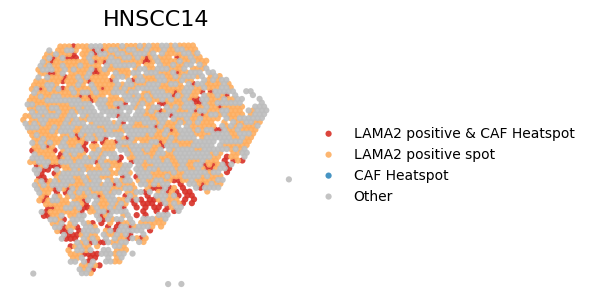

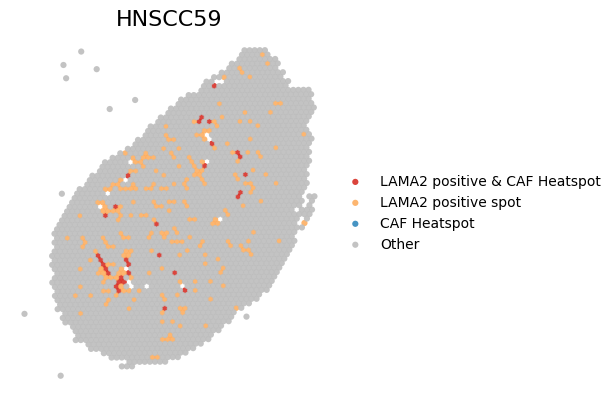

In [ ]:
import matplotlib.pyplot as plt
import os

outdir = "./visum/figure/"
os.makedirs(outdir, exist_ok=True)


colors = {
    "LAMA2 positive & CAF Heatspot": "#d73027",
    "CAF Heatspot": "#3288bd",
    "LAMA2 positive spot": "#fdae61",
    "Other": "#BDBDBD"
}


for s in ["HNSCC14", "HNSCC59"]:

    slide = adata[
        adata.obs["sample"] == s
    ].copy()

    xy = slide.obsm["spatial"]

    fig, ax = plt.subplots(
        figsize=(6,6)
    )


    # 绘制顺序：Other底层，双阳性最上层
    for cat in [
        "LAMA2 positive & CAF Heatspot",
        "LAMA2 positive spot",
        "CAF Heatspot",
        "Other",

    ]:

        mask = (
            slide.obs["LAMA2_CAF_coloc"]
            == cat
        )

        ax.scatter(
            xy[mask,0],
            xy[mask,1],
            s=20,              # ↓ spot大小（原35）
            c=colors[cat],
            label=cat,
            alpha=0.9,
            edgecolors="none"
        )


    ax.invert_yaxis()
    ax.set_aspect("equal")

    ax.set_title(
        s,
        fontsize=16
    )

    ax.axis("off")


    ax.legend(
        loc="center left",
        bbox_to_anchor=(1,0.5),
        frameon=False,
        fontsize=10
    )


    plt.tight_layout()


    # 保存
    fig.savefig(
        f"{outdir}/{s}_LAMA2_CAF_coloc.tiff",
        dpi=600,
        bbox_inches="tight",
        pil_kwargs={"compression": "tiff_lzw"}
    )


    plt.show()
    plt.close(fig)

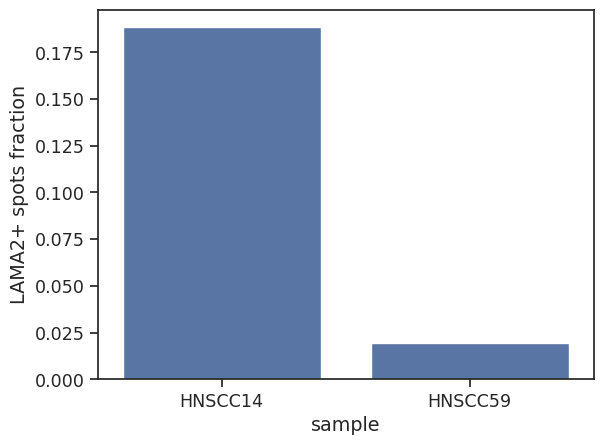

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt


sns.barplot(
    data=lama2_summary,
    x="sample",
    y="LAMA2_positive_fraction"
)

plt.ylabel("LAMA2+ spots fraction")
plt.show()

In [ ]:
sq.gr.spatial_neighbors(
    adata,
    coord_type="grid",
    n_neighs=6
)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_13229/3060173184.py:1: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(


In [ ]:
adata.obs["LAMA2_CAF_double_positive"] = (
    adata.obs["LAMA2_positive"]
    &
    adata.obs["CAF_positive"]
)

In [ ]:
adata.obs["LAMA2_CAF_double_positive_I"] = (
    adata.obs["LAMA2_CAF_double_positive"]
    .astype(int)
)

In [ ]:
adata.obs["LAMA2_CAF_double_positive_I"].value_counts()

LAMA2_CAF_double_positive_I
0    4486
1     154
Name: count, dtype: int64

In [ ]:
import anndata as ad
import numpy as np
import squidpy as sq


for s in ["HNSCC14", "HNSCC59"]:

    slide = adata[
        adata.obs["sample"] == s
    ].copy()


    # 提取binary变量
    binary = (
        slide.obs[
            "LAMA2_CAF_double_positive_I"
        ]
        .astype(float)
        .to_frame()
    )


    # 新AnnData
    adata_binary = ad.AnnData(
        X=binary.values,
        obs=slide.obs.copy(),
        var=pd.DataFrame(
            index=["LAMA2_CAF_double_positive_I"]
        )
    )


    # 复制空间信息
    adata_binary.obsm["spatial"] = (
        slide.obsm["spatial"].copy()
    )

    adata_binary.uns["spatial"] = (
        slide.uns["spatial"].copy()
    )


    # 建空间邻接
    sq.gr.spatial_neighbors(
        adata_binary,
        coord_type="grid",
        n_neighs=6,
        n_rings=2
    )


    # Moran
    sq.gr.spatial_autocorr(
        adata_binary,
        genes=[
            "LAMA2_CAF_double_positive_I"
        ],
        mode="moran",
        use_raw=False,
        n_perms=None,
        transformation=True
    )


    print("\n", s)

    print(
        adata_binary.uns["moranI"]
    )

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_13229/3365234016.py:44: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(



 HNSCC14
                                    I  pval_norm  var_norm  pval_norm_fdr_bh
LAMA2_CAF_double_positive_I  0.101051        0.0  0.000055               0.0
INFO     Creating graph using `None` transform and `1` libraries.                                                  

 HNSCC59
                                    I  pval_norm  var_norm  pval_norm_fdr_bh
LAMA2_CAF_double_positive_I -0.002576    0.37869  0.000049           0.37869


/tmp/ipykernel_13229/3365234016.py:44: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(


In [ ]:
import anndata as ad
import pandas as pd
import squidpy as sq
import numpy as np


def calculate_moran_obs(
    slide,
    obs_key
):

    # obs变量转为矩阵
    X = slide.obs[[obs_key]].astype(float)


    # 创建新的AnnData
    adata_moran = ad.AnnData(
        X=X.values,
        obs=slide.obs.copy(),
        var=pd.DataFrame(
            index=[obs_key]
        )
    )


    # 复制空间信息
    adata_moran.obsm["spatial"] = (
        slide.obsm["spatial"].copy()
    )

    adata_moran.uns["spatial"] = (
        slide.uns["spatial"].copy()
    )


    # 空间邻接
    sq.gr.spatial_neighbors(
        adata_moran,
        coord_type="grid",
        n_neighs=6
    )


    # Moran I
    sq.gr.spatial_autocorr(
        adata_moran,
        mode="moran",
        genes=[obs_key]
    )


    return adata_moran.uns["moranI"]

In [ ]:
import scipy.sparse as sp


x = adata[:, "LAMA2"].X

if sp.issparse(x):
    x = x.toarray().flatten()
else:
    x = np.asarray(x).flatten()


adata.obs["LAMA2_expr"] = x

In [ ]:
for s in ["HNSCC14", "HNSCC59"]:

    slide = adata[
        adata.obs["sample"] == s
    ].copy()


    print("\n==========", s, "==========")


    for key in [
        "LAMA2_expr",
        "CAF_score",
        "LAMA2_CAF_double_positive_I"
    ]:

        result = calculate_moran_obs(
            slide,
            key
        )

        print("\n", key)

        print(
            result[
                [
                    "I",
                    "pval_norm",
                    "pval_norm_fdr_bh"
                ]
            ]
        )


========== HNSCC14 ==========
INFO     Creating graph using `None` transform and `1` libraries.                                                  

 LAMA2_expr
                   I  pval_norm  pval_norm_fdr_bh
LAMA2_expr  0.028724   0.010511          0.010511
INFO     Creating graph using `None` transform and `1` libraries.                                                  

 CAF_score
                  I  pval_norm  pval_norm_fdr_bh
CAF_score  0.456898        0.0               0.0
INFO     Creating graph using `None` transform and `1` libraries.                                                  

 LAMA2_CAF_double_positive_I
                                    I  pval_norm  pval_norm_fdr_bh
LAMA2_CAF_double_positive_I  0.119993        0.0               0.0


/tmp/ipykernel_13229/2876119870.py:37: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(
/tmp/ipykernel_13229/2876119870.py:37: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(
/tmp/ipykernel_13229/2876119870.py:37: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(



========== HNSCC59 ==========
INFO     Creating graph using `None` transform and `1` libraries.                                                  

 LAMA2_expr
                   I  pval_norm  pval_norm_fdr_bh
LAMA2_expr  0.045086   0.000076          0.000076
INFO     Creating graph using `None` transform and `1` libraries.                                                  

 CAF_score
                  I  pval_norm  pval_norm_fdr_bh
CAF_score  0.357582        0.0               0.0
INFO     Creating graph using `None` transform and `1` libraries.                                                  

 LAMA2_CAF_double_positive_I
                                    I  pval_norm  pval_norm_fdr_bh
LAMA2_CAF_double_positive_I -0.002513   0.430583          0.430583


/tmp/ipykernel_13229/2876119870.py:37: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(
/tmp/ipykernel_13229/2876119870.py:37: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(
/tmp/ipykernel_13229/2876119870.py:37: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(


In [ ]:
import numpy as np
import scipy.sparse as sp

gene = "LAMA2"

x = adata[:, gene].X

if sp.issparse(x):
    x = x.toarray().flatten()
else:
    x = np.asarray(x).flatten()

adata.obs["LAMA2_expr"] = x

caf_cols = [
    "myCAF_CTHRC1",
    "iCAF_CXCL8",
    "iCAF_CXCL1",
    "apCAF",
    "qCAF",
    "Cycling_CAF",
    "CAF_COL14A1"
]

In [ ]:
from scipy.stats import spearmanr

for caf in caf_cols:

    rho, p = spearmanr(
        adata.obs[caf],
        adata.obs["LAMA2_expr"]
    )

    print(
        caf,
        "rho=",round(rho,3),
        "p=",p
    )

myCAF_CTHRC1 rho= 0.302 p= 2.2161456521680686e-98
iCAF_CXCL8 rho= 0.049 p= 0.0008320358751100338
iCAF_CXCL1 rho= 0.315 p= 1.7394070839779142e-107
apCAF rho= 0.154 p= 4.8611625111514096e-26
qCAF rho= -0.111 p= 2.7280488944236784e-14
Cycling_CAF rho= -0.017 p= 0.2531870565553878
CAF_COL14A1 rho= 0.403 p= 6.267875171598844e-181


In [ ]:
for sample in ["HNSCC14","HNSCC59"]:

    sub = adata[
        adata.obs["sample"]==sample
    ]

    print("\n",sample)

    for caf in caf_cols:

        rho,p = spearmanr(
            sub.obs[caf],
            sub.obs["LAMA2_expr"]
        )

        print(
            caf,
            "rho=",round(rho,3),
            "p=",p
        )


 HNSCC14
myCAF_CTHRC1 rho= 0.096 p= 5.4565364031890215e-06
iCAF_CXCL8 rho= 0.017 p= 0.4313871355946157
iCAF_CXCL1 rho= 0.071 p= 0.0008483877797475907
apCAF rho= 0.089 p= 2.764787694388796e-05
qCAF rho= 0.096 p= 6.631550206002275e-06
Cycling_CAF rho= 0.006 p= 0.7953402830821873
CAF_COL14A1 rho= 0.077 p= 0.00027533708168614055

 HNSCC59
myCAF_CTHRC1 rho= 0.179 p= 6.151018163273655e-19
iCAF_CXCL8 rho= 0.046 p= 0.02215789513318108
iCAF_CXCL1 rho= 0.227 p= 1.270394652667877e-29
apCAF rho= 0.149 p= 1.536123372107936e-13
qCAF rho= 0.234 p= 1.6699095716879089e-31
Cycling_CAF rho= 0.105 p= 2.3204494930410107e-07
CAF_COL14A1 rho= 0.24 p= 3.500479766219876e-33


In [ ]:
pd.crosstab(
    adata.obs["gene_niche"],
    adata.obs["LAMA2_positive"],
    normalize="index"
)

LAMA2_positive                False     True 
gene_niche                                   
Niche_CAF_rich             0.657710  0.342290
Niche_ECM                  0.848943  0.151057
Niche_Inflammatory         0.920188  0.079812
Niche_Migration            0.919949  0.080051
Niche_OXPHOS               0.785861  0.214139
Niche_Squamous_epithelial  0.505895  0.494105

In [ ]:
adata=sc.read_h5ad("./visum/st.h5ad")

In [ ]:

import numpy as np
import pandas as pd
from scipy import sparse

GENE = "LAMA2"

LAMA2_THRESHOLD = 0.5275343
CAF_THRESHOLD = 1.974678518658593

SAMPLES = ["HNSCC14", "HNSCC59"]

# 1. 提取 LAMA2 表达
gene_x = adata[:, [GENE]].X

if sparse.issparse(gene_x):
    gene_expr = gene_x.toarray().ravel()
else:
    gene_expr = np.asarray(gene_x).ravel()

# 2. 直接提取已有 CAF_score
caf_score = pd.to_numeric(
    adata.obs["CAF_score"],
    errors="coerce"
)

# 3. 提取空间坐标
xy = np.asarray(adata.obsm["spatial"])

# 4. 构建分析 DataFrame
df = pd.DataFrame(
    {
        "sample": adata.obs["sample"].astype(str).to_numpy(),
        "LAMA2": gene_expr,
        "CAF_score": caf_score.to_numpy(),
        "x": xy[:, 0],
        "y": xy[:, 1],
    },
    index=adata.obs_names
)

# 过滤缺失值
df = df.replace([np.inf, -np.inf], np.nan)

df = df.dropna(
    subset=["LAMA2", "CAF_score", "x", "y"]
)

# 5. 根据你已经确定的阈值定义阳性
df["LAMA2_positive"] = (
    df["LAMA2"] > LAMA2_THRESHOLD
)

df["CAF_positive"] = (
    df["CAF_score"] > CAF_THRESHOLD
)

# 6. 划分四类 spot
conditions = [
    df["LAMA2_positive"] & df["CAF_positive"],
    df["LAMA2_positive"] & ~df["CAF_positive"],
    ~df["LAMA2_positive"] & df["CAF_positive"]
]

choices = [
    "LAMA2+ CAF+",
    "LAMA2+ CAF-",
    "LAMA2- CAF+"
]

df["LAMA2_CAF_coloc"] = np.select(
    conditions,
    choices,
    default="Other"
)

# 7. 检查两张切片的阳性 spot
for sample in SAMPLES:

    sub = df[df["sample"] == sample]

    print(f"\n========== {sample} ==========")

    print("Total spots:", len(sub))

    print(
        pd.crosstab(
            sub["LAMA2_positive"],
            sub["CAF_positive"],
            margins=True
        )
    )
# ============================================================
# 2. 创建每张切片的空间邻接矩阵
# ============================================================

def build_spatial_graph(coords, radius_factor=1.25):
    """
    根据 spot 坐标构建无向空间邻接图。

    radius = 每个 spot 最近邻距离的中位数 × 1.25

    适用于坐标中相邻 Visium spot 的间距基本一致的情况。
    """

    coords = np.asarray(coords, dtype=float)

    n = coords.shape[0]

    if n < 2:
        raise ValueError("spot 数量不足")

    tree = cKDTree(coords)

    dist, _ = tree.query(coords, k=2)

    nn_dist = dist[:, 1]

    median_dist = np.median(nn_dist[nn_dist > 0])

    if not np.isfinite(median_dist):
        raise ValueError("无法确定最近邻距离，请检查 spatial 坐标")

    radius = median_dist * radius_factor

    pairs = np.asarray(
        list(tree.query_pairs(r=radius)),
        dtype=int
    ).reshape(-1, 2)

    if len(pairs) == 0:
        raise ValueError("空间邻接图没有边，请检查坐标和 radius")

    rows = np.r_[pairs[:, 0], pairs[:, 1]]
    cols = np.r_[pairs[:, 1], pairs[:, 0]]

    graph = sparse.csr_matrix(
        (
            np.ones(len(rows)),
            (rows, cols)
        ),
        shape=(n, n)
    )

    graph.setdiag(0)
    graph.eliminate_zeros()

    return graph


# ============================================================
# 3. 分别进行共定位、Spearman 和空间邻域检验
# ============================================================

rng = np.random.default_rng(SEED)

results = []

permutation_results = {}

for sample in SAMPLES:

    sub = df.loc[df["sample"] == sample].copy()

    print(f"\n{'=' * 60}")
    print("Processing:", sample)
    print("Number of spots:", len(sub))

    expr = sub["LAMA2"].to_numpy(dtype=float)
    caf = sub["CAF_score"].to_numpy(dtype=float)


    lama_pos = sub["LAMA2_positive"].to_numpy(dtype=bool)
    caf_pos = sub["CAF_positive"].to_numpy(dtype=bool)

    n = len(sub)
    n_lama = int(lama_pos.sum())
    n_caf = int(caf_pos.sum())

    if n_lama == 0 or n_lama == n:
        print("LAMA2 阳性或阴性 spot 不足，跳过")
        continue

    if n_caf == 0 or n_caf == n:
        print("CAF 阳性或阴性 spot 不足，跳过")
        continue

    # --------------------------------------------------------
    # Analysis 1：同一个 spot 中的 LAMA2-CAF 共定位
    # --------------------------------------------------------

    # 全切片 CAF+ 的背景比例
    p_caf_global = caf_pos.mean()

    # LAMA2+ spot 中有多少比例是 CAF+
    p_caf_given_lama = caf_pos[lama_pos].mean()

    # LAMA2- spot 中有多少比例是 CAF+
    p_caf_given_not_lama = caf_pos[~lama_pos].mean()

    # 相对于全切片背景的富集倍数
    fold_enrichment = (
        p_caf_given_lama / p_caf_global
        if p_caf_global > 0 else np.nan
    )

    # 2 × 2 列联表
    a = np.sum(lama_pos & caf_pos)
    b = np.sum(lama_pos & ~caf_pos)
    c = np.sum(~lama_pos & caf_pos)
    d = np.sum(~lama_pos & ~caf_pos)

    contingency = np.array([
        [a, b],
        [c, d]
    ])

    # 单侧检验：LAMA2+ 中 CAF+ 是否富集
    odds_ratio, p_fisher = fisher_exact(
        contingency,
        alternative="greater"
    )

    print("\n[1] Same-spot colocalization")

    print("CAF+ in all spots:",
          f"{p_caf_global:.3f}")

    print("CAF+ among LAMA2+ spots:",
          f"{p_caf_given_lama:.3f}")

    print("CAF+ among LAMA2- spots:",
          f"{p_caf_given_not_lama:.3f}")

    print("Fold enrichment:",
          f"{fold_enrichment:.3f}")

    print("Fisher OR:",
          f"{odds_ratio:.3f}")

    print("Fisher P:",
          f"{p_fisher:.4g}")

    # --------------------------------------------------------
    # Analysis 2：连续表达 Spearman 相关
    # --------------------------------------------------------

    if np.unique(expr).size > 1 and np.unique(caf).size > 1:
        rho, p_spearman = spearmanr(expr, caf)
    else:
        rho, p_spearman = np.nan, np.nan

    print("\n[2] Spearman correlation")

    print("Spearman rho:",
          f"{rho:.3f}")

    print("P value:",
          f"{p_spearman:.4g}")

    # --------------------------------------------------------
    # Analysis 3：空间邻域富集 + permutation
    # --------------------------------------------------------

    coords = sub[["x", "y"]].to_numpy()

    graph = build_spatial_graph(coords)

    degree = np.asarray(graph.sum(axis=1)).ravel()

    # 每个 spot 周围的 CAF+ 邻居数量
    neighbor_caf_n = np.asarray(
        graph @ caf_pos.astype(float)
    ).ravel()

    # 每个 spot 的 CAF+ 邻居比例
    neighbor_caf_fraction = np.divide(
        neighbor_caf_n,
        degree,
        out=np.full(n, np.nan),
        where=degree > 0
    )

    has_neighbors = np.isfinite(neighbor_caf_fraction)

    pos_mask = lama_pos & has_neighbors
    neg_mask = ~lama_pos & has_neighbors

    # LAMA2+ 周围的平均 CAF+ 邻居比例
    obs_pos = neighbor_caf_fraction[pos_mask].mean()

    # LAMA2- 周围的平均 CAF+ 邻居比例
    obs_neg = neighbor_caf_fraction[neg_mask].mean()

    # 观察到的邻域富集差值
    obs_delta = obs_pos - obs_neg

    # 零假设：LAMA2 阳性标签与 CAF 邻域没有关联
    perm_delta = np.empty(N_PERM)

    for i in range(N_PERM):

        shuffled_lama = rng.permutation(lama_pos)

        perm_pos = shuffled_lama & has_neighbors
        perm_neg = ~shuffled_lama & has_neighbors

        perm_delta[i] = (
            neighbor_caf_fraction[perm_pos].mean()
            -
            neighbor_caf_fraction[perm_neg].mean()
        )

    # 单侧经验 P 值：检验正向邻域富集
    p_perm = (
        1 + np.sum(perm_delta >= obs_delta)
    ) / (N_PERM + 1)

    perm_mean = perm_delta.mean()
    perm_sd = perm_delta.std(ddof=1)

    zscore = (
        (obs_delta - perm_mean) / perm_sd
        if perm_sd > 0 else np.nan
    )

    print("\n[3] Spatial neighborhood enrichment")

    print("Mean CAF+ neighbor fraction | LAMA2+:",
          f"{obs_pos:.3f}")

    print("Mean CAF+ neighbor fraction | LAMA2-:",
          f"{obs_neg:.3f}")

    print("Observed difference:",
          f"{obs_delta:.3f}")

    print("Permutation Z score:",
          f"{zscore:.3f}")

    print("Permutation P:",
          f"{p_perm:.4g}")

    # 保存邻域统计到每个 spot
    df.loc[sub.index, "CAF_neighbor_fraction"] = (
        neighbor_caf_fraction
    )

    permutation_results[sample] = perm_delta

    # --------------------------------------------------------
    # 汇总每张切片的结果
    # --------------------------------------------------------

    results.append({
        "sample": sample,
        "n_spots": n,
        "n_LAMA2_positive": n_lama,
        "n_CAF_positive": n_caf,
        "n_double_positive": int(a),

        "CAF_positive_global": p_caf_global,
        "CAF_positive_given_LAMA2": p_caf_given_lama,
        "CAF_positive_given_no_LAMA2": p_caf_given_not_lama,

        "same_spot_fold_enrichment": fold_enrichment,
        "Fisher_OR": odds_ratio,
        "Fisher_P": p_fisher,

        "Spearman_rho": rho,
        "Spearman_P": p_spearman,

        "neighbor_CAF_LAMA2_positive": obs_pos,
        "neighbor_CAF_LAMA2_negative": obs_neg,
        "neighbor_difference": obs_delta,

        "permutation_Z": zscore,
        "permutation_P": p_perm,
    })


# ============================================================
# 4. 保存结果
# ============================================================

result_df = pd.DataFrame(results)

result_df.to_csv(
    f"{OUTDIR}/LAMA2_CAF_statistics.csv",
    index=False
)

df.to_csv(
    f"{OUTDIR}/LAMA2_CAF_spot_data.csv"
)

print("\nFinal results:")
print(result_df.T)


========== HNSCC14 ==========
Total spots: 2213
CAF_positive    False  True   All
LAMA2_positive                   
False            1527   269  1796
True              269   148   417
All              1796   417  2213

========== HNSCC59 ==========
Total spots: 2427
CAF_positive    False  True   All
LAMA2_positive                   
False            2339    41  2380
True               41     6    47
All              2380    47  2427

Processing: HNSCC14
Number of spots: 2213

[1] Same-spot colocalization
CAF+ in all spots: 0.188
CAF+ among LAMA2+ spots: 0.355
CAF+ among LAMA2- spots: 0.150
Fold enrichment: 1.884
Fisher OR: 3.123
Fisher P: 8.928e-20

[2] Spearman correlation
Spearman rho: 0.086
P value: 5.328e-05

[3] Spatial neighborhood enrichment
Mean CAF+ neighbor fraction | LAMA2+: 0.259
Mean CAF+ neighbor fraction | LAMA2-: 0.173
Observed difference: 0.085
Permutation Z score: 6.683
Permutation P: 0.0005

Processing: HNSCC59
Number of spots: 2427

[1] Same-spot colocalization
CAF

In [ ]:
caf = sub["CAF_score"].to_numpy(dtype=float)

rho, p_spearman = spearmanr(
    sub["LAMA2"],
    sub["CAF_score"]
)

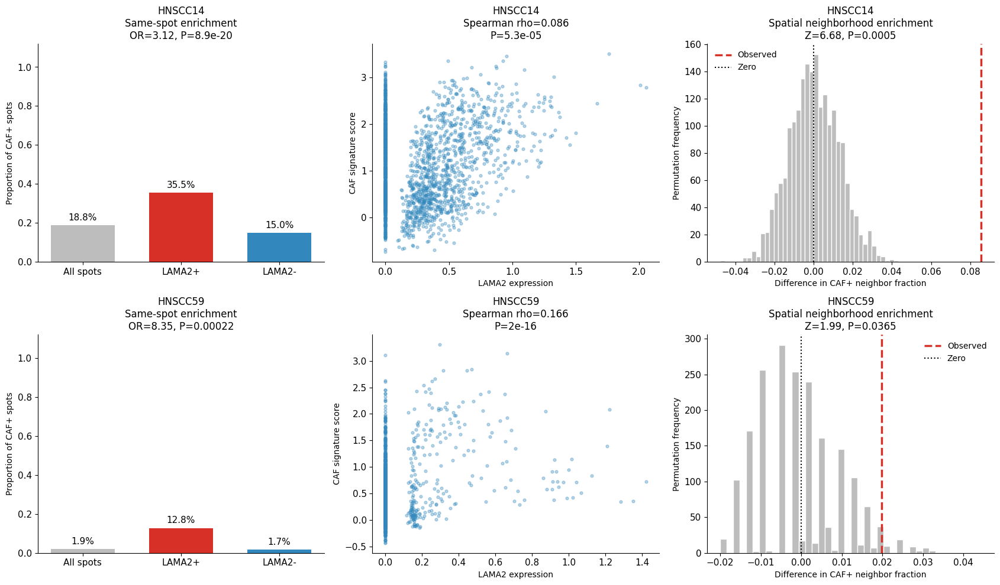

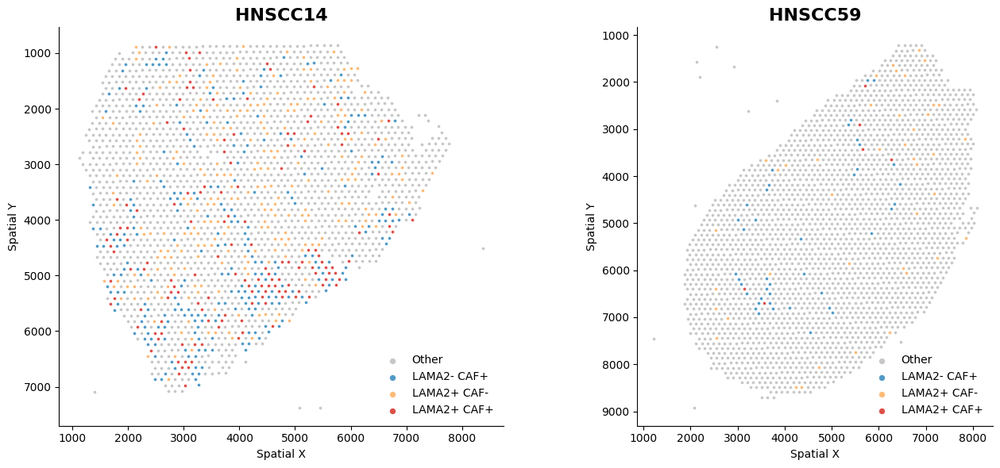

In [ ]:

# ============================================================
# 5. 绘制统计图
# ============================================================

fig, axes = plt.subplots(
    len(SAMPLES), 3,
    figsize=(17, 5 * len(SAMPLES)),
    squeeze=False
)

for i, sample in enumerate(SAMPLES):

    if sample not in result_df["sample"].values:
        continue

    sub = df[df["sample"] == sample]

    res = result_df.set_index("sample").loc[sample]

    ax1, ax2, ax3 = axes[i]

    # --------------------------------------------------------
    # A. CAF 阳性比例
    # --------------------------------------------------------

    values = [
        res["CAF_positive_global"],
        res["CAF_positive_given_LAMA2"],
        res["CAF_positive_given_no_LAMA2"]
    ]

    names = [
        "All spots",
        "LAMA2+",
        "LAMA2-"
    ]

    colors = ["#BDBDBD", "#D73027", "#3288BD"]

    bars = ax1.bar(
        names,
        values,
        color=colors,
        width=0.65
    )

    for bar, val in zip(bars, values):
        ax1.text(
            bar.get_x() + bar.get_width() / 2,
            val + 0.025,
            f"{val:.1%}",
            ha="center",
            fontsize=11
        )

    ax1.set_ylim(0, 1.12)
    ax1.set_ylabel("Proportion of CAF+ spots")

    ax1.set_title(
        f"{sample}\n"
        f"Same-spot enrichment\n"
        f"OR={res['Fisher_OR']:.2f}, "
        f"P={res['Fisher_P']:.2g}"
    )

    # --------------------------------------------------------
    # B. Spearman 相关
    # --------------------------------------------------------
    ax2.scatter(
    sub["LAMA2"],
    sub["CAF_score"],
    s=12,
    alpha=0.35,
    color="#3288BD"
    )

    ax2.set_xlabel("LAMA2 expression")
    ax2.set_ylabel("CAF signature score")
    # ax2.scatter(
    #     sub["LAMA2"],
    #     sub["CAF_fraction"],
    #     s=12,
    #     alpha=0.35,
    #     color="#3288BD",
    #     edgecolors="none"
    # )

    # ax2.set_xlabel("LAMA2 expression")
    # ax2.set_ylabel("CAF relative abundance")

    ax2.set_title(
        f"{sample}\n"
        f"Spearman rho={res['Spearman_rho']:.3f}\n"
        f"P={res['Spearman_P']:.2g}"
    )

    # --------------------------------------------------------
    # C. 空间 permutation
    # --------------------------------------------------------

    perm = permutation_results[sample]

    ax3.hist(
        perm,
        bins=40,
        color="#BDBDBD",
        edgecolor="white"
    )

    ax3.axvline(
        res["neighbor_difference"],
        color="#D73027",
        linestyle="--",
        linewidth=2.5,
        label="Observed"
    )

    ax3.axvline(
        0,
        color="black",
        linestyle=":",
        linewidth=1.5,
        label="Zero"
    )

    ax3.set_xlabel(
        "Difference in CAF+ neighbor fraction"
    )

    ax3.set_ylabel("Permutation frequency")

    ax3.set_title(
        f"{sample}\n"
        f"Spatial neighborhood enrichment\n"
        f"Z={res['permutation_Z']:.2f}, "
        f"P={res['permutation_P']:.3g}"
    )

    ax3.legend(frameon=False)

    for ax in [ax1, ax2, ax3]:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.tick_params(labelsize=11)

plt.tight_layout()

plt.savefig(
    f"{OUTDIR}/LAMA2_CAF_analysis.tiff",
    dpi=600,
    bbox_inches="tight",
    pil_kwargs={"compression": "tiff_lzw"}
)

plt.show()


# ============================================================
# 6. 四类 spot 的空间分布图
# ============================================================

palette = {
    "LAMA2+ CAF+": "#D73027",
    "LAMA2+ CAF-": "#FDAE61",
    "LAMA2- CAF+": "#3288BD",
    "Other": "#BDBDBD"
}

plot_order = [
    "Other",
    "LAMA2- CAF+",
    "LAMA2+ CAF-",
    "LAMA2+ CAF+"
]

fig, axes = plt.subplots(
    1, len(SAMPLES),
    figsize=(7 * len(SAMPLES), 6),
    squeeze=False
)

for ax, sample in zip(axes.ravel(), SAMPLES):

    sub = df[df["sample"] == sample]

    for cat in plot_order:

        part = sub[
            sub["LAMA2_CAF_coloc"] == cat
        ]

        ax.scatter(
            part["x"],
            part["y"],
            s=7,
            c=palette[cat],
            label=cat,
            alpha=0.85,
            linewidths=0,
            rasterized=True
        )

    ax.invert_yaxis()
    ax.set_aspect("equal")

    ax.set_title(
        sample,
        fontsize=16,
        fontweight="bold"
    )

    ax.set_xlabel("Spatial X")
    ax.set_ylabel("Spatial Y")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(
        frameon=False,
        loc="best",
        fontsize=10,
        markerscale=2
    )

plt.tight_layout()

plt.savefig(
    f"{OUTDIR}/LAMA2_CAF_spatial.tiff",
    dpi=600,
    bbox_inches="tight",
    pil_kwargs={"compression": "tiff_lzw"}
)

plt.show()


# ============================================================
# 7. 可选：将结果写回原始 adata
# ============================================================

adata.obs["LAMA2_positive"] = (
    df["LAMA2_positive"]
    .reindex(adata.obs_names)
    .astype("boolean")
)

adata.obs["CAF_positive"] = (
    df["CAF_positive"]
    .reindex(adata.obs_names)
    .astype("boolean")
)

adata.obs["CAF_score"] = (
    df["CAF_score"].reindex(adata.obs_names)
)

adata.obs["CAF_neighbor_fraction"] = (
    df["CAF_neighbor_fraction"].reindex(adata.obs_names)
)

adata.obs["LAMA2_CAF_coloc"] = pd.Categorical(
    df["LAMA2_CAF_coloc"].reindex(adata.obs_names),
    categories=plot_order
)

In [ ]:
adata.obs["LAMA2_CAF_coloc"].unique()

array(['Other', 'CAF high Heatspot', 'LAMA2 high Heatspot',
       'LAMA2 high & CAF high Heatspot'], dtype=object)

HNSCC14 Heatspot spots: 148
HNSCC59 Heatspot spots: 6


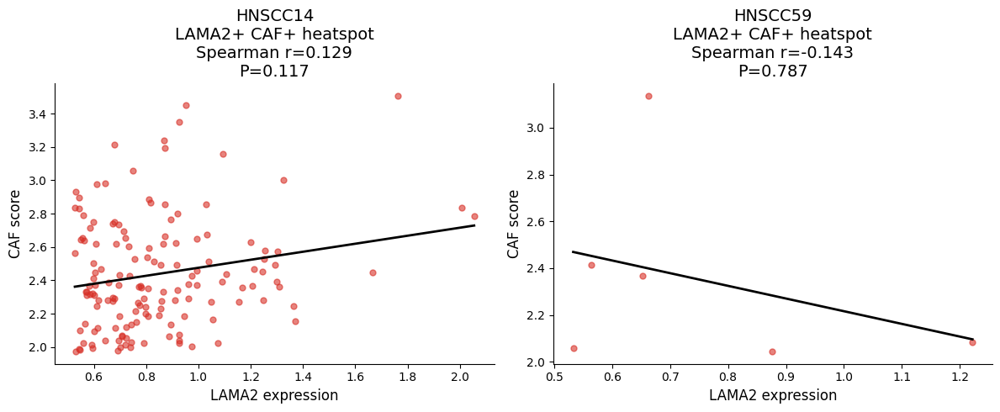

In [ ]:
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import numpy as np


samples = ["HNSCC14", "HNSCC59"]


fig, axes = plt.subplots(
    1,
    len(samples),
    figsize=(12,5)
)


if len(samples) == 1:
    axes = [axes]


for ax, sample in zip(axes, samples):

    # 只取 LAMA2 high + CAF high heatspot
    heat = df[
        (df["sample"] == sample) &
        (df["LAMA2_CAF_coloc"] == "LAMA2+ CAF+")
    ].copy()


    print(
        sample,
        "Heatspot spots:",
        len(heat)
    )


    if len(heat) < 5:
        print("spot数量不足")
        continue


    # Spearman
    rho, p = spearmanr(
        heat["LAMA2"],
        heat["CAF_score"]
    )


    # scatter
    ax.scatter(
        heat["LAMA2"],
        heat["CAF_score"],
        s=25,
        alpha=0.6,
        color="#D73027",
        rasterized=True
    )


    # 添加趋势线（仅用于展示）
    x = heat["LAMA2"].values
    y = heat["CAF_score"].values


    if len(np.unique(x)) > 1:

        coef = np.polyfit(
            x,
            y,
            1
        )

        xx = np.linspace(
            x.min(),
            x.max(),
            100
        )

        ax.plot(
            xx,
            coef[0]*xx + coef[1],
            color="black",
            linewidth=2
        )


    ax.set_title(
        f"{sample}\n"
        f"LAMA2+ CAF+ heatspot\n"
        f"Spearman r={rho:.3f}\n"
        f"P={p:.3g}",
        fontsize=14
    )


    ax.set_xlabel(
        "LAMA2 expression",
        fontsize=12
    )

    ax.set_ylabel(
        "CAF score",
        fontsize=12
    )


    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


plt.tight_layout()


plt.savefig(
    "./figures/LAMA2_CAF_heatspot_correlation.tiff",
    dpi=600,
    bbox_inches="tight",
    pil_kwargs={
        "compression":"tiff_lzw"
    }
)


plt.show()

HNSCC14: 913 spots


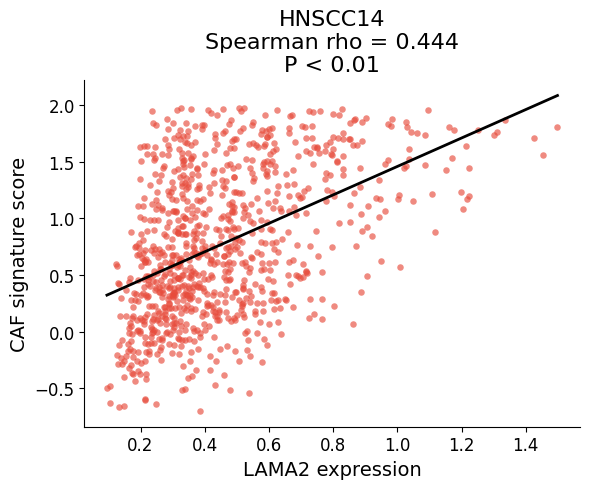

HNSCC59: 229 spots


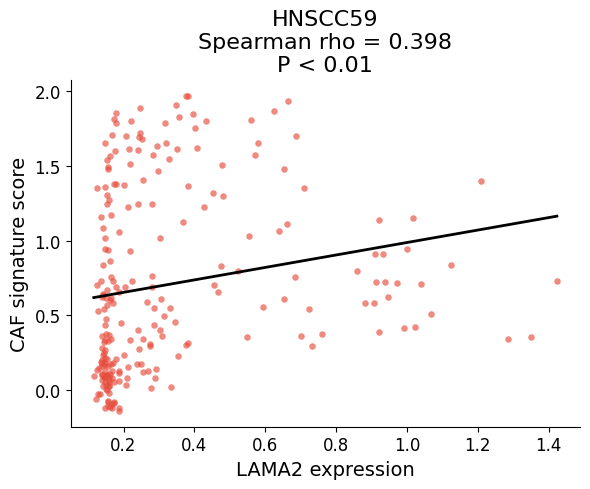

    sample  n_spots  Spearman_rho       P_value
0  HNSCC14      913      0.443921  2.261762e-45
1  HNSCC59      229      0.397873  4.162463e-10


In [ ]:
import os
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# ===============================
# 参数
# ===============================
SAMPLES = ["HNSCC14", "HNSCC59"]

# 如果你定义 LAMA2+ spot 为两类都纳入，就保留这两个
TARGETS = [
    "LAMA2 high Heatspot",
    # "LAMA2 high & CAF high Heatspot"
]

OUTDIR = "./figures/LAMA2_CAF"
os.makedirs(OUTDIR, exist_ok=True)

# ===============================
# 循环分别作图并保存
# ===============================
results = []

for sample in SAMPLES:

    mask = (
        (adata.obs["sample"].astype(str) == sample) &
        (adata.obs["LAMA2_CAF_coloc"].astype(str).isin(TARGETS))
    )

    sub = adata[mask].copy()

    print(f"{sample}: {sub.n_obs} spots")

    # 提取 LAMA2 表达
    x = sub[:, "LAMA2"].X
    if sp.issparse(x):
        x = x.toarray().ravel()
    else:
        x = np.asarray(x).ravel()

    # 提取 CAF_score
    y = pd.to_numeric(
        sub.obs["CAF_score"],
        errors="coerce"
    ).to_numpy()

    valid = np.isfinite(x) & np.isfinite(y)
    x = x[valid]
    y = y[valid]

    if len(x) < 5 or len(np.unique(x)) < 2 or len(np.unique(y)) < 2:
        print(f"{sample}: insufficient variation")
        continue

    # Spearman
    rho, p = spearmanr(x, y)

    results.append({
        "sample": sample,
        "n_spots": len(x),
        "Spearman_rho": rho,
        "P_value": p
    })

    # ===============================
    # 单独画图
    # ===============================
    fig, ax = plt.subplots(figsize=(6, 5))

    ax.scatter(
        x,
        y,
        s=22,
        alpha=0.65,
        color="#e74c3c",
        linewidths=0,
        rasterized=True
    )

    # 线性趋势线（仅展示趋势）
    coef = np.polyfit(x, y, 1)
    xx = np.linspace(x.min(), x.max(), 100)
    ax.plot(
        xx,
        np.polyval(coef, xx),
        color="black",
        linewidth=2
    )

    # 标题：不显示 n，P 统一写成 <0.01
    ax.set_title(
        f"{sample}\n"
        f"Spearman rho = {rho:.3f}\n"
        f"P < 0.01",
        fontsize=16
    )

    ax.set_xlabel(
        "LAMA2 expression",
        fontsize=14
    )
    ax.set_ylabel(
        "CAF signature score",
        fontsize=14
    )

    ax.tick_params(labelsize=12)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()

    # 分开保存
    plt.savefig(
        f"{OUTDIR}/{sample}_LAMA2_CAF_correlation.tiff",
        dpi=600,
        bbox_inches="tight",
        pil_kwargs={"compression": "tiff_lzw"}
    )

    plt.show()
    plt.close()

# ===============================
# 保存统计结果
# ===============================
result_df = pd.DataFrame(results)
print(result_df)

result_df.to_csv(
    f"{OUTDIR}/LAMA2_CAF_correlation_stats.csv",
    index=False
)

# save

In [ ]:
adata

AnnData object with n_obs × n_vars = 4640 × 12179
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'log1p_total_counts_mt', 'clusters', 'leiden', 'gene_niche', 'subtype', '_indices', '_scvi_batch', '_scvi_labels', 'CAF_score', 'Program_1', 'Program_2', 'Program_3', 'Program_4', 'Program_5', 'Program_6', 'Program_7', 'LAMA2_positive', 'LAMA2_expr'
    var: 'gene_ids', 'feature_types', 'genome', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'mean', 'std'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'clusters', 'clusters_nhood_enrichment', 'dendrogram_clusters', 'dendrogram_gene_niche', 'dendrogram_leiden', 'gene_niche_colors', 'hvg', 'leiden', 'leiden_colors', 'leiden_nhood_

In [ ]:
import os
import pandas as pd
import numpy as np


outdir = "./visum/spatial_by_sample"
os.makedirs(outdir, exist_ok=True)


for sample in adata.obs["sample"].unique():

    print("saving:", sample)

    # 子集
    sub = adata[
        adata.obs["sample"] == sample
    ].copy()


    # --------------------
    # 保存obs
    # --------------------
    sub.obs.to_csv(
        f"{outdir}/{sample}_obs.csv"
    )


    # --------------------
    # 保存spot坐标
    # --------------------
    spatial_df = pd.DataFrame(
        sub.obsm["spatial"],
        index=sub.obs_names,
        columns=[
            "x",
            "y"
        ]
    )


    spatial_df.to_csv(
        f"{outdir}/{sample}_spatial.csv"
    )

saving: HNSCC14
saving: HNSCC59


# 重写c2l


In [ ]:
import numpy as np
import pandas as pd

# ===============================
# 1. 获取 cell abundance 矩阵
# ===============================

abundance = np.asarray(
    adata.obsm["q05_cell_abundance_w_sf"],
    dtype=np.float64
)

celltypes = np.array(
    adata.uns["mod"]["factor_names"]
)


# ===============================
# 2. 删除 Unknown
# ===============================

keep = np.array(
    [
        "unknown" not in str(x).lower()
        for x in celltypes
    ]
)

abundance = abundance[:, keep]
celltypes = celltypes[keep]


print("保留celltype数量:", len(celltypes))
print(celltypes)


# ===============================
# 3. 重新归一化
# 每个spot内所有cell比例=1
# ===============================

abundance_norm = (
    abundance /
    abundance.sum(axis=1, keepdims=True)
)

# 防止极端spot全0
abundance_norm = np.nan_to_num(
    abundance_norm
)


# ===============================
# 4. 删除obs中旧的cell abundance列
# ===============================

old_cols = [
    c for c in adata.obs.columns
    if c in adata.uns["mod"]["factor_names"]
]

adata.obs.drop(
    columns=old_cols,
    inplace=True,
    errors="ignore"
)


# ===============================
# 5. 写入新的归一化结果
# ===============================

adata.obs[celltypes] = abundance_norm


# 保存obsm
adata.obsm["q05_cell_abundance_w_sf_norm"] = abundance_norm

# 保存新的名字
adata.uns["celltypes_q05_norm"] = celltypes.tolist()


print(
    adata.obs[celltypes].head()
)

保留celltype数量: 42
['Arterial_EC' 'B' 'Basal_Epi' 'CAF_COL14A1' 'CD4T_CXCL13' 'CD4T_GZMB'
 'CD4T_PTPRC' 'CD4T_naive' 'CD8T_CXCL13' 'CD8T_GZMA' 'CD8T_GZMK'
 'CD8T_naive' 'CD8T_str' 'Capillary_EC' 'Cycling_CAF' 'Cycling_EC'
 'Cycling_T' 'Diff_Epi' 'EC_ACKR1' 'EC_PGF' 'EMT_like_Epi' 'Hypoxia_Epi'
 'Mac_CXCL5' 'Mac_FOLR2' 'Mac_SPP1' 'Mast' 'Mono_FCN1' 'NK' 'Neutrophil'
 'Normal_Epi' 'Plasma' 'Prolif_Epi' 'Stem_like_Epi' 'Str_Epi' 'Treg'
 'apCAF' 'iCAF_CXCL1' 'iCAF_CXCL8' 'mregDC' 'myCAF_CTHRC1' 'qCAF' 'qEC']
                            Arterial_EC         B  Basal_Epi  CAF_COL14A1  \
HNSCC14_AAACAATCTACTAGCA-1     0.000948  0.003588   0.290620     0.010828   
HNSCC14_AAACAGAGCGACTCCT-1     0.000058  0.001434   0.271648     0.002241   
HNSCC14_AAACCGGGTAGGTACC-1     0.013233  0.002191   0.299201     0.018074   
HNSCC14_AAACCGTTCGTCCAGG-1     0.004214  0.017772   0.007950     0.055692   
HNSCC14_AAACCTCATGAAGTTG-1     0.004607  0.010924   0.074612     0.025885   

                            C

In [ ]:
adata.obsm["q05_cell_abundance_w_sf"] = abundance

In [ ]:
c2l_cols = adata.uns["mod"]["factor_names"]

adata.obs.drop(
    columns=c2l_cols,
    inplace=True,
    errors="ignore"
)